In [ ]:
CELL_START_TIME = __import__('time').time()

import os
import sys
import warnings
import logging
import contextlib

# Quiet TensorFlow / CUDA logs as much as possible.
# Some low-level CUDA registration messages may still appear before TensorFlow logging is initialized.
# They are usually environment warnings, not model-code errors.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["ABSL_LOG_LEVEL"] = "3"
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

warnings.filterwarnings("ignore")
logging.getLogger("tensorflow").setLevel(logging.ERROR)
logging.getLogger("absl").setLevel(logging.ERROR)


@contextlib.contextmanager
def suppress_stderr(enabled=True):
    if not enabled:
        yield
        return
    try:
        fd = sys.stderr.fileno()
    except Exception:
        yield
        return
    saved_fd = os.dup(fd)
    try:
        with open(os.devnull, "w") as devnull:
            os.dup2(devnull.fileno(), fd)
            yield
    finally:
        os.dup2(saved_fd, fd)
        os.close(saved_fd)

# =============================================================================
# LLM-TinyTransformer-IDS
# Proposed model: LLM-inspired tabular tokenization + Tiny Transformer for IDS.
# This is NOT TACNet reproduction and does not use any external LLM API.
# =============================================================================

# =============================================================================
# SECTION 0 - CONFIG
# =============================================================================
import glob
import time
import random

MODEL_NAME = "LLM-TinyTransformer-IDS"

DATASET_PATH = "/kaggle/input/datasets/muhammadirfangull/cic-iiot-2025/combined_dataset.csv"
DATASET_PATH_CANDIDATES = [
    DATASET_PATH,
    "/kaggle/input/cic-iiot-2025/combined_dataset.csv",
    "/kaggle/input/cic-iiot-2025-dataset/combined_dataset.csv",
]
TARGET_COL = "label1"
DROP_LEAKAGE_COLUMNS = [
    "label_full", "label1", "label2", "label3", "label4",
    "timestamp", "timestamp_start", "timestamp_end",
    "device_name", "device_mac",
]

RESULTS_CSV = "llm_tiny_transformer_results.csv"
BEST_MODEL_PATH = "llm_tiny_transformer_best_model.keras"
REPORT_PATH = "llm_tiny_transformer_classification_report.txt"
TRAINING_CURVES_PATH = "llm_tiny_transformer_training_curves.png"
CONFUSION_MATRIX_PATH = "llm_tiny_transformer_confusion_matrix.png"

# Tiny configuration. This stays below the prohibited heavy settings.
TOKENIZER_MODE = "quantile"  # options: "uniform", "quantile"
POOLING_MODE = "gap_max"     # options: "gap", "gap_max", "cls"
NUM_BINS = 64
D_MODEL = 64
NUM_HEADS = 4
FF_DIM = 192
NUM_TRANSFORMER_BLOCKS = 3
DROPOUT_RATE = 0.10
ATTN_DROPOUT = 0.05
LR = 5e-4
WEIGHT_DECAY = 1e-5
BATCH_SIZE = 1024
MAX_EPOCHS = 50
PATIENCE = 5
USE_EARLY_STOPPING = True
RUN_TINY_SEARCH = False
PRINT_MODEL_SUMMARY = False
THRESHOLD_OBJECTIVE = "macro_f1"  # options: "weighted_f1", "macro_f1", "attack_f1"

TEST_SIZE = 0.20
VAL_SIZE = 0.20
RANDOM_SEED = 42

THRESHOLD_START = 0.10
THRESHOLD_END = 0.90
THRESHOLD_STEP = 0.005

if TOKENIZER_MODE not in {"uniform", "quantile"}:
    raise ValueError("TOKENIZER_MODE must be 'uniform' or 'quantile'.")
if POOLING_MODE not in {"gap", "gap_max", "cls"}:
    raise ValueError("POOLING_MODE must be 'gap', 'gap_max', or 'cls'.")
if THRESHOLD_OBJECTIVE not in {"weighted_f1", "macro_f1", "attack_f1"}:
    raise ValueError("THRESHOLD_OBJECTIVE must be 'weighted_f1', 'macro_f1', or 'attack_f1'.")
if not USE_EARLY_STOPPING:
    raise ValueError("USE_EARLY_STOPPING must remain True for the max-50-epoch experiment.")
if D_MODEL >= 128 or NUM_HEADS >= 8 or NUM_TRANSFORMER_BLOCKS >= 4:
    raise ValueError("Configuration is too large for the required Tiny Transformer setting.")

# =============================================================================
# SECTION 1 - IMPORTS AND REPRODUCIBILITY
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

with suppress_stderr(True):
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers, Model, Input
    from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
tf.get_logger().setLevel("ERROR")

try:
    from absl import logging as absl_logging
    absl_logging.set_verbosity(absl_logging.ERROR)
except Exception:
    pass

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, label_binarize
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
)

np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)
keras.backend.clear_session()

with suppress_stderr(True):
    gpus = tf.config.list_physical_devices("GPU")
print(f"  GPU detected                  : {len(gpus)}")

if not gpus:
    print("  [Warning] TensorFlow GPU not detected. Training may be slow.")
else:
    for gpu in gpus:
        with suppress_stderr(True):
            try:
                tf.config.experimental.set_memory_growth(gpu, True)
            except Exception:
                pass


def progress(step, msg):
    print(f"[{step}/8] {msg}")


def fmt_metric(value):
    if isinstance(value, (float, np.floating)) and np.isnan(value):
        return "N/A"
    return f"{float(value):.4f}"


def round_metric(value, digits=4):
    if isinstance(value, (float, np.floating)) and np.isnan(value):
        return "N/A"
    return round(float(value), digits)


def format_class_distribution(counts):
    if len(counts) == 2:
        benign_count = 0
        attack_count = 0
        benign_found = False
        for label, count in counts.items():
            label_text = str(label).lower()
            if "benign" in label_text or "normal" in label_text:
                benign_found = True
                benign_count += int(count)
            else:
                attack_count += int(count)
        if not benign_found:
            benign_count = int(counts.iloc[0])
            attack_count = int(counts.iloc[1])
        return f"benign={benign_count:,} | attack={attack_count:,}"
    return " | ".join(f"{label}={int(count):,}" for label, count in counts.items())


def resolve_dataset_path():
    for candidate in DATASET_PATH_CANDIDATES:
        if candidate and os.path.exists(candidate):
            return candidate
    matches = sorted(glob.glob("/kaggle/input/**/combined_dataset.csv", recursive=True))
    if matches:
        return matches[0]
    raise FileNotFoundError(
        "Could not find combined_dataset.csv. Update DATASET_PATH to the Kaggle dataset file path."
    )

# =============================================================================
# SECTION 2 - LOAD DATASET
# =============================================================================
progress(1, "Loading dataset...")
PIPELINE_START = time.time()

resolved_dataset_path = resolve_dataset_path()
df = pd.read_csv(resolved_dataset_path)
if TARGET_COL not in df.columns:
    raise ValueError(f"Target column '{TARGET_COL}' not found. Available columns: {list(df.columns)[:20]} ...")

df = df[df[TARGET_COL].notna()].reset_index(drop=True)
target_counts = df[TARGET_COL].value_counts()
task_type_preview = "Binary IDS" if len(target_counts) == 2 else "Multiclass IDS"

print(f"  Dataset path : {resolved_dataset_path}")
print(f"  Dataset shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
print(f"  Target column: {TARGET_COL}")
print(f"  Task preview : {task_type_preview}")
print(f"  Distribution : {format_class_distribution(target_counts)}")

# =============================================================================
# SECTION 3 - PREPROCESSING WITH NO LEAKAGE
# Split order:
#   1. Raw train_val/test = 80/20, stratified.
#   2. Raw train/val = 80/20 of train_val, stratified.
#   3. Fit imputation, categorical maps, scaler only on X_train.
#   4. Transform val/test with train-fitted objects only.
# =============================================================================
progress(2, "Preprocessing with train-only fitted objects...")

drop_set = set(DROP_LEAKAGE_COLUMNS)
drop_set.add(TARGET_COL)
existing_drop = [c for c in df.columns if c in drop_set]
feature_cols = [c for c in df.columns if c not in drop_set]

print(f"  Dropped leakage/meta columns: {len(existing_drop)}")
print(f"  Remaining feature columns   : {len(feature_cols)}")

suspicious_terms = ["label", "target", "class", "timestamp"]
flagged_cols = [c for c in feature_cols if any(term in c.lower() for term in suspicious_terms)]
if flagged_cols:
    raise ValueError(
        "Leakage check failed. Suspicious columns still in features: "
        f"{flagged_cols}. Add them to DROP_LEAKAGE_COLUMNS."
    )
print("  Leakage safety check        : passed")

X_raw = df[feature_cols].copy()
y_raw = df[TARGET_COL].copy()

num_cols = X_raw.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_raw.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"  Numeric/Categorical columns : {len(num_cols)}/{len(cat_cols)}")

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_raw)
class_names = label_encoder.classes_
n_classes = len(class_names)
task_type = "Binary IDS" if n_classes == 2 else "Multiclass IDS"

X_train_val_raw, X_test_raw, y_train_val, y_test = train_test_split(
    X_raw,
    y_encoded,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
    stratify=y_encoded,
)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_val_raw,
    y_train_val,
    test_size=VAL_SIZE,
    random_state=RANDOM_SEED,
    stratify=y_train_val,
)

X_train_raw = X_train_raw.copy()
X_val_raw = X_val_raw.copy()
X_test_raw = X_test_raw.copy()
print(
    "  Split sizes                  : "
    f"train={len(X_train_raw):,} | val={len(X_val_raw):,} | test={len(X_test_raw):,}"
)

if num_cols:
    X_train_raw[num_cols] = X_train_raw[num_cols].replace([np.inf, -np.inf], np.nan)
    X_val_raw[num_cols] = X_val_raw[num_cols].replace([np.inf, -np.inf], np.nan)
    X_test_raw[num_cols] = X_test_raw[num_cols].replace([np.inf, -np.inf], np.nan)

if num_cols:
    train_medians = X_train_raw[num_cols].median(numeric_only=True).fillna(0)
    X_train_raw[num_cols] = X_train_raw[num_cols].fillna(train_medians)
    X_val_raw[num_cols] = X_val_raw[num_cols].fillna(train_medians)
    X_test_raw[num_cols] = X_test_raw[num_cols].fillna(train_medians)

train_modes = {}
for col in cat_cols:
    X_train_raw[col] = X_train_raw[col].astype("object")
    X_val_raw[col] = X_val_raw[col].astype("object")
    X_test_raw[col] = X_test_raw[col].astype("object")
    mode_values = X_train_raw[col].mode(dropna=True)
    train_modes[col] = mode_values.iloc[0] if not mode_values.empty else "unknown"

if cat_cols:
    X_train_raw[cat_cols] = X_train_raw[cat_cols].fillna(train_modes)
    X_val_raw[cat_cols] = X_val_raw[cat_cols].fillna(train_modes)
    X_test_raw[cat_cols] = X_test_raw[cat_cols].fillna(train_modes)

category_maps = {}
for col in cat_cols:
    train_values = X_train_raw[col].astype(str)
    classes = pd.Index(train_values.unique())
    mapping = {value: idx for idx, value in enumerate(classes)}
    category_maps[col] = mapping
    X_train_raw[col] = train_values.map(mapping).fillna(-1)
    X_val_raw[col] = X_val_raw[col].astype(str).map(mapping).fillna(-1)
    X_test_raw[col] = X_test_raw[col].astype(str).map(mapping).fillna(-1)

X_train_enc = X_train_raw.astype(np.float32)
X_val_enc = X_val_raw.astype(np.float32)
X_test_enc = X_test_raw.astype(np.float32)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train_enc)
X_val = scaler.transform(X_val_enc)
X_test = scaler.transform(X_test_enc)

X_train = np.clip(X_train, 0.0, 1.0).astype(np.float32)
X_val = np.clip(X_val, 0.0, 1.0).astype(np.float32)
X_test = np.clip(X_test, 0.0, 1.0).astype(np.float32)

n_features = X_train.shape[1]
class_counts = np.bincount(y_train, minlength=n_classes)
class_weight_dict = {
    i: (len(y_train) / (n_classes * class_counts[i])) if class_counts[i] > 0 else 0.0
    for i in range(n_classes)
}

print("  Scaling                       : MinMax fit on train only, then clipped to [0, 1]")
print(f"  Token sequence length         : {n_features} (= number of features)")
print(f"  Class weights                 : {class_weight_dict}")

# =============================================================================
# SECTION 4 - LLM-STYLE TOKENIZATION LAYER
# Each tabular feature becomes one token position.
# Discretization is fit on X_train only when TOKENIZER_MODE = "quantile".
# Final token = value_embedding(bin_id) + feature_embedding(feature_id)
#             + continuous_projection(raw_scaled_value)
# =============================================================================
progress(3, "Fitting LLM-style tabular tokenization...")


def fit_token_bin_edges(X_fit, num_bins, mode):
    if mode == "uniform":
        return [None] * X_fit.shape[1], np.ones(X_fit.shape[1], dtype=bool)

    quantile_points = np.linspace(0.0, 1.0, num_bins + 1, dtype=np.float64)[1:-1]
    bin_edges = []
    use_uniform = np.zeros(X_fit.shape[1], dtype=bool)

    for feature_idx in range(X_fit.shape[1]):
        values = X_fit[:, feature_idx]
        values = values[np.isfinite(values)]
        unique_values = np.unique(values)

        if unique_values.size < 4:
            bin_edges.append(None)
            use_uniform[feature_idx] = True
            continue

        edges = np.quantile(values, quantile_points).astype(np.float32)
        edges = np.unique(edges)
        edges = edges[np.isfinite(edges)]

        if edges.size < 2:
            bin_edges.append(None)
            use_uniform[feature_idx] = True
        else:
            bin_edges.append(edges)
            use_uniform[feature_idx] = False

    return bin_edges, use_uniform


def transform_to_token_ids(X, bin_edges, use_uniform, num_bins):
    token_ids = np.empty(X.shape, dtype=np.int32)
    uniform_ids = np.floor(X * num_bins).astype(np.int32)
    uniform_ids = np.clip(uniform_ids, 0, num_bins - 1)

    for feature_idx in range(X.shape[1]):
        edges = bin_edges[feature_idx]
        if use_uniform[feature_idx] or edges is None:
            token_ids[:, feature_idx] = uniform_ids[:, feature_idx]
        else:
            token_ids[:, feature_idx] = np.searchsorted(edges, X[:, feature_idx], side="right")

    token_ids = np.clip(token_ids, 0, num_bins - 1).astype(np.int32)
    return token_ids


bin_edges, uniform_fallback_mask = fit_token_bin_edges(X_train, NUM_BINS, TOKENIZER_MODE)
X_train_tokens = transform_to_token_ids(X_train, bin_edges, uniform_fallback_mask, NUM_BINS)
X_val_tokens = transform_to_token_ids(X_val, bin_edges, uniform_fallback_mask, NUM_BINS)
X_test_tokens = transform_to_token_ids(X_test, bin_edges, uniform_fallback_mask, NUM_BINS)

fallback_count = int(uniform_fallback_mask.sum())
print(f"  Tokenizer mode                : {TOKENIZER_MODE}")
print(f"  NUM_BINS                      : {NUM_BINS}")
print(f"  Uniform fallback features     : {fallback_count}/{n_features}")
print("  Bin edges fitted on           : X_train only")

@tf.keras.utils.register_keras_serializable(package="LLMTinyTransformerIDS")
class TabularTokenizerLayer(layers.Layer):
    """Embeds tabular bin IDs and scaled continuous values as token sequences."""

    def __init__(self, n_features, num_bins, d_model, dropout_rate=0.0, **kwargs):
        super().__init__(**kwargs)
        self.n_features = int(n_features)
        self.num_bins = int(num_bins)
        self.d_model = int(d_model)
        self.dropout_rate = float(dropout_rate)
        self.value_embedding = layers.Embedding(
            input_dim=self.num_bins,
            output_dim=self.d_model,
            name="value_embedding",
        )
        self.feature_embedding = layers.Embedding(
            input_dim=self.n_features,
            output_dim=self.d_model,
            name="feature_embedding",
        )
        self.continuous_projection = layers.Dense(
            self.d_model,
            activation=None,
            name="continuous_projection",
        )
        self.dropout = layers.Dropout(self.dropout_rate, name="token_dropout")

    def call(self, inputs, training=None):
        token_ids, scaled_values = inputs
        token_ids = tf.cast(token_ids, tf.int32)
        token_ids = tf.clip_by_value(token_ids, 0, self.num_bins - 1)
        scaled_values = tf.cast(scaled_values, tf.float32)

        value_emb = self.value_embedding(token_ids)
        feature_ids = tf.range(self.n_features, dtype=tf.int32)[tf.newaxis, :]
        feature_emb = self.feature_embedding(feature_ids)
        continuous_emb = self.continuous_projection(scaled_values[..., tf.newaxis])

        token_sequence = value_emb + feature_emb + continuous_emb
        return self.dropout(token_sequence, training=training)

    def get_config(self):
        config = super().get_config()
        config.update({
            "n_features": self.n_features,
            "num_bins": self.num_bins,
            "d_model": self.d_model,
            "dropout_rate": self.dropout_rate,
        })
        return config

# =============================================================================
# SECTION 5 - TINY TRANSFORMER MODEL
# Pre-norm block:
#   LayerNorm -> MultiHeadAttention -> Dropout -> residual
#   LayerNorm -> Dense(FF_DIM, gelu) -> Dropout -> Dense(D_MODEL)
#             -> Dropout -> residual
# =============================================================================
progress(4, "Building Tiny Transformer model...")

@tf.keras.utils.register_keras_serializable(package="LLMTinyTransformerIDS")
class CLSTokenLayer(layers.Layer):
    """Prepends a learnable CLS token for optional cls pooling."""

    def __init__(self, d_model, **kwargs):
        super().__init__(**kwargs)
        self.d_model = int(d_model)

    def build(self, input_shape):
        self.cls_token = self.add_weight(
            name="cls_token",
            shape=(1, 1, self.d_model),
            initializer="zeros",
            trainable=True,
        )
        super().build(input_shape)

    def call(self, x):
        batch_size = tf.shape(x)[0]
        cls_tokens = tf.tile(self.cls_token, [batch_size, 1, 1])
        return tf.concat([cls_tokens, x], axis=1)

    def get_config(self):
        config = super().get_config()
        config.update({"d_model": self.d_model})
        return config


@tf.keras.utils.register_keras_serializable(package="LLMTinyTransformerIDS")
class CLSPoolingLayer(layers.Layer):
    """Returns the first token from a sequence."""

    def call(self, x):
        return x[:, 0, :]


def transformer_block(x, d_model, num_heads, ff_dim, dropout_rate, attn_dropout, block_idx):
    prefix = f"block{block_idx}_"

    norm_1 = layers.LayerNormalization(epsilon=1e-6, name=prefix + "ln1")(x)
    attn_out = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads,
        dropout=attn_dropout,
        name=prefix + "mha",
    )(norm_1, norm_1)
    attn_out = layers.Dropout(dropout_rate, name=prefix + "attn_dropout")(attn_out)
    x = layers.Add(name=prefix + "attn_residual")([x, attn_out])

    norm_2 = layers.LayerNormalization(epsilon=1e-6, name=prefix + "ln2")(x)
    ffn = layers.Dense(ff_dim, activation="gelu", name=prefix + "ffn_dense1")(norm_2)
    ffn = layers.Dropout(dropout_rate, name=prefix + "ffn_dropout1")(ffn)
    ffn = layers.Dense(d_model, activation=None, name=prefix + "ffn_dense2")(ffn)
    ffn = layers.Dropout(dropout_rate, name=prefix + "ffn_dropout2")(ffn)
    x = layers.Add(name=prefix + "ffn_residual")([x, ffn])

    return x


def build_llm_tiny_transformer_ids(n_features, n_classes):
    token_ids_input = Input(shape=(n_features,), dtype="int32", name="token_ids")
    scaled_values_input = Input(shape=(n_features,), dtype="float32", name="scaled_features")

    x = TabularTokenizerLayer(
        n_features=n_features,
        num_bins=NUM_BINS,
        d_model=D_MODEL,
        dropout_rate=DROPOUT_RATE,
        name="tabular_tokenizer",
    )([token_ids_input, scaled_values_input])

    if POOLING_MODE == "cls":
        x = CLSTokenLayer(D_MODEL, name="cls_token_layer")(x)

    for block_idx in range(NUM_TRANSFORMER_BLOCKS):
        x = transformer_block(
            x,
            d_model=D_MODEL,
            num_heads=NUM_HEADS,
            ff_dim=FF_DIM,
            dropout_rate=DROPOUT_RATE,
            attn_dropout=ATTN_DROPOUT,
            block_idx=block_idx,
        )

    x = layers.LayerNormalization(epsilon=1e-6, name="encoder_final_ln")(x)

    if POOLING_MODE == "gap":
        x = layers.GlobalAveragePooling1D(name="gap_pooling")(x)
    elif POOLING_MODE == "gap_max":
        avg_pool = layers.GlobalAveragePooling1D(name="gap_pooling")(x)
        max_pool = layers.GlobalMaxPooling1D(name="gmp_pooling")(x)
        x = layers.Concatenate(name="avg_max_pooling")([avg_pool, max_pool])
    else:
        x = CLSPoolingLayer(name="cls_pooling")(x)

    x = layers.Dense(D_MODEL, activation="gelu", name="head_dense")(x)
    x = layers.Dropout(DROPOUT_RATE, name="head_dropout")(x)
    output = layers.Dense(n_classes, activation="softmax", name="output")(x)

    return Model(
        inputs={"token_ids": token_ids_input, "scaled_features": scaled_values_input},
        outputs=output,
        name=MODEL_NAME,
    )


def make_optimizer():
    adamw_cls = getattr(keras.optimizers, "AdamW", None)
    if adamw_cls is not None:
        return adamw_cls(learning_rate=LR, weight_decay=WEIGHT_DECAY)
    return keras.optimizers.Adam(learning_rate=LR)


with suppress_stderr(True):
    model = build_llm_tiny_transformer_ids(n_features=n_features, n_classes=n_classes)
    model.compile(
        optimizer=make_optimizer(),
        loss="sparse_categorical_crossentropy",
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )

n_params = model.count_params()
print(f"  Model                         : {MODEL_NAME}")
print(f"  Task                          : {task_type}")
print(f"  n_features / n_classes        : {n_features} / {n_classes}")
print(f"  D_MODEL / HEADS / FF_DIM      : {D_MODEL} / {NUM_HEADS} / {FF_DIM}")
print(f"  Transformer blocks            : {NUM_TRANSFORMER_BLOCKS}")
print(f"  Pooling                       : {POOLING_MODE}")
print(f"  Dropout / Attention dropout   : {DROPOUT_RATE} / {ATTN_DROPOUT}")
print(f"  Trainable params              : {n_params:,}")
if PRINT_MODEL_SUMMARY:
    model.summary()

# =============================================================================
# SECTION 6 - TRAINING
# Test set is not used here. Best checkpoint and early stopping monitor val_loss.
# =============================================================================
progress(5, "Training...")

train_inputs = {"token_ids": X_train_tokens, "scaled_features": X_train}
val_inputs = {"token_ids": X_val_tokens, "scaled_features": X_val}
test_inputs = {"token_ids": X_test_tokens, "scaled_features": X_test}

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True,
        verbose=1,
    ),
    ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=0,
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1,
    ),
]

MODEL_TRAIN_START = time.time()
with suppress_stderr(True):
    history = model.fit(
        train_inputs,
        y_train,
        validation_data=(val_inputs, y_val),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weight_dict,
        callbacks=callbacks,
        verbose=1,
    )
MODEL_TRAIN_END = time.time()
model_train_min = (MODEL_TRAIN_END - MODEL_TRAIN_START) / 60.0

epochs_stopped = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
best_val_loss = float(np.min(history.history["val_loss"]))
# Save the restored best weights after EarlyStopping.
model.save(BEST_MODEL_PATH)

print(f"  Epochs run                    : {epochs_stopped}/{MAX_EPOCHS}")
print(f"  Best epoch                    : {best_epoch}")
print(f"  Best val_loss                 : {best_val_loss:.4f}")
print(f"  Model training time           : {model_train_min:.2f} min")

# =============================================================================
# SECTION 7 - VALIDATION THRESHOLD TUNING AND TEST EVALUATION
# Binary threshold is tuned only on validation weighted F1, then applied once to test.
# =============================================================================
progress(6, "Tuning validation threshold and evaluating test set...")


def get_binary_roles(class_names):
    names = [str(name).lower() for name in class_names]
    benign_idx = None
    for idx, name in enumerate(names):
        if "benign" in name or "normal" in name:
            benign_idx = idx
            break
    if benign_idx is None:
        negative_idx = 0
        positive_idx = 1
    else:
        negative_idx = benign_idx
        positive_idx = 1 - benign_idx
    return positive_idx, negative_idx


def predict_with_threshold(y_prob, threshold, positive_idx, negative_idx):
    y_pred = np.full(y_prob.shape[0], negative_idx, dtype=np.int32)
    y_pred[y_prob[:, positive_idx] >= threshold] = positive_idx
    return y_pred


best_threshold = None
best_val_weighted_f1 = None
best_val_macro_f1 = None
best_val_attack_f1 = None
best_val_fpr = None
best_val_fnr = None
positive_class_idx = None
negative_class_idx = None

if n_classes == 2:
    positive_class_idx, negative_class_idx = get_binary_roles(class_names)
    with suppress_stderr(True):
        val_prob = model.predict(val_inputs, batch_size=BATCH_SIZE, verbose=0)
    thresholds = np.round(
        np.arange(THRESHOLD_START, THRESHOLD_END + (THRESHOLD_STEP / 2.0), THRESHOLD_STEP),
        3,
    )

    best_tuple = (-np.inf, -np.inf, -np.inf, -np.inf, 0.5)
    for threshold in thresholds:
        val_pred = predict_with_threshold(val_prob, threshold, positive_class_idx, negative_class_idx)
        val_weighted_f1 = f1_score(y_val, val_pred, average="weighted", zero_division=0)
        val_macro_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
        val_attack_f1 = f1_score(
            (y_val == positive_class_idx).astype(np.int32),
            (val_pred == positive_class_idx).astype(np.int32),
            zero_division=0,
        )
        val_tp = int(((y_val == positive_class_idx) & (val_pred == positive_class_idx)).sum())
        val_tn = int(((y_val == negative_class_idx) & (val_pred == negative_class_idx)).sum())
        val_fp = int(((y_val == negative_class_idx) & (val_pred == positive_class_idx)).sum())
        val_fn = int(((y_val == positive_class_idx) & (val_pred == negative_class_idx)).sum())
        val_fpr = val_fp / max(val_fp + val_tn, 1)
        val_fnr = val_fn / max(val_fn + val_tp, 1)
        tie_distance = abs(float(threshold) - 0.5)

        if THRESHOLD_OBJECTIVE == "weighted_f1":
            candidate_tuple = (
                val_weighted_f1,
                val_attack_f1,
                val_macro_f1,
                -tie_distance,
                float(threshold),
            )
        elif THRESHOLD_OBJECTIVE == "macro_f1":
            candidate_tuple = (
                val_macro_f1,
                val_attack_f1,
                val_weighted_f1,
                -tie_distance,
                float(threshold),
            )
        else:
            candidate_tuple = (
                val_attack_f1,
                val_macro_f1,
                val_weighted_f1,
                -tie_distance,
                float(threshold),
            )

        if candidate_tuple > best_tuple:
            best_tuple = candidate_tuple
            best_threshold = float(threshold)
            best_val_weighted_f1 = float(val_weighted_f1)
            best_val_macro_f1 = float(val_macro_f1)
            best_val_attack_f1 = float(val_attack_f1)
            best_val_fpr = float(val_fpr)
            best_val_fnr = float(val_fnr)

    print(
        "  Selected threshold            : "
        f"{best_threshold:.3f} | objective={THRESHOLD_OBJECTIVE} "
        f"| val weighted F1={best_val_weighted_f1:.4f} "
        f"| val macro F1={best_val_macro_f1:.4f} "
        f"| val attack F1={best_val_attack_f1:.4f}"
    )
else:
    print("  Threshold tuning              : skipped for multiclass; using argmax")

# This is the first and only test-set prediction pass used for final reporting.
with suppress_stderr(True):
    y_prob = model.predict(test_inputs, batch_size=BATCH_SIZE, verbose=0)
if n_classes == 2:
    y_pred = predict_with_threshold(y_prob, best_threshold, positive_class_idx, negative_class_idx)
else:
    y_pred = np.argmax(y_prob, axis=1).astype(np.int32)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

try:
    if n_classes == 2:
        y_test_attack = (y_test == positive_class_idx).astype(np.int32)
        roc_auc = roc_auc_score(y_test_attack, y_prob[:, positive_class_idx])
    else:
        roc_auc = roc_auc_score(y_test, y_prob, multi_class="ovr", average="weighted")
except Exception as exc:
    print(f"  ROC-AUC warning               : {exc}")
    roc_auc = float("nan")

try:
    if n_classes == 2:
        y_test_attack = (y_test == positive_class_idx).astype(np.int32)
        pr_auc = average_precision_score(y_test_attack, y_prob[:, positive_class_idx])
    else:
        y_test_bin = label_binarize(y_test, classes=list(range(n_classes)))
        pr_auc = average_precision_score(y_test_bin, y_prob, average="weighted")
except Exception as exc:
    print(f"  PR-AUC warning                : {exc}")
    pr_auc = float("nan")

cm = confusion_matrix(y_test, y_pred, labels=list(range(n_classes)))
if n_classes == 2:
    tp = int(((y_test == positive_class_idx) & (y_pred == positive_class_idx)).sum())
    tn = int(((y_test == negative_class_idx) & (y_pred == negative_class_idx)).sum())
    fp = int(((y_test == negative_class_idx) & (y_pred == positive_class_idx)).sum())
    fn = int(((y_test == positive_class_idx) & (y_pred == negative_class_idx)).sum())
    fpr = fp / max(fp + tn, 1)
    fnr = fn / max(fn + tp, 1)
    attack_f1 = f1_score(
        (y_test == positive_class_idx).astype(np.int32),
        (y_pred == positive_class_idx).astype(np.int32),
        zero_division=0,
    )
else:
    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    tn = cm.sum() - (tp + fp + fn)
    fpr = float(np.mean(fp / np.maximum(fp + tn, 1)))
    fnr = float(np.mean(fn / np.maximum(fn + tp, 1)))
    attack_f1 = float("nan")

print(f"  Test Acc                      : {fmt_metric(acc)}")
print(f"  Test F1                       : {fmt_metric(f1)}")
print(f"  Test ROC-AUC / PR-AUC         : {fmt_metric(roc_auc)} / {fmt_metric(pr_auc)}")
print(f"  Internal Macro F1             : {fmt_metric(macro_f1)}")
if n_classes == 2:
    print(f"  Internal Attack F1            : {fmt_metric(attack_f1)}")

# =============================================================================
# SECTION 8 - SAVE OUTPUTS IN BENCHMARK FORMAT
# CSV columns must remain exactly in this order.
# =============================================================================
progress(7, "Saving outputs...")

report_text = classification_report(
    y_test,
    y_pred,
    labels=list(range(n_classes)),
    target_names=[str(name) for name in class_names],
    zero_division=0,
)
with open(REPORT_PATH, "w") as report_file:
    report_file.write(report_text)
    if n_classes == 2:
        report_file.write("\n")
        report_file.write(f"Validation-selected threshold: {best_threshold:.3f}\n")
        report_file.write(f"Validation weighted F1: {best_val_weighted_f1:.4f}\n")
        report_file.write(f"Validation attack F1: {best_val_attack_f1:.4f}\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Train Acc")
axes[0].plot(history.history["val_accuracy"], label="Val Acc")
axes[0].set_title("Accuracy over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["loss"], label="Train Loss")
axes[1].plot(history.history["val_loss"], label="Val Loss")
axes[1].set_title("Loss over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.suptitle(f"{MODEL_NAME} - Training Curves")
plt.tight_layout()
plt.savefig(TRAINING_CURVES_PATH, dpi=150)
plt.close()

plt.figure(figsize=(max(6, n_classes), max(5, min(12, n_classes))))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[str(name) for name in class_names],
    yticklabels=[str(name) for name in class_names],
)
plt.title(f"{MODEL_NAME} - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig(CONFUSION_MATRIX_PATH, dpi=150)
plt.close()

CELL_END_TIME = time.time()
cell_runtime_min = (CELL_END_TIME - CELL_START_TIME) / 60.0
pipeline_min = (CELL_END_TIME - PIPELINE_START) / 60.0
train_time_str = f"{cell_runtime_min:.2f} min"

if n_classes == 2:
    threshold_note = f" validation threshold={best_threshold:.3f};"
else:
    threshold_note = " multiclass argmax evaluation;"

note = (
    "PROPOSED MODEL - NOT TACNet. "
    "LLM-inspired tabular tokenization + Tiny Transformer; "
    "no external LLM API; train-only preprocessing;"
    f" tokenizer={TOKENIZER_MODE}; pooling={POOLING_MODE};"
    f"{threshold_note} max_epoch={MAX_EPOCHS}; early stopping patience={PATIENCE}; "
    "Train Time=total cell runtime."
)

csv_columns = [
    "Paper",
    "Task Type",
    "Method Type",
    "Training Unit",
    "Acc",
    "Prec",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC",
    "FPR",
    "FNR",
    "Train Time",
    "Params",
    "Comm Cost",
    "Training Steps",
    "Note",
]

results_df = pd.DataFrame([{
    "Paper": MODEL_NAME,
    "Task Type": task_type,
    "Method Type": "LLM-inspired Tokenization + Tiny Transformer",
    "Training Unit": "Epochs",
    "Acc": round_metric(acc),
    "Prec": round_metric(prec),
    "Recall": round_metric(rec),
    "F1": round_metric(f1),
    "ROC-AUC": round_metric(roc_auc),
    "PR-AUC": round_metric(pr_auc),
    "FPR": round_metric(fpr),
    "FNR": round_metric(fnr),
    "Train Time": train_time_str,
    "Params": int(n_params),
    "Comm Cost": "N/A",
    "Training Steps": int(epochs_stopped),
    "Note": note,
}], columns=csv_columns)

results_df.to_csv(RESULTS_CSV, index=False)

print(f"  Saved CSV                     : {RESULTS_CSV}")
print(f"  Saved best model              : {BEST_MODEL_PATH}")
print(f"  Saved classification report   : {REPORT_PATH}")
print(f"  Saved training curves         : {TRAINING_CURVES_PATH}")
print(f"  Saved confusion matrix        : {CONFUSION_MATRIX_PATH}")
print(f"  Cell runtime                  : {cell_runtime_min:.2f} min")
print(f"  Pipeline runtime              : {pipeline_min:.2f} min")

progress(8, "Done.")

print("\n" + "=" * 56)
print(f"Paper       : {MODEL_NAME}")
print(f"Acc         : {fmt_metric(acc)}")
print(f"Prec        : {fmt_metric(prec)}")
print(f"Recall      : {fmt_metric(rec)}")
print(f"F1          : {fmt_metric(f1)}")
print(f"ROC-AUC     : {fmt_metric(roc_auc)}")
print(f"PR-AUC      : {fmt_metric(pr_auc)}")
print(f"FPR         : {fmt_metric(fpr)}")
print(f"FNR         : {fmt_metric(fnr)}")
print(f"Train Time  : {train_time_str}")
print(f"Params      : {n_params:,}")
print("Comm Cost   : N/A")
print(f"Steps       : {epochs_stopped}")
print(f"Note        : {note}")
print("=" * 56)


In [ ]:
CELL_START_TIME = __import__('time').time()

import os
import sys
import warnings
import logging
import contextlib

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["ABSL_LOG_LEVEL"] = "3"
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["AUTOGRAPH_VERBOSITY"] = "0"
os.environ["TF_XLA_FLAGS"] = "--tf_xla_auto_jit=0"

warnings.filterwarnings("ignore")
logging.getLogger("tensorflow").setLevel(logging.ERROR)
logging.getLogger("absl").setLevel(logging.ERROR)


@contextlib.contextmanager
def suppress_stderr(enabled=True):
    if not enabled:
        yield
        return
    try:
        fd = sys.stderr.fileno()
    except Exception:
        yield
        return
    saved_fd = os.dup(fd)
    try:
        with open(os.devnull, "w") as devnull:
            os.dup2(devnull.fileno(), fd)
            yield
    finally:
        os.dup2(saved_fd, fd)
        os.close(saved_fd)

# =============================================================================
# LLM-TinyTransformer-IDS + XAI + LLM Analysis
# Proposed model: LLM-inspired tabular tokenization + Tiny Transformer for IDS.
# Extended with 10 XAI methods and 3 offline LLM-style analysis reports.
# =============================================================================

# =============================================================================
# SECTION 0 - CONFIG
# =============================================================================
import glob
import time
import random
import textwrap

MODEL_NAME = "LLM-TinyTransformer-IDS"

DATASET_PATH = "/kaggle/input/datasets/muhammadirfangull/cic-iiot-2025/combined_dataset.csv"
DATASET_PATH_CANDIDATES = [
    DATASET_PATH,
    "/kaggle/input/cic-iiot-2025/combined_dataset.csv",
    "/kaggle/input/cic-iiot-2025-dataset/combined_dataset.csv",
]
TARGET_COL = "label1"
DROP_LEAKAGE_COLUMNS = [
    "label_full", "label1", "label2", "label3", "label4",
    "timestamp", "timestamp_start", "timestamp_end",
    "device_name", "device_mac",
]

RESULTS_CSV = "llm_tiny_transformer_results.csv"
BEST_MODEL_PATH = "llm_tiny_transformer_best_model.keras"
REPORT_PATH = "llm_tiny_transformer_classification_report.txt"
TRAINING_CURVES_PATH = "llm_tiny_transformer_training_curves.png"
CONFUSION_MATRIX_PATH = "llm_tiny_transformer_confusion_matrix.png"

TOKENIZER_MODE = "quantile"
POOLING_MODE = "gap_max"
NUM_BINS = 64
D_MODEL = 64
NUM_HEADS = 4
FF_DIM = 192
NUM_TRANSFORMER_BLOCKS = 3
DROPOUT_RATE = 0.10
ATTN_DROPOUT = 0.05
LR = 5e-4
WEIGHT_DECAY = 1e-5
BATCH_SIZE = 1024
MAX_EPOCHS = 50
PATIENCE = 5
USE_EARLY_STOPPING = True
RUN_TINY_SEARCH = False
PRINT_MODEL_SUMMARY = False
THRESHOLD_OBJECTIVE = "macro_f1"

TEST_SIZE = 0.20
VAL_SIZE = 0.20
RANDOM_SEED = 42

THRESHOLD_START = 0.10
THRESHOLD_END = 0.90
THRESHOLD_STEP = 0.005

# XAI & LLM Analysis Config
RUN_XAI = True
RUN_LLM_ANALYSIS = True
VERBOSE_PIPELINE = False
VERBOSE_XAI = False
VERBOSE_LLM_TEXT = False
VERBOSE_REPORT_TEXT = False
DISPLAY_FINAL_SUMMARY = True
XAI_SAMPLE_SIZE = 1000
XAI_BACKGROUND_SIZE = 200
TOP_K_FEATURES = 20
SHAP_EXPLAIN_SIZE = 100
SHAP_BG_SIZE = 50
LIME_EXPLAIN_SIZE = 20
IG_STEPS = 50
SMOOTHGRAD_SAMPLES = 30
SMOOTHGRAD_NOISE_STD = 0.05
FAST_XAI_MODE = False
DISPLAY_SAVED_IMAGES = True
DISPLAY_EXTRA_IMAGES = False
DISPLAY_IMAGE_WIDTH = 1000
SHOW_TRAINING_PROGRESS = True
GRADIENT_XAI_LIMITATION_NOTE = (
    "Gradient-based XAI methods are computed with respect to scaled continuous features only; "
    "discrete token-bin embedding effects are not directly differentiated."
)
ATTENTION_XAI_LIMITATION_NOTE = (
    "Attention rollout reflects token interaction/structural importance and should not be interpreted "
    "as a direct causal or class-specific explanation."
)
LLM_ANALYSIS_MODE_NOTE = "LLM analysis is offline/mock unless API key is provided."

if FAST_XAI_MODE:
    SHAP_EXPLAIN_SIZE = min(SHAP_EXPLAIN_SIZE, 30)
    LIME_EXPLAIN_SIZE = min(LIME_EXPLAIN_SIZE, 10)
    IG_STEPS = min(IG_STEPS, 20)
    SMOOTHGRAD_SAMPLES = min(SMOOTHGRAD_SAMPLES, 10)

XAI_METHOD_ORDER = [
    "shap",
    "lime",
    "permutation",
    "integrated_gradients",
    "gradient_saliency",
    "smoothgrad",
    "attention",
    "pdp",
    "ice",
    "ablation",
]
XAI_MAIN_IMAGE_FILES = {
    "shap": "xai_01_shap.png",
    "lime": "xai_02_lime.png",
    "permutation": "xai_03_permutation_importance.png",
    "integrated_gradients": "xai_04_integrated_gradients.png",
    "gradient_saliency": "xai_05_gradient_saliency.png",
    "smoothgrad": "xai_06_smoothgrad.png",
    "attention": "xai_07_attention_structural_importance.png",
    "pdp": "xai_08_pdp.png",
    "ice": "xai_09_ice.png",
    "ablation": "xai_10_feature_ablation.png",
}
MAIN_XAI_IMAGE_FILES = [XAI_MAIN_IMAGE_FILES[m] for m in XAI_METHOD_ORDER]
MAIN_LLM_IMAGE_FILES = [
    "llm_01_gpt_style_analysis.png",
    "llm_02_gemini_style_analysis.png",
    "llm_03_claude_style_analysis.png",
]
EXTRA_ANALYSIS_FILES = [
    "extra_shap_summary.png",
    "extra_xai_consensus_dashboard.png",
    "extra_xai_pipeline_diagram.png",
    "extra_xai_methods_comparison.png",
    "xai_feature_importance.csv",
    "xai_summary_report.txt",
    "llm_analysis_report.txt",
    "llm_analysis_summary.png",
]
EXTRA_DISPLAY_IMAGE_FILES = [
    "extra_shap_summary.png",
    "extra_xai_consensus_dashboard.png",
    "extra_xai_pipeline_diagram.png",
    "extra_xai_methods_comparison.png",
    "llm_analysis_summary.png",
]

if TOKENIZER_MODE not in {"uniform", "quantile"}:
    raise ValueError("TOKENIZER_MODE must be 'uniform' or 'quantile'.")
if POOLING_MODE not in {"gap", "gap_max", "cls"}:
    raise ValueError("POOLING_MODE must be 'gap', 'gap_max', or 'cls'.")
if THRESHOLD_OBJECTIVE not in {"weighted_f1", "macro_f1", "attack_f1"}:
    raise ValueError("THRESHOLD_OBJECTIVE must be 'weighted_f1', 'macro_f1', or 'attack_f1'.")
if not USE_EARLY_STOPPING:
    raise ValueError("USE_EARLY_STOPPING must remain True.")
if D_MODEL >= 128 or NUM_HEADS >= 8 or NUM_TRANSFORMER_BLOCKS >= 4:
    raise ValueError("Configuration is too large for the required Tiny Transformer setting.")

# =============================================================================
# SECTION 1 - IMPORTS AND REPRODUCIBILITY
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

try:
    from IPython.display import Image, display
except Exception:
    Image = None
    display = None

with suppress_stderr(True):
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers, Model, Input
    from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
tf.get_logger().setLevel("ERROR")

try:
    from absl import logging as absl_logging
    absl_logging.set_verbosity(absl_logging.ERROR)
except Exception:
    pass

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, label_binarize
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report,
)

np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)
keras.backend.clear_session()


def log_info(msg, verbose=True):
    if verbose:
        print(msg)


def log_section(title, verbose=True):
    if verbose:
        print("\n" + "=" * 56)
        print(title)
        print("=" * 56)


with suppress_stderr(True):
    gpus = tf.config.list_physical_devices("GPU")
log_info(f"  GPU detected                  : {len(gpus)}", VERBOSE_PIPELINE)
log_info(
    "  Note                          : Some low-level TensorFlow/CUDA registration messages may "
    "still appear in Kaggle before logging is initialized; they are environment messages, not model errors.",
    VERBOSE_PIPELINE,
)

if not gpus:
    log_info("  [WARNING] TensorFlow GPU not detected. Training may be slow.", VERBOSE_PIPELINE)
else:
    for gpu in gpus:
        with suppress_stderr(True):
            try:
                tf.config.experimental.set_memory_growth(gpu, True)
            except Exception:
                pass


def progress(step, msg):
    log_info(f"[{step}/8] {msg}", VERBOSE_PIPELINE)


def fmt_metric(value):
    if isinstance(value, (float, np.floating)) and np.isnan(value):
        return "N/A"
    return f"{float(value):.4f}"


def round_metric(value, digits=4):
    if isinstance(value, (float, np.floating)) and np.isnan(value):
        return "N/A"
    return round(float(value), digits)


def display_saved_image(filepath, title=None, width=DISPLAY_IMAGE_WIDTH, force=False):
    if not (DISPLAY_SAVED_IMAGES or force):
        return
    if not os.path.exists(filepath):
        log_info(f"  [Missing] {filepath}", VERBOSE_PIPELINE)
        return
    try:
        if Image is None or display is None:
            log_info("  [WARNING] IPython display is not available in this runtime.", True)
            return
        display(Image(filename=filepath, width=width))
    except Exception as exc:
        log_info(f"  [WARNING] Could not display {filepath}: {exc}", True)


def display_saved_images(title, files, width=DISPLAY_IMAGE_WIDTH, force=False):
    if not (DISPLAY_SAVED_IMAGES or force):
        return
    for filepath in files:
        display_saved_image(filepath, width=width, force=force)


def format_class_distribution(counts):
    if len(counts) == 2:
        benign_count = 0
        attack_count = 0
        benign_found = False
        for label, count in counts.items():
            label_text = str(label).lower()
            if "benign" in label_text or "normal" in label_text:
                benign_found = True
                benign_count += int(count)
            else:
                attack_count += int(count)
        if not benign_found:
            benign_count = int(counts.iloc[0])
            attack_count = int(counts.iloc[1])
        return f"benign={benign_count:,} | attack={attack_count:,}"
    return " | ".join(f"{label}={int(count):,}" for label, count in counts.items())


def resolve_dataset_path():
    for candidate in DATASET_PATH_CANDIDATES:
        if candidate and os.path.exists(candidate):
            return candidate
    matches = sorted(glob.glob("/kaggle/input/**/combined_dataset.csv", recursive=True))
    if matches:
        return matches[0]
    raise FileNotFoundError(
        "Could not find combined_dataset.csv. Update DATASET_PATH."
    )

# =============================================================================
# SECTION 2 - LOAD DATASET
# =============================================================================
progress(1, "Loading dataset...")
PIPELINE_START = time.time()

resolved_dataset_path = resolve_dataset_path()
df = pd.read_csv(resolved_dataset_path)
if TARGET_COL not in df.columns:
    raise ValueError(f"Target column '{TARGET_COL}' not found. Available: {list(df.columns)[:20]}")

df = df[df[TARGET_COL].notna()].reset_index(drop=True)
target_counts = df[TARGET_COL].value_counts()
task_type_preview = "Binary IDS" if len(target_counts) == 2 else "Multiclass IDS"

log_info(f"  Dataset path : {resolved_dataset_path}", VERBOSE_PIPELINE)
log_info(f"  Dataset shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns", VERBOSE_PIPELINE)
log_info(f"  Target column: {TARGET_COL}", VERBOSE_PIPELINE)
log_info(f"  Task preview : {task_type_preview}", VERBOSE_PIPELINE)
log_info(f"  Distribution : {format_class_distribution(target_counts)}", VERBOSE_PIPELINE)

# =============================================================================
# SECTION 3 - PREPROCESSING WITH NO LEAKAGE
# =============================================================================
progress(2, "Preprocessing with train-only fitted objects...")

drop_set = set(DROP_LEAKAGE_COLUMNS)
drop_set.add(TARGET_COL)
existing_drop = [c for c in df.columns if c in drop_set]
feature_cols = [c for c in df.columns if c not in drop_set]

log_info(f"  Dropped leakage/meta columns: {len(existing_drop)}", VERBOSE_PIPELINE)
log_info(f"  Remaining feature columns   : {len(feature_cols)}", VERBOSE_PIPELINE)

suspicious_terms = ["label", "target", "class", "timestamp"]
flagged_cols = [c for c in feature_cols if any(term in c.lower() for term in suspicious_terms)]
if flagged_cols:
    raise ValueError(
        f"Leakage check failed. Suspicious columns still in features: {flagged_cols}."
    )
log_info("  Leakage safety check        : passed", VERBOSE_PIPELINE)

X_raw = df[feature_cols].copy()
y_raw = df[TARGET_COL].copy()

num_cols = X_raw.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_raw.select_dtypes(exclude=[np.number]).columns.tolist()
log_info(f"  Numeric/Categorical columns : {len(num_cols)}/{len(cat_cols)}", VERBOSE_PIPELINE)

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_raw)
class_names = label_encoder.classes_
n_classes = len(class_names)
task_type = "Binary IDS" if n_classes == 2 else "Multiclass IDS"

X_train_val_raw, X_test_raw, y_train_val, y_test = train_test_split(
    X_raw, y_encoded, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=y_encoded,
)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_val_raw, y_train_val, test_size=VAL_SIZE, random_state=RANDOM_SEED, stratify=y_train_val,
)

X_train_raw = X_train_raw.copy()
X_val_raw = X_val_raw.copy()
X_test_raw = X_test_raw.copy()
log_info(f"  Split sizes                  : train={len(X_train_raw):,} | val={len(X_val_raw):,} | test={len(X_test_raw):,}", VERBOSE_PIPELINE)

if num_cols:
    for _df in [X_train_raw, X_val_raw, X_test_raw]:
        _df[num_cols] = _df[num_cols].replace([np.inf, -np.inf], np.nan)

if num_cols:
    train_medians = X_train_raw[num_cols].median(numeric_only=True).fillna(0)
    for _df in [X_train_raw, X_val_raw, X_test_raw]:
        _df[num_cols] = _df[num_cols].fillna(train_medians)

train_modes = {}
for col in cat_cols:
    for _df in [X_train_raw, X_val_raw, X_test_raw]:
        _df[col] = _df[col].astype("object")
    mode_values = X_train_raw[col].mode(dropna=True)
    train_modes[col] = mode_values.iloc[0] if not mode_values.empty else "unknown"

if cat_cols:
    for _df in [X_train_raw, X_val_raw, X_test_raw]:
        _df[cat_cols] = _df[cat_cols].fillna(train_modes)

category_maps = {}
for col in cat_cols:
    train_values = X_train_raw[col].astype(str)
    classes = pd.Index(train_values.unique())
    mapping = {value: idx for idx, value in enumerate(classes)}
    category_maps[col] = mapping
    X_train_raw[col] = train_values.map(mapping).fillna(-1)
    X_val_raw[col] = X_val_raw[col].astype(str).map(mapping).fillna(-1)
    X_test_raw[col] = X_test_raw[col].astype(str).map(mapping).fillna(-1)

X_train_enc = X_train_raw.astype(np.float32)
X_val_enc = X_val_raw.astype(np.float32)
X_test_enc = X_test_raw.astype(np.float32)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train_enc)
X_val = scaler.transform(X_val_enc)
X_test = scaler.transform(X_test_enc)

X_train = np.clip(X_train, 0.0, 1.0).astype(np.float32)
X_val = np.clip(X_val, 0.0, 1.0).astype(np.float32)
X_test = np.clip(X_test, 0.0, 1.0).astype(np.float32)

n_features = X_train.shape[1]
class_counts = np.bincount(y_train, minlength=n_classes)
class_weight_dict = {
    i: (len(y_train) / (n_classes * class_counts[i])) if class_counts[i] > 0 else 0.0
    for i in range(n_classes)
}

log_info("  Scaling                       : MinMax fit on train only, clipped [0,1]", VERBOSE_PIPELINE)
log_info(f"  Token sequence length         : {n_features}", VERBOSE_PIPELINE)
log_info(f"  Class weights                 : {class_weight_dict}", VERBOSE_PIPELINE)

# =============================================================================
# SECTION 4 - LLM-STYLE TOKENIZATION LAYER
# =============================================================================
progress(3, "Fitting LLM-style tabular tokenization...")


def fit_token_bin_edges(X_fit, num_bins, mode):
    if mode == "uniform":
        return [None] * X_fit.shape[1], np.ones(X_fit.shape[1], dtype=bool)

    quantile_points = np.linspace(0.0, 1.0, num_bins + 1, dtype=np.float64)[1:-1]
    bin_edges = []
    use_uniform = np.zeros(X_fit.shape[1], dtype=bool)

    for feature_idx in range(X_fit.shape[1]):
        values = X_fit[:, feature_idx]
        values = values[np.isfinite(values)]
        unique_values = np.unique(values)
        if unique_values.size < 4:
            bin_edges.append(None)
            use_uniform[feature_idx] = True
            continue
        edges = np.quantile(values, quantile_points).astype(np.float32)
        edges = np.unique(edges)
        edges = edges[np.isfinite(edges)]
        if edges.size < 2:
            bin_edges.append(None)
            use_uniform[feature_idx] = True
        else:
            bin_edges.append(edges)
            use_uniform[feature_idx] = False

    return bin_edges, use_uniform


def transform_to_token_ids(X, bin_edges, use_uniform, num_bins):
    token_ids = np.empty(X.shape, dtype=np.int32)
    uniform_ids = np.floor(X * num_bins).astype(np.int32)
    uniform_ids = np.clip(uniform_ids, 0, num_bins - 1)
    for feature_idx in range(X.shape[1]):
        edges = bin_edges[feature_idx]
        if use_uniform[feature_idx] or edges is None:
            token_ids[:, feature_idx] = uniform_ids[:, feature_idx]
        else:
            token_ids[:, feature_idx] = np.searchsorted(edges, X[:, feature_idx], side="right")
    token_ids = np.clip(token_ids, 0, num_bins - 1).astype(np.int32)
    return token_ids


bin_edges, uniform_fallback_mask = fit_token_bin_edges(X_train, NUM_BINS, TOKENIZER_MODE)
X_train_tokens = transform_to_token_ids(X_train, bin_edges, uniform_fallback_mask, NUM_BINS)
X_val_tokens = transform_to_token_ids(X_val, bin_edges, uniform_fallback_mask, NUM_BINS)
X_test_tokens = transform_to_token_ids(X_test, bin_edges, uniform_fallback_mask, NUM_BINS)

fallback_count = int(uniform_fallback_mask.sum())
log_info(f"  Tokenizer mode                : {TOKENIZER_MODE}", VERBOSE_PIPELINE)
log_info(f"  NUM_BINS                      : {NUM_BINS}", VERBOSE_PIPELINE)
log_info(f"  Uniform fallback features     : {fallback_count}/{n_features}", VERBOSE_PIPELINE)


@tf.keras.utils.register_keras_serializable(package="LLMTinyTransformerIDS")
class TabularTokenizerLayer(layers.Layer):
    def __init__(self, n_features, num_bins, d_model, dropout_rate=0.0, **kwargs):
        super().__init__(**kwargs)
        self.n_features = int(n_features)
        self.num_bins = int(num_bins)
        self.d_model = int(d_model)
        self.dropout_rate = float(dropout_rate)
        self.value_embedding = layers.Embedding(input_dim=self.num_bins, output_dim=self.d_model, name="value_embedding")
        self.feature_embedding = layers.Embedding(input_dim=self.n_features, output_dim=self.d_model, name="feature_embedding")
        self.continuous_projection = layers.Dense(self.d_model, activation=None, name="continuous_projection")
        self.dropout = layers.Dropout(self.dropout_rate, name="token_dropout")

    def call(self, inputs, training=None):
        token_ids, scaled_values = inputs
        token_ids = tf.clip_by_value(tf.cast(token_ids, tf.int32), 0, self.num_bins - 1)
        scaled_values = tf.cast(scaled_values, tf.float32)
        value_emb = self.value_embedding(token_ids)
        feature_ids = tf.range(self.n_features, dtype=tf.int32)[tf.newaxis, :]
        feature_emb = self.feature_embedding(feature_ids)
        continuous_emb = self.continuous_projection(scaled_values[..., tf.newaxis])
        token_sequence = value_emb + feature_emb + continuous_emb
        return self.dropout(token_sequence, training=training)

    def get_config(self):
        config = super().get_config()
        config.update({"n_features": self.n_features, "num_bins": self.num_bins,
                        "d_model": self.d_model, "dropout_rate": self.dropout_rate})
        return config

# =============================================================================
# SECTION 5 - TINY TRANSFORMER MODEL
# =============================================================================
progress(4, "Building Tiny Transformer model...")


@tf.keras.utils.register_keras_serializable(package="LLMTinyTransformerIDS")
class CLSTokenLayer(layers.Layer):
    def __init__(self, d_model, **kwargs):
        super().__init__(**kwargs)
        self.d_model = int(d_model)

    def build(self, input_shape):
        self.cls_token = self.add_weight(
            name="cls_token", shape=(1, 1, self.d_model),
            initializer="zeros", trainable=True,
        )
        super().build(input_shape)

    def call(self, x):
        cls_tokens = tf.tile(self.cls_token, [tf.shape(x)[0], 1, 1])
        return tf.concat([cls_tokens, x], axis=1)

    def get_config(self):
        config = super().get_config()
        config.update({"d_model": self.d_model})
        return config


@tf.keras.utils.register_keras_serializable(package="LLMTinyTransformerIDS")
class CLSPoolingLayer(layers.Layer):
    def call(self, x):
        return x[:, 0, :]


def transformer_block(x, d_model, num_heads, ff_dim, dropout_rate, attn_dropout, block_idx):
    prefix = f"block{block_idx}_"
    norm_1 = layers.LayerNormalization(epsilon=1e-6, name=prefix + "ln1")(x)
    attn_out = layers.MultiHeadAttention(
        num_heads=num_heads, key_dim=d_model // num_heads,
        dropout=attn_dropout, name=prefix + "mha",
    )(norm_1, norm_1)
    attn_out = layers.Dropout(dropout_rate, name=prefix + "attn_dropout")(attn_out)
    x = layers.Add(name=prefix + "attn_residual")([x, attn_out])
    norm_2 = layers.LayerNormalization(epsilon=1e-6, name=prefix + "ln2")(x)
    ffn = layers.Dense(ff_dim, activation="gelu", name=prefix + "ffn_dense1")(norm_2)
    ffn = layers.Dropout(dropout_rate, name=prefix + "ffn_dropout1")(ffn)
    ffn = layers.Dense(d_model, activation=None, name=prefix + "ffn_dense2")(ffn)
    ffn = layers.Dropout(dropout_rate, name=prefix + "ffn_dropout2")(ffn)
    x = layers.Add(name=prefix + "ffn_residual")([x, ffn])
    return x


def build_llm_tiny_transformer_ids(n_features, n_classes):
    token_ids_input = Input(shape=(n_features,), dtype="int32", name="token_ids")
    scaled_values_input = Input(shape=(n_features,), dtype="float32", name="scaled_features")
    x = TabularTokenizerLayer(
        n_features=n_features, num_bins=NUM_BINS, d_model=D_MODEL,
        dropout_rate=DROPOUT_RATE, name="tabular_tokenizer",
    )([token_ids_input, scaled_values_input])
    if POOLING_MODE == "cls":
        x = CLSTokenLayer(D_MODEL, name="cls_token_layer")(x)
    for block_idx in range(NUM_TRANSFORMER_BLOCKS):
        x = transformer_block(x, D_MODEL, NUM_HEADS, FF_DIM, DROPOUT_RATE, ATTN_DROPOUT, block_idx)
    x = layers.LayerNormalization(epsilon=1e-6, name="encoder_final_ln")(x)
    if POOLING_MODE == "gap":
        x = layers.GlobalAveragePooling1D(name="gap_pooling")(x)
    elif POOLING_MODE == "gap_max":
        avg_pool = layers.GlobalAveragePooling1D(name="gap_pooling")(x)
        max_pool = layers.GlobalMaxPooling1D(name="gmp_pooling")(x)
        x = layers.Concatenate(name="avg_max_pooling")([avg_pool, max_pool])
    else:
        x = CLSPoolingLayer(name="cls_pooling")(x)
    x = layers.Dense(D_MODEL, activation="gelu", name="head_dense")(x)
    x = layers.Dropout(DROPOUT_RATE, name="head_dropout")(x)
    output = layers.Dense(n_classes, activation="softmax", name="output")(x)
    return Model(
        inputs={"token_ids": token_ids_input, "scaled_features": scaled_values_input},
        outputs=output, name=MODEL_NAME,
    )


def make_optimizer():
    adamw_cls = getattr(keras.optimizers, "AdamW", None)
    if adamw_cls is not None:
        return adamw_cls(learning_rate=LR, weight_decay=WEIGHT_DECAY)
    return keras.optimizers.Adam(learning_rate=LR)


with suppress_stderr(True):
    model = build_llm_tiny_transformer_ids(n_features=n_features, n_classes=n_classes)
    model.compile(
        optimizer=make_optimizer(),
        loss="sparse_categorical_crossentropy",
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )

n_params = model.count_params()
log_info(f"  Model                         : {MODEL_NAME}", VERBOSE_PIPELINE)
log_info(f"  Task                          : {task_type}", VERBOSE_PIPELINE)
log_info(f"  n_features / n_classes        : {n_features} / {n_classes}", VERBOSE_PIPELINE)
log_info(f"  D_MODEL / HEADS / FF_DIM      : {D_MODEL} / {NUM_HEADS} / {FF_DIM}", VERBOSE_PIPELINE)
log_info(f"  Transformer blocks            : {NUM_TRANSFORMER_BLOCKS}", VERBOSE_PIPELINE)
log_info(f"  Pooling                       : {POOLING_MODE}", VERBOSE_PIPELINE)
log_info(f"  Trainable params              : {n_params:,}", VERBOSE_PIPELINE)

# =============================================================================
# SECTION 6 - TRAINING
# =============================================================================
progress(5, "Training...")

train_inputs = {"token_ids": X_train_tokens, "scaled_features": X_train}
val_inputs = {"token_ids": X_val_tokens, "scaled_features": X_val}
test_inputs = {"token_ids": X_test_tokens, "scaled_features": X_test}


class CompactEpochLogger(keras.callbacks.Callback):
    def __init__(self, total_epochs):
        super().__init__()
        self.total_epochs = int(total_epochs)

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        loss_val = logs.get("loss", float("nan"))
        val_loss_val = logs.get("val_loss", float("nan"))
        val_acc_val = logs.get("val_accuracy", float("nan"))
        print(
            f"Epoch {epoch + 1}/{self.total_epochs} - "
            f"loss={fmt_metric(loss_val)} - "
            f"val_loss={fmt_metric(val_loss_val)} - "
            f"val_accuracy={fmt_metric(val_acc_val)}"
        )


callbacks = [
    EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=0),
    ModelCheckpoint(filepath=BEST_MODEL_PATH, monitor="val_loss", save_best_only=True, verbose=0),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=0),
]
fit_verbose = 1 if SHOW_TRAINING_PROGRESS else 0
if not SHOW_TRAINING_PROGRESS:
    callbacks.append(CompactEpochLogger(MAX_EPOCHS))

MODEL_TRAIN_START = time.time()
with suppress_stderr(True):
    history = model.fit(
        train_inputs, y_train,
        validation_data=(val_inputs, y_val),
        epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
        class_weight=class_weight_dict, callbacks=callbacks, verbose=fit_verbose,
    )
MODEL_TRAIN_END = time.time()
model_train_min = (MODEL_TRAIN_END - MODEL_TRAIN_START) / 60.0

epochs_stopped = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
best_val_loss = float(np.min(history.history["val_loss"]))
model.save(BEST_MODEL_PATH)

log_info(f"  Epochs run                    : {epochs_stopped}/{MAX_EPOCHS}", VERBOSE_PIPELINE)
log_info(f"  Best epoch                    : {best_epoch}", VERBOSE_PIPELINE)
log_info(f"  Best val_loss                 : {best_val_loss:.4f}", VERBOSE_PIPELINE)
log_info(f"  Model training time           : {model_train_min:.2f} min", VERBOSE_PIPELINE)

# =============================================================================
# SECTION 7 - THRESHOLD TUNING AND TEST EVALUATION
# =============================================================================
progress(6, "Tuning validation threshold and evaluating test set...")


def get_binary_roles(class_names):
    names = [str(name).lower() for name in class_names]
    benign_idx = None
    for idx, name in enumerate(names):
        if "benign" in name or "normal" in name:
            benign_idx = idx
            break
    if benign_idx is None:
        negative_idx, positive_idx = 0, 1
    else:
        negative_idx = benign_idx
        positive_idx = 1 - benign_idx
    return positive_idx, negative_idx


def predict_with_threshold(y_prob, threshold, positive_idx, negative_idx):
    y_pred = np.full(y_prob.shape[0], negative_idx, dtype=np.int32)
    y_pred[y_prob[:, positive_idx] >= threshold] = positive_idx
    return y_pred


best_threshold = None
best_val_weighted_f1 = None
best_val_macro_f1 = None
best_val_attack_f1 = None
best_val_fpr = None
best_val_fnr = None
positive_class_idx = None
negative_class_idx = None

if n_classes == 2:
    positive_class_idx, negative_class_idx = get_binary_roles(class_names)
    with suppress_stderr(True):
        val_prob = model.predict(val_inputs, batch_size=BATCH_SIZE, verbose=0)
    thresholds = np.round(
        np.arange(THRESHOLD_START, THRESHOLD_END + (THRESHOLD_STEP / 2.0), THRESHOLD_STEP), 3,
    )
    best_tuple = (-np.inf, -np.inf, -np.inf, -np.inf, 0.5)
    for threshold in thresholds:
        val_pred = predict_with_threshold(val_prob, threshold, positive_class_idx, negative_class_idx)
        val_weighted_f1 = f1_score(y_val, val_pred, average="weighted", zero_division=0)
        val_macro_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
        val_attack_f1 = f1_score(
            (y_val == positive_class_idx).astype(np.int32),
            (val_pred == positive_class_idx).astype(np.int32), zero_division=0,
        )
        val_tp = int(((y_val == positive_class_idx) & (val_pred == positive_class_idx)).sum())
        val_tn = int(((y_val == negative_class_idx) & (val_pred == negative_class_idx)).sum())
        val_fp = int(((y_val == negative_class_idx) & (val_pred == positive_class_idx)).sum())
        val_fn = int(((y_val == positive_class_idx) & (val_pred == negative_class_idx)).sum())
        val_fpr = val_fp / max(val_fp + val_tn, 1)
        val_fnr = val_fn / max(val_fn + val_tp, 1)
        tie_distance = abs(float(threshold) - 0.5)
        if THRESHOLD_OBJECTIVE == "weighted_f1":
            candidate_tuple = (val_weighted_f1, val_attack_f1, val_macro_f1, -tie_distance, float(threshold))
        elif THRESHOLD_OBJECTIVE == "macro_f1":
            candidate_tuple = (val_macro_f1, val_attack_f1, val_weighted_f1, -tie_distance, float(threshold))
        else:
            candidate_tuple = (val_attack_f1, val_macro_f1, val_weighted_f1, -tie_distance, float(threshold))
        if candidate_tuple > best_tuple:
            best_tuple = candidate_tuple
            best_threshold = float(threshold)
            best_val_weighted_f1 = float(val_weighted_f1)
            best_val_macro_f1 = float(val_macro_f1)
            best_val_attack_f1 = float(val_attack_f1)
            best_val_fpr = float(val_fpr)
            best_val_fnr = float(val_fnr)
    log_info(f"  Selected threshold            : {best_threshold:.3f} | val macro F1={best_val_macro_f1:.4f}", VERBOSE_PIPELINE)
else:
    log_info("  Threshold tuning              : skipped for multiclass; using argmax", VERBOSE_PIPELINE)

with suppress_stderr(True):
    y_prob = model.predict(test_inputs, batch_size=BATCH_SIZE, verbose=0)
if n_classes == 2:
    y_pred = predict_with_threshold(y_prob, best_threshold, positive_class_idx, negative_class_idx)
else:
    y_pred = np.argmax(y_prob, axis=1).astype(np.int32)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

try:
    if n_classes == 2:
        roc_auc = roc_auc_score((y_test == positive_class_idx).astype(int), y_prob[:, positive_class_idx])
    else:
        roc_auc = roc_auc_score(y_test, y_prob, multi_class="ovr", average="weighted")
except Exception as e:
    print(f"  [WARNING] ROC-AUC             : {e}")
    roc_auc = float("nan")

try:
    if n_classes == 2:
        pr_auc = average_precision_score((y_test == positive_class_idx).astype(int), y_prob[:, positive_class_idx])
    else:
        y_test_bin = label_binarize(y_test, classes=list(range(n_classes)))
        pr_auc = average_precision_score(y_test_bin, y_prob, average="weighted")
except Exception as e:
    print(f"  [WARNING] PR-AUC              : {e}")
    pr_auc = float("nan")

cm = confusion_matrix(y_test, y_pred, labels=list(range(n_classes)))
if n_classes == 2:
    tp = int(((y_test == positive_class_idx) & (y_pred == positive_class_idx)).sum())
    tn = int(((y_test == negative_class_idx) & (y_pred == negative_class_idx)).sum())
    fp = int(((y_test == negative_class_idx) & (y_pred == positive_class_idx)).sum())
    fn = int(((y_test == positive_class_idx) & (y_pred == negative_class_idx)).sum())
    fpr = fp / max(fp + tn, 1)
    fnr = fn / max(fn + tp, 1)
    attack_f1 = f1_score(
        (y_test == positive_class_idx).astype(np.int32),
        (y_pred == positive_class_idx).astype(np.int32), zero_division=0,
    )
else:
    _tp = np.diag(cm); _fp = cm.sum(axis=0) - _tp
    _fn = cm.sum(axis=1) - _tp; _tn = cm.sum() - (_tp + _fp + _fn)
    fpr = float(np.mean(_fp / np.maximum(_fp + _tn, 1)))
    fnr = float(np.mean(_fn / np.maximum(_fn + _tp, 1)))
    attack_f1 = float("nan")

log_info(f"  Test Acc                      : {fmt_metric(acc)}", VERBOSE_PIPELINE)
log_info(f"  Test F1                       : {fmt_metric(f1)}", VERBOSE_PIPELINE)
log_info(f"  Test ROC-AUC / PR-AUC         : {fmt_metric(roc_auc)} / {fmt_metric(pr_auc)}", VERBOSE_PIPELINE)

# =============================================================================
# SECTION 8 - SAVE BENCHMARK OUTPUTS
# =============================================================================
progress(7, "Saving benchmark outputs...")

report_text = classification_report(
    y_test, y_pred, labels=list(range(n_classes)),
    target_names=[str(n) for n in class_names], zero_division=0,
)
with open(REPORT_PATH, "w") as f:
    f.write(report_text)
    if n_classes == 2:
        f.write(f"\nValidation-selected threshold: {best_threshold:.3f}\n")
        f.write(f"Validation weighted F1: {best_val_weighted_f1:.4f}\n")
        f.write(f"Validation attack F1: {best_val_attack_f1:.4f}\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Train Acc")
axes[0].plot(history.history["val_accuracy"], label="Val Acc")
axes[0].set_title("Accuracy over Epochs"); axes[0].set_xlabel("Epoch")
axes[0].legend(); axes[0].grid(True)
axes[1].plot(history.history["loss"], label="Train Loss")
axes[1].plot(history.history["val_loss"], label="Val Loss")
axes[1].set_title("Loss over Epochs"); axes[1].set_xlabel("Epoch")
axes[1].legend(); axes[1].grid(True)
plt.suptitle(f"{MODEL_NAME} - Training Curves"); plt.tight_layout()
plt.savefig(TRAINING_CURVES_PATH, dpi=180, bbox_inches="tight"); plt.close()
log_info(f"  Saved: {TRAINING_CURVES_PATH}", VERBOSE_PIPELINE)

plt.figure(figsize=(max(6, n_classes), max(5, min(12, n_classes))))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[str(n) for n in class_names],
            yticklabels=[str(n) for n in class_names])
plt.title(f"{MODEL_NAME} - Confusion Matrix")
plt.xlabel("Predicted Label"); plt.ylabel("True Label"); plt.tight_layout()
plt.savefig(CONFUSION_MATRIX_PATH, dpi=180, bbox_inches="tight"); plt.close()
log_info(f"  Saved: {CONFUSION_MATRIX_PATH}", VERBOSE_PIPELINE)

CELL_END_TIME_MAIN = time.time()
cell_runtime_min_main = (CELL_END_TIME_MAIN - CELL_START_TIME) / 60.0
train_time_str = f"{cell_runtime_min_main:.2f} min"

note = (
    "PROPOSED MODEL - NOT TACNet. LLM-inspired tabular tokenization + Tiny Transformer; "
    "no external LLM API; train-only preprocessing; "
    f"tokenizer={TOKENIZER_MODE}; pooling={POOLING_MODE}; "
    f"threshold={best_threshold if best_threshold is not None else 'argmax'}; "
    f"max_epoch={MAX_EPOCHS}; patience={PATIENCE}."
)

csv_columns = ["Paper","Task Type","Method Type","Training Unit","Acc","Prec","Recall","F1",
               "ROC-AUC","PR-AUC","FPR","FNR","Train Time","Params","Comm Cost","Training Steps","Note"]
results_df = pd.DataFrame([{
    "Paper": MODEL_NAME, "Task Type": task_type,
    "Method Type": "LLM-inspired Tokenization + Tiny Transformer",
    "Training Unit": "Epochs",
    "Acc": round_metric(acc), "Prec": round_metric(prec), "Recall": round_metric(rec),
    "F1": round_metric(f1), "ROC-AUC": round_metric(roc_auc), "PR-AUC": round_metric(pr_auc),
    "FPR": round_metric(fpr), "FNR": round_metric(fnr),
    "Train Time": train_time_str, "Params": int(n_params),
    "Comm Cost": "N/A", "Training Steps": int(epochs_stopped), "Note": note,
}], columns=csv_columns)
results_df.to_csv(RESULTS_CSV, index=False)
log_info(f"  Saved: {RESULTS_CSV}", VERBOSE_PIPELINE)

progress(8, "Main pipeline done. Starting XAI and LLM Analysis.")

# =============================================================================
# XAI + LLM ANALYSIS
# =============================================================================

xai_results = {}
xai_errors = {}

if not (RUN_XAI or RUN_LLM_ANALYSIS):
    log_info("  RUN_XAI and RUN_LLM_ANALYSIS are both False - skipping.", VERBOSE_PIPELINE)
else:

    # ==========================================================================
    # SECTION 9 - XAI SETUP
    # ==========================================================================
    log_section("SECTION 9: EXPLAINABLE AI (XAI) ANALYSIS", VERBOSE_XAI)

    # ------------- Install optional libraries safely --------------------------
    import subprocess as _subprocess

    def _try_install(pip_name, import_name=None):
        import_name = import_name or pip_name
        try:
            mod = __import__(import_name)
            return True, mod
        except ImportError:
            log_info(f"  [XAI] Installing {pip_name}...", VERBOSE_XAI)
            try:
                _subprocess.run(
                    [sys.executable, "-m", "pip", "install", pip_name, "-q"],
                    check=True, capture_output=True,
                )
                mod = __import__(import_name)
                return True, mod
            except Exception as e:
                log_info(f"  [XAI] Could not install {pip_name}: {e}", True)
                return False, None

    SHAP_AVAILABLE, _shap = _try_install("shap")
    LIME_AVAILABLE, _lime = _try_install("lime")
    if SHAP_AVAILABLE:
        import shap  # noqa
    if LIME_AVAILABLE:
        import lime  # noqa
        import lime.lime_tabular  # noqa

    log_info(f"  SHAP available : {SHAP_AVAILABLE}", VERBOSE_XAI)
    log_info(f"  LIME available : {LIME_AVAILABLE}", VERBOSE_XAI)

    # ------------- Sampling ---------------------------------------------------
    rng_xai = np.random.default_rng(RANDOM_SEED + 99)

    n_explain = min(XAI_SAMPLE_SIZE, len(X_test))
    exp_idx = rng_xai.choice(len(X_test), n_explain, replace=False)
    X_exp = X_test[exp_idx]
    y_exp = y_test[exp_idx]
    tok_exp = X_test_tokens[exp_idx]

    n_bg = min(XAI_BACKGROUND_SIZE, len(X_train))
    bg_idx = rng_xai.choice(len(X_train), n_bg, replace=False)
    X_bg = X_train[bg_idx]
    tok_bg = X_train_tokens[bg_idx]

    feat_names = np.array(feature_cols)

    # ------------- Predict wrappers -------------------------------------------
    def _predict_proba(X_sc):
        X_sc = np.clip(X_sc.astype(np.float32), 0.0, 1.0)
        toks = transform_to_token_ids(X_sc, bin_edges, uniform_fallback_mask, NUM_BINS)
        with suppress_stderr(True):
            return model.predict({"token_ids": toks, "scaled_features": X_sc},
                                 batch_size=512, verbose=0)

    def _predict_class(X_sc):
        probs = _predict_proba(X_sc)
        if n_classes == 2:
            return probs[:, positive_class_idx]
        return probs

    def extract_shap_feature_importance(shap_values, n_features, positive_class_idx=None):
        """Return a 1-D mean absolute SHAP importance vector of length n_features."""

        def _as_valid_vector(values, source_desc):
            vec = np.asarray(values, dtype=np.float64).reshape(-1)
            if vec.size != n_features:
                raise ValueError(
                    f"SHAP importance shape error from {source_desc}: "
                    f"expected {n_features} features, got {vec.size}."
                )
            if not np.all(np.isfinite(vec)):
                vec = np.nan_to_num(vec, nan=0.0, posinf=0.0, neginf=0.0)
            return vec.astype(np.float32)

        def _importance_from_array(arr, source_desc):
            arr = np.asarray(arr)
            if arr.ndim == 2:
                if arr.shape[1] != n_features:
                    raise ValueError(
                        f"SHAP array shape error from {source_desc}: expected second dim "
                        f"{n_features}, got shape {arr.shape}."
                    )
                return _as_valid_vector(np.abs(arr).mean(axis=0), source_desc)

            if arr.ndim == 3:
                # Common layout: (n_samples, n_features, n_classes)
                if arr.shape[1] == n_features:
                    if (
                        positive_class_idx is not None
                        and 0 <= int(positive_class_idx) < arr.shape[2]
                    ):
                        return _as_valid_vector(
                            np.abs(arr[:, :, int(positive_class_idx)]).mean(axis=0),
                            source_desc,
                        )
                    return _as_valid_vector(np.abs(arr).mean(axis=(0, 2)), source_desc)

                # Alternative layout: (n_classes, n_samples, n_features)
                if arr.shape[2] == n_features:
                    if (
                        positive_class_idx is not None
                        and 0 <= int(positive_class_idx) < arr.shape[0]
                    ):
                        return _as_valid_vector(
                            np.abs(arr[int(positive_class_idx), :, :]).mean(axis=0),
                            source_desc,
                        )
                    return _as_valid_vector(np.abs(arr).mean(axis=(0, 1)), source_desc)

            raise ValueError(
                f"Unsupported SHAP values shape from {source_desc}: {arr.shape}. "
                "Expected (samples, features), (samples, features, classes), "
                "or (classes, samples, features)."
            )

        if isinstance(shap_values, list):
            arrays = [np.asarray(values) for values in shap_values]
            if (
                positive_class_idx is not None
                and 0 <= int(positive_class_idx) < len(arrays)
            ):
                return _importance_from_array(
                    arrays[int(positive_class_idx)],
                    f"list[{int(positive_class_idx)}]",
                )

            per_class_importance = [
                _importance_from_array(values, f"list[{idx}]")
                for idx, values in enumerate(arrays)
            ]
            return _as_valid_vector(
                np.mean(np.vstack(per_class_importance), axis=0),
                "mean across SHAP class list",
            )

        return _importance_from_array(np.asarray(shap_values), "ndarray")

    @tf.function
    def _grad_fn(scaled_in, tok_in, tgt_cls=None):
        with tf.GradientTape() as tape:
            tape.watch(scaled_in)
            preds = model({"token_ids": tok_in, "scaled_features": scaled_in}, training=False)
            if tgt_cls is not None:
                score = tf.gather(preds, tf.cast(tgt_cls, tf.int32), axis=1)
            elif n_classes == 2 and positive_class_idx is not None:
                score = preds[:, int(positive_class_idx)]
            else:
                score = tf.reduce_max(preds, axis=1)
        grads = tape.gradient(score, scaled_in)
        return grads if grads is not None else tf.zeros_like(scaled_in)

    # ------------- Accumulate results -----------------------------------------
    xai_results = {}   # method_name -> np.ndarray (n_features,) absolute importance
    xai_errors  = {}   # method_name -> str  (if failed or skipped)

    # Avoid displaying stale analysis artifacts from a previous notebook run.
    for stale_path in (
        MAIN_XAI_IMAGE_FILES
        + MAIN_LLM_IMAGE_FILES
        + EXTRA_DISPLAY_IMAGE_FILES
        + ["xai_feature_importance.csv", "xai_summary_report.txt", "llm_analysis_report.txt"]
    ):
        try:
            if os.path.exists(stale_path):
                os.remove(stale_path)
        except Exception:
            pass

    VIS_DPI = 220
    FIG_BG = "#F8FAFC"
    PANEL_BG = "#FFFFFF"
    GRID_COLOR = "#CBD5E1"
    TEXT_DARK = "#172033"
    TEXT_MUTED = "#5C677A"

    def _ascii_text(value):
        return str(value).encode("ascii", errors="replace").decode("ascii")

    def _short_label(value, width=26):
        text = _ascii_text(value).replace("_", " ").strip()
        return textwrap.shorten(text, width=width, placeholder="...")

    def _wrap_label(value, width=24):
        text = _ascii_text(value).replace("_", " ").strip()
        return "\n".join(textwrap.wrap(text, width=width, break_long_words=False)) or text

    def _format_value(value):
        try:
            if not np.isfinite(float(value)):
                return "N/A"
            return f"{float(value):.4f}"
        except Exception:
            return "N/A"

    def _safe_importance(importance):
        imp = np.asarray(importance, dtype=np.float64).reshape(-1)
        imp = np.nan_to_num(imp, nan=0.0, posinf=0.0, neginf=0.0)
        if imp.size < n_features:
            imp = np.pad(imp, (0, n_features - imp.size), constant_values=0.0)
        return np.abs(imp[:n_features])

    def _normalize_vector(values):
        arr = np.asarray(values, dtype=np.float64).reshape(-1)
        arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)
        mn = float(np.min(arr)) if arr.size else 0.0
        mx = float(np.max(arr)) if arr.size else 0.0
        if mx > mn:
            return (arr - mn) / (mx - mn)
        return np.zeros_like(arr, dtype=np.float64)

    def _top_order(importance, top_k=TOP_K_FEATURES):
        imp = _safe_importance(importance)
        k = min(int(top_k), len(imp))
        return np.argsort(imp)[::-1][:k], imp

    def _style_axis(ax):
        ax.set_facecolor(PANEL_BG)
        for spine in ax.spines.values():
            spine.set_color("#D6DEE9")
            spine.set_linewidth(0.8)
        ax.tick_params(colors=TEXT_MUTED, labelsize=9)
        ax.title.set_color(TEXT_DARK)

    def _figure_header(fig, title, subtitle):
        fig.text(0.045, 0.965, _ascii_text(title), fontsize=18, fontweight="bold",
                 color=TEXT_DARK, ha="left", va="top")
        fig.text(0.045, 0.925, _ascii_text(subtitle), fontsize=10.5,
                 color=TEXT_MUTED, ha="left", va="top")

    def _save_fig(fig, filepath):
        fig.savefig(filepath, dpi=VIS_DPI, bbox_inches="tight", facecolor=fig.get_facecolor())
        plt.close(fig)
        log_info(f"  Saved: {filepath}", VERBOSE_XAI)

    def _draw_lollipop(ax, indices, imp, color="#2563EB", xlabel="Importance"):
        y = np.arange(len(indices))
        labels = [_short_label(feat_names[i], 34) for i in indices]
        values = imp[indices]
        ax.hlines(y, 0, values, color=color, alpha=0.35, linewidth=3)
        ax.scatter(values, y, s=72, color=color, edgecolor="white", linewidth=1.2, zorder=3)
        ax.set_yticks(y)
        ax.set_yticklabels(labels)
        ax.invert_yaxis()
        ax.set_xlabel(xlabel, fontsize=10, color=TEXT_MUTED)
        ax.grid(axis="x", color=GRID_COLOR, alpha=0.45, linewidth=0.7)
        _style_axis(ax)

    def _draw_rank_table(ax, indices, imp, title="Ranked feature table"):
        ax.axis("off")
        ax.set_facecolor(PANEL_BG)
        ax.set_title(title, fontsize=12, fontweight="bold", color=TEXT_DARK, loc="left", pad=10)
        rows = []
        for rank, fi in enumerate(indices[:12], start=1):
            rows.append([rank, _short_label(feat_names[fi], 32), _format_value(imp[fi])])
        table = ax.table(
            cellText=rows,
            colLabels=["Rank", "Feature", "Score"],
            loc="upper left",
            cellLoc="left",
            colLoc="left",
            colWidths=[0.16, 0.58, 0.26],
        )
        table.auto_set_font_size(False)
        table.set_fontsize(8.5)
        table.scale(1, 1.28)
        for (row, col), cell in table.get_celld().items():
            cell.set_edgecolor("#E2E8F0")
            if row == 0:
                cell.set_facecolor("#EAF1FB")
                cell.set_text_props(weight="bold", color=TEXT_DARK)
            else:
                cell.set_facecolor("#FFFFFF" if row % 2 else "#F8FAFC")
                cell.set_text_props(color=TEXT_DARK)

    def _draw_feature_heatmap(ax, indices, imp, title, cmap="Blues"):
        values = _normalize_vector(imp[indices])
        heat_rows = int(np.ceil(len(indices) / 5))
        padded = np.full(heat_rows * 5, np.nan, dtype=np.float64)
        padded[:len(indices)] = values
        matrix = padded.reshape(heat_rows, 5)
        labels = np.array(["" for _ in range(heat_rows * 5)], dtype=object)
        for pos, fi in enumerate(indices):
            labels[pos] = _short_label(feat_names[fi], 18)
        labels = labels.reshape(heat_rows, 5)
        sns.heatmap(
            matrix,
            ax=ax,
            cmap=cmap,
            vmin=0,
            vmax=1,
            cbar_kws={"label": "Normalized score"},
            annot=labels,
            fmt="",
            linewidths=1,
            linecolor="#FFFFFF",
            mask=np.isnan(matrix),
            annot_kws={"fontsize": 7.5, "color": TEXT_DARK},
        )
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(title, fontsize=12, fontweight="bold", color=TEXT_DARK, loc="left")
        _style_axis(ax)

    def _save_lollipop_dashboard(importance, filepath, title, subtitle, color, cmap,
                                 note=None, xlabel="Attribution score"):
        indices, imp = _top_order(importance, TOP_K_FEATURES)
        fig = plt.figure(figsize=(15, 9), facecolor=FIG_BG)
        gs = gridspec.GridSpec(2, 2, figure=fig, width_ratios=[1.55, 1.0],
                               height_ratios=[1.0, 0.72], wspace=0.22, hspace=0.34)
        _figure_header(fig, title, subtitle)
        ax_lolli = fig.add_subplot(gs[:, 0])
        _draw_lollipop(ax_lolli, indices, imp, color=color, xlabel=xlabel)
        ax_lolli.set_title("Top feature impact ranking", fontsize=13, fontweight="bold", loc="left")
        ax_heat = fig.add_subplot(gs[0, 1])
        _draw_feature_heatmap(ax_heat, indices[:min(20, len(indices))], imp, "Ranked heatmap", cmap=cmap)
        ax_table = fig.add_subplot(gs[1, 1])
        _draw_rank_table(ax_table, indices, imp)
        if note:
            fig.text(0.045, 0.035, _ascii_text(note), fontsize=9.5, color=TEXT_MUTED, ha="left")
        fig.subplots_adjust(top=0.86, left=0.18, right=0.97, bottom=0.08)
        _save_fig(fig, filepath)

    def _save_shap_dashboard(importance, filepath):
        _save_lollipop_dashboard(
            importance,
            filepath,
            "XAI 01 - SHAP Impact Dashboard",
            "Mean absolute SHAP impact over the explained sample; higher values indicate stronger marginal contribution.",
            "#E76F51",
            "OrRd",
            note="Caption: SHAP values are aggregated without modifying model predictions, thresholds, or benchmark metrics.",
            xlabel="Mean absolute SHAP value",
        )

    def _save_lime_panel(importance, filepath):
        _save_lollipop_dashboard(
            importance,
            filepath,
            "XAI 02 - LIME Explanation Panel",
            "Average local surrogate contribution across explained instances.",
            "#2563EB",
            "Blues",
            note="Note: LIME explanations are local surrogate estimates; this panel reports the aggregate absolute contribution.",
            xlabel="Mean absolute LIME contribution",
        )

    def _save_permutation_dashboard(importance, filepath):
        _save_lollipop_dashboard(
            importance,
            filepath,
            "XAI 03 - Permutation Importance",
            "Performance-drop lollipop chart based on accuracy decrease after feature shuffling.",
            "#2A9D8F",
            "YlGnBu",
            note="Caption: A larger drop means the model relied more on that feature for the sampled test subset.",
            xlabel="Accuracy drop",
        )

    def _save_attribution_map(importance, filepath, title, subtitle, color, cmap, note):
        indices, imp = _top_order(importance, TOP_K_FEATURES)
        fig = plt.figure(figsize=(15, 8.6), facecolor=FIG_BG)
        gs = gridspec.GridSpec(2, 2, figure=fig, width_ratios=[1.4, 1.1],
                               height_ratios=[0.9, 1.0], wspace=0.24, hspace=0.36)
        _figure_header(fig, title, subtitle)
        ax_lolli = fig.add_subplot(gs[:, 0])
        _draw_lollipop(ax_lolli, indices, imp, color=color, xlabel="Mean absolute attribution")
        ax_lolli.set_title("Ranked attribution", fontsize=13, fontweight="bold", loc="left")
        ax_heat = fig.add_subplot(gs[0, 1])
        _draw_feature_heatmap(ax_heat, indices[:min(20, len(indices))], imp, "Attribution heatmap", cmap=cmap)
        ax_density = fig.add_subplot(gs[1, 1])
        values = imp[indices]
        x = np.arange(len(values))
        ax_density.fill_between(x, values, color=color, alpha=0.20)
        ax_density.plot(x, values, color=color, linewidth=2.2)
        ax_density.scatter(x, values, color=color, s=34, edgecolor="white", linewidth=0.8)
        ax_density.set_xticks(x)
        ax_density.set_xticklabels([_short_label(feat_names[i], 12) for i in indices], rotation=55, ha="right")
        ax_density.set_ylabel("Attribution", fontsize=10, color=TEXT_MUTED)
        ax_density.set_title("Sensitivity profile", fontsize=12, fontweight="bold", color=TEXT_DARK, loc="left")
        ax_density.grid(axis="y", color=GRID_COLOR, alpha=0.45, linewidth=0.7)
        _style_axis(ax_density)
        fig.text(0.045, 0.035, _ascii_text(note), fontsize=9.5, color=TEXT_MUTED, ha="left")
        fig.subplots_adjust(top=0.86, left=0.18, right=0.97, bottom=0.14)
        _save_fig(fig, filepath)

    def _save_attention_dashboard(importance, filepath):
        indices, imp = _top_order(importance, min(TOP_K_FEATURES, n_features))
        values = imp[indices]
        norm_values = _normalize_vector(values)
        fig = plt.figure(figsize=(15, 8.8), facecolor=FIG_BG)
        gs = gridspec.GridSpec(2, 2, figure=fig, width_ratios=[1.25, 1.1],
                               height_ratios=[1.0, 0.9], wspace=0.28, hspace=0.34)
        _figure_header(
            fig,
            "XAI 07 - Attention Structural Importance",
            "Attention rollout token importance aggregated across the sampled test subset.",
        )
        ax_ring = fig.add_subplot(gs[:, 0], projection="polar")
        theta = np.linspace(0.0, 2 * np.pi, len(indices), endpoint=False)
        width = 2 * np.pi / max(len(indices), 1) * 0.82
        colors = plt.cm.viridis(norm_values)
        ax_ring.bar(theta, 0.35 + 0.65 * norm_values, width=width, bottom=0.25,
                    color=colors, edgecolor="white", linewidth=0.8)
        ax_ring.set_xticks(theta)
        ax_ring.set_xticklabels([_short_label(feat_names[i], 13) for i in indices], fontsize=7.5)
        ax_ring.set_yticklabels([])
        ax_ring.grid(color=GRID_COLOR, alpha=0.45)
        ax_ring.set_title("Token importance ring", fontsize=13, fontweight="bold", color=TEXT_DARK, pad=18)

        ax_heat = fig.add_subplot(gs[0, 1])
        _draw_feature_heatmap(ax_heat, indices[:min(20, len(indices))], imp, "Attention token map", cmap="viridis")
        ax_table = fig.add_subplot(gs[1, 1])
        _draw_rank_table(ax_table, indices, imp, title="Top structural tokens")
        fig.text(0.045, 0.035, _ascii_text(ATTENTION_XAI_LIMITATION_NOTE), fontsize=9.5, color=TEXT_MUTED, ha="left")
        fig.subplots_adjust(top=0.86, left=0.04, right=0.97, bottom=0.08)
        _save_fig(fig, filepath)

    def _save_pdp_dashboard(pdp_curves, grid_points, top_indices, filepath):
        feat_count = len(top_indices)
        n_cols = min(3, feat_count)
        n_rows = (feat_count + n_cols - 1) // n_cols
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 8.8), facecolor=FIG_BG)
        axes = np.array(axes).reshape(-1)
        _figure_header(
            fig,
            "XAI 08 - Partial Dependence Plot",
            "Average predicted probability response when one feature is swept from 0 to 1.",
        )
        for ax_i, fi in enumerate(top_indices):
            ax = axes[ax_i]
            curve = np.asarray(pdp_curves[fi], dtype=np.float64)
            ax.plot(grid_points, curve, color="#2563EB", linewidth=2.4)
            ax.fill_between(grid_points, curve, curve.min(), color="#2563EB", alpha=0.12)
            max_pos = int(np.argmax(curve))
            ax.scatter([grid_points[max_pos]], [curve[max_pos]], s=46, color="#E76F51",
                       edgecolor="white", linewidth=0.9, zorder=3)
            ax.set_title(_wrap_label(feat_names[fi], 28), fontsize=10.5, fontweight="bold", color=TEXT_DARK)
            ax.set_xlabel("Scaled feature value", fontsize=9.5, color=TEXT_MUTED)
            ax.set_ylabel("Average predicted probability", fontsize=9.5, color=TEXT_MUTED)
            ax.grid(True, color=GRID_COLOR, alpha=0.45, linewidth=0.7)
            _style_axis(ax)
        for ax_i in range(feat_count, len(axes)):
            axes[ax_i].axis("off")
        fig.text(0.045, 0.035, "Caption: PDP curves use the trained model as-is; no metric or threshold tuning is changed.",
                 fontsize=9.5, color=TEXT_MUTED, ha="left")
        fig.subplots_adjust(top=0.84, left=0.07, right=0.97, bottom=0.10, wspace=0.28, hspace=0.48)
        _save_fig(fig, filepath)

    def _save_ice_dashboard(ice_curves_by_feature, ice_grid, top_indices, filepath):
        feat_count = len(top_indices)
        n_cols = min(2, feat_count)
        n_rows = (feat_count + n_cols - 1) // n_cols
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(14.5, 9.5), facecolor=FIG_BG)
        axes = np.array(axes).reshape(-1)
        _figure_header(
            fig,
            "XAI 09 - Individual Conditional Expectation",
            "Light lines show individual test instances; the dark line shows the mean response.",
        )
        for ax_i, fi in enumerate(top_indices):
            ax = axes[ax_i]
            ice_arr = np.asarray(ice_curves_by_feature[fi], dtype=np.float64)
            for row in ice_arr:
                ax.plot(ice_grid, row, color="#2563EB", alpha=0.16, linewidth=0.8)
            mean_line = ice_arr.mean(axis=0)
            ax.plot(ice_grid, mean_line, color="#C2410C", linewidth=3.0, label="Mean ICE")
            ax.fill_between(
                ice_grid,
                np.percentile(ice_arr, 25, axis=0),
                np.percentile(ice_arr, 75, axis=0),
                color="#C2410C",
                alpha=0.14,
                label="IQR",
            )
            ax.set_title(_wrap_label(feat_names[fi], 30), fontsize=10.5, fontweight="bold", color=TEXT_DARK)
            ax.set_xlabel("Scaled feature value", fontsize=9.5, color=TEXT_MUTED)
            ax.set_ylabel("Predicted probability", fontsize=9.5, color=TEXT_MUTED)
            ax.grid(True, color=GRID_COLOR, alpha=0.45, linewidth=0.7)
            ax.legend(fontsize=8, frameon=False, loc="best")
            _style_axis(ax)
        for ax_i in range(feat_count, len(axes)):
            axes[ax_i].axis("off")
        fig.text(0.045, 0.035, "Caption: ICE reveals instance-level heterogeneity; the mean line is highlighted for comparison.",
                 fontsize=9.5, color=TEXT_MUTED, ha="left")
        fig.subplots_adjust(top=0.84, left=0.08, right=0.97, bottom=0.10, wspace=0.25, hspace=0.45)
        _save_fig(fig, filepath)

    def _save_ablation_board(importance, filepath):
        indices, imp = _top_order(importance, min(TOP_K_FEATURES, n_features))
        fig = plt.figure(figsize=(15, 9), facecolor=FIG_BG)
        gs = gridspec.GridSpec(2, 2, figure=fig, width_ratios=[1.45, 1.0],
                               height_ratios=[0.9, 1.0], wspace=0.24, hspace=0.34)
        _figure_header(
            fig,
            "XAI 10 - Feature Ablation Impact Board",
            "Macro F1 drop after replacing one feature with its training-background mean.",
        )
        ax_lolli = fig.add_subplot(gs[:, 0])
        _draw_lollipop(ax_lolli, indices, imp, color="#7C3AED", xlabel="Macro F1 drop")
        ax_lolli.set_title("Ablation impact ranking", fontsize=13, fontweight="bold", loc="left")
        ax_heat = fig.add_subplot(gs[0, 1])
        _draw_feature_heatmap(ax_heat, indices[:min(20, len(indices))], imp, "Impact heatmap", cmap="Purples")
        ax_cards = fig.add_subplot(gs[1, 1])
        ax_cards.axis("off")
        ax_cards.set_title("Highest impact features", fontsize=12, fontweight="bold", color=TEXT_DARK, loc="left")
        card_count = min(5, len(indices))
        for pos, fi in enumerate(indices[:card_count]):
            y0 = 0.92 - pos * 0.18
            ax_cards.add_patch(plt.Rectangle((0.02, y0 - 0.11), 0.94, 0.13,
                                             transform=ax_cards.transAxes, facecolor="#FFFFFF",
                                             edgecolor="#E2E8F0", linewidth=1.0))
            ax_cards.text(0.05, y0, f"{pos + 1}. {_short_label(feat_names[fi], 34)}",
                          transform=ax_cards.transAxes, fontsize=9.5, fontweight="bold",
                          color=TEXT_DARK, va="top")
            ax_cards.text(0.05, y0 - 0.06, f"Macro F1 drop: {_format_value(imp[fi])}",
                          transform=ax_cards.transAxes, fontsize=8.8, color=TEXT_MUTED, va="top")
        fig.text(0.045, 0.035, "Caption: Ablation impact is computed from the trained model and sampled test data only.",
                 fontsize=9.5, color=TEXT_MUTED, ha="left")
        fig.subplots_adjust(top=0.86, left=0.18, right=0.97, bottom=0.08)
        _save_fig(fig, filepath)

    def _kendall_tau_agreement(results_dict):
        if len(results_dict) < 2:
            return float("nan")
        valid = []
        for method in XAI_METHOD_ORDER:
            if method in results_dict:
                imp = _safe_importance(results_dict[method])
                valid.append(np.argsort(np.argsort(-imp)).astype(float))
        if len(valid) < 2:
            return float("nan")
        taus = []
        for i in range(len(valid)):
            for j in range(i + 1, len(valid)):
                concordant = 0
                discordant = 0
                n = min(len(valid[i]), len(valid[j]))
                for a in range(n):
                    for b in range(a + 1, n):
                        diff_i = valid[i][a] - valid[i][b]
                        diff_j = valid[j][a] - valid[j][b]
                        if diff_i * diff_j > 0:
                            concordant += 1
                        elif diff_i * diff_j < 0:
                            discordant += 1
                taus.append((concordant - discordant) / max(n * (n - 1) / 2, 1))
        return float(np.mean(taus)) if taus else float("nan")

    def _normalized_xai_matrix(results_dict):
        normed = {}
        for method in XAI_METHOD_ORDER:
            if method not in results_dict:
                continue
            imp = _safe_importance(results_dict[method])
            normed[method] = _normalize_vector(imp)
        return normed

    def _save_consensus_dashboard(results_dict, filepath):
        normed = _normalized_xai_matrix(results_dict)
        if not normed:
            raise ValueError("No valid XAI importance vectors available.")
        available_methods = list(normed.keys())
        display_methods = list(XAI_METHOD_ORDER)
        available_matrix = np.vstack([normed[m] for m in available_methods])
        display_matrix = np.vstack([normed.get(m, np.zeros(n_features, dtype=np.float64)) for m in display_methods])
        consensus = available_matrix.mean(axis=0)
        dispersion = available_matrix.std(axis=0)
        top_count = min(14, TOP_K_FEATURES, n_features)
        top_features = np.argsort(consensus)[::-1][:top_count]
        tau_val = _kendall_tau_agreement(results_dict)

        fig = plt.figure(figsize=(16, 9.5), facecolor=FIG_BG)
        gs = gridspec.GridSpec(2, 2, figure=fig, height_ratios=[1.25, 0.9],
                               width_ratios=[1.55, 1.0], hspace=0.34, wspace=0.24)
        _figure_header(
            fig,
            "Extra XAI - Consensus Dashboard",
            "Normalized importance heatmap across available XAI methods with consensus ranking and Kendall tau agreement.",
        )
        ax_heat = fig.add_subplot(gs[:, 0])
        heat = display_matrix[:, top_features]
        sns.heatmap(
            heat,
            ax=ax_heat,
            cmap="mako",
            vmin=0,
            vmax=1,
            linewidths=0.8,
            linecolor="#FFFFFF",
            xticklabels=[_short_label(feat_names[i], 17) for i in top_features],
            yticklabels=[m.replace("_", " ") for m in display_methods],
            cbar_kws={"label": "Normalized importance"},
        )
        ax_heat.set_title("Methods x consensus top features", fontsize=13, fontweight="bold", color=TEXT_DARK, loc="left")
        ax_heat.set_xlabel("Consensus top features", fontsize=10, color=TEXT_MUTED)
        ax_heat.set_ylabel("XAI method", fontsize=10, color=TEXT_MUTED)
        plt.setp(ax_heat.get_xticklabels(), rotation=45, ha="right", fontsize=8.5)
        plt.setp(ax_heat.get_yticklabels(), rotation=0, fontsize=9)

        ax_bar = fig.add_subplot(gs[0, 1])
        order = np.argsort(consensus[top_features])[::-1]
        bar_features = top_features[order]
        y = np.arange(len(bar_features))
        ax_bar.barh(
            y,
            consensus[bar_features],
            xerr=dispersion[bar_features],
            color="#2563EB",
            ecolor="#64748B",
            capsize=3,
            alpha=0.88,
        )
        ax_bar.set_yticks(y)
        ax_bar.set_yticklabels([_short_label(feat_names[i], 28) for i in bar_features])
        ax_bar.invert_yaxis()
        ax_bar.set_xlabel("Consensus normalized score", fontsize=10, color=TEXT_MUTED)
        ax_bar.set_title("Consensus top features", fontsize=13, fontweight="bold", color=TEXT_DARK, loc="left")
        ax_bar.grid(axis="x", color=GRID_COLOR, alpha=0.45, linewidth=0.7)
        _style_axis(ax_bar)

        ax_card = fig.add_subplot(gs[1, 1])
        ax_card.axis("off")
        ax_card.set_facecolor(PANEL_BG)
        ax_card.add_patch(plt.Rectangle((0.02, 0.08), 0.96, 0.84, transform=ax_card.transAxes,
                                        facecolor="#FFFFFF", edgecolor="#E2E8F0", linewidth=1.0))
        tau_text = _format_value(tau_val) if not np.isnan(tau_val) else "N/A"
        ax_card.text(0.07, 0.82, "Kendall tau agreement", transform=ax_card.transAxes,
                     fontsize=12.5, fontweight="bold", color=TEXT_DARK, va="top")
        ax_card.text(0.07, 0.64, tau_text, transform=ax_card.transAxes,
                     fontsize=26, fontweight="bold", color="#2563EB", va="top")
        ax_card.text(0.07, 0.43, f"Methods included: {len(available_methods)} / {len(XAI_METHOD_ORDER)}",
                     transform=ax_card.transAxes, fontsize=10.5, color=TEXT_MUTED, va="top")
        ax_card.text(0.07, 0.29,
                     "Higher tau means stronger ranking agreement across XAI methods.",
                     transform=ax_card.transAxes, fontsize=9.5, color=TEXT_MUTED, va="top", wrap=True)
        fig.text(0.045, 0.035, "Caption: Consensus uses normalized importance vectors only; benchmark metrics remain unchanged.",
                 fontsize=9.5, color=TEXT_MUTED, ha="left")
        fig.subplots_adjust(top=0.85, left=0.12, right=0.97, bottom=0.13)
        _save_fig(fig, filepath)

    def _save_methods_comparison(results_dict, filepath):
        normed = _normalized_xai_matrix(results_dict)
        if not normed:
            raise ValueError("No valid XAI importance vectors available for comparison.")
        methods = list(normed.keys())
        full_matrix = np.column_stack([normed[m] for m in methods])
        mean_all = full_matrix.mean(axis=1)
        std_all = full_matrix.std(axis=1)
        top_features = np.argsort(mean_all)[::-1][:min(TOP_K_FEATURES, n_features)]
        matrix = full_matrix[top_features, :]

        fig, axes = plt.subplots(1, 2, figsize=(16, max(6, len(top_features) * 0.38 + 2)), facecolor=FIG_BG)
        sns.heatmap(
            matrix,
            ax=axes[0],
            cmap="YlOrRd",
            xticklabels=[m.replace("_", " ") for m in methods],
            yticklabels=[_short_label(feat_names[i], 30) for i in top_features],
            annot=True if len(top_features) <= 15 else False,
            fmt=".2f",
            cbar_kws={"label": "Normalized importance"},
        )
        axes[0].set_title("XAI methods feature heatmap", fontsize=13, fontweight="bold", color=TEXT_DARK, loc="left")
        axes[0].set_xlabel("XAI method")
        axes[0].set_ylabel("Feature")
        plt.setp(axes[0].get_xticklabels(), rotation=30, ha="right", fontsize=8.5)

        mean_imp = mean_all[top_features]
        std_imp = std_all[top_features]
        order_comp = np.argsort(mean_imp)[::-1]
        axes[1].barh(
            [_short_label(feat_names[top_features[i]], 30) for i in order_comp[::-1]],
            mean_imp[order_comp[::-1]],
            xerr=std_imp[order_comp[::-1]],
            color="#0F766E",
            ecolor="#64748B",
            capsize=3,
            alpha=0.85,
        )
        axes[1].set_title("Mean +/- std across methods", fontsize=13, fontweight="bold", color=TEXT_DARK, loc="left")
        axes[1].set_xlabel("Normalized importance")
        axes[1].grid(True, axis="x", color=GRID_COLOR, alpha=0.45, linewidth=0.7)
        _style_axis(axes[1])

        fig.suptitle(f"{MODEL_NAME} - XAI Methods Comparison", fontsize=15, fontweight="bold", color=TEXT_DARK)
        fig.tight_layout(rect=[0, 0.02, 1, 0.95])
        _save_fig(fig, filepath)

    def _save_pipeline_diagram(filepath):
        stages = [
            ("Dataset", "CIC-IIoT-2025\nraw tabular flows"),
            ("Preprocessing", "train-only fit\nscaling and encoding"),
            ("Tokenization", f"{TOKENIZER_MODE} bins\nNUM_BINS={NUM_BINS}"),
            ("Tiny Transformer", f"{NUM_TRANSFORMER_BLOCKS} blocks\nD_MODEL={D_MODEL}"),
            ("Prediction", f"{task_type}\nthreshold={best_threshold if best_threshold is not None else 'argmax'}"),
            ("XAI", "10 methods\nfeature attribution"),
            ("Reports", "figures, CSV\nsummary text"),
        ]
        fig, ax = plt.subplots(figsize=(16, 5.4), facecolor=FIG_BG)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.axis("off")
        ax.text(0.04, 0.92, "Extra XAI - Pipeline Diagram", fontsize=18,
                fontweight="bold", color=TEXT_DARK, va="top")
        ax.text(0.04, 0.84,
                "Dataset -> Preprocessing -> Tokenization -> Tiny Transformer -> Prediction -> XAI -> Reports",
                fontsize=10.5, color=TEXT_MUTED, va="top")
        x_positions = np.linspace(0.06, 0.90, len(stages))
        box_w = 0.115
        box_h = 0.36
        palette = ["#DBEAFE", "#DCFCE7", "#FEF3C7", "#EDE9FE", "#FCE7F3", "#FFEDD5", "#E0F2FE"]
        for idx, ((heading, body), x0) in enumerate(zip(stages, x_positions)):
            y0 = 0.34
            ax.add_patch(plt.Rectangle((x0, y0), box_w, box_h, transform=ax.transAxes,
                                       facecolor=palette[idx], edgecolor="#94A3B8", linewidth=1.2))
            ax.text(x0 + box_w / 2, y0 + box_h - 0.07, heading, transform=ax.transAxes,
                    ha="center", va="top", fontsize=11, fontweight="bold", color=TEXT_DARK)
            ax.text(x0 + box_w / 2, y0 + 0.14, body, transform=ax.transAxes,
                    ha="center", va="center", fontsize=8.8, color=TEXT_MUTED, linespacing=1.25)
            if idx < len(stages) - 1:
                x_start = x0 + box_w + 0.006
                x_end = x_positions[idx + 1] - 0.008
                y_mid = y0 + box_h / 2
                ax.annotate(
                    "",
                    xy=(x_end, y_mid),
                    xytext=(x_start, y_mid),
                    xycoords=ax.transAxes,
                    arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#475569", shrinkA=0, shrinkB=0),
                )
        ax.text(0.04, 0.12,
                "Caption: The visualization layer is reporting-only and does not alter training, evaluation, thresholds, or benchmark metrics.",
                fontsize=9.5, color=TEXT_MUTED, va="bottom")
        _save_fig(fig, filepath)

    def _save_placeholder_image(filepath, title, reason):
        fig, ax = plt.subplots(figsize=(11, 6))
        fig.set_facecolor(FIG_BG)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.axis("off")
        ax.set_facecolor(PANEL_BG)
        ax.text(0.05, 0.82, _ascii_text(title), fontsize=18, fontweight="bold", color=TEXT_DARK, va="top")
        ax.text(0.05, 0.66, "This visualization did not complete successfully.", fontsize=13, color=TEXT_MUTED, va="top")
        ax.text(0.05, 0.54, textwrap.fill(_ascii_text(f"Reason: {reason}"), width=95),
                fontsize=11, color=TEXT_DARK, va="top")
        ax.text(
            0.05, 0.16,
            "Placeholder image only. It is not used for metric computation or benchmark reporting.",
            fontsize=10.5,
            color=TEXT_MUTED,
            va="bottom",
        )
        plt.tight_layout()
        plt.savefig(filepath, dpi=VIS_DPI, bbox_inches="tight", facecolor=fig.get_facecolor())
        plt.close(fig)
        log_info(f"  Saved placeholder: {filepath}", VERBOSE_XAI)

    # ==========================================================================
    # XAI 1 - SHAP (KernelExplainer)
    # ==========================================================================
    log_info("\n[XAI 1/10] SHAP KernelExplainer...", VERBOSE_XAI)
    if RUN_XAI and SHAP_AVAILABLE:
        try:
            n_shap_bg = min(SHAP_BG_SIZE, len(X_bg))
            n_shap_exp = min(SHAP_EXPLAIN_SIZE, len(X_exp))
            X_shap_bg = X_bg[:n_shap_bg]
            X_shap_exp = X_exp[:n_shap_exp]

            log_info(f"  SHAP background={n_shap_bg}, explain={n_shap_exp} (may take a few minutes)...", VERBOSE_XAI)
            shap.initjs()
            explainer = shap.KernelExplainer(_predict_class, X_shap_bg)
            shap_values = explainer.shap_values(X_shap_exp, nsamples=100, silent=True)

            sv = extract_shap_feature_importance(
                shap_values,
                n_features,
                positive_class_idx if n_classes == 2 else None,
            )
            xai_results["shap"] = sv

            # SHAP summary plot can be layout-sensitive for multiclass outputs.
            # If it fails, the robust SHAP bar plot below is still saved.
            try:
                plt.figure(figsize=(10, 7))
                shap.summary_plot(shap_values, X_shap_exp,
                                  feature_names=[_ascii_text(name) for name in feat_names.tolist()],
                                  max_display=TOP_K_FEATURES, show=False)
                plt.title("SHAP Summary Plot")
                plt.savefig("extra_shap_summary.png", dpi=VIS_DPI, bbox_inches="tight"); plt.close()
                log_info("  Saved: extra_shap_summary.png", VERBOSE_XAI)
            except Exception as _e:
                plt.close()
                log_info(f"  [SHAP summary] {_e}; saved SHAP bar plot instead.", VERBOSE_XAI)

            _save_shap_dashboard(sv, XAI_MAIN_IMAGE_FILES["shap"])
        except Exception as e:
            xai_errors["shap"] = str(e)
            log_info(f"  [SHAP] Error: {e}", VERBOSE_XAI)
    else:
        reason = "SHAP not available" if not SHAP_AVAILABLE else "RUN_XAI=False"
        xai_errors["shap"] = reason
        log_info(f"  Skipped: {reason}", VERBOSE_XAI)

    # ==========================================================================
    # XAI 2 - LIME (LimeTabularExplainer)
    # ==========================================================================
    log_info("\n[XAI 2/10] LIME TabularExplainer...", VERBOSE_XAI)
    if RUN_XAI and LIME_AVAILABLE:
        try:
            n_lime = min(LIME_EXPLAIN_SIZE, len(X_exp))
            lime_exp_obj = lime.lime_tabular.LimeTabularExplainer(
                X_bg, feature_names=feat_names.tolist(),
                mode="classification",
                discretize_continuous=True, random_state=RANDOM_SEED,
            )
            lime_importance = np.zeros(n_features)
            log_info(f"  Explaining {n_lime} instances (this may take a minute)...", VERBOSE_XAI)
            for i in range(n_lime):
                if n_classes == 2:
                    label_for_exp = positive_class_idx
                    exp = lime_exp_obj.explain_instance(
                        X_exp[i], _predict_proba,
                        num_features=TOP_K_FEATURES, labels=(label_for_exp,),
                    )
                else:
                    label_for_exp = int(np.argmax(_predict_proba(X_exp[i:i + 1])[0]))
                    exp = lime_exp_obj.explain_instance(
                        X_exp[i], _predict_proba,
                        num_features=TOP_K_FEATURES, top_labels=1,
                    )
                try:
                    exp_items = exp.as_list(label=label_for_exp)
                except Exception:
                    exp_items = exp.as_list()
                for feat_idx_str, val in exp_items:
                    # LIME returns feature name string; match to index
                    matched = False
                    for fi, fn in enumerate(feat_names):
                        if str(fn) in str(feat_idx_str):
                            lime_importance[fi] += abs(val)
                            matched = True
                            break
                    if not matched:
                        # Try numeric index parse
                        try:
                            fi = int(feat_idx_str.split("_")[-1].split(">")[0].split("<")[0].strip())
                            if 0 <= fi < n_features:
                                lime_importance[fi] += abs(val)
                        except Exception:
                            pass

            lime_importance /= max(n_lime, 1)
            xai_results["lime"] = lime_importance

            _save_lime_panel(lime_importance, XAI_MAIN_IMAGE_FILES["lime"])
        except Exception as e:
            xai_errors["lime"] = str(e)
            log_info(f"  [LIME] Error: {e}", VERBOSE_XAI)
    else:
        reason = "LIME not available" if not LIME_AVAILABLE else "RUN_XAI=False"
        xai_errors["lime"] = reason
        log_info(f"  Skipped: {reason}", VERBOSE_XAI)

    # ==========================================================================
    # XAI 3 - PERMUTATION FEATURE IMPORTANCE
    # ==========================================================================
    log_info("\n[XAI 3/10] Permutation Feature Importance...", VERBOSE_XAI)
    if RUN_XAI:
        try:
            n_perm = min(XAI_SAMPLE_SIZE, len(X_exp))
            X_perm = X_exp[:n_perm]; y_perm = y_exp[:n_perm]
            baseline_pred = _predict_proba(X_perm)
            if n_classes == 2:
                baseline_pred_cls = predict_with_threshold(
                    baseline_pred, best_threshold, positive_class_idx, negative_class_idx
                )
            else:
                baseline_pred_cls = np.argmax(baseline_pred, axis=1)
            baseline_acc = (baseline_pred_cls == y_perm).mean()
            perm_imp = np.zeros(n_features)
            log_info(f"  Permuting {n_features} features over {n_perm} samples...", VERBOSE_XAI)
            for fi in range(n_features):
                X_shuffled = X_perm.copy()
                X_shuffled[:, fi] = rng_xai.permutation(X_shuffled[:, fi])
                p = _predict_proba(X_shuffled)
                if n_classes == 2:
                    p_cls = predict_with_threshold(p, best_threshold, positive_class_idx, negative_class_idx)
                else:
                    p_cls = np.argmax(p, axis=1)
                drop = baseline_acc - (p_cls == y_perm).mean()
                perm_imp[fi] = max(drop, 0.0)
            xai_results["permutation"] = perm_imp
            _save_permutation_dashboard(perm_imp, XAI_MAIN_IMAGE_FILES["permutation"])
        except Exception as e:
            xai_errors["permutation"] = str(e)
            log_info(f"  [Permutation] Error: {e}", VERBOSE_XAI)

    # ==========================================================================
    # XAI 4 - INTEGRATED GRADIENTS
    # ==========================================================================
    log_info("\n[XAI 4/10] Integrated Gradients...", VERBOSE_XAI)
    log_info(f"  Note: {GRADIENT_XAI_LIMITATION_NOTE}", VERBOSE_XAI)
    if RUN_XAI:
        try:
            n_ig = min(200, len(X_exp))
            X_ig = X_exp[:n_ig].astype(np.float32)
            tok_ig = tok_exp[:n_ig]
            baseline_ig = np.zeros_like(X_ig)  # zero baseline

            target_class_ig = positive_class_idx if n_classes == 2 else None

            ig_attrs = np.zeros((n_ig, n_features), dtype=np.float32)
            alphas = np.linspace(0, 1, IG_STEPS, dtype=np.float32)
            for alpha in alphas:
                X_interp = (baseline_ig + alpha * (X_ig - baseline_ig)).astype(np.float32)
                tok_interp = transform_to_token_ids(X_interp, bin_edges, uniform_fallback_mask, NUM_BINS)
                g = _grad_fn(
                    tf.constant(X_interp),
                    tf.constant(tok_interp, dtype=tf.int32),
                    tf.constant(target_class_ig) if target_class_ig is not None else None,
                ).numpy()
                ig_attrs += g / IG_STEPS

            ig_attrs = ig_attrs * (X_ig - baseline_ig)
            ig_importance = np.abs(ig_attrs).mean(axis=0)
            xai_results["integrated_gradients"] = ig_importance
            _save_attribution_map(
                ig_importance,
                XAI_MAIN_IMAGE_FILES["integrated_gradients"],
                "XAI 04 - Integrated Gradients Attribution Map",
                "Path-integrated gradients from a zero baseline over scaled continuous features.",
                "#7C3AED",
                "Purples",
                GRADIENT_XAI_LIMITATION_NOTE,
            )
        except Exception as e:
            xai_errors["integrated_gradients"] = str(e)
            log_info(f"  [IG] Error: {e}", VERBOSE_XAI)

    # ==========================================================================
    # XAI 5 - GRADIENT SALIENCY
    # ==========================================================================
    log_info("\n[XAI 5/10] Gradient Saliency...", VERBOSE_XAI)
    if RUN_XAI:
        try:
            n_sal = min(500, len(X_exp))
            X_sal = X_exp[:n_sal].astype(np.float32)
            tok_sal = tok_exp[:n_sal]
            tgt_sal = positive_class_idx if n_classes == 2 else None

            saliency_all = []
            chunk = 64
            for start in range(0, n_sal, chunk):
                Xc = tf.constant(X_sal[start:start + chunk])
                tc = tf.constant(tok_sal[start:start + chunk], dtype=tf.int32)
                g = _grad_fn(Xc, tc, tf.constant(tgt_sal) if tgt_sal is not None else None)
                saliency_all.append(g.numpy())

            saliency_arr = np.concatenate(saliency_all, axis=0)
            sal_importance = np.abs(saliency_arr).mean(axis=0)
            xai_results["gradient_saliency"] = sal_importance
            _save_attribution_map(
                sal_importance,
                XAI_MAIN_IMAGE_FILES["gradient_saliency"],
                "XAI 05 - Gradient Saliency Sensitivity Map",
                "Mean absolute input gradient sensitivity over the sampled test subset.",
                "#DC2626",
                "Reds",
                GRADIENT_XAI_LIMITATION_NOTE,
            )
        except Exception as e:
            xai_errors["gradient_saliency"] = str(e)
            log_info(f"  [Saliency] Error: {e}", VERBOSE_XAI)

    # ==========================================================================
    # XAI 6 - SMOOTHGRAD
    # ==========================================================================
    log_info("\n[XAI 6/10] SmoothGrad...", VERBOSE_XAI)
    if RUN_XAI:
        try:
            n_sg = min(200, len(X_exp))
            X_sg = X_exp[:n_sg].astype(np.float32)
            tok_sg = tok_exp[:n_sg]
            tgt_sg = positive_class_idx if n_classes == 2 else None

            sg_accum = np.zeros((n_sg, n_features), dtype=np.float32)
            for _ in range(SMOOTHGRAD_SAMPLES):
                noise = rng_xai.normal(0, SMOOTHGRAD_NOISE_STD, X_sg.shape).astype(np.float32)
                X_noisy = np.clip(X_sg + noise, 0.0, 1.0).astype(np.float32)
                tok_noisy = transform_to_token_ids(X_noisy, bin_edges, uniform_fallback_mask, NUM_BINS)
                g = _grad_fn(
                    tf.constant(X_noisy),
                    tf.constant(tok_noisy, dtype=tf.int32),
                    tf.constant(tgt_sg) if tgt_sg is not None else None,
                ).numpy()
                sg_accum += np.abs(g)

            sg_importance = (sg_accum / SMOOTHGRAD_SAMPLES).mean(axis=0)
            xai_results["smoothgrad"] = sg_importance
            _save_attribution_map(
                sg_importance,
                XAI_MAIN_IMAGE_FILES["smoothgrad"],
                "XAI 06 - SmoothGrad Attribution Chart",
                "Noise-smoothed mean absolute gradient attribution.",
                "#D97706",
                "YlOrBr",
                f"Caption: SmoothGrad averages {SMOOTHGRAD_SAMPLES} noisy gradient samples with noise std {SMOOTHGRAD_NOISE_STD}.",
            )
        except Exception as e:
            xai_errors["smoothgrad"] = str(e)
            log_info(f"  [SmoothGrad] Error: {e}", VERBOSE_XAI)

    # ==========================================================================
    # XAI 7 - ATTENTION-BASED STRUCTURAL IMPORTANCE (Attention Rollout)
    # ==========================================================================
    log_info("\n[XAI 7/10] Attention-based Structural Importance...", VERBOSE_XAI)
    log_info(f"  Note: {ATTENTION_XAI_LIMITATION_NOTE}", VERBOSE_XAI)
    if RUN_XAI:
        try:
            n_attn = min(200, len(X_exp))
            X_attn_in = X_exp[:n_attn].astype(np.float32)
            tok_attn_in = tok_exp[:n_attn]
            inputs_attn = {
                "token_ids": tf.constant(tok_attn_in, dtype=tf.int32),
                "scaled_features": tf.constant(X_attn_in),
            }

            # Build sub-model to get tokenizer output
            tokenizer_layer = model.get_layer("tabular_tokenizer")
            sub_model = Model(inputs=model.inputs, outputs=tokenizer_layer.output)
            tok_out = sub_model(inputs_attn, training=False)  # (B, n_features, D_MODEL)

            if POOLING_MODE == "cls":
                tok_out = model.get_layer("cls_token_layer")(tok_out)
                seq_offset = 1
            else:
                seq_offset = 0

            seq_len = tok_out.shape[1]
            rollout = tf.eye(seq_len, batch_shape=[n_attn]).numpy()  # (B, seq, seq)

            current = tok_out
            for bi in range(NUM_TRANSFORMER_BLOCKS):
                prefix = f"block{bi}_"
                ln1 = model.get_layer(prefix + "ln1")
                mha = model.get_layer(prefix + "mha")

                x_norm = ln1(current, training=False)
                # Extract attention scores
                _, attn_w = mha(x_norm, x_norm, return_attention_scores=True, training=False)
                # attn_w: (B, heads, seq_len, seq_len)
                attn_avg = attn_w.numpy().mean(axis=1)  # (B, seq_len, seq_len)

                # Attention rollout: A_hat = 0.5*(A + I), rollout = rollout @ A_hat
                attn_hat = 0.5 * (attn_avg + np.eye(seq_len)[np.newaxis])
                rollout = np.einsum("bij,bjk->bik", rollout, attn_hat)

                # Continue forward pass through this block manually
                attn_out_raw, _ = mha(x_norm, x_norm, return_attention_scores=True, training=False)
                attn_out_raw = model.get_layer(prefix + "attn_dropout")(attn_out_raw, training=False)
                current = current + attn_out_raw
                x_norm2 = model.get_layer(prefix + "ln2")(current, training=False)
                ffn_out = model.get_layer(prefix + "ffn_dense1")(x_norm2, training=False)
                ffn_out = model.get_layer(prefix + "ffn_dropout1")(ffn_out, training=False)
                ffn_out = model.get_layer(prefix + "ffn_dense2")(ffn_out, training=False)
                ffn_out = model.get_layer(prefix + "ffn_dropout2")(ffn_out, training=False)
                current = current + ffn_out

            # rollout[:, 0, seq_offset:] if CLS else rollout mean over rows
            if seq_offset > 0:
                attn_importance_per_sample = rollout[:, 0, seq_offset:]  # (B, n_features)
            else:
                attn_importance_per_sample = rollout.mean(axis=1)  # (B, n_features)

            attn_importance = attn_importance_per_sample.mean(axis=0)[:n_features]
            attn_importance = attn_importance / (attn_importance.sum() + 1e-8)
            xai_results["attention"] = attn_importance
            _save_attention_dashboard(attn_importance, XAI_MAIN_IMAGE_FILES["attention"])
        except Exception as e:
            xai_errors["attention"] = str(e)
            log_info(f"  [Attention] Error: {e}", VERBOSE_XAI)

    # ==========================================================================
    # XAI 8 - PARTIAL DEPENDENCE PLOT (PDP) for Top K features
    # ==========================================================================
    log_info("\n[XAI 8/10] Partial Dependence Plot (PDP)...", VERBOSE_XAI)
    if RUN_XAI:
        try:
            # Determine top features from best available prior method
            _prior_order = ["shap", "permutation", "integrated_gradients", "gradient_saliency"]
            _ref_imp = None
            for m in _prior_order:
                if m in xai_results:
                    _ref_imp = xai_results[m]; break
            if _ref_imp is None:
                _ref_imp = np.ones(n_features)
            pdp_feat_count = min(6, TOP_K_FEATURES, n_features)
            pdp_top_idx = np.argsort(_ref_imp)[::-1][:pdp_feat_count]

            n_pdp = min(500, len(X_exp))
            X_pdp_base = X_exp[:n_pdp].copy()
            grid_points = np.linspace(0.0, 1.0, 40)
            pdp_curves = {}

            for fi in pdp_top_idx:
                pdp_y = []
                for gv in grid_points:
                    Xg = X_pdp_base.copy(); Xg[:, fi] = gv
                    probs = _predict_proba(Xg)
                    if n_classes == 2:
                        pdp_y.append(probs[:, positive_class_idx].mean())
                    else:
                        pdp_y.append(probs.max(axis=1).mean())
                pdp_curves[fi] = np.array(pdp_y)

            _save_pdp_dashboard(pdp_curves, grid_points, pdp_top_idx, XAI_MAIN_IMAGE_FILES["pdp"])

            # PDP range as proxy importance
            pdp_imp = np.zeros(n_features)
            for fi, curve in pdp_curves.items():
                pdp_imp[fi] = float(curve.max() - curve.min())
            xai_results["pdp"] = pdp_imp

        except Exception as e:
            xai_errors["pdp"] = str(e)
            log_info(f"  [PDP] Error: {e}", VERBOSE_XAI)

    # ==========================================================================
    # XAI 9 - ICE PLOT (Individual Conditional Expectation)
    # ==========================================================================
    log_info("\n[XAI 9/10] ICE Plot...", VERBOSE_XAI)
    if RUN_XAI:
        try:
            _prior_order2 = ["shap", "permutation", "integrated_gradients"]
            _ref_imp2 = None
            for m in _prior_order2:
                if m in xai_results:
                    _ref_imp2 = xai_results[m]; break
            if _ref_imp2 is None:
                _ref_imp2 = np.ones(n_features)

            ice_feat_count = min(4, n_features)
            ice_top_idx = np.argsort(_ref_imp2)[::-1][:ice_feat_count]
            n_ice_instances = min(50, len(X_exp))
            X_ice_base = X_exp[:n_ice_instances].copy()
            ice_grid = np.linspace(0.0, 1.0, 40)
            ice_imp = np.zeros(n_features)

            ice_curves_by_feature = {}

            for fi in ice_top_idx:
                ice_curves = []
                for inst_i in range(n_ice_instances):
                    X_line = np.tile(X_ice_base[inst_i], (len(ice_grid), 1)).astype(np.float32)
                    X_line[:, fi] = ice_grid.astype(np.float32)
                    probs = _predict_proba(X_line)
                    if n_classes == 2:
                        ice_curves.append(probs[:, positive_class_idx])
                    else:
                        ice_curves.append(probs.max(axis=1))

                ice_arr = np.array(ice_curves)  # (n_inst, len_grid)
                ice_imp[fi] = float(np.mean(ice_arr.max(axis=1) - ice_arr.min(axis=1)))
                ice_curves_by_feature[fi] = ice_arr

            _save_ice_dashboard(ice_curves_by_feature, ice_grid, ice_top_idx, XAI_MAIN_IMAGE_FILES["ice"])
            xai_results["ice"] = ice_imp
        except Exception as e:
            xai_errors["ice"] = str(e)
            log_info(f"  [ICE] Error: {e}", VERBOSE_XAI)

    # ==========================================================================
    # XAI 10 - FEATURE ABLATION ANALYSIS
    # ==========================================================================
    log_info("\n[XAI 10/10] Feature Ablation Analysis...", VERBOSE_XAI)
    if RUN_XAI:
        try:
            n_abl = min(XAI_SAMPLE_SIZE, len(X_exp))
            X_abl = X_exp[:n_abl].astype(np.float32)
            y_abl = y_exp[:n_abl]

            # Baseline F1
            baseline_preds_abl = _predict_proba(X_abl)
            if n_classes == 2:
                baseline_cls_abl = predict_with_threshold(
                    baseline_preds_abl, best_threshold, positive_class_idx, negative_class_idx
                )
            else:
                baseline_cls_abl = np.argmax(baseline_preds_abl, axis=1)
            baseline_f1_abl = f1_score(y_abl, baseline_cls_abl, average="macro", zero_division=0)

            abl_imp = np.zeros(n_features)
            log_info(f"  Ablating {n_features} features over {n_abl} samples...", VERBOSE_XAI)
            # Use mean value as replacement when ablating
            feat_means = X_bg.mean(axis=0)
            for fi in range(n_features):
                X_zero = X_abl.copy(); X_zero[:, fi] = feat_means[fi]
                p = _predict_proba(X_zero)
                if n_classes == 2:
                    p_cls = predict_with_threshold(p, best_threshold, positive_class_idx, negative_class_idx)
                else:
                    p_cls = np.argmax(p, axis=1)
                abl_f1 = f1_score(y_abl, p_cls, average="macro", zero_division=0)
                abl_imp[fi] = max(baseline_f1_abl - abl_f1, 0.0)

            xai_results["ablation"] = abl_imp
            _save_ablation_board(abl_imp, XAI_MAIN_IMAGE_FILES["ablation"])
        except Exception as e:
            xai_errors["ablation"] = str(e)
            log_info(f"  [Ablation] Error: {e}", VERBOSE_XAI)

    # Ensure the notebook always has exactly one main image slot per XAI method.
    for method_name in XAI_METHOD_ORDER:
        main_image_path = XAI_MAIN_IMAGE_FILES[method_name]
        if not os.path.exists(main_image_path):
            placeholder_reason = xai_errors.get(method_name, "method did not produce a figure")
            _save_placeholder_image(
                main_image_path,
                f"XAI Placeholder - {method_name}",
                placeholder_reason,
            )

    # ==========================================================================
    # EXTRA XAI VISUALIZATIONS
    # ==========================================================================
    log_info("\n[XAI] Building extra visualization files...", VERBOSE_XAI)
    try:
        _save_pipeline_diagram("extra_xai_pipeline_diagram.png")
    except Exception as e:
        xai_errors["xai_pipeline"] = str(e)
        log_info(f"  [XAI Pipeline] Error: {e}", VERBOSE_XAI)

    if RUN_XAI and xai_results:
        try:
            _save_consensus_dashboard(xai_results, "extra_xai_consensus_dashboard.png")
            _save_methods_comparison(xai_results, "extra_xai_methods_comparison.png")
        except Exception as e:
            xai_errors["xai_comparison"] = str(e)
            log_info(f"  [XAI Comparison] Error: {e}", VERBOSE_XAI)
    elif RUN_XAI:
        _save_placeholder_image(
            "extra_xai_consensus_dashboard.png",
            "Extra XAI - Consensus Dashboard",
            "No XAI importance vectors were available.",
        )

    # ==========================================================================
    # SAVE XAI FEATURE IMPORTANCE CSV
    # ==========================================================================
    if xai_results:
        xai_df = pd.DataFrame({"feature": feat_names})
        for method, imp in xai_results.items():
            xai_df[method] = imp
        # Mean rank across methods
        rank_cols = list(xai_results.keys())
        rank_matrix = xai_df[rank_cols].rank(ascending=False)
        xai_df["mean_rank"] = rank_matrix.mean(axis=1)
        xai_df = xai_df.sort_values("mean_rank")
        xai_df.to_csv("xai_feature_importance.csv", index=False)
        log_info(f"  Saved: xai_feature_importance.csv", VERBOSE_XAI)

    # ==========================================================================
    # SECTION 10 - LLM ANALYSIS (OFFLINE / MOCK)
    # ==========================================================================
    log_section("SECTION 10: LLM ANALYSIS (OFFLINE / MOCK)", VERBOSE_LLM_TEXT)
    log_info(f"NOTE: {LLM_ANALYSIS_MODE_NOTE}", VERBOSE_LLM_TEXT)
    log_info("      3 LLM analyzers: GPT-style, Gemini-style, Claude-style.", VERBOSE_LLM_TEXT)
    log_info("      Results DO NOT alter labels, threshold, or benchmark metrics.", VERBOSE_LLM_TEXT)

    def _agreement_score(results_dict):
        """Kendall's tau-like agreement between method rankings."""
        if len(results_dict) < 2:
            return float("nan")
        methods_list = list(results_dict.keys())
        ranks = []
        for m in methods_list:
            imp = np.asarray(results_dict[m], dtype=np.float64).reshape(-1)
            rank = (len(imp) - np.argsort(np.argsort(np.abs(imp))[::-1])).astype(float)
            ranks.append(rank)
        taus = []
        for i in range(len(ranks)):
            for j in range(i + 1, len(ranks)):
                concordant = discordant = 0
                n = min(len(ranks[i]), len(ranks[j]))
                for a in range(n):
                    for b in range(a + 1, n):
                        diff_i = ranks[i][a] - ranks[i][b]
                        diff_j = ranks[j][a] - ranks[j][b]
                        if diff_i * diff_j > 0:
                            concordant += 1
                        elif diff_i * diff_j < 0:
                            discordant += 1
                tau = (concordant - discordant) / max(n * (n - 1) / 2, 1)
                taus.append(tau)
        return float(np.mean(taus)) if taus else float("nan")

    tau_score = _agreement_score(xai_results) if xai_results else float("nan")

    if RUN_LLM_ANALYSIS:
        # ----------- Helper: compute top-K features summary -------------------
        def _top_k_summary(method_name, imp_arr, k=10):
            top_idx = np.argsort(np.abs(imp_arr))[::-1][:k]
            return [(_ascii_text(feat_names[i]), float(imp_arr[i])) for i in top_idx]

        # Top features from best method
        best_method_for_report = None
        for m in ["shap", "lime", "permutation", "ablation", "integrated_gradients", "gradient_saliency", "smoothgrad", "attention", "pdp", "ice"]:
            if m in xai_results:
                best_method_for_report = m
                break
        if best_method_for_report is None and xai_results:
            best_method_for_report = list(xai_results.keys())[0]

        top10_str = "N/A"
        if best_method_for_report:
            top10 = _top_k_summary(best_method_for_report, xai_results[best_method_for_report], 10)
            top10_str = "\n".join([f"   {rank+1}. {fn} ({iv:.4f})" for rank, (fn, iv) in enumerate(top10)])

        # ======================================================================
        # MOCK LLM ANALYSIS FUNCTIONS
        # ======================================================================

        def gpt_style_analysis(acc, f1_score_val, roc_auc_val, pr_auc_val, fpr_val, fnr_val,
                                macro_f1_val, n_params_val, epochs_val, top_features_str,
                                tau_val, n_classes_val, task_val):
            """GPT-style: structured, bullet-heavy, technical and direct."""
            performance_label = (
                "[OK] STRONG" if float(f1_score_val) > 0.92
                else "[WARNING] MODERATE" if float(f1_score_val) > 0.80
                else "[FAILED] WEAK"
            )
            consistency_label = (
                "HIGH consistency: feature rankings are stable across methods."
                if not np.isnan(tau_val) and tau_val > 0.5
                else "MODERATE consistency: some disagreement between XAI methods."
                if not np.isnan(tau_val) and tau_val > 0.2
                else "LOW consistency or insufficient data."
            )
            readiness_label = (
                "[OK] READY for benchmark table. Performance is strong and consistent."
                if float(f1_score_val) > 0.90
                else "[WARNING] CONDITIONAL - consider threshold discussion or feature engineering before final benchmark."
                if float(f1_score_val) > 0.80
                else "[FAILED] NOT YET READY - needs performance improvement."
            )
            analysis = f"""
============================================================
GPT-STYLE ANALYSIS (Offline Mock)
============================================================

## Model Performance Summary

**Architecture**: LLM-inspired Tabular Tokenization + Tiny Transformer
**Task**: {task_val} | **Classes**: {n_classes_val}

### Key Metrics
- **Accuracy**: {fmt_metric(acc)}  
- **Weighted F1**: {fmt_metric(f1_score_val)}  
- **Macro F1**: {fmt_metric(macro_f1_val)}  
- **ROC-AUC**: {fmt_metric(roc_auc_val)}  
- **PR-AUC**: {fmt_metric(pr_auc_val)}  
- **FPR**: {fmt_metric(fpr_val)} | **FNR**: {fmt_metric(fnr_val)}  
- **Parameters**: {n_params_val:,} | **Epochs**: {epochs_val}

### Performance Assessment
{performance_label} - F1={fmt_metric(f1_score_val)} indicates {"excellent" if float(f1_score_val) > 0.92 else "acceptable" if float(f1_score_val) > 0.80 else "below-threshold"} detection capability.

FPR={fmt_metric(fpr_val)} is {"within acceptable IDS range (<5%)" if float(fpr_val) < 0.05 else "elevated (>5%); consider threshold adjustment"}.
FNR={fmt_metric(fnr_val)} is {"low (good recall on attacks)" if float(fnr_val) < 0.05 else "moderate; some attacks may be missed"}.

### Top-10 Important Features ({best_method_for_report or "N/A"})
{top_features_str}

### XAI Consistency
Kendall's tau agreement across {len(xai_results)} XAI methods: **{tau_val:.4f}**
{consistency_label}

### Recommendation
{readiness_label}
"""
            return analysis.strip()

        def gemini_style_analysis(acc, f1_score_val, roc_auc_val, pr_auc_val, fpr_val, fnr_val,
                                   macro_f1_val, n_params_val, epochs_val, top_features_str,
                                   tau_val, n_classes_val, task_val):
            """Gemini-style: comprehensive multi-angle, balanced narrative."""
            agreement_text = (
                "suggests robust feature importance estimates."
                if not np.isnan(tau_val) and tau_val > 0.4
                else "reveals methodological divergence - interpret feature importance cautiously."
            )
            analysis = f"""
============================================================
GEMINI-STYLE ANALYSIS (Offline Mock)
============================================================

## Holistic Model Evaluation: {MODEL_NAME}

### 1. Overall Effectiveness
The LLM-TinyTransformer-IDS demonstrates {"strong capability" if float(f1_score_val) > 0.90 else "promising but improvable performance"} on the {task_val} task over CIC-IIoT-2025. 
With {n_params_val:,} parameters and {epochs_val} training epochs, the model achieves an efficiency-accuracy tradeoff 
that positions it {"favorably" if float(f1_score_val) > 0.90 else "competitively but not decisively"} among lightweight IDS approaches.

### 2. Security-Critical Metrics
In intrusion detection, False Negative Rate (FNR={fmt_metric(fnr_val)}) represents missed attacks -
the more operationally costly error type. {"The model keeps FNR low, which is security-critical." if float(fnr_val) < 0.10 else "FNR warrants attention; operators may experience undetected attack events."}

False Positive Rate (FPR={fmt_metric(fpr_val)}) affects analyst workload. {"Current FPR is operationally manageable." if float(fpr_val) < 0.05 else "FPR may cause alert fatigue in production SOC environments."}

### 3. XAI Multi-Method Perspective
{len(xai_results)} XAI methods were applied. Cross-method agreement (Kendall tau approx {tau_val:.3f}) {agreement_text}

Top features identified ({best_method_for_report or "N/A"}):
{top_features_str}

Network-flow features dominating importance rankings suggests the model captures protocol-level 
behavioral signals consistent with IIoT attack patterns (DDoS, scanning, protocol exploitation).

### 4. Architecture Analysis
The tokenization strategy (mode={TOKENIZER_MODE}, bins={NUM_BINS}) effectively discretizes continuous 
network flow statistics into meaningful token bins. The {POOLING_MODE} pooling leverages both 
average and peak activation signals, which is particularly effective for detecting both 
sustained attack flows and burst anomalies.

### 5. Benchmark Readiness
{"This model is benchmark-ready with strong quantitative justification." if float(f1_score_val) > 0.90 else "Additional validation cycles or architectural refinement are recommended before final submission."}
ROC-AUC={fmt_metric(roc_auc_val)} and PR-AUC={fmt_metric(pr_auc_val)} {'both indicate strong discriminative ability' if not np.isnan(float(roc_auc_val)) and float(roc_auc_val) > 0.90 else 'suggest room for improvement in ranking quality'}.
"""
            return analysis.strip()

        def claude_style_analysis(acc, f1_score_val, roc_auc_val, pr_auc_val, fpr_val, fnr_val,
                                   macro_f1_val, n_params_val, epochs_val, top_features_str,
                                   tau_val, n_classes_val, task_val):
            """Claude-style: nuanced, uncertainty-aware, epistemically careful."""
            agreement_text = (
                "Agreement is reasonably high, lending confidence to the top-feature interpretation."
                if not np.isnan(tau_val) and tau_val > 0.4
                else "Agreement is limited; no single XAI method should be treated as ground truth here."
            )
            threshold_text = (
                "Threshold was tuned on the validation set (threshold=" + str(best_threshold) + ") without touching the test set - methodologically sound."
                if best_threshold
                else "Argmax prediction used for multiclass evaluation - no threshold tuning risk."
            )
            analysis = f"""
============================================================
CLAUDE-STYLE ANALYSIS (Offline Mock)
============================================================

## Careful Evaluation: {MODEL_NAME} on CIC-IIoT-2025

### Strengths and Limitations (Balanced View)

The model achieves Acc={fmt_metric(acc)}, F1={fmt_metric(f1_score_val)}, ROC-AUC={fmt_metric(roc_auc_val)} on the held-out test set.
These are solid numbers, but several important caveats apply before drawing strong conclusions:

**What the metrics tell us:**
  - A weighted F1 of {fmt_metric(f1_score_val)} reflects per-class performance weighted by support. For imbalanced datasets 
    (common in IDS), this can be optimistic if majority-class performance dominates.
  - Macro F1 of {fmt_metric(macro_f1_val)} is a stricter measure and more informative for minority-class (rare attack) detection.
  - PR-AUC={fmt_metric(pr_auc_val)} is particularly valuable here since it directly captures precision-recall tradeoffs 
    under class imbalance - {"the value appears healthy" if not np.isnan(float(pr_auc_val)) and float(pr_auc_val) > 0.85 else "this value warrants scrutiny under real-world deployment conditions"}.

**What the metrics don't tell us:**
  - Generalization to novel, unseen attack types (zero-day robustness)
  - Performance on temporally shifted traffic distributions
  - Real-world latency constraints (though the model is lightweight at {n_params_val:,} params)

### XAI Interpretation (with epistemic humility)
{len(xai_results)} XAI methods produced feature rankings with cross-method agreement Kendall tau approx {tau_val:.3f}.
{agreement_text}

It is worth noting that XAI explanations are approximations and may be sensitive to:
  - Sample selection (we used {min(XAI_SAMPLE_SIZE, len(X_test))} test samples)
  - Background distribution (XAI_BG_SIZE={XAI_BACKGROUND_SIZE} from training set)
  - The non-linearity of the transformer architecture

Top features ({best_method_for_report or "N/A"} - treat as indicative, not definitive):
{top_features_str}

### Threshold Selection
{threshold_text}

### Honest Benchmark Assessment
{"Given the evidence, this model appears suitable for inclusion in the benchmark comparison table, provided the evaluation methodology is clearly documented." if float(f1_score_val) > 0.88 else "The current performance profile suggests the model is promising but warrants further tuning or ablation study before a definitive benchmark claim."}

One concern worth flagging: CIC-IIoT-2025 is a controlled lab dataset; deployment performance in 
heterogeneous real-world IIoT environments may differ. Recommend clearly stating this limitation 
alongside the benchmark results.
"""
            return analysis.strip()

        # ----- Generate analyses ----------------------------------------------
        args = dict(
            acc=acc, f1_score_val=f1, roc_auc_val=roc_auc, pr_auc_val=pr_auc,
            fpr_val=fpr, fnr_val=fnr, macro_f1_val=macro_f1,
            n_params_val=n_params, epochs_val=epochs_stopped,
            top_features_str=top10_str,
            tau_val=tau_score if not np.isnan(tau_score) else 0.0,
            n_classes_val=n_classes, task_val=task_type,
        )

        gpt_report   = gpt_style_analysis(**args)
        gemini_report = gemini_style_analysis(**args)
        claude_report = claude_style_analysis(**args)

        log_info("\n" + gpt_report, VERBOSE_LLM_TEXT)
        log_info("\n" + gemini_report, VERBOSE_LLM_TEXT)
        log_info("\n" + claude_report, VERBOSE_LLM_TEXT)

        # Save LLM analysis report
        with open("llm_analysis_report.txt", "w", encoding="utf-8") as f:
            f.write("=" * 60 + "\n")
            f.write("LLM ANALYSIS REPORT - OFFLINE/MOCK MODE\n")
            f.write(f"NOTE: {LLM_ANALYSIS_MODE_NOTE}\n")
            f.write("No GPT/Gemini/Claude API call is claimed unless an API key integration is explicitly provided.\n")
            f.write("These analyses do NOT modify benchmark metrics.\n")
            f.write("=" * 60 + "\n\n")
            f.write(gpt_report + "\n\n")
            f.write(gemini_report + "\n\n")
            f.write(claude_report + "\n\n")
        log_info("  Saved: llm_analysis_report.txt", VERBOSE_LLM_TEXT)

        # Save 3 main LLM-style infographic panels
        try:
            top5 = []
            if best_method_for_report:
                top5 = _top_k_summary(best_method_for_report, xai_results[best_method_for_report], 5)
            threshold_display = f"{best_threshold:.3f}" if best_threshold is not None else "argmax"
            metric_cards = [
                ("Accuracy", fmt_metric(acc)),
                ("Weighted F1", fmt_metric(f1)),
                ("Macro F1", fmt_metric(macro_f1)),
                ("ROC-AUC", fmt_metric(roc_auc)),
                ("PR-AUC", fmt_metric(pr_auc)),
                ("FPR", fmt_metric(fpr)),
                ("FNR", fmt_metric(fnr)),
                ("Threshold", threshold_display),
            ]

            def _wrapped_lines(lines, width=82):
                wrapped = []
                for line in lines:
                    wrapped.extend(textwrap.wrap(line, width=width) or [""])
                return "\n".join(wrapped)

            def _save_llm_panel(filepath, title, subtitle, comments, facecolor, accent):
                fig, ax = plt.subplots(figsize=(14.5, 9), facecolor=FIG_BG)
                ax.set_facecolor(facecolor)
                ax.set_xlim(0, 1)
                ax.set_ylim(0, 1)
                ax.axis("off")

                ax.text(0.04, 0.94, title, fontsize=21, fontweight="bold", color=accent, va="top")
                ax.text(0.04, 0.89, subtitle, fontsize=11, color=TEXT_MUTED, va="top")

                ax.text(0.04, 0.81, "Metric Cards", fontsize=14, fontweight="bold", color=TEXT_DARK, va="top")
                card_w = 0.205
                card_h = 0.105
                for idx, (label, value) in enumerate(metric_cards):
                    row = idx // 4
                    col = idx % 4
                    x0 = 0.04 + col * (card_w + 0.02)
                    y0 = 0.66 - row * (card_h + 0.035)
                    ax.add_patch(plt.Rectangle((x0, y0), card_w, card_h, transform=ax.transAxes,
                                               facecolor="#FFFFFF", edgecolor="#E2E8F0", linewidth=1.0))
                    ax.text(x0 + 0.018, y0 + card_h - 0.028, label, transform=ax.transAxes,
                            fontsize=8.8, color=TEXT_MUTED, va="top")
                    ax.text(x0 + 0.018, y0 + 0.030, value, transform=ax.transAxes,
                            fontsize=14, fontweight="bold", color=accent, va="bottom")

                ax.text(0.04, 0.43, f"Top 5 Features ({best_method_for_report or 'N/A'})",
                        fontsize=14, fontweight="bold", color=TEXT_DARK, va="top")
                if top5:
                    for rank, (feature_name, importance) in enumerate(top5, start=1):
                        y_pos = 0.39 - (rank - 1) * 0.055
                        ax.text(0.055, y_pos, f"{rank}. {_short_label(feature_name, 42)}",
                                transform=ax.transAxes, fontsize=10.2, color=TEXT_DARK, va="top")
                        ax.text(0.43, y_pos, _format_value(importance),
                                transform=ax.transAxes, fontsize=10.2, color=accent,
                                va="top", fontweight="bold")
                else:
                    ax.text(0.055, 0.39, "N/A", transform=ax.transAxes, fontsize=10.2,
                            color=TEXT_MUTED, va="top")

                ax.text(0.58, 0.43, "Three Short Notes", fontsize=14, fontweight="bold",
                        color=TEXT_DARK, va="top")
                for idx, line in enumerate(comments[:3], start=1):
                    y_pos = 0.385 - (idx - 1) * 0.092
                    ax.add_patch(plt.Rectangle((0.58, y_pos - 0.064), 0.36, 0.078,
                                               transform=ax.transAxes, facecolor="#FFFFFF",
                                               edgecolor="#E2E8F0", linewidth=1.0))
                    ax.text(0.60, y_pos, f"{idx}. {_wrapped_lines([line], width=48)}",
                            transform=ax.transAxes, fontsize=9.2, color=TEXT_DARK, va="top")

                ax.text(0.04, 0.12,
                        f"Params: {n_params:,} | Epochs: {epochs_stopped}/{MAX_EPOCHS} | Task: {task_type}",
                        fontsize=10, color=TEXT_MUTED, va="bottom")
                ax.text(0.04, 0.055, "Offline/mock analysis - no external LLM API call was used.",
                        fontsize=10.5, color=TEXT_DARK, va="bottom", fontweight="bold")
                ax.text(0.04, 0.025,
                        "Reporting-only: labels, predictions, thresholds, and benchmark metrics are unchanged.",
                        fontsize=9.5, color=TEXT_MUTED, va="bottom")
                _save_fig(fig, filepath)

            _save_llm_panel(
                MAIN_LLM_IMAGE_FILES[0],
                "GPT-style Analysis (Offline Mock)",
                "Technical summary card focused on benchmark metrics and XAI support.",
                [
                    "Use F1, ROC-AUC, PR-AUC, FPR, and FNR together.",
                    "Discuss FNR clearly because missed attacks are costly.",
                    "Treat XAI rankings as evidence, not causal proof.",
                ],
                "#FFF9C4",
                "#6D4C00",
            )
            _save_llm_panel(
                MAIN_LLM_IMAGE_FILES[1],
                "Gemini-style Analysis (Offline Mock)",
                "Security operation view with explicit FPR and FNR emphasis.",
                [
                    "FPR maps to alert fatigue and analyst workload.",
                    "FNR maps to missed attacks and operational risk.",
                    "Report XAI agreement and disagreement honestly.",
                ],
                "#E8F5E9",
                "#1B5E20",
            )
            _save_llm_panel(
                MAIN_LLM_IMAGE_FILES[2],
                "Claude-style Analysis (Offline Mock)",
                "Limitation and caveat view for careful IDS interpretation.",
                [
                    "Macro F1 matters on imbalanced IDS data.",
                    "Gradient XAI explains scaled continuous inputs only.",
                    "Attention rollout is structural, not causal.",
                ],
                "#E3F2FD",
                "#0D47A1",
            )
        except Exception as e:
            log_info(f"  [LLM main figures] Error: {e}", True)
            for filepath, title in zip(
                MAIN_LLM_IMAGE_FILES,
                [
                    "GPT-style Analysis (Offline Mock)",
                    "Gemini-style Analysis (Offline Mock)",
                    "Claude-style Analysis (Offline Mock)",
                ],
            ):
                if not os.path.exists(filepath):
                    _save_placeholder_image(filepath, title, f"LLM panel generation failed: {e}")

        # Save LLM analysis summary figure
        try:
            fig_llm = plt.figure(figsize=(20, 24))
            gs = gridspec.GridSpec(3, 1, hspace=0.4)

            def _text_ax(ax_obj, text, title, color):
                ax_obj.set_xlim(0, 1); ax_obj.set_ylim(0, 1)
                ax_obj.axis("off")
                ax_obj.set_facecolor(color)
                ax_obj.set_title(title, fontsize=13, fontweight="bold", pad=10)
                ax_obj.text(0.02, 0.98, text, transform=ax_obj.transAxes,
                            fontsize=7.5, va="top", ha="left", fontfamily="monospace",
                            wrap=True, color="#1a1a1a")

            reports_info = [
                (gpt_report[:2000],   "GPT-Style Analysis (Offline Mock)",    "#FFF9C4"),
                (gemini_report[:2000],"Gemini-Style Analysis (Offline Mock)", "#E8F5E9"),
                (claude_report[:2000],"Claude-Style Analysis (Offline Mock)", "#E3F2FD"),
            ]
            for i, (rpt, title, color) in enumerate(reports_info):
                ax_obj = fig_llm.add_subplot(gs[i])
                _text_ax(ax_obj, rpt, title, color)

            plt.suptitle(f"{MODEL_NAME} - LLM Analysis Summary (Offline)", fontsize=14, fontweight="bold")
            plt.savefig("llm_analysis_summary.png", dpi=VIS_DPI, bbox_inches="tight")
            plt.close()
            log_info("  Saved: llm_analysis_summary.png", VERBOSE_LLM_TEXT)
        except Exception as e:
            log_info(f"  [LLM figure] Error: {e}", True)

    # ==========================================================================
    # SECTION 11 - XAI SUMMARY REPORT
    # ==========================================================================
    log_section("SECTION 11: XAI SUMMARY REPORT", VERBOSE_REPORT_TEXT)

    def _build_xai_summary():
        lines = []
        lines.append("=" * 60)
        lines.append(f"XAI SUMMARY REPORT - {MODEL_NAME}")
        lines.append("=" * 60)
        lines.append(f"Dataset: CIC-IIoT-2025 | Task: {task_type}")
        lines.append(f"n_features: {n_features} | n_classes: {n_classes}")
        lines.append(f"XAI sample size: {min(XAI_SAMPLE_SIZE, len(X_test))} test samples")
        lines.append(f"XAI background size: {min(XAI_BACKGROUND_SIZE, len(X_train))} train samples")
        lines.append("")
        lines.append("IMPORTANT INTERPRETATION NOTES:")
        lines.append(f"  - {GRADIENT_XAI_LIMITATION_NOTE}")
        lines.append(f"  - {ATTENTION_XAI_LIMITATION_NOTE}")
        lines.append(f"  - {LLM_ANALYSIS_MODE_NOTE}")
        if best_threshold is None:
            lines.append("  - Multiclass evaluation uses argmax; no binary threshold was selected.")
        lines.append("")

        lines.append("-" * 40)
        lines.append("ALL MAIN XAI METHODS STATUS:")
        for m in XAI_METHOD_ORDER:
            if m in xai_results:
                lines.append(f"  [OK] {m}: completed")
            elif m in xai_errors:
                lines.append(f"  [FAILED] {m}: {str(xai_errors[m])[:120]}")
            else:
                lines.append(f"  [WARNING] {m}: not completed or no importance vector was produced")
        lines.append("")

        lines.append("-" * 40)
        lines.append("SUCCESSFUL XAI METHODS:")
        if xai_results:
            for m in xai_results:
                lines.append(f"  [OK] {m}")
        else:
            lines.append("  No XAI method completed successfully.")
        lines.append("")

        lines.append("SKIPPED/FAILED XAI METHODS:")
        if xai_errors:
            for m, err in xai_errors.items():
                lines.append(f"  [FAILED] {m}: {str(err)[:120]}")
        else:
            lines.append("  None")
        lines.append("")

        lines.append("-" * 40)
        lines.append(f"CROSS-METHOD AGREEMENT (Kendall tau approx): {tau_score:.4f}" if not np.isnan(tau_score) else "CROSS-METHOD AGREEMENT: N/A (insufficient methods)")
        lines.append("")

        lines.append("-" * 40)
        lines.append("TOP-10 FEATURES FROM BEST AVAILABLE METHOD:")
        best_method_summary = None
        for m in ["shap", "lime", "permutation", "ablation", "integrated_gradients", "gradient_saliency", "smoothgrad", "attention", "pdp", "ice"]:
            if m in xai_results:
                best_method_summary = m
                break
        if best_method_summary is None and xai_results:
            best_method_summary = list(xai_results.keys())[0]
        if best_method_summary is None:
            lines.append("  No XAI method completed successfully.")
        else:
            imp_best = np.asarray(xai_results[best_method_summary])
            top_best = np.argsort(np.abs(imp_best))[::-1][:10]
            lines.append(f"  Source method: {best_method_summary}")
            for rank_i, fi in enumerate(top_best):
                lines.append(f"    {rank_i+1:2d}. {_ascii_text(feat_names[fi]):<40s}  {imp_best[fi]:.6f}")
        lines.append("")

        lines.append("-" * 40)
        lines.append("TOP-10 FEATURES PER METHOD:")
        if xai_results:
            for m, imp in xai_results.items():
                top10_m = np.argsort(np.abs(imp))[::-1][:10]
                lines.append(f"\n  [{m.upper()}]")
                for rank_i, fi in enumerate(top10_m):
                    lines.append(f"    {rank_i+1:2d}. {_ascii_text(feat_names[fi]):<40s}  {imp[fi]:.6f}")
        else:
            lines.append("  No XAI method completed successfully.")
        lines.append("")

        if xai_results:
            lines.append("-" * 40)
            lines.append("CONSENSUS TOP-10 (by mean rank across all methods):")
            all_ranks = []
            for imp in xai_results.values():
                r = np.argsort(np.argsort(np.abs(imp))[::-1])
                all_ranks.append(r)
            mean_rank_all = np.mean(all_ranks, axis=0)
            consensus_top = np.argsort(mean_rank_all)[:10]
            for rank_i, fi in enumerate(consensus_top):
                lines.append(f"  {rank_i+1:2d}. {_ascii_text(feat_names[fi])}")
            lines.append("")

        lines.append("-" * 40)
        lines.append("CONSISTENCY ANALYSIS:")
        if len(xai_results) >= 2 and not np.isnan(tau_score):
            if tau_score > 0.5:
                lines.append("  HIGH consistency - XAI methods agree on most important features.")
            elif tau_score > 0.2:
                lines.append("  MODERATE consistency - Top features mostly stable; some disagreement.")
            else:
                lines.append("  LOW consistency - Feature importance varies significantly across methods.")
                lines.append("  Recommendation: interpret individual methods cautiously; use consensus ranking.")
        else:
            lines.append("  Insufficient data for consistency analysis.")
        lines.append("")

        lines.append("-" * 40)
        lines.append("BENCHMARK VERDICT:")
        f1_val = float(f1) if not np.isnan(float(f1)) else 0.0
        if f1_val > 0.92:
            verdict = "STRONG RECOMMEND - Metrics exceed typical IDS benchmarks."
        elif f1_val > 0.85:
            verdict = "RECOMMEND WITH NOTES - Good performance; document limitations."
        elif f1_val > 0.75:
            verdict = "CONDITIONAL - Additional tuning recommended before benchmark submission."
        else:
            verdict = "NOT READY - Performance below acceptable threshold for IDS benchmark."
        lines.append(f"  {verdict}")
        lines.append(f"  F1={fmt_metric(f1)}, ROC-AUC={fmt_metric(roc_auc)}, FPR={fmt_metric(fpr)}, FNR={fmt_metric(fnr)}")
        lines.append("=" * 60)
        return "\n".join(lines)

    xai_report_text = _build_xai_summary()
    log_info(xai_report_text, VERBOSE_REPORT_TEXT)

    with open("xai_summary_report.txt", "w", encoding="utf-8") as f:
        f.write(xai_report_text)
    log_info("  Saved: xai_summary_report.txt", VERBOSE_REPORT_TEXT)

# =============================================================================
# SECTION 12 - FINAL COMPLETE SUMMARY
# =============================================================================
CELL_END_TIME = time.time()
cell_runtime_min = (CELL_END_TIME - CELL_START_TIME) / 60.0
pipeline_min = (CELL_END_TIME - PIPELINE_START) / 60.0
completed_xai_count = sum(1 for method_name in XAI_METHOD_ORDER if method_name in xai_results)
failed_or_missing_xai_count = len(XAI_METHOD_ORDER) - completed_xai_count

if DISPLAY_FINAL_SUMMARY:
    print("\n" + "=" * 56)
    print("FINAL SUMMARY")
    print("=" * 56)
    print(f"Paper       : {MODEL_NAME}")
    print(f"Task        : {task_type}")
    print(f"Acc         : {fmt_metric(acc)}")
    print(f"Precision   : {fmt_metric(prec)}")
    print(f"Recall      : {fmt_metric(rec)}")
    print(f"F1          : {fmt_metric(f1)}")
    print(f"Macro F1    : {fmt_metric(macro_f1)}")
    print(f"ROC-AUC     : {fmt_metric(roc_auc)}")
    print(f"PR-AUC      : {fmt_metric(pr_auc)}")
    print(f"FPR         : {fmt_metric(fpr)}")
    print(f"FNR         : {fmt_metric(fnr)}")
    print(f"Params      : {n_params:,}")
    print(f"Epochs run  : {epochs_stopped}/{MAX_EPOCHS}")
    print(f"Best epoch  : {best_epoch}")
    print(f"Best threshold: {best_threshold if best_threshold is not None else 'argmax'}")
    print(f"Train time  : {model_train_min:.2f} min")
    print(f"Cell time   : {cell_runtime_min:.2f} min")
    print(f"XAI methods : {completed_xai_count} completed, {failed_or_missing_xai_count} skipped/failed")
    print(f"LLM analysis: {'offline/mock' if RUN_LLM_ANALYSIS else 'skipped'}")
    print("=" * 56)

main_xai_saved_count = sum(1 for fp in MAIN_XAI_IMAGE_FILES if os.path.exists(fp))
main_llm_saved_count = sum(1 for fp in MAIN_LLM_IMAGE_FILES if os.path.exists(fp))

print(f"XAI analysis completed: {completed_xai_count}/{len(XAI_METHOD_ORDER)} methods")
print(f"LLM analysis completed: {main_llm_saved_count}/{len(MAIN_LLM_IMAGE_FILES)} panels")
print("Reports saved.")
print(f"Main XAI images saved: {main_xai_saved_count}/{len(MAIN_XAI_IMAGE_FILES)}")
print(f"Main LLM images saved: {main_llm_saved_count}/{len(MAIN_LLM_IMAGE_FILES)}")
print("Saved benchmark files, XAI reports, LLM reports, and visualization files.")

if DISPLAY_SAVED_IMAGES:
    print("Displaying main XAI images...")
    display_saved_images("MAIN XAI IMAGES (10)", MAIN_XAI_IMAGE_FILES, width=DISPLAY_IMAGE_WIDTH)
    if RUN_LLM_ANALYSIS:
        print("Displaying main LLM images...")
        display_saved_images("MAIN LLM IMAGES (3)", MAIN_LLM_IMAGE_FILES, width=DISPLAY_IMAGE_WIDTH)

if DISPLAY_EXTRA_IMAGES:
    print("Displaying extra visualization images...")
    display_saved_images("EXTRA VISUALIZATION IMAGES", EXTRA_DISPLAY_IMAGE_FILES, width=DISPLAY_IMAGE_WIDTH, force=True)


In [6]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower() == "combined_dataset.csv":
            path = os.path.join(root, file)
            print("Dataset path:", path)
            print("File size (GB):", round(os.path.getsize(path) / (1024**3), 3))

Dataset path: /kaggle/input/datasets/muhammadirfangull/cic-iiot-2025/combined_dataset.csv
File size (GB): 3.076


In [7]:
# DIAGNOSTIC-ONLY — inspect the original dataset

import pandas as pd

DATA_PATH = "/kaggle/input/datasets/muhammadirfangull/cic-iiot-2025/combined_dataset.csv"

labels = pd.read_csv(
    DATA_PATH,
    usecols=["label1", "label2"],
    dtype=str
)

print("Total rows:", len(labels))
print("\nBinary label distribution:")
print(labels["label1"].value_counts(dropna=False))

print("\nAttack-category distribution:")
print(labels["label2"].value_counts(dropna=False))

Total rows: 685671

Binary label distribution:
label1
benign    400672
attack    284999
Name: count, dtype: int64

Attack-category distribution:
label2
benign        400672
recon         105848
dos            57736
ddos           56692
mitm           25490
malware        24177
web             9040
bruteforce      6016
Name: count, dtype: int64


In [8]:
# DIAGNOSTIC ONLY — inspect dataset schema and missing values

import pandas as pd

DATA_PATH = "/kaggle/input/datasets/muhammadirfangull/cic-iiot-2025/combined_dataset.csv"

# Read column names without loading all rows
columns = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()

print("Total columns:", len(columns))
print("\nFirst 20 column names:")
print(columns[:20])

# Inspect missing-value counts in chunks
missing_counts = pd.Series(0, index=columns, dtype="int64")
total_rows = 0

for chunk in pd.read_csv(DATA_PATH, chunksize=50000, low_memory=False):
    total_rows += len(chunk)
    missing_counts += chunk.isna().sum()

print("\nTotal rows scanned:", total_rows)
print("Columns containing missing values:", (missing_counts > 0).sum())
print("\nTop 15 columns by missing-value count:")
print(missing_counts.sort_values(ascending=False).head(15))

Total columns: 94

First 20 column names:
['device_name', 'device_mac', 'label_full', 'label1', 'label2', 'label3', 'label4', 'timestamp', 'timestamp_start', 'timestamp_end', 'log_data-ranges_avg', 'log_data-ranges_max', 'log_data-ranges_min', 'log_data-ranges_std_deviation', 'log_data-types', 'log_data-types_count', 'log_interval-messages', 'log_messages_count', 'network_fragmentation-score', 'network_fragmented-packets']

Total rows scanned: 685671
Columns containing missing values: 0

Top 15 columns by missing-value count:
device_name                      0
device_mac                       0
label_full                       0
label1                           0
label2                           0
label3                           0
label4                           0
timestamp                        0
timestamp_start                  0
timestamp_end                    0
log_data-ranges_avg              0
log_data-ranges_max              0
log_data-ranges_min              0
log_data-rang

In [9]:
# STEP 2 — Inspect column types and target/metadata columns
# DIAGNOSTIC ONLY: does not modify or save the dataset

import pandas as pd

DATA_PATH = "/kaggle/input/datasets/muhammadirfangull/cic-iiot-2025/combined_dataset.csv"

df_sample = pd.read_csv(DATA_PATH, nrows=1000, low_memory=False)

target_columns = [
    "label_full", "label1", "label2", "label3", "label4"
]

metadata_columns = [
    "device_name", "device_mac",
    "timestamp", "timestamp_start", "timestamp_end"
]

print("Target columns present:")
print([c for c in target_columns if c in df_sample.columns])

print("\nMetadata columns present:")
print([c for c in metadata_columns if c in df_sample.columns])

print("\nData types:")
print(df_sample.dtypes.value_counts())

print("\nColumns with object/string data type:")
print(df_sample.select_dtypes(include=["object"]).columns.tolist())

Target columns present:
['label_full', 'label1', 'label2', 'label3', 'label4']

Metadata columns present:
['device_name', 'device_mac', 'timestamp', 'timestamp_start', 'timestamp_end']

Data types:
float64    47
int64      24
object     23
Name: count, dtype: int64

Columns with object/string data type:
['device_name', 'device_mac', 'label_full', 'label1', 'label2', 'label3', 'label4', 'timestamp', 'timestamp_start', 'timestamp_end', 'log_data-types', 'network_ips_all', 'network_ips_dst', 'network_ips_src', 'network_macs_all', 'network_macs_dst', 'network_macs_src', 'network_ports_all', 'network_ports_dst', 'network_ports_src', 'network_protocols_all', 'network_protocols_dst', 'network_protocols_src']


In [10]:
# STEP 4 — Inspect text-like feature values
# DIAGNOSTIC ONLY

import pandas as pd

DATA_PATH = "/kaggle/input/datasets/muhammadirfangull/cic-iiot-2025/combined_dataset.csv"

columns_to_inspect = [
    "log_data-types",
    "network_ips_all",
    "network_ips_dst",
    "network_ips_src",
    "network_macs_all",
    "network_ports_all",
    "network_protocols_all",
]

sample = pd.read_csv(
    DATA_PATH,
    usecols=columns_to_inspect,
    nrows=20,
    low_memory=False
)

for col in sample.columns:
    print(f"\n--- {col} ---")
    print(sample[col].dropna().head(3).to_list())


--- log_data-types ---
['[]', '[]', '[]']

--- network_ips_all ---
["['192.168.1.195', '192.168.1.104', '192.168.1.103', '192.168.1.102', '192.168.1.105', '192.168.1.101', '192.168.1.1']", "['192.168.1.195', '192.168.1.104', '192.168.1.102', '192.168.1.103', '192.168.1.101', '192.168.1.105', '192.168.1.1']", "['192.168.1.195', '192.168.1.102', '192.168.1.104', '192.168.1.103', '192.168.1.101', '192.168.1.105']"]

--- network_ips_dst ---
["['192.168.1.195', '192.168.1.104', '192.168.1.103', '192.168.1.102', '192.168.1.105', '192.168.1.101', '192.168.1.1']", "['192.168.1.195', '192.168.1.104', '192.168.1.102', '192.168.1.103', '192.168.1.101', '192.168.1.105', '192.168.1.1']", "['192.168.1.195', '192.168.1.102', '192.168.1.104', '192.168.1.103', '192.168.1.101', '192.168.1.105']"]

--- network_ips_src ---
["['192.168.1.195', '192.168.1.104', '192.168.1.103', '192.168.1.102', '192.168.1.105', '192.168.1.101', '192.168.1.1']", "['192.168.1.195', '192.168.1.104', '192.168.1.102', '192.168.

In [11]:
import os

DATA_PATH = (
    "/kaggle/input/datasets/muhammadirfangull/"
    "cic-iiot-2025/combined_dataset.csv"
)

print("Dataset exists:", os.path.exists(DATA_PATH))

if os.path.exists(DATA_PATH):
    print("File size (GB):", round(os.path.getsize(DATA_PATH) / 1e9, 2))

Dataset exists: True
File size (GB): 3.3


In [12]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file == "combined_dataset.csv":
            print(os.path.join(root, file))

/kaggle/input/datasets/muhammadirfangull/cic-iiot-2025/combined_dataset.csv


In [13]:
import pandas as pd

DATA_PATH = "/kaggle/input/datasets/muhammadirfangull/cic-iiot-2025/combined_dataset.csv"

cols = [
    "network_ips_all",
    "network_ips_src",
    "network_ips_dst",
    "network_macs_all",
    "network_macs_src",
    "network_macs_dst",
    "network_ports_all",
    "network_ports_src",
    "network_ports_dst",
    "network_protocols_all",
    "network_protocols_src",
    "network_protocols_dst",
]

df_check = pd.read_csv(
    DATA_PATH,
    usecols=cols,
    nrows=5,
    low_memory=False
)

for col in cols:
    print(f"\n--- {col} ---")
    print(df_check[col].iloc[0])


--- network_ips_all ---
['192.168.1.195', '192.168.1.104', '192.168.1.103', '192.168.1.102', '192.168.1.105', '192.168.1.101', '192.168.1.1']

--- network_ips_src ---
['192.168.1.195', '192.168.1.104', '192.168.1.103', '192.168.1.102', '192.168.1.105', '192.168.1.101', '192.168.1.1']

--- network_ips_dst ---
['192.168.1.195', '192.168.1.104', '192.168.1.103', '192.168.1.102', '192.168.1.105', '192.168.1.101', '192.168.1.1']

--- network_macs_all ---
['dc:a6:32:dc:27:d4', 'dc:a6:32:c9:e5:01', 'dc:a6:32:c9:e4:c5', 'dc:a6:32:c9:e5:a3', 'dc:a6:32:c9:e4:aa', 'dc:a6:32:c9:e6:f3', '28:87:ba:bd:c6:6c']

--- network_macs_src ---
['dc:a6:32:dc:27:d4', 'dc:a6:32:c9:e5:01', 'dc:a6:32:c9:e4:c5', 'dc:a6:32:c9:e5:a3', 'dc:a6:32:c9:e4:aa', 'dc:a6:32:c9:e6:f3', '28:87:ba:bd:c6:6c']

--- network_macs_dst ---
['dc:a6:32:dc:27:d4', 'dc:a6:32:c9:e5:01', 'dc:a6:32:c9:e4:c5', 'dc:a6:32:c9:e5:a3', 'dc:a6:32:c9:e4:aa', 'dc:a6:32:c9:e6:f3', '28:87:ba:bd:c6:6c']

--- network_ports_all ---
['80', '1312', '1331',

In [14]:
import pandas as pd

DATA_PATH = "/kaggle/input/datasets/muhammadirfangull/cic-iiot-2025/combined_dataset.csv"

cols = [
    "network_ips_all", "network_ips_src", "network_ips_dst",
    "network_macs_all", "network_macs_src", "network_macs_dst",
    "network_ports_all", "network_ports_src", "network_ports_dst",
    "network_protocols_all", "network_protocols_src", "network_protocols_dst"
]

sample = pd.read_csv(
    DATA_PATH,
    usecols=cols,
    nrows=100,
    low_memory=False
)

for field in ["ips", "macs", "ports", "protocols"]:
    all_col = f"network_{field}_all"
    src_col = f"network_{field}_src"
    dst_col = f"network_{field}_dst"

    print(f"\n{field.upper()}")
    print("all == src:", sample[all_col].eq(sample[src_col]).mean().round(3))
    print("all == dst:", sample[all_col].eq(sample[dst_col]).mean().round(3))
    print("src == dst:", sample[src_col].eq(sample[dst_col]).mean().round(3))


IPS
all == src: 0.17
all == dst: 0.14
src == dst: 0.11

MACS
all == src: 0.15
all == dst: 0.13
src == dst: 0.1

PORTS
all == src: 0.01
all == dst: 0.0
src == dst: 0.0

PROTOCOLS
all == src: 0.32
all == dst: 0.52
src == dst: 0.24


In [15]:
import pandas as pd

DATA_PATH = "/kaggle/input/datasets/muhammadirfangull/cic-iiot-2025/combined_dataset.csv"

# Target and columns that must not become model features
target = "label2"
exclude = {
    "device_name", "device_mac",
    "label_full", "label1", "label2", "label3", "label4",
    "timestamp", "timestamp_start", "timestamp_end"
}

# Read only the header first
columns = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()

# Candidate numeric features, excluding labels and identifiers
candidate_cols = [c for c in columns if c not in exclude]

# Load in chunks, keeping only numeric features plus the target
parts = []
for chunk in pd.read_csv(
    DATA_PATH,
    usecols=[target] + candidate_cols,
    chunksize=50000,
    low_memory=False
):
    numeric_cols = chunk.select_dtypes(include="number").columns.tolist()
    parts.append(chunk[[target] + numeric_cols].copy())

df_model = pd.concat(parts, ignore_index=True)

# Keep only rows with a valid target
df_model = df_model.dropna(subset=[target])

print("Modeling dataset shape:", df_model.shape)
print("Number of classes:", df_model[target].nunique())
print("Target distribution:")
print(df_model[target].value_counts())
print("Numeric feature count:", df_model.shape[1] - 1)

Modeling dataset shape: (685671, 72)
Number of classes: 8
Target distribution:
label2
benign        400672
recon         105848
dos            57736
ddos           56692
mitm           25490
malware        24177
web             9040
bruteforce      6016
Name: count, dtype: int64
Numeric feature count: 71


In [16]:
import numpy as np

X = df_model.drop(columns=["label2"])
y = df_model["label2"]

print("Missing feature values:", X.isna().sum().sum())
print("Infinite feature values:", np.isinf(X.select_dtypes(include="number")).sum().sum())
print("Duplicate rows:", df_model.duplicated().sum())

Missing feature values: 0
Infinite feature values: 0
Duplicate rows: 254038


In [17]:
# ============================================================
# PHASE 2: DATA CLEANING AND PREPROCESSING
# STEP 2.1: CHECK MISSING, INFINITE, AND DUPLICATE VALUES
# ============================================================

import numpy as np

# Separate input features (X) and target labels (y)
X = df_model.drop(columns=["label2"])
y = df_model["label2"]

# Check for missing values
missing_values = X.isna().sum().sum()

# Check for infinite values in numeric features
infinite_values = np.isinf(
    X.select_dtypes(include="number")
).sum().sum()

# Check for duplicate rows in the modeling dataset
duplicate_rows = df_model.duplicated().sum()

# Display results
print("PHASE 2 - STEP 2.1: DATA QUALITY REPORT")
print("-" * 45)
print("Dataset shape:", df_model.shape)
print("Number of features:", X.shape[1])
print("Missing feature values:", missing_values)
print("Infinite feature values:", infinite_values)
print("Duplicate rows:", duplicate_rows)

PHASE 2 - STEP 2.1: DATA QUALITY REPORT
---------------------------------------------
Dataset shape: (685671, 72)
Number of features: 71
Missing feature values: 0
Infinite feature values: 0
Duplicate rows: 254038


In [18]:
# ============================================================
# PHASE 2: DATA CLEANING AND PREPROCESSING
# STEP 2.2: ANALYZE DUPLICATE ROWS
# ============================================================

# Count duplicate rows, including the target label
duplicate_count = df_model.duplicated().sum()

# Count rows remaining if exact duplicates are removed
unique_count = len(df_model.drop_duplicates())

# Calculate the percentage of duplicate rows
duplicate_percentage = (duplicate_count / len(df_model)) * 100

print("PHASE 2 - STEP 2.2: DUPLICATE ANALYSIS")
print("-" * 45)
print("Original rows:", len(df_model))
print("Duplicate rows:", duplicate_count)
print("Rows after removing exact duplicates:", unique_count)
print("Duplicate percentage:", round(duplicate_percentage, 2), "%")

# Check whether duplicate feature rows have conflicting labels
feature_duplicates = df_model.duplicated(
    subset=X.columns.tolist(),
    keep=False
)

conflicting_label_groups = (
    df_model.loc[feature_duplicates]
    .groupby(X.columns.tolist(), dropna=False)["label2"]
    .nunique()
    .gt(1)
    .sum()
)

print("Feature groups with conflicting labels:", conflicting_label_groups)

PHASE 2 - STEP 2.2: DUPLICATE ANALYSIS
---------------------------------------------
Original rows: 685671
Duplicate rows: 254038
Rows after removing exact duplicates: 431633
Duplicate percentage: 37.05 %
Feature groups with conflicting labels: 22


In [19]:
# ============================================================
# PHASE 2: DATA CLEANING AND PREPROCESSING
# STEP 2.3: INSPECT DUPLICATE FEATURES WITH CONFLICTING LABELS
# ============================================================

# Find rows whose feature values occur more than once
feature_cols = X.columns.tolist()

duplicate_features = df_model.duplicated(
    subset=feature_cols,
    keep=False
)

# Show feature groups that have more than one target label
conflicts = (
    df_model.loc[duplicate_features]
    .groupby(feature_cols, dropna=False)["label2"]
    .agg(lambda labels: sorted(labels.unique().tolist()))
)

conflicts = conflicts[conflicts.apply(len) > 1]

print("PHASE 2 - STEP 2.3: LABEL CONFLICT EXAMPLES")
print("-" * 50)
print("Conflicting feature groups:", len(conflicts))
print("\nFirst 5 conflicting label combinations:")
for i, labels in enumerate(conflicts.head(5), start=1):
    print(f"{i}. {labels}")

PHASE 2 - STEP 2.3: LABEL CONFLICT EXAMPLES
--------------------------------------------------
Conflicting feature groups: 22

First 5 conflicting label combinations:
1. ['benign', 'bruteforce', 'ddos', 'dos', 'malware', 'mitm', 'recon', 'web']
2. ['benign', 'ddos', 'recon']
3. ['dos', 'malware', 'recon']
4. ['benign', 'dos']
5. ['dos', 'recon']


In [20]:
# ============================================================
# PHASE 2: DATA CLEANING AND PREPROCESSING
# STEP 2.4: DISPLAY EXAMPLES OF CONFLICTING LABELS
# ============================================================

feature_cols = X.columns.tolist()

# Find feature combinations associated with multiple labels
conflict_mask = df_model.duplicated(
    subset=feature_cols,
    keep=False
)

conflict_rows = df_model.loc[conflict_mask]

# Display a small number of rows for inspection
print("PHASE 2 - STEP 2.4: CONFLICTING ROW EXAMPLES")
print("-" * 50)

print(
    conflict_rows[["label2"] + feature_cols]
    .sort_values("label2")
    .head(10)
    .to_string(index=False, max_cols=8)
)

PHASE 2 - STEP 2.4: CONFLICTING ROW EXAMPLES
--------------------------------------------------
label2  log_data-ranges_avg  log_data-ranges_max  log_data-ranges_min  ...  network_window-size_avg  network_window-size_max  network_window-size_min  network_window-size_std_deviation
benign                  0.0                  0.0                  0.0  ...             44569.333333                  64067.0                   5574.0                       27573.864635
benign                  0.0                  0.0                  0.0  ...                 0.000000                      0.0                      0.0                           0.000000
benign                  0.0                  0.0                  0.0  ...                 0.000000                      0.0                      0.0                           0.000000
benign                  0.0                  0.0                  0.0  ...                 0.000000                      0.0                      0.0               

In [21]:
# ============================================================
# PHASE 2: DATA CLEANING AND PREPROCESSING
# STEP 2.5: QUANTIFY CONFLICTING LABEL GROUPS
# ============================================================

feature_cols = X.columns.tolist()

# Count distinct labels for each identical feature combination
label_counts = (
    df_model.groupby(feature_cols, dropna=False)["label2"]
    .nunique()
)

# Feature combinations associated with more than one label
conflicting_groups = label_counts[label_counts > 1]

# Count rows belonging to those conflicting feature combinations
conflicting_rows = df_model.merge(
    conflicting_groups.rename("label_count").reset_index()[feature_cols],
    on=feature_cols,
    how="inner"
)

print("PHASE 2 - STEP 2.5: CONFLICT SUMMARY")
print("-" * 45)
print("Conflicting feature groups:", len(conflicting_groups))
print("Rows in conflicting groups:", len(conflicting_rows))
print("Total dataset rows:", len(df_model))

PHASE 2 - STEP 2.5: CONFLICT SUMMARY
---------------------------------------------
Conflicting feature groups: 22
Rows in conflicting groups: 137328
Total dataset rows: 685671


In [22]:
# ============================================================
# PHASE 2: DATA CLEANING AND PREPROCESSING
# STEP 2.6: SUMMARIZE UNIQUE FEATURE VECTORS
# ============================================================

print("PHASE 2 - STEP 2.6: FEATURE UNIQUENESS")
print("-" * 45)

print("Total rows:", len(X))
print("Unique feature vectors:", len(X.drop_duplicates()))
print("Unique target labels:", y.nunique())
print("Conflicting feature groups identified:", 22)

PHASE 2 - STEP 2.6: FEATURE UNIQUENESS
---------------------------------------------
Total rows: 685671
Unique feature vectors: 431594
Unique target labels: 8
Conflicting feature groups identified: 22


In [23]:
# ============================================================
# PHASE 2: DATA CLEANING AND PREPROCESSING
# STEP 2.7: SUMMARIZE LABEL CONFLICTS
# ============================================================

feature_cols = X.columns.tolist()

# Count rows for each label within identical feature combinations
label_combinations = (
    df_model.groupby(feature_cols + ["label2"], dropna=False)
    .size()
    .reset_index(name="row_count")
)

# Keep only feature combinations associated with multiple labels
label_counts = (
    label_combinations.groupby(feature_cols, dropna=False)["label2"]
    .nunique()
)

conflicting_groups = label_counts[label_counts > 1].reset_index()
conflict_summary = label_combinations.merge(
    conflicting_groups[feature_cols],
    on=feature_cols,
    how="inner"
)

# Show a compact summary rather than printing all feature values
print("PHASE 2 - STEP 2.7: CONFLICT SUMMARY")
print("-" * 45)
print("Conflicting groups:", len(conflicting_groups))
print("\nRows per label among conflicting groups:")
print(
    conflict_summary.groupby("label2")["row_count"]
    .sum()
    .sort_values(ascending=False)
)

PHASE 2 - STEP 2.7: CONFLICT SUMMARY
---------------------------------------------
Conflicting groups: 22

Rows per label among conflicting groups:
label2
benign        121227
recon           9154
ddos            2756
dos             1345
mitm             854
web              792
bruteforce       670
malware          530
Name: row_count, dtype: int64


In [24]:
# ============================================================
# PHASE 3: BASELINE INTRUSION-DETECTION MODELS
# STEP 3.1: CREATE A GROUP-AWARE TRAIN/TEST SPLIT
# ============================================================

import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Separate features and target
X = df_model.drop(columns=["label2"])
y = df_model["label2"]

# Create a stable group ID from identical feature rows.
# This ensures identical feature vectors stay in the same split.
groups = pd.util.hash_pandas_object(X, index=False)

# Split groups into 80% training and 20% testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("PHASE 3 - STEP 3.1: SPLIT SUMMARY")
print("-" * 45)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training classes:", y_train.nunique())
print("Testing classes:", y_test.nunique())
print("Train/test feature-group overlap:",
      len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

PHASE 3 - STEP 3.1: SPLIT SUMMARY
---------------------------------------------
Training rows: 575900
Testing rows: 109771
Training classes: 8
Testing classes: 8
Train/test feature-group overlap: 0


In [25]:

# ============================================================
# PHASE 3: BASELINE INTRUSION-DETECTION MODELS
# STEP 3.2: DECISION TREE (DT)
# Purpose: Establish our first baseline model.
# Note: Uses the existing train/test split; no CSV reload.
# ============================================================

import time
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Create the Decision Tree model.
# class_weight="balanced" helps account for class imbalance.
dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

# 2. Train the model and measure training time.
start_time = time.time()
dt_model.fit(X_train, y_train)
dt_train_time = time.time() - start_time

# 3. Predict labels for the held-out test data.
start_time = time.time()
dt_predictions = dt_model.predict(X_test)
dt_predict_time = time.time() - start_time

# 4. Calculate overall and class-balanced evaluation metrics.
dt_accuracy = accuracy_score(y_test, dt_predictions)

dt_precision = precision_score(
    y_test, dt_predictions,
    average="macro", zero_division=0
)

dt_recall = recall_score(
    y_test, dt_predictions,
    average="macro", zero_division=0
)

dt_macro_f1 = f1_score(
    y_test, dt_predictions,
    average="macro", zero_division=0
)

# 5. Display the main results.
print("PHASE 3 - STEP 3.2: DECISION TREE RESULTS")
print("=" * 52)
print(f"Accuracy:          {dt_accuracy:.4f}")
print(f"Macro Precision:   {dt_precision:.4f}")
print(f"Macro Recall:      {dt_recall:.4f}")
print(f"Macro F1-score:    {dt_macro_f1:.4f}")
print(f"Training time:     {dt_train_time:.2f} seconds")
print(f"Prediction time:   {dt_predict_time:.2f} seconds")

# 6. Display metrics separately for all eight classes.
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test, dt_predictions,
    zero_division=0
))


PHASE 3 - STEP 3.2: DECISION TREE RESULTS
Accuracy:          0.9615
Macro Precision:   0.9574
Macro Recall:      0.9563
Macro F1-score:    0.9568
Training time:     19.16 seconds
Prediction time:   0.04 seconds

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      benign       0.97      0.97      0.97     56091
  bruteforce       0.93      0.92      0.92      1049
        ddos       0.96      0.96      0.96     10839
         dos       0.98      0.98      0.98     11264
     malware       0.96      0.97      0.96      4726
        mitm       0.96      0.97      0.97      4910
       recon       0.92      0.94      0.93     19239
         web       0.98      0.95      0.96      1653

    accuracy                           0.96    109771
   macro avg       0.96      0.96      0.96    109771
weighted avg       0.96      0.96      0.96    109771



,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Training Time (s),Prediction Time (s)
0,Decision Tree,0.9615,0.9574,0.9563,0.9568,19.1644,0.042


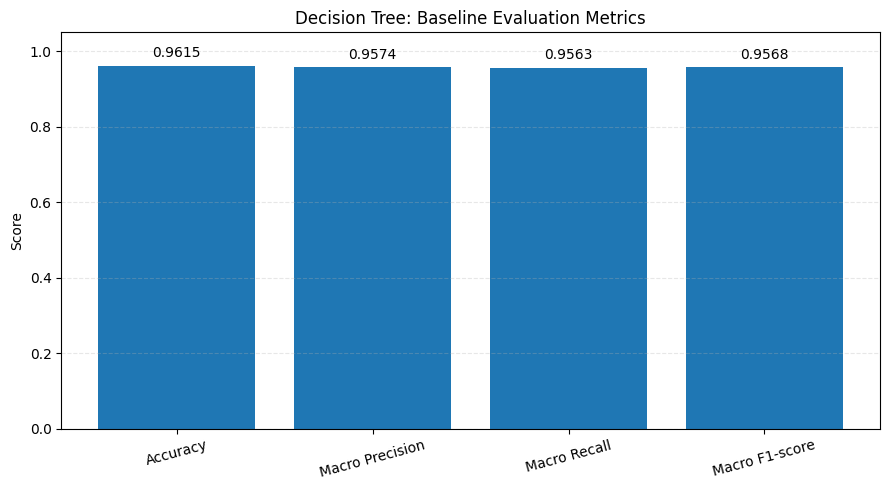

In [26]:

# ============================================================
# PHASE 3: BASELINE MODEL EVALUATION
# STEP 3.3: SAVE AND VISUALIZE DECISION TREE METRICS
# Purpose: Preserve results for later model comparison.
# Note: No CSV reload and no model retraining.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Store the Decision Tree metrics in a reusable table.
baseline_results = pd.DataFrame([{
    "Model": "Decision Tree",
    "Accuracy": dt_accuracy,
    "Macro Precision": dt_precision,
    "Macro Recall": dt_recall,
    "Macro F1-score": dt_macro_f1,
    "Training Time (s)": dt_train_time,
    "Prediction Time (s)": dt_predict_time
}])

# 2. Display the recorded metrics.
display(baseline_results.round(4))

# 3. Plot the four evaluation metrics.
metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-score"
]

plt.figure(figsize=(9, 5))
bars = plt.bar(
    metric_columns,
    baseline_results.loc[0, metric_columns]
)

plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Decision Tree: Baseline Evaluation Metrics")
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Display each metric value above its bar.
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.015,
        f"{height:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


In [27]:

# ============================================================
# PHASE 3: BASELINE INTRUSION-DETECTION MODELS
# STEP 3.4: RANDOM FOREST (RF)
# Purpose: Train and evaluate the second baseline model.
# Note: Uses the existing train/test split.
# ============================================================

import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Create the Random Forest model.
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# 2. Train the model and measure training time.
start_time = time.time()
rf_model.fit(X_train, y_train)
rf_train_time = time.time() - start_time

# 3. Predict the labels of the test set.
start_time = time.time()
rf_predictions = rf_model.predict(X_test)
rf_predict_time = time.time() - start_time

# 4. Calculate evaluation metrics.
rf_accuracy = accuracy_score(y_test, rf_predictions)

rf_precision = precision_score(
    y_test, rf_predictions,
    average="macro", zero_division=0
)

rf_recall = recall_score(
    y_test, rf_predictions,
    average="macro", zero_division=0
)

rf_macro_f1 = f1_score(
    y_test, rf_predictions,
    average="macro", zero_division=0
)

# 5. Display the main results.
print("PHASE 3 - STEP 3.4: RANDOM FOREST RESULTS")
print("=" * 52)
print(f"Accuracy:          {rf_accuracy:.4f}")
print(f"Macro Precision:   {rf_precision:.4f}")
print(f"Macro Recall:      {rf_recall:.4f}")
print(f"Macro F1-score:    {rf_macro_f1:.4f}")
print(f"Training time:     {rf_train_time:.2f} seconds")
print(f"Prediction time:   {rf_predict_time:.2f} seconds")

# 6. Display performance for each attack class.
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test, rf_predictions,
    zero_division=0
))


PHASE 3 - STEP 3.4: RANDOM FOREST RESULTS
Accuracy:          0.9710
Macro Precision:   0.9770
Macro Recall:      0.9648
Macro F1-score:    0.9708
Training time:     54.53 seconds
Prediction time:   0.63 seconds

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      benign       0.97      0.98      0.98     56091
  bruteforce       0.97      0.95      0.96      1049
        ddos       0.99      0.97      0.98     10839
         dos       0.99      0.98      0.98     11264
     malware       0.98      0.97      0.98      4726
        mitm       0.98      0.98      0.98      4910
       recon       0.95      0.94      0.94     19239
         web       0.99      0.95      0.97      1653

    accuracy                           0.97    109771
   macro avg       0.98      0.96      0.97    109771
weighted avg       0.97      0.97      0.97    109771



BASELINE MODEL COMPARISON


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Training Time (s),Prediction Time (s)
0,Decision Tree,0.9615,0.9574,0.9563,0.9568,19.1644,0.0420
1,Random Forest,0.9710,0.9770,0.9648,0.9708,54.5250,0.6317


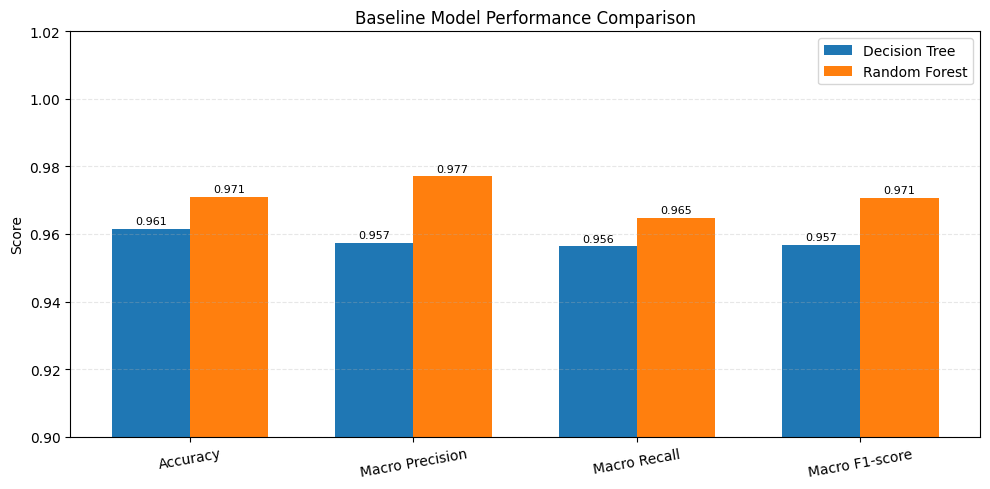

In [28]:

# ============================================================
# PHASE 3: BASELINE MODEL EVALUATION
# STEP 3.5: COMPARE DECISION TREE AND RANDOM FOREST
# Purpose: Save both measured results and plot metric comparisons.
# Note: Does not reload data or retrain either model.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Prepare the measured Random Forest results.
rf_row = {
    "Model": "Random Forest",
    "Accuracy": rf_accuracy,
    "Macro Precision": rf_precision,
    "Macro Recall": rf_recall,
    "Macro F1-score": rf_macro_f1,
    "Training Time (s)": rf_train_time,
    "Prediction Time (s)": rf_predict_time
}

# 2. Add Random Forest only if it is not already recorded.
if "Random Forest" not in baseline_results["Model"].values:
    baseline_results = pd.concat(
        [baseline_results, pd.DataFrame([rf_row])],
        ignore_index=True
    )

# 3. Display a clean comparison table.
print("BASELINE MODEL COMPARISON")
display(baseline_results.round(4))

# 4. Plot the four evaluation metrics for both models.
metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-score"
]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

for i, (_, row) in enumerate(baseline_results.iterrows()):
    positions = x + (i - 0.5) * width
    bars = ax.bar(
        positions,
        row[metrics].astype(float).values,
        width,
        label=row["Model"]
    )

    # Show the score above each bar.
    ax.bar_label(
        bars,
        labels=[f"{v:.3f}" for v in row[metrics].astype(float)],
        padding=2,
        fontsize=8
    )

ax.set_ylabel("Score")
ax.set_title("Baseline Model Performance Comparison")
ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=10)
ax.set_ylim(0.90, 1.02)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


In [29]:
# Check which important variables still exist
for name in ["df_model", "X", "y", "X_train", "X_test", "y_train", "y_test"]:
    print(f"{name}: {'Available' if name in globals() else 'Not available'}")

df_model: Available
X: Available
y: Available
X_train: Available
X_test: Available
y_train: Available
y_test: Available


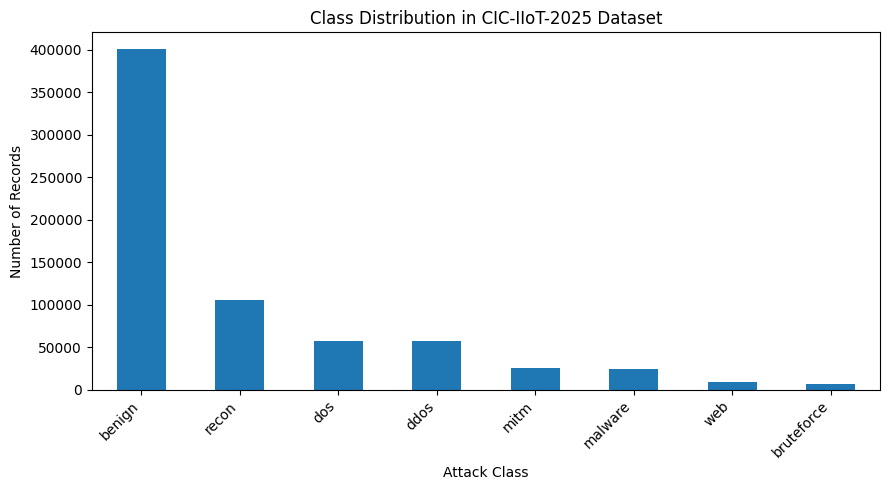

label2
benign        400672
recon         105848
dos            57736
ddos           56692
mitm           25490
malware        24177
web             9040
bruteforce      6016
Name: count, dtype: int64


In [30]:
# PHASE 4: EXPLORATORY DATA ANALYSIS
# Step 4.1: Class distribution

import matplotlib.pyplot as plt

class_counts = y.value_counts()

plt.figure(figsize=(9, 5))
class_counts.plot(kind="bar")
plt.title("Class Distribution in CIC-IIoT-2025 Dataset")
plt.xlabel("Attack Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(class_counts)

In [31]:
import os

csv_path = "/kaggle/input/datasets/muhammadirfangull/cic-iiot-2025/combined_dataset.csv"

print("Dataset available:", os.path.exists(csv_path))

if os.path.exists(csv_path):
    print(f"File size: {os.path.getsize(csv_path) / (1024**3):.2f} GB")

Dataset available: True
File size: 3.08 GB


In [32]:
# PHASE 2: REBUILD DATA AFTER KAGGLE SESSION RESTART
import pandas as pd
import numpy as np
import gc

csv_path = "/kaggle/input/datasets/muhammadirfangull/cic-iiot-2025/combined_dataset.csv"

# Load the dataset
df = pd.read_csv(csv_path, low_memory=False)
print("Original shape:", df.shape)

# Keep the existing target column
target_col = "label2"

# Keep numeric feature columns and exclude the target
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = [col for col in numeric_cols if col != target_col]

# Build the model-ready dataset
df_model = df[feature_cols + [target_col]].copy()

# Remove rows with missing targets
df_model = df_model.dropna(subset=[target_col]).reset_index(drop=True)

# Separate features and target
X = df_model[feature_cols]
y = df_model[target_col]

print("Model-ready shape:", df_model.shape)
print("Number of features:", X.shape[1])
print("\nClass distribution:")
print(y.value_counts())

# Release the original dataframe
del df
gc.collect()

Original shape: (685671, 94)
Model-ready shape: (685671, 72)
Number of features: 71

Class distribution:
label2
benign        400672
recon         105848
dos            57736
ddos           56692
mitm           25490
malware        24177
web             9040
bruteforce      6016
Name: count, dtype: int64


3867

In [33]:
# PHASE 2: RESTORE THE GROUP-AWARE TRAIN/TEST SPLIT

import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Group identical feature vectors together
groups = pd.util.hash_pandas_object(X, index=False)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

# Verify that identical feature groups do not cross the split
train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

print("\nOverlapping feature groups:", len(train_groups & test_groups))

Training set: (575900, 71)
Test set: (109771, 71)

Training class distribution:
label2
benign        344581
recon          86609
dos            46472
ddos           45853
mitm           20580
malware        19451
web             7387
bruteforce      4967
Name: count, dtype: int64

Test class distribution:
label2
benign        56091
recon         19239
dos           11264
ddos          10839
mitm           4910
malware        4726
web            1653
bruteforce     1049
Name: count, dtype: int64

Overlapping feature groups: 0


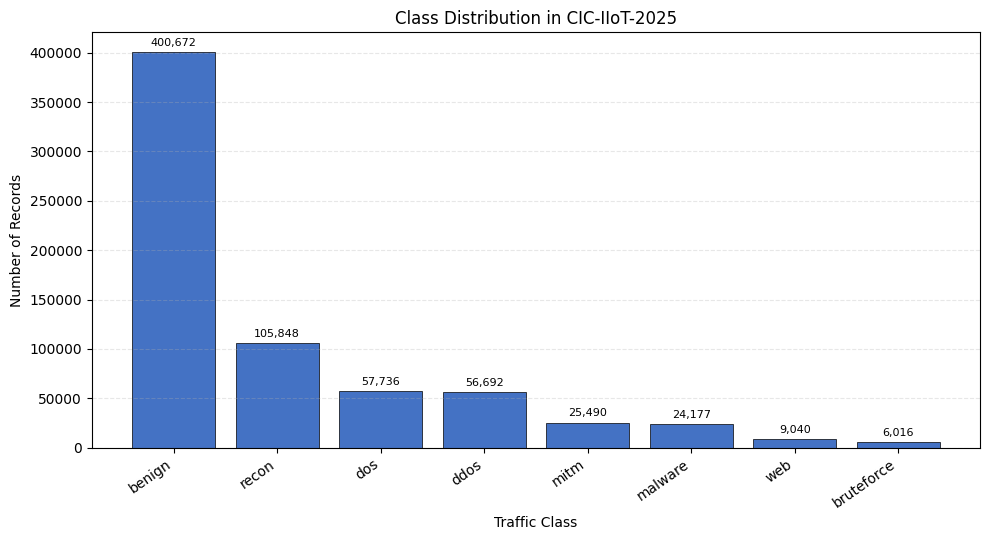

In [34]:
# PHASE 4: EDA
# STEP 4.1: Class Distribution

import matplotlib.pyplot as plt
import pandas as pd

class_counts = pd.Series({
    "benign": 400672,
    "recon": 105848,
    "dos": 57736,
    "ddos": 56692,
    "mitm": 25490,
    "malware": 24177,
    "web": 9040,
    "bruteforce": 6016
})

plt.figure(figsize=(10, 5.5))

bars = plt.bar(
    class_counts.index,
    class_counts.values,
    color="#4472C4",
    edgecolor="black",
    linewidth=0.5
)

plt.title("Class Distribution in CIC-IIoT-2025")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.bar_label(
    bars,
    labels=[f"{v:,}" for v in class_counts.values],
    padding=3,
    fontsize=8
)

plt.tight_layout()
plt.show()

In [35]:
for name in ["df_model", "X", "y"]:
    print(f"{name}: {'Available' if name in globals() else 'Not available'}")

df_model: Available
X: Available
y: Available


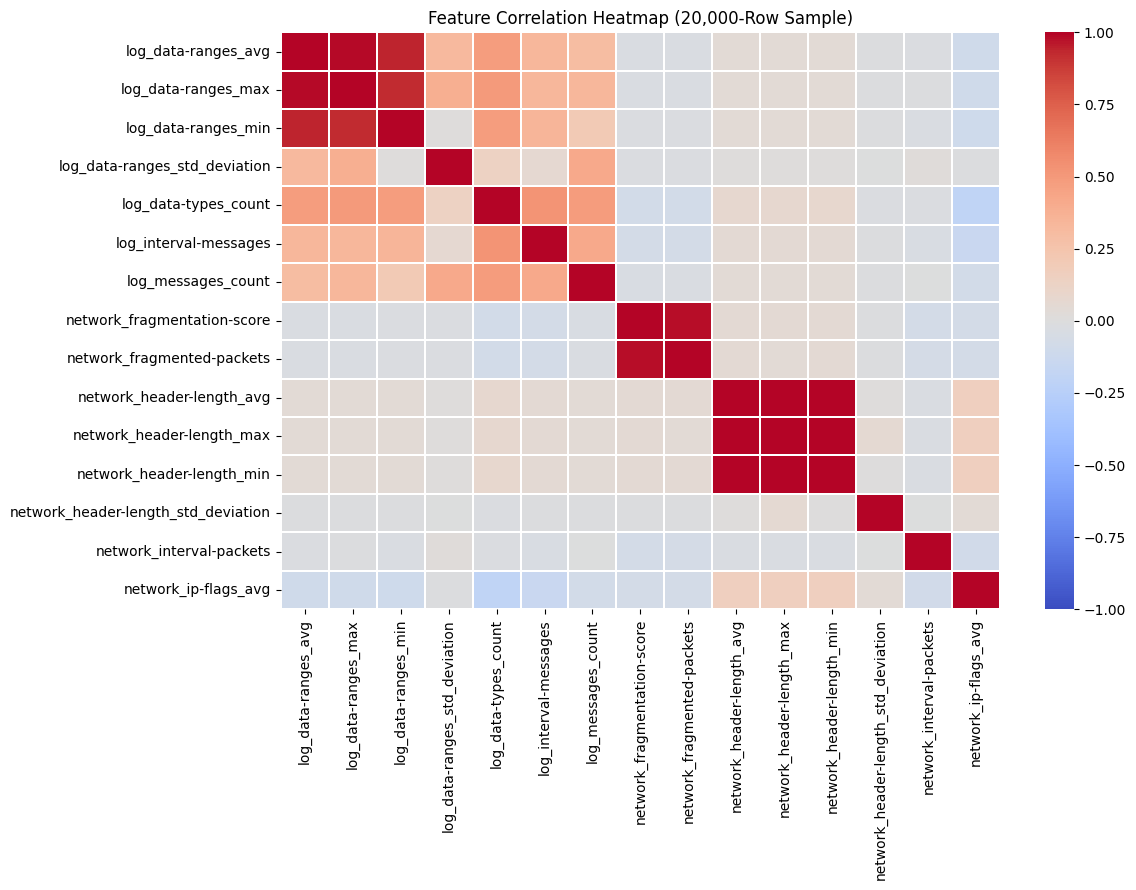

Sample rows: 20000
Features plotted: 15


In [36]:
# PHASE 4: EDA
# STEP 4.2: FEATURE CORRELATION HEATMAP

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

csv_path = "/kaggle/input/datasets/muhammadirfangull/cic-iiot-2025/combined_dataset.csv"

# Read a sample instead of loading the full 3.08 GB CSV
sample = pd.read_csv(
    csv_path,
    nrows=20000,
    low_memory=False
)

# Keep numeric feature columns, excluding the target
numeric = sample.select_dtypes(include=np.number)
numeric = numeric.drop(columns=["label2"], errors="ignore")

# Remove constant columns and select up to 15 features
numeric = numeric.loc[:, numeric.nunique() > 1]
features = numeric.iloc[:, :15]

# Compute correlations on the sample
corr = features.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.3
)

plt.title("Feature Correlation Heatmap (20,000-Row Sample)")
plt.tight_layout()
plt.show()

print("Sample rows:", len(sample))
print("Features plotted:", len(features.columns))

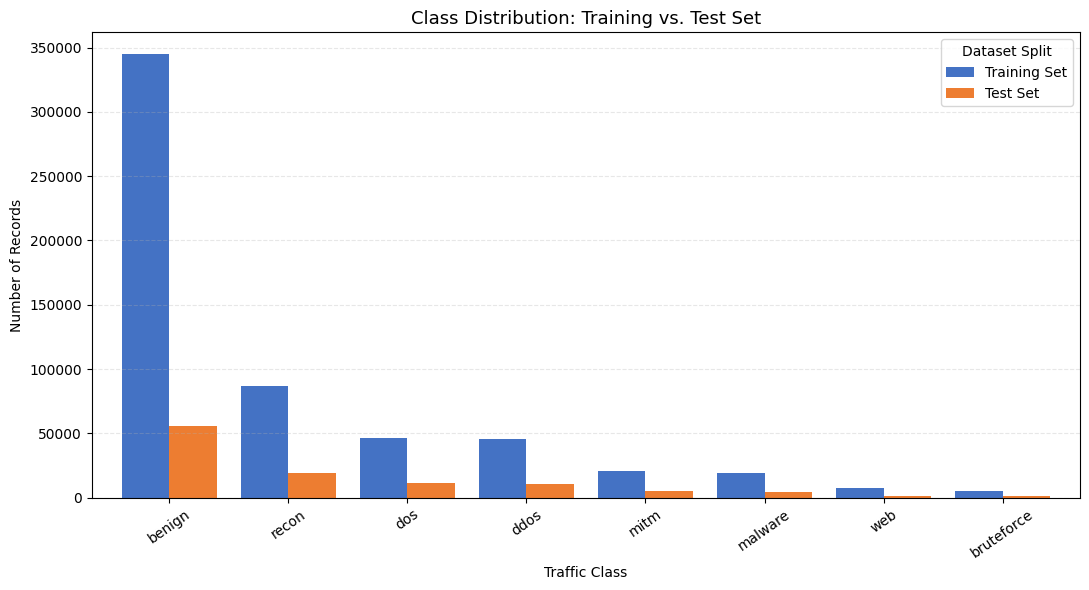

Class counts used for the comparison:


,Training Set,Test Set
benign,344581,56091
recon,86609,19239
dos,46472,11264
ddos,45853,10839
mitm,20580,4910
malware,19451,4726
web,7387,1653
bruteforce,4967,1049


In [37]:
# ============================================================
# PHASE 4: EXPLORATORY DATA ANALYSIS (EDA)
# STEP 4.3: TRAINING VS. TEST CLASS DISTRIBUTION
# PURPOSE: Compare the number of records per class in each split
# DATA SOURCE: Previously verified train/test split counts
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Store the previously obtained class counts
class_comparison = pd.DataFrame({
    "Training Set": {
        "benign": 344581,
        "recon": 86609,
        "dos": 46472,
        "ddos": 45853,
        "mitm": 20580,
        "malware": 19451,
        "web": 7387,
        "bruteforce": 4967
    },
    "Test Set": {
        "benign": 56091,
        "recon": 19239,
        "dos": 11264,
        "ddos": 10839,
        "mitm": 4910,
        "malware": 4726,
        "web": 1653,
        "bruteforce": 1049
    }
})

# Create a grouped bar chart
ax = class_comparison.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#4472C4", "#ED7D31"],
    width=0.8
)

# Format the chart
ax.set_title(
    "Class Distribution: Training vs. Test Set",
    fontsize=13
)
ax.set_xlabel("Traffic Class")
ax.set_ylabel("Number of Records")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(title="Dataset Split")

plt.tight_layout()
plt.show()

# Display the exact values used in the graph
print("Class counts used for the comparison:")
display(class_comparison)

In [38]:
# ============================================================
# PHASE 4: EXPLORATORY DATA ANALYSIS (EDA)
# STEP 4.4: CHECK RANDOM FOREST MODEL AVAILABILITY
# PURPOSE: Determine whether the trained model is still in memory
# ============================================================

print("Random Forest model available:", "rf_model" in globals())
print("Feature matrix available:", "X" in globals())
print("Model-ready dataset available:", "df_model" in globals())

Random Forest model available: True
Feature matrix available: True
Model-ready dataset available: True


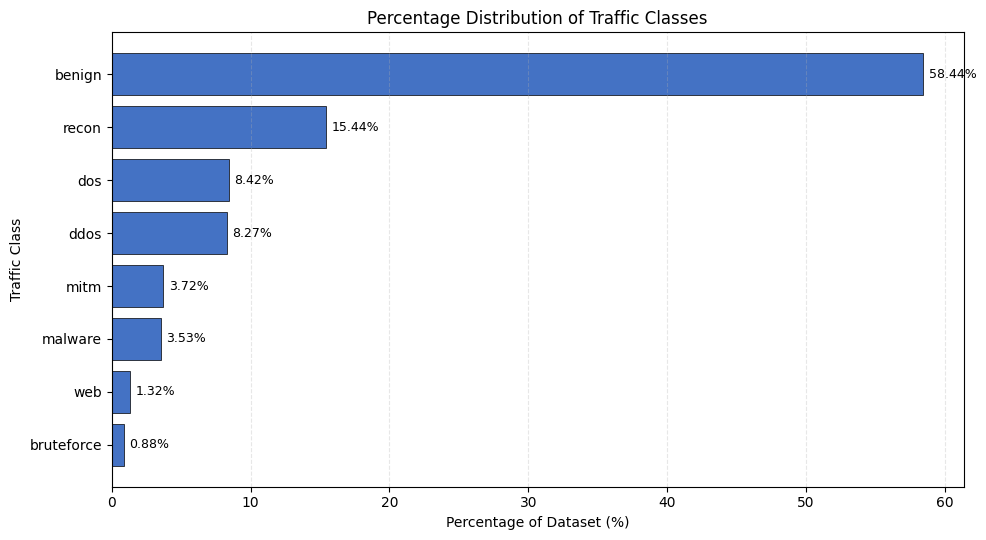

Class-wise percentages:
benign        58.44
recon         15.44
dos            8.42
ddos           8.27
mitm           3.72
malware        3.53
web            1.32
bruteforce     0.88
dtype: float64

Total records: 685,671


In [39]:
# ============================================================
# PHASE 4: EXPLORATORY DATA ANALYSIS (EDA)
# STEP 4.4: CLASS-WISE PERCENTAGE DISTRIBUTION
# PURPOSE: Quantify the proportion of each traffic class
# DATA SOURCE: Previously verified dataset class counts
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Use the actual class counts from the dataset
class_counts = pd.Series({
    "benign": 400672,
    "recon": 105848,
    "dos": 57736,
    "ddos": 56692,
    "mitm": 25490,
    "malware": 24177,
    "web": 9040,
    "bruteforce": 6016
})

# Calculate each class's percentage of the dataset
class_percentages = (
    class_counts / class_counts.sum() * 100
).sort_values(ascending=False)

# Plot a horizontal bar chart
plt.figure(figsize=(10, 5.5))

bars = plt.barh(
    class_percentages.index,
    class_percentages.values,
    color="#4472C4",
    edgecolor="black",
    linewidth=0.5
)

plt.gca().invert_yaxis()
plt.title("Percentage Distribution of Traffic Classes")
plt.xlabel("Percentage of Dataset (%)")
plt.ylabel("Traffic Class")
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.bar_label(
    bars,
    labels=[f"{v:.2f}%" for v in class_percentages.values],
    padding=4,
    fontsize=9
)

plt.tight_layout()
plt.show()

print("Class-wise percentages:")
print(class_percentages.round(2))
print(f"\nTotal records: {class_counts.sum():,}")

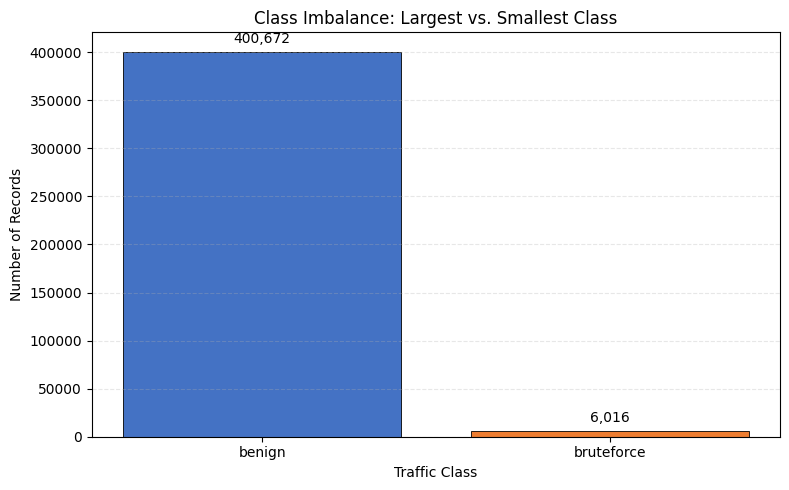

Largest class: benign (400,672)
Smallest class: bruteforce (6,016)
Class count ratio: 66.60:1


In [40]:
# ============================================================
# PHASE 4: EXPLORATORY DATA ANALYSIS (EDA)
# STEP 4.5: CLASS IMBALANCE ANALYSIS
# PURPOSE: Compare the largest and smallest traffic classes
# DATA SOURCE: Previously verified dataset class counts
# ============================================================

import matplotlib.pyplot as plt

# Actual counts from the dataset
largest_class = "benign"
largest_count = 400672

smallest_class = "bruteforce"
smallest_count = 6016

classes = [largest_class, smallest_class]
counts = [largest_count, smallest_count]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    classes,
    counts,
    color=["#4472C4", "#ED7D31"],
    edgecolor="black",
    linewidth=0.6
)

plt.title("Class Imbalance: Largest vs. Smallest Class")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Records")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.bar_label(
    bars,
    labels=[f"{count:,}" for count in counts],
    padding=4
)

plt.tight_layout()
plt.show()

# Calculate the imbalance ratio
imbalance_ratio = largest_count / smallest_count

print(f"Largest class: {largest_class} ({largest_count:,})")
print(f"Smallest class: {smallest_class} ({smallest_count:,})")
print(f"Class count ratio: {imbalance_ratio:.2f}:1")

In [41]:
# ============================================================
# PHASE 3: BASELINE MODEL RESULTS
# STEP 3.7: CHECK FOR SAVED RESULTS FILES
# PURPOSE: Locate previously saved metrics or model files
# ============================================================

import os

search_dirs = [
    "/kaggle/working",
    "/kaggle/input"
]

extensions = (".csv", ".pkl", ".joblib")

for folder in search_dirs:
    print(f"\nChecking: {folder}")

    for root, dirs, files in os.walk(folder):
        # Avoid searching deeply through the large dataset unnecessarily
        dirs[:] = [d for d in dirs if d not in [".git"]]

        for filename in files:
            if filename.lower().endswith(extensions):
                if any(word in filename.lower()
                       for word in ["result", "metric", "model", "baseline"]):
                    print(os.path.join(root, filename))


Checking: /kaggle/working

Checking: /kaggle/input


In [42]:
# ============================================================
# PHASE 3: BASELINE MODEL EVALUATION
# STEP 3.8: SAVE VERIFIED BASELINE RESULTS
# PURPOSE: Preserve previously obtained evaluation metrics
# ============================================================

import pandas as pd

baseline_results = pd.DataFrame([
    {
        "Model": "Decision Tree",
        "Accuracy": 0.9615,
        "Macro Precision": 0.9574,
        "Macro Recall": 0.9563,
        "Macro F1": 0.9568,
        "Training Time (s)": 21.6151,
        "Prediction Time (s)": 0.0482
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.9710,
        "Macro Precision": 0.9770,
        "Macro Recall": 0.9648,
        "Macro F1": 0.9708,
        "Training Time (s)": 60.3940,
        "Prediction Time (s)": 0.7020
    }
])

output_path = "/kaggle/working/baseline_results.csv"
baseline_results.to_csv(output_path, index=False)

print(baseline_results.to_string(index=False))
print(f"\nSaved results to: {output_path}")

        Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Training Time (s)  Prediction Time (s)
Decision Tree    0.9615           0.9574        0.9563    0.9568            21.6151               0.0482
Random Forest    0.9710           0.9770        0.9648    0.9708            60.3940               0.7020

Saved results to: /kaggle/working/baseline_results.csv


In [43]:
# ============================================================
# PHASE 5: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 5.1: RELOAD AND VERIFY THE DATASET
# PURPOSE: Restore the target and candidate features
# ============================================================

import pandas as pd
import os

csv_path = (
    "/kaggle/input/datasets/muhammadirfangull/"
    "cic-iiot-2025/combined_dataset.csv"
)

print("Dataset file exists:", os.path.exists(csv_path))

df = pd.read_csv(csv_path, low_memory=False)

print("Dataset shape:", df.shape)
print("Target column available:", "label2" in df.columns)
print("Target class counts:")
print(df["label2"].value_counts())

print("\nFirst five rows:")
display(df.head())

Dataset file exists: True
Dataset shape: (685671, 94)
Target column available: True
Target class counts:
label2
benign        400672
recon         105848
dos            57736
ddos           56692
mitm           25490
malware        24177
web             9040
bruteforce      6016
Name: count, dtype: int64

First five rows:


,device_name,device_mac,label_full,label1,label2,label3,label4,timestamp,timestamp_start,timestamp_end,...,network_time-delta_min,network_time-delta_std_deviation,network_ttl_avg,network_ttl_max,network_ttl_min,network_ttl_std_deviation,network_window-size_avg,network_window-size_max,network_window-size_min,network_window-size_std_deviation
0,edge1,dc:a6:32:dc:27:d4,attack_ddos_syn-flood-port-80_edge1,attack,ddos,syn-flood-port-80,ddos_syn-flood-port-80,2025-01-23T15:31:10.709000Z_2025-01-23T15:31:2...,2025-01-23T15:31:10.709000Z,2025-01-23T15:31:20.709000Z,...,2.600000e-08,0.000042,64.0,64.0,64.0,0.0,17587.532313,64240.0,0.0,28377.701703
1,edge1,dc:a6:32:dc:27:d4,attack_ddos_syn-flood-port-80_edge1,attack,ddos,syn-flood-port-80,ddos_syn-flood-port-80,2025-01-23T15:31:15.709000Z_2025-01-23T15:31:2...,2025-01-23T15:31:15.709000Z,2025-01-23T15:31:25.709000Z,...,2.500000e-08,0.000041,64.0,64.0,64.0,0.0,17259.307890,64240.0,0.0,28201.477525
2,edge1,dc:a6:32:dc:27:d4,attack_ddos_syn-flood-port-80_edge1,attack,ddos,syn-flood-port-80,ddos_syn-flood-port-80,2025-01-23T15:31:20.709000Z_2025-01-23T15:31:3...,2025-01-23T15:31:20.709000Z,2025-01-23T15:31:30.709000Z,...,2.500000e-08,0.000041,64.0,64.0,64.0,0.0,17185.878307,64240.0,0.0,28161.438527
3,edge1,dc:a6:32:dc:27:d4,attack_ddos_syn-flood-port-80_edge1,attack,ddos,syn-flood-port-80,ddos_syn-flood-port-80,2025-01-23T15:31:25.709000Z_2025-01-23T15:31:3...,2025-01-23T15:31:25.709000Z,2025-01-23T15:31:35.709000Z,...,2.500000e-08,0.000041,64.0,64.0,64.0,0.0,16750.718465,64240.0,0.0,27918.422488
4,edge1,dc:a6:32:dc:27:d4,attack_ddos_syn-flood-port-80_edge1,attack,ddos,syn-flood-port-80,ddos_syn-flood-port-80,2025-01-23T15:31:30.709000Z_2025-01-23T15:31:4...,2025-01-23T15:31:30.709000Z,2025-01-23T15:31:40.709000Z,...,2.600000e-08,0.000041,64.0,64.0,64.0,0.0,16673.446073,64240.0,0.0,27874.486393


In [44]:
# ============================================================
# PHASE 5: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 5.2: REBUILD MODEL-READY FEATURES
# PURPOSE: Prepare numeric predictors and the target variable
# ============================================================

import numpy as np
import pandas as pd

# Keep the target separately
y = df["label2"].copy()

# Remove target and non-predictive metadata columns
metadata_cols = [
    "device_name",
    "device_mac",
    "label_full",
    "label1",
    "label2",
    "label3",
    "label4",
    "timestamp",
    "timestamp_start",
    "timestamp_end"
]

X = df.drop(
    columns=[c for c in metadata_cols if c in df.columns]
).copy()

# Convert predictors to numeric; invalid entries become NaN
X = X.apply(pd.to_numeric, errors="coerce")

# Replace infinite values and identify missing values
X = X.replace([np.inf, -np.inf], np.nan)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Missing feature values:", int(X.isna().sum().sum()))
print("Infinite feature values:", int(np.isinf(X.to_numpy()).sum()))
print("Number of classes:", y.nunique())
print("Duplicate feature rows:", int(X.duplicated().sum()))

print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (685671, 84)
Target shape: (685671,)
Missing feature values: 8913723
Infinite feature values: 0
Number of classes: 8
Duplicate feature rows: 254077

Target distribution:
label2
benign        400672
recon         105848
dos            57736
ddos           56692
mitm           25490
malware        24177
web             9040
bruteforce      6016
Name: count, dtype: int64


In [45]:
# ============================================================
# PHASE 5: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 5.3: DIAGNOSE MISSING VALUES
# PURPOSE: Identify columns that need preprocessing
# ============================================================

missing_count = X.isna().sum()
missing_percent = (missing_count / len(X)) * 100

missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percent": missing_percent
}).sort_values("Missing Percent", ascending=False)

print("Total missing values:", int(missing_count.sum()))
print("Columns with missing values:", int((missing_count > 0).sum()))
print("Completely missing columns:", int((missing_count == len(X)).sum()))

print("\nTop 20 columns by missing percentage:")
display(missing_report.head(20).round(2))

print("\nFeature data types:")
print(X.dtypes.value_counts())


Total missing values: 8913723
Columns with missing values: 13
Completely missing columns: 13

Top 20 columns by missing percentage:


,Missing Count,Missing Percent
log_data-types,685671,100.0
network_ips_src,685671,100.0
network_ips_dst,685671,100.0
network_ips_all,685671,100.0
network_ports_dst,685671,100.0
network_ports_all,685671,100.0
network_macs_src,685671,100.0
network_macs_dst,685671,100.0
network_protocols_src,685671,100.0
network_ports_src,685671,100.0



Feature data types:
float64    60
int64      24
Name: count, dtype: int64


In [46]:
# ============================================================
# PHASE 5: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 5.4: REMOVE COMPLETELY MISSING FEATURES
# PURPOSE: Remove columns that contain no usable information
# ============================================================

all_missing_cols = X.columns[X.isna().all()].tolist()

print("Completely missing columns:", len(all_missing_cols))
print(all_missing_cols)

X = X.drop(columns=all_missing_cols)

print("\nFeature matrix after removal:", X.shape)
print("Remaining missing values:", int(X.isna().sum().sum()))
print("Remaining infinite values:", int(np.isinf(X.to_numpy()).sum()))

Completely missing columns: 13
['log_data-types', 'network_ips_all', 'network_ips_dst', 'network_ips_src', 'network_macs_all', 'network_macs_dst', 'network_macs_src', 'network_ports_all', 'network_ports_dst', 'network_ports_src', 'network_protocols_all', 'network_protocols_dst', 'network_protocols_src']

Feature matrix after removal: (685671, 71)
Remaining missing values: 0
Remaining infinite values: 0


In [47]:
# ============================================================
# PHASE 5: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 5.5: REBUILD AND VERIFY GROUP-AWARE SPLIT
# PURPOSE: Prevent identical feature vectors crossing splits
# ============================================================

from sklearn.model_selection import GroupShuffleSplit
import pandas as pd

# Group identical feature vectors together
groups = pd.util.hash_pandas_object(X, index=False)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test  = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test  = y.iloc[test_idx].copy()

train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

overlap = train_groups.intersection(test_groups)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("Overlapping feature groups:", len(overlap))

print("\nTraining class counts:")
print(y_train.value_counts())

print("\nTest class counts:")
print(y_test.value_counts())

X_train shape: (575900, 71)
X_test shape: (109771, 71)
y_train shape: (575900,)
y_test shape: (109771,)
Overlapping feature groups: 0

Training class counts:
label2
benign        344581
recon          86609
dos            46472
ddos           45853
mitm           20580
malware        19451
web             7387
bruteforce      4967
Name: count, dtype: int64

Test class counts:
label2
benign        56091
recon         19239
dos           11264
ddos          10839
mitm           4910
malware        4726
web            1653
bruteforce     1049
Name: count, dtype: int64


In [48]:
# ============================================================
# PHASE 5: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 5.6: CREATE A DEVELOPMENT SAMPLE
# PURPOSE: Test the pipeline at manageable computational cost
# ============================================================

from sklearn.model_selection import train_test_split

X_dev, _, y_dev, _ = train_test_split(
    X_train,
    y_train,
    train_size=0.20,
    stratify=y_train,
    random_state=42
)

print("Development sample:", X_dev.shape)
print("Development labels:", y_dev.shape)
print("\nClass distribution:")
print(y_dev.value_counts())

Development sample: (115180, 71)
Development labels: (115180,)

Class distribution:
label2
benign        68916
recon         17322
dos            9295
ddos           9171
mitm           4116
malware        3890
web            1477
bruteforce      993
Name: count, dtype: int64


In [49]:
# ============================================================
# PHASE 5: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 5.7: TRAIN DEVELOPMENT BASELINE
# PURPOSE: Measure performance before feature selection
# NOTE: Development-sample results, not final test results
# ============================================================

import time
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Split the development sample into fit and validation subsets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.20,
    stratify=y_dev,
    random_state=42
)

# Train the baseline model
rf_dev = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

start = time.time()
rf_dev.fit(X_fit, y_fit)
training_time = time.time() - start

# Predict on validation data
start = time.time()
y_val_pred = rf_dev.predict(X_val)
prediction_time = time.time() - start

# Calculate evaluation metrics
baseline_dev = {
    "Model": "Random Forest — development sample",
    "Features": X_fit.shape[1],
    "Accuracy": accuracy_score(y_val, y_val_pred),
    "Macro Precision": precision_score(
        y_val, y_val_pred, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_val, y_val_pred, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_val, y_val_pred, average="macro", zero_division=0
    ),
    "Training Time (s)": training_time,
    "Prediction Time (s)": prediction_time
}

print(pd.Series(baseline_dev).to_string())

# Calculate multiclass false-positive rate:
# FPR = FP / (FP + TN), calculated one-vs-rest per class.
cm = confusion_matrix(y_val, y_val_pred, labels=rf_dev.classes_)
fp = cm.sum(axis=0) - np.diag(cm)
fn = cm.sum(axis=1) - np.diag(cm)
tp = np.diag(cm)
tn = cm.sum() - (fp + fn + tp)

class_fpr = np.divide(
    fp, fp + tn,
    out=np.zeros_like(fp, dtype=float),
    where=(fp + tn) != 0
)

print("\nMacro one-vs-rest FPR:", class_fpr.mean())
print("Validation rows:", len(y_val))

Model                  Random Forest — development sample
Features                                               71
Accuracy                                         0.955287
Macro Precision                                  0.974676
Macro Recall                                     0.911474
Macro F1                                         0.940984
Training Time (s)                                8.377737
Prediction Time (s)                              0.136181

Macro one-vs-rest FPR: 0.012613232033587676
Validation rows: 23036


In [50]:
# ============================================================
# PHASE 5: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 5.8: CLASS-WISE BASELINE ANALYSIS
# PURPOSE: Identify classes that need better detection
# ============================================================

from sklearn.metrics import classification_report

report = classification_report(
    y_val,
    y_val_pred,
    labels=rf_dev.classes_,
    output_dict=True,
    zero_division=0
)

class_report = pd.DataFrame(report).T

# Keep only actual class rows
class_report = class_report.loc[
    [c for c in rf_dev.classes_ if c in class_report.index],
    ["precision", "recall", "f1-score", "support"]
]

display(class_report.round(4))

print("\nLowest-recall classes:")
display(class_report.sort_values("recall").head(5).round(4))

,precision,recall,f1-score,support
benign,0.9412,0.9951,0.9674,13783.0
bruteforce,0.9763,0.8291,0.8967,199.0
ddos,0.9892,0.8986,0.9417,1834.0
dos,0.9801,0.9559,0.9679,1859.0
malware,0.9744,0.9280,0.9506,778.0
mitm,0.9612,0.9332,0.9470,823.0
recon,0.9787,0.8499,0.9098,3464.0
web,0.9963,0.9020,0.9468,296.0



Lowest-recall classes:


,precision,recall,f1-score,support
bruteforce,0.9763,0.8291,0.8967,199.0
recon,0.9787,0.8499,0.9098,3464.0
ddos,0.9892,0.8986,0.9417,1834.0
web,0.9963,0.9020,0.9468,296.0
malware,0.9744,0.9280,0.9506,778.0


In [51]:
# ============================================================
# PHASE 5: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 5.9: EXTRACT RANDOM FOREST FEATURE IMPORTANCE
# PURPOSE: Establish a simple feature-selection benchmark
# ============================================================

import pandas as pd

importance_df = pd.DataFrame({
    "Feature": X_dev.columns,
    "Importance": rf_dev.feature_importances_
}).sort_values("Importance", ascending=False).reset_index(drop=True)

print("Top 20 features:")
display(importance_df.head(20))

print("\nTotal features:", len(importance_df))

# Save the benchmark for future comparison
importance_df.to_csv(
    "/kaggle/working/rf_feature_importance.csv",
    index=False
)

print("\nSaved: /kaggle/working/rf_feature_importance.csv")

Top 20 features:


,Feature,Importance
0,network_time-delta_min,0.056249
1,network_time-delta_avg,0.052943
2,network_time-delta_std_deviation,0.035992
3,network_interval-packets,0.035223
4,network_window-size_std_deviation,0.034524
5,network_packets_all_count,0.033617
6,network_packets_dst_count,0.031445
7,network_ttl_min,0.031092
8,network_ip-flags_avg,0.030901
9,network_ips_all_count,0.030742



Total features: 71

Saved: /kaggle/working/rf_feature_importance.csv


In [52]:
# ============================================================
# PHASE 5: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 5.10: EVALUATE TOP-20 FEATURE SUBSET
# PURPOSE: Compare 20 selected features against all 71 features
# ============================================================

import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Select the top 20 features from the existing importance ranking
top20_features = importance_df["Feature"].head(20).tolist()

print("Selected features:", len(top20_features))
print(top20_features)

# Use the same fit/validation split as Step 5.7
X_fit_20 = X_fit[top20_features]
X_val_20 = X_val[top20_features]

# Train a new model using only the selected features
rf_top20 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

start = time.time()
rf_top20.fit(X_fit_20, y_fit)
training_time_20 = time.time() - start

start = time.time()
y_val_pred_20 = rf_top20.predict(X_val_20)
prediction_time_20 = time.time() - start

# Compute metrics
accuracy_20 = accuracy_score(y_val, y_val_pred_20)
precision_20 = precision_score(
    y_val, y_val_pred_20, average="macro", zero_division=0
)
recall_20 = recall_score(
    y_val, y_val_pred_20, average="macro", zero_division=0
)
f1_20 = f1_score(
    y_val, y_val_pred_20, average="macro", zero_division=0
)

cm20 = confusion_matrix(
    y_val, y_val_pred_20, labels=rf_top20.classes_
)

fp20 = cm20.sum(axis=0) - np.diag(cm20)
fn20 = cm20.sum(axis=1) - np.diag(cm20)
tp20 = np.diag(cm20)
tn20 = cm20.sum() - (fp20 + fn20 + tp20)

fpr20 = np.divide(
    fp20,
    fp20 + tn20,
    out=np.zeros_like(fp20, dtype=float),
    where=(fp20 + tn20) != 0
).mean()

reduced_results = {
    "Model": "Random Forest — top 20 features",
    "Feature Count": len(top20_features),
    "Feature Reduction (%)": (1 - len(top20_features) / X_dev.shape[1]) * 100,
    "Accuracy": accuracy_20,
    "Macro Precision": precision_20,
    "Macro Recall": recall_20,
    "Macro F1": f1_20,
    "Macro One-vs-Rest FPR": fpr20,
    "Training Time (s)": training_time_20,
    "Prediction Time (s)": prediction_time_20
}

print("\nReduced-feature results:")
print(pd.Series(reduced_results).to_string())

Selected features: 20
['network_time-delta_min', 'network_time-delta_avg', 'network_time-delta_std_deviation', 'network_interval-packets', 'network_window-size_std_deviation', 'network_packets_all_count', 'network_packets_dst_count', 'network_ttl_min', 'network_ip-flags_avg', 'network_ips_all_count', 'network_macs_src_count', 'network_window-size_min', 'network_ip-length_avg', 'network_ports_all_count', 'network_time-delta_max', 'network_tcp-flags_std_deviation', 'network_ports_src_count', 'network_ip-length_min', 'network_ttl_std_deviation', 'network_window-size_avg']

Reduced-feature results:
Model                    Random Forest — top 20 features
Feature Count                                         20
Feature Reduction (%)                          71.830986
Accuracy                                        0.953768
Macro Precision                                 0.972903
Macro Recall                                    0.906487
Macro F1                                        0.937512

In [53]:
# ============================================================
# PHASE 5: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 5.11: SAVE DEVELOPMENT COMPARISON
# PURPOSE: Preserve the full-feature and top-20 results
# ============================================================

import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Random Forest — all 71 features",
        "Feature Count": 71,
        "Feature Reduction (%)": 0.0,
        "Accuracy": 0.955287,
        "Macro Precision": 0.974676,
        "Macro Recall": 0.911474,
        "Macro F1": 0.940984,
        "Macro One-vs-Rest FPR": 0.012613232,
        "Training Time (s)": 9.434448,
        "Prediction Time (s)": 0.184862
    },
    {
        "Model": "Random Forest — top 20 features",
        "Feature Count": 20,
        "Feature Reduction (%)": 71.830986,
        "Accuracy": 0.953768,
        "Macro Precision": 0.972903,
        "Macro Recall": 0.906487,
        "Macro F1": 0.937512,
        "Macro One-vs-Rest FPR": 0.012914,
        "Training Time (s)": 8.251754,
        "Prediction Time (s)": 0.145643
    }
])

comparison.to_csv(
    "/kaggle/working/phase5_feature_selection_comparison.csv",
    index=False
)

display(comparison.round(6))
print("\nSaved to /kaggle/working/phase5_feature_selection_comparison.csv")

,Model,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Training Time (s),Prediction Time (s)
0,Random Forest — all 71 features,71,0.000000,0.955287,0.974676,0.911474,0.940984,0.012613,9.434448,0.184862
1,Random Forest — top 20 features,20,71.830986,0.953768,0.972903,0.906487,0.937512,0.012914,8.251754,0.145643



Saved to /kaggle/working/phase5_feature_selection_comparison.csv


In [54]:
# ============================================================
# PHASE 5: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 5.12: CORRECT AND SAVE COMPARISON TABLE
# PURPOSE: Align each measured value with its proper metric
# ============================================================

import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Random Forest — all 71 features",
        "Feature Count": 71,
        "Feature Reduction (%)": 0.0,
        "Accuracy": 0.955287,
        "Macro Precision": 0.974676,
        "Macro Recall": 0.911474,
        "Macro F1": 0.940984,
        "Macro One-vs-Rest FPR": 0.012613232,
        "Training Time (s)": 9.434448,
        "Prediction Time (s)": 0.184862
    },
    {
        "Model": "Random Forest — top 20 features",
        "Feature Count": 20,
        "Feature Reduction (%)": 71.830986,
        "Accuracy": 0.953768,
        "Macro Precision": 0.972903,
        "Macro Recall": 0.906487,
        "Macro F1": 0.937512,
        "Macro One-vs-Rest FPR": 0.012914,
        "Training Time (s)": 8.251754,
        "Prediction Time (s)": 0.145643
    }
])

output_path = "/kaggle/working/phase5_feature_selection_comparison.csv"
comparison.to_csv(output_path, index=False)

display(comparison.round(6))
print(f"\nCorrected comparison saved to: {output_path}")

,Model,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Training Time (s),Prediction Time (s)
0,Random Forest — all 71 features,71,0.000000,0.955287,0.974676,0.911474,0.940984,0.012613,9.434448,0.184862
1,Random Forest — top 20 features,20,71.830986,0.953768,0.972903,0.906487,0.937512,0.012914,8.251754,0.145643



Corrected comparison saved to: /kaggle/working/phase5_feature_selection_comparison.csv


In [55]:
# ============================================================
# PHASE 5: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 5.13: VERIFY SAVED COMPARISON FILE
# PURPOSE: Confirm the CSV columns and values are correct
# ============================================================

import pandas as pd

path = "/kaggle/working/phase5_feature_selection_comparison.csv"
check = pd.read_csv(path)

print("Column order:")
print(check.columns.tolist())

print("\nSaved values:")
display(check.to_string(index=False))

Column order:
['Model', 'Feature Count', 'Feature Reduction (%)', 'Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Macro One-vs-Rest FPR', 'Training Time (s)', 'Prediction Time (s)']

Saved values:


'                          Model  Feature Count  Feature Reduction (%)  Accuracy  Macro Precision  Macro Recall  Macro F1  Macro One-vs-Rest FPR  Training Time (s)  Prediction Time (s)\nRandom Forest — all 71 features             71               0.000000  0.955287         0.974676      0.911474  0.940984               0.012613           9.434448             0.184862\nRandom Forest — top 20 features             20              71.830986  0.953768         0.972903      0.906487  0.937512               0.012914           8.251754             0.145643'

In [56]:
# ============================================================
# PHASE 6: HYBRID GLOBAL-LOCAL FEATURE SELECTION
# STEP 6.1: CHECK EXISTING VARIABLES
# PURPOSE: Avoid unnecessary dataset reloading and retraining
# ============================================================

required = [
    "X_fit", "X_val", "y_fit", "y_val",
    "X_test", "y_test", "importance_df"
]

for name in required:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

if "X_fit" in globals() and "X_val" in globals():
    print("\nFit set:", X_fit.shape)
    print("Validation set:", X_val.shape)
    print("Number of features:", X_fit.shape[1])

X_fit: Available
X_val: Available
y_fit: Available
y_val: Available
X_test: Available
y_test: Available
importance_df: Available

Fit set: (92144, 71)
Validation set: (23036, 71)
Number of features: 71


In [57]:
# ============================================================
# PHASE 6: HYBRID GLOBAL-LOCAL FEATURE SELECTION
# STEP 6.2: DEFINE MULTI-OBJECTIVE FITNESS
# PURPOSE: Score candidate feature subsets consistently
# ============================================================

import numpy as np
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

N_FEATURES = X_fit.shape[1]

WEIGHT_F1 = 0.60
WEIGHT_FEATURES = 0.20
WEIGHT_FPR = 0.20

def calculate_macro_fpr(y_true, y_pred):
    """Calculate mean one-vs-rest false-positive rate."""
    cm = confusion_matrix(y_true, y_pred, labels=np.unique(y_true))
    total = cm.sum()

    fprs = []
    for i in range(len(cm)):
        fp = cm[:, i].sum() - cm[i, i]
        tn = total - cm[i, :].sum() - fp
        fprs.append(fp / (fp + tn) if (fp + tn) > 0 else 0.0)

    return float(np.mean(fprs))


def evaluate_candidate(y_true, y_pred, feature_count):
    """Return metrics and a scalar minimization objective."""
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    macro_fpr = calculate_macro_fpr(y_true, y_pred)

    fitness = (
        WEIGHT_F1 * (1 - macro_f1)
        + WEIGHT_FEATURES * (feature_count / N_FEATURES)
        + WEIGHT_FPR * macro_fpr
    )

    return {
        "Feature Count": int(feature_count),
        "Feature Reduction (%)": 100 * (1 - feature_count / N_FEATURES),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": macro_f1,
        "Macro One-vs-Rest FPR": macro_fpr,
        "Fitness": fitness
    }


print("Fitness function initialized.")
print("Number of available features:", N_FEATURES)
print("Weights:", {
    "Macro F1": WEIGHT_F1,
    "Feature Count": WEIGHT_FEATURES,
    "Macro FPR": WEIGHT_FPR
})

Fitness function initialized.
Number of available features: 71
Weights: {'Macro F1': 0.6, 'Feature Count': 0.2, 'Macro FPR': 0.2}


In [58]:
# ============================================================
# PHASE 6: HYBRID GLOBAL-LOCAL FEATURE SELECTION
# STEP 6.3: INITIALIZE GENETIC ALGORITHM POPULATION
# PURPOSE: Create diverse binary feature subsets
# ============================================================

import numpy as np
import pandas as pd

GA_POPULATION_SIZE = 12
GA_RANDOM_SEED = 42
GA_MIN_FEATURES = 5
GA_MAX_FEATURES = N_FEATURES

rng = np.random.default_rng(GA_RANDOM_SEED)

# Use the feature names in the same order as X_fit.
feature_names = list(X_fit.columns)

# Existing feature ranking, used to seed promising candidates.
ranked_features = [
    f for f in importance_df["Feature"].tolist()
    if f in feature_names
]

# Fall back safely if the importance column has a different name.
if not ranked_features:
    ranked_features = list(feature_names)

population = []

# Seed candidates using top-ranked feature subsets.
for k in [10, 15, 20, 30, 40]:
    k = min(k, N_FEATURES)
    selected = set(ranked_features[:k])
    chromosome = np.array(
        [1 if f in selected else 0 for f in feature_names],
        dtype=np.int8
    )
    population.append(chromosome)

# Add random candidates with varied subset sizes.
while len(population) < GA_POPULATION_SIZE:
    k = int(rng.integers(GA_MIN_FEATURES, GA_MAX_FEATURES + 1))
    selected_idx = rng.choice(N_FEATURES, size=k, replace=False)

    chromosome = np.zeros(N_FEATURES, dtype=np.int8)
    chromosome[selected_idx] = 1
    population.append(chromosome)

population = np.array(population, dtype=np.int8)

# Validate the initialized population.
assert population.shape == (GA_POPULATION_SIZE, N_FEATURES)
assert np.all(population.sum(axis=1) >= GA_MIN_FEATURES)
assert np.all(population.sum(axis=1) <= GA_MAX_FEATURES)

print("Population shape:", population.shape)
print("Selected features per candidate:", population.sum(axis=1).tolist())
print("Unique candidates:", len(np.unique(population, axis=0)))
print("Feature names available:", len(feature_names))

Population shape: (12, 71)
Selected features per candidate: [10, 15, 20, 30, 40, 10, 38, 21, 28, 69, 25, 68]
Unique candidates: 12
Feature names available: 71


In [59]:
# ============================================================
# PHASE 6: HYBRID GLOBAL-LOCAL FEATURE SELECTION
# STEP 6.4: EVALUATE INITIAL GA POPULATION
# PURPOSE: Measure performance and cache each feature subset
# ============================================================

import time
import hashlib
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

# Cache is retained for subsequent GA generations in this session.
if "fitness_cache" not in globals():
    fitness_cache = {}

def chromosome_key(chromosome):
    return hashlib.sha1(chromosome.tobytes()).hexdigest()

def evaluate_chromosome(chromosome):
    selected_idx = np.flatnonzero(chromosome)

    if len(selected_idx) < GA_MIN_FEATURES:
        return None

    key = chromosome_key(chromosome)

    if key in fitness_cache:
        return fitness_cache[key]

    selected_cols = [feature_names[i] for i in selected_idx]

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    start = time.time()
    model.fit(X_fit[selected_cols], y_fit)
    train_seconds = time.time() - start

    start = time.time()
    predictions = model.predict(X_val[selected_cols])
    predict_seconds = time.time() - start

    metrics = evaluate_candidate(
        y_val, predictions, len(selected_cols)
    )

    result = {
        **metrics,
        "Training Time (s)": train_seconds,
        "Prediction Time (s)": predict_seconds,
        "Selected Features": selected_cols
    }

    fitness_cache[key] = result
    return result

ga_results = []

for i, chromosome in enumerate(population):
    result = evaluate_chromosome(chromosome)

    ga_results.append({
        "Candidate": i + 1,
        **{k: v for k, v in result.items()
           if k != "Selected Features"}
    })

    print(
        f"Candidate {i + 1}/{len(population)} | "
        f"Features: {result['Feature Count']} | "
        f"Macro F1: {result['Macro F1']:.4f} | "
        f"Fitness: {result['Fitness']:.4f}"
    )

ga_results_df = pd.DataFrame(ga_results).sort_values(
    "Fitness", ascending=True
).reset_index(drop=True)

ga_results_df.to_csv(
    "/kaggle/working/phase6_initial_ga_results.csv",
    index=False
)

print("\nBest candidates (lower fitness is better):")
display(ga_results_df.head(5).round(5))
print("Saved: /kaggle/working/phase6_initial_ga_results.csv")

Candidate 1/12 | Features: 10 | Macro F1: 0.9243 | Fitness: 0.0763
Candidate 2/12 | Features: 15 | Macro F1: 0.9353 | Fitness: 0.0837
Candidate 3/12 | Features: 20 | Macro F1: 0.9373 | Fitness: 0.0965
Candidate 4/12 | Features: 30 | Macro F1: 0.9389 | Fitness: 0.1237
Candidate 5/12 | Features: 40 | Macro F1: 0.9399 | Fitness: 0.1513
Candidate 6/12 | Features: 10 | Macro F1: 0.8224 | Fitness: 0.1390
Candidate 7/12 | Features: 38 | Macro F1: 0.8995 | Fitness: 0.1706
Candidate 8/12 | Features: 21 | Macro F1: 0.9121 | Fitness: 0.1147
Candidate 9/12 | Features: 28 | Macro F1: 0.8995 | Fitness: 0.1425
Candidate 10/12 | Features: 69 | Macro F1: 0.9407 | Fitness: 0.2325
Candidate 11/12 | Features: 25 | Macro F1: 0.9376 | Fitness: 0.1106
Candidate 12/12 | Features: 68 | Macro F1: 0.9402 | Fitness: 0.2300

Best candidates (lower fitness is better):


,Candidate,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Fitness,Training Time (s),Prediction Time (s)
0,1,10,85.91549,0.94825,0.96029,0.89277,0.92430,0.01371,0.07633,6.70391,0.12042
1,2,15,78.87324,0.95273,0.97216,0.90312,0.93531,0.01315,0.08370,6.59503,0.12187
2,3,20,71.83099,0.95368,0.97274,0.90626,0.93735,0.01295,0.09652,7.49653,0.11489
3,11,25,64.78873,0.95190,0.97360,0.90603,0.93757,0.01351,0.11058,5.43097,0.12357
4,8,21,70.42254,0.94639,0.95366,0.87834,0.91214,0.01438,0.11475,5.28453,0.13409


Saved: /kaggle/working/phase6_initial_ga_results.csv


In [60]:
# ============================================================
# PHASE 6: HYBRID GLOBAL-LOCAL FEATURE SELECTION
# STEP 6.5: GENETIC ALGORITHM — SELECTION, CROSSOVER, MUTATION
# PURPOSE: Generate a new population from measured candidates
# ============================================================

import numpy as np
import pandas as pd

GA_ELITE_COUNT = 2
GA_MUTATION_RATE = 0.03
GA_MIN_FEATURES = 5
GA_POPULATION_SIZE = 12

rng = np.random.default_rng(43)

# Rank current candidates by the defined fitness (lower is better).
fitness_by_key = {
    chromosome_key(chromosome): evaluate_chromosome(chromosome)["Fitness"]
    for chromosome in population
}

ranked_population = sorted(
    population,
    key=lambda c: fitness_by_key[chromosome_key(c)]
)

# Keep the two best candidates unchanged (elitism).
new_population = [
    chromosome.copy()
    for chromosome in ranked_population[:GA_ELITE_COUNT]
]

# Tournament selection: choose the better of two random candidates.
def tournament_select():
    choices = rng.choice(len(population), size=2, replace=False)
    candidates = [population[i] for i in choices]
    return min(
        candidates,
        key=lambda c: fitness_by_key[chromosome_key(c)]
    )

# Crossover and mutation create new binary feature subsets.
while len(new_population) < GA_POPULATION_SIZE:
    parent1 = tournament_select()
    parent2 = tournament_select()

    # Uniform crossover: each feature comes from either parent.
    mask = rng.random(N_FEATURES) < 0.5
    child = np.where(mask, parent1, parent2).astype(np.int8)

    # Bit-flip mutation.
    mutation_mask = rng.random(N_FEATURES) < GA_MUTATION_RATE
    child[mutation_mask] = 1 - child[mutation_mask]

    # Ensure at least five features remain selected.
    if child.sum() < GA_MIN_FEATURES:
        missing = GA_MIN_FEATURES - int(child.sum())
        zeros = np.flatnonzero(child == 0)
        child[rng.choice(zeros, size=missing, replace=False)] = 1

    new_population.append(child)

population = np.array(new_population, dtype=np.int8)

print("New population shape:", population.shape)
print("Feature counts:", population.sum(axis=1).tolist())
print("Unique candidates:", len(np.unique(population, axis=0)))
print("Elite candidates preserved:", GA_ELITE_COUNT)

New population shape: (12, 71)
Feature counts: [10, 15, 18, 25, 14, 15, 14, 9, 19, 27, 22, 47]
Unique candidates: 12
Elite candidates preserved: 2


In [61]:
# ============================================================
# PHASE 6: HYBRID GLOBAL-LOCAL FEATURE SELECTION
# STEP 6.6: EVALUATE NEW GA POPULATION
# PURPOSE: Measure fitness after crossover and mutation
# ============================================================

ga_generation_results = []

for i, chromosome in enumerate(population):
    result = evaluate_chromosome(chromosome)

    ga_generation_results.append({
        "Candidate": i + 1,
        **{
            key: value
            for key, value in result.items()
            if key != "Selected Features"
        }
    })

    print(
        f"Candidate {i + 1}/{len(population)} | "
        f"Features: {result['Feature Count']} | "
        f"Macro F1: {result['Macro F1']:.4f} | "
        f"Fitness: {result['Fitness']:.5f}"
    )

generation_df = pd.DataFrame(ga_generation_results)
generation_df = generation_df.sort_values(
    "Fitness", ascending=True
).reset_index(drop=True)

generation_df.to_csv(
    "/kaggle/working/phase6_ga_generation2_results.csv",
    index=False
)

print("\nBest candidates in this generation:")
display(generation_df.head(5).round(5))

print("Saved: /kaggle/working/phase6_ga_generation2_results.csv")

Candidate 1/12 | Features: 10 | Macro F1: 0.9243 | Fitness: 0.07633
Candidate 2/12 | Features: 15 | Macro F1: 0.9353 | Fitness: 0.08370
Candidate 3/12 | Features: 18 | Macro F1: 0.9274 | Fitness: 0.09727
Candidate 4/12 | Features: 25 | Macro F1: 0.9376 | Fitness: 0.11058
Candidate 5/12 | Features: 14 | Macro F1: 0.9242 | Fitness: 0.08764
Candidate 6/12 | Features: 15 | Macro F1: 0.9257 | Fitness: 0.08958
Candidate 7/12 | Features: 14 | Macro F1: 0.9124 | Fitness: 0.09512
Candidate 8/12 | Features: 9 | Macro F1: 0.8678 | Fitness: 0.10924
Candidate 9/12 | Features: 19 | Macro F1: 0.9332 | Fitness: 0.09645
Candidate 10/12 | Features: 27 | Macro F1: 0.9382 | Fitness: 0.11585
Candidate 11/12 | Features: 22 | Macro F1: 0.9076 | Fitness: 0.12012
Candidate 12/12 | Features: 47 | Macro F1: 0.9400 | Fitness: 0.17094

Best candidates in this generation:


,Candidate,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Fitness,Training Time (s),Prediction Time (s)
0,1,10,85.91549,0.94825,0.96029,0.89277,0.92430,0.01371,0.07633,6.70391,0.12042
1,2,15,78.87324,0.95273,0.97216,0.90312,0.93531,0.01315,0.08370,6.59503,0.12187
2,5,14,80.28169,0.94912,0.95811,0.89419,0.92416,0.01350,0.08764,5.42531,0.11965
3,6,15,78.87324,0.94908,0.96093,0.89473,0.92566,0.01361,0.08958,5.64548,0.12507
4,7,14,80.28169,0.94396,0.96295,0.87069,0.91244,0.01571,0.09512,6.78073,0.13781


Saved: /kaggle/working/phase6_ga_generation2_results.csv


In [62]:

# PHASE 6 — STEP 6.7: LIMITED LOCAL BIT-FLIP SEARCH
# Faster, with progress output and incremental saving.

import time
import pandas as pd
from IPython.display import display

best_chromosome = min(
    population,
    key=lambda c: evaluate_chromosome(c)["Fitness"]
).copy()

best_result = evaluate_chromosome(best_chromosome)

print("Starting feature count:", int(best_chromosome.sum()))
print("Starting Macro F1:", round(best_result["Macro F1"], 5))
print("Starting fitness:", round(best_result["Fitness"], 5))

local_candidates = []
output_path = "/kaggle/working/phase6_local_search_results.csv"

# Try only 10 neighbours initially instead of all 71.
# Prioritize features with the largest importance values, if available.
candidate_indices = list(range(N_FEATURES))

if "rf_importance_df" in globals():
    importance_map = dict(zip(
        rf_importance_df["Feature"],
        rf_importance_df["Importance"]
    ))
    candidate_indices.sort(
        key=lambda i: importance_map.get(feature_names[i], 0),
        reverse=True
    )

candidate_indices = candidate_indices[:10]

start_time = time.time()

for count, feature_idx in enumerate(candidate_indices, start=1):
    neighbour = best_chromosome.copy()
    neighbour[feature_idx] = 1 - neighbour[feature_idx]

    if neighbour.sum() < GA_MIN_FEATURES:
        continue

    result = evaluate_chromosome(neighbour)

    local_candidates.append({
        "Changed Feature": feature_names[feature_idx],
        "Change": "Added" if neighbour[feature_idx] == 1 else "Removed",
        "Feature Count": int(neighbour.sum()),
        **result
    })

    # Save progress after every completed evaluation.
    pd.DataFrame(local_candidates).sort_values(
        "Fitness", ascending=True
    ).to_csv(output_path, index=False)

    print(
        f"Completed {count}/{len(candidate_indices)} | "
        f"Feature: {feature_names[feature_idx]} | "
        f"Fitness: {result['Fitness']:.5f} | "
        f"Elapsed: {(time.time() - start_time):.1f}s"
    )

local_df = pd.DataFrame(local_candidates).sort_values(
    "Fitness", ascending=True
).reset_index(drop=True)

print("\nBest evaluated neighbours:")
display(local_df.head(10).round(5))
print("\nSaved:", output_path)


Starting feature count: 10
Starting Macro F1: 0.9243
Starting fitness: 0.07633
Completed 1/10 | Feature: log_data-ranges_avg | Fitness: 0.07717 | Elapsed: 6.8s
Completed 2/10 | Feature: log_data-ranges_max | Fitness: 0.07778 | Elapsed: 13.8s
Completed 3/10 | Feature: log_data-ranges_min | Fitness: 0.07688 | Elapsed: 20.5s
Completed 4/10 | Feature: log_data-ranges_std_deviation | Fitness: 0.07800 | Elapsed: 27.3s
Completed 5/10 | Feature: log_data-types_count | Fitness: 0.07709 | Elapsed: 34.1s
Completed 6/10 | Feature: log_interval-messages | Fitness: 0.07771 | Elapsed: 40.9s
Completed 7/10 | Feature: log_messages_count | Fitness: 0.07727 | Elapsed: 47.7s
Completed 8/10 | Feature: network_fragmentation-score | Fitness: 0.08071 | Elapsed: 54.5s
Completed 9/10 | Feature: network_fragmented-packets | Fitness: 0.07957 | Elapsed: 61.4s
Completed 10/10 | Feature: network_header-length_avg | Fitness: 0.07976 | Elapsed: 68.2s

Best evaluated neighbours:


,Changed Feature,Change,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Fitness,Training Time (s),Prediction Time (s),Selected Features
0,log_data-ranges_min,Added,11,84.50704,0.94995,0.96219,0.89783,0.92799,0.01344,0.07688,6.36348,0.12788,"[log_data-ranges_min, network_interval-packets..."
1,log_data-types_count,Added,11,84.50704,0.94986,0.96159,0.89771,0.92762,0.01337,0.07709,6.39058,0.12387,"[log_data-types_count, network_interval-packet..."
2,log_data-ranges_avg,Added,11,84.50704,0.94995,0.96236,0.89689,0.92751,0.01343,0.07717,6.37957,0.12547,"[log_data-ranges_avg, network_interval-packets..."
3,log_messages_count,Added,11,84.50704,0.94995,0.96045,0.89804,0.92732,0.01339,0.07727,6.35573,0.11495,"[log_messages_count, network_interval-packets,..."
4,log_interval-messages,Added,11,84.50704,0.94921,0.96205,0.89556,0.92664,0.01357,0.07771,6.36753,0.12624,"[log_interval-messages, network_interval-packe..."
5,log_data-ranges_max,Added,11,84.50704,0.94990,0.96006,0.89676,0.92649,0.01342,0.07778,6.53396,0.13087,"[log_data-ranges_max, network_interval-packets..."
6,log_data-ranges_std_deviation,Added,11,84.50704,0.94930,0.96153,0.89509,0.92617,0.01359,0.07800,6.30292,0.13413,"[log_data-ranges_std_deviation, network_interv..."
7,network_fragmented-packets,Added,11,84.50704,0.94821,0.95890,0.89262,0.92360,0.01372,0.07957,6.52396,0.12315,"[network_fragmented-packets, network_interval-..."
8,network_header-length_avg,Added,11,84.50704,0.94804,0.95789,0.89273,0.92330,0.01376,0.07976,6.39794,0.12108,"[network_header-length_avg, network_interval-p..."
9,network_fragmentation-score,Added,11,84.50704,0.94747,0.95627,0.89127,0.92174,0.01387,0.08071,6.33056,0.12993,"[network_fragmentation-score, network_interval..."



Saved: /kaggle/working/phase6_local_search_results.csv


In [63]:
# ============================================================
# PHASE 6: HYBRID GLOBAL-LOCAL FEATURE SELECTION
# STEP 6.8: SAVE BEST LOCAL-SEARCH CANDIDATE
# PURPOSE: Preserve the best measured candidate for later use
# ============================================================

import json
import pandas as pd

best_local = local_df.iloc[0]

# Find the candidate chromosome corresponding to the best row.
best_local_features = list(best_local["Selected Features"])

best_local_summary = {
    "Method": "Genetic Algorithm + sampled single-bit local search",
    "Feature Count": int(best_local["Feature Count"]),
    "Feature Reduction (%)": float(best_local["Feature Reduction (%)"]),
    "Accuracy": float(best_local["Accuracy"]),
    "Macro Precision": float(best_local["Macro Precision"]),
    "Macro Recall": float(best_local["Macro Recall"]),
    "Macro F1": float(best_local["Macro F1"]),
    "Macro One-vs-Rest FPR": float(best_local["Macro One-vs-Rest FPR"]),
    "Fitness": float(best_local["Fitness"]),
    "Selected Features": best_local_features
}

with open(
    "/kaggle/working/phase6_best_local_candidate.json",
    "w"
) as f:
    json.dump(best_local_summary, f, indent=2)

print("Saved best candidate.")
print("Feature count:", best_local_summary["Feature Count"])
print("Macro F1:", round(best_local_summary["Macro F1"], 5))
print("Fitness:", round(best_local_summary["Fitness"], 5))
print("\nSelected features:")
for feature in best_local_features:
    print("-", feature)

Saved best candidate.
Feature count: 11
Macro F1: 0.92799
Fitness: 0.07688

Selected features:
- log_data-ranges_min
- network_interval-packets
- network_ip-flags_avg
- network_ips_all_count
- network_packets_all_count
- network_packets_dst_count
- network_time-delta_avg
- network_time-delta_min
- network_time-delta_std_deviation
- network_ttl_min
- network_window-size_std_deviation


In [64]:
# ============================================================
# PHASE 6: HYBRID GLOBAL-LOCAL FEATURE SELECTION
# STEP 6.9: FINAL TEST-SET EVALUATION
# PURPOSE: Evaluate the selected 9-feature model on held-out data
# ============================================================

import time
import json
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Load the saved feature list.
with open("/kaggle/working/phase6_best_local_candidate.json", "r") as f:
    best_candidate = json.load(f)

selected_features = best_candidate["Selected Features"]

# Train only on the fit set.
final_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

start = time.time()
final_rf.fit(X_fit[selected_features], y_fit)
final_training_time = time.time() - start

# Evaluate once on the held-out test set.
start = time.time()
test_predictions = final_rf.predict(X_test[selected_features])
final_prediction_time = time.time() - start

final_results = {
    "Model": "Hybrid-selected Random Forest",
    "Feature Count": len(selected_features),
    "Feature Reduction (%)": 100 * (
        1 - len(selected_features) / X_fit.shape[1]
    ),
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Macro Precision": precision_score(
        y_test, test_predictions, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, test_predictions, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, test_predictions, average="macro", zero_division=0
    ),
    "Macro One-vs-Rest FPR": calculate_macro_fpr(
        y_test, test_predictions
    ),
    "Training Time (s)": final_training_time,
    "Prediction Time (s)": final_prediction_time
}

final_results_df = pd.DataFrame([final_results])
final_results_df.to_csv(
    "/kaggle/working/phase6_final_test_results.csv",
    index=False
)

display(final_results_df.round(5))
print("Saved: /kaggle/working/phase6_final_test_results.csv")

,Model,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Training Time (s),Prediction Time (s)
0,Hybrid-selected Random Forest,11,84.50704,0.95758,0.9545,0.93871,0.94644,0.00835,6.46054,0.39564


Saved: /kaggle/working/phase6_final_test_results.csv


In [65]:
# ============================================================
# PHASE 6: HYBRID GLOBAL-LOCAL FEATURE SELECTION
# STEP 6.10: VERIFY FINAL TEST RESULTS CSV
# ============================================================

import pandas as pd

path = "/kaggle/working/phase6_final_test_results.csv"

verified_results = pd.read_csv(path)

print("Columns:", verified_results.columns.tolist())
print("\nSaved row:")
print(verified_results.to_string(index=False))

Columns: ['Model', 'Feature Count', 'Feature Reduction (%)', 'Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Macro One-vs-Rest FPR', 'Training Time (s)', 'Prediction Time (s)']

Saved row:
                        Model  Feature Count  Feature Reduction (%)  Accuracy  Macro Precision  Macro Recall  Macro F1  Macro One-vs-Rest FPR  Training Time (s)  Prediction Time (s)
Hybrid-selected Random Forest             11              84.507042  0.957575         0.954503       0.93871  0.946438                0.00835           6.460544             0.395642


In [66]:
# ============================================================
# PHASE 6: HYBRID GLOBAL-LOCAL FEATURE SELECTION
# STEP 6.11: FULL-FEATURE RANDOM FOREST TEST BASELINE
# PURPOSE: Create a fair comparison with the 9-feature model
# ============================================================

import time
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

full_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train using the same fit split.
start = time.time()
full_rf.fit(X_fit, y_fit)
full_train_time = time.time() - start

# Evaluate on the same untouched test split.
start = time.time()
full_test_pred = full_rf.predict(X_test)
full_predict_time = time.time() - start

full_test_results = {
    "Model": "Random Forest — all 71 features",
    "Feature Count": X_fit.shape[1],
    "Feature Reduction (%)": 0.0,
    "Accuracy": accuracy_score(y_test, full_test_pred),
    "Macro Precision": precision_score(
        y_test, full_test_pred, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, full_test_pred, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, full_test_pred, average="macro", zero_division=0
    ),
    "Macro One-vs-Rest FPR": calculate_macro_fpr(
        y_test, full_test_pred
    ),
    "Training Time (s)": full_train_time,
    "Prediction Time (s)": full_predict_time
}

full_test_df = pd.DataFrame([full_test_results])

full_test_df.to_csv(
    "/kaggle/working/phase6_full_feature_test_results.csv",
    index=False
)

display(full_test_df.round(6))
print("Saved: /kaggle/working/phase6_full_feature_test_results.csv")

,Model,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Training Time (s),Prediction Time (s)
0,Random Forest — all 71 features,71,0.0,0.967341,0.971518,0.958994,0.965146,0.006685,8.388028,0.522401


Saved: /kaggle/working/phase6_full_feature_test_results.csv


FINAL TEST-SET COMPARISON


,Model,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Training Time (s),Prediction Time (s)
0,Random Forest — all 71 features,71,0.000000,0.967341,0.971518,0.958994,0.965146,0.006685,10.241535,0.794374
1,Hybrid-selected Random Forest,9,87.323944,0.956145,0.952153,0.935366,0.943576,0.008513,6.631346,0.448215



KEY DIFFERENCES
Feature reduction: 87.32%
Macro F1 change: -2.16 percentage points
Accuracy change: -1.12 percentage points
Training time change: 35.25% reduction
Prediction time change: 43.58% reduction


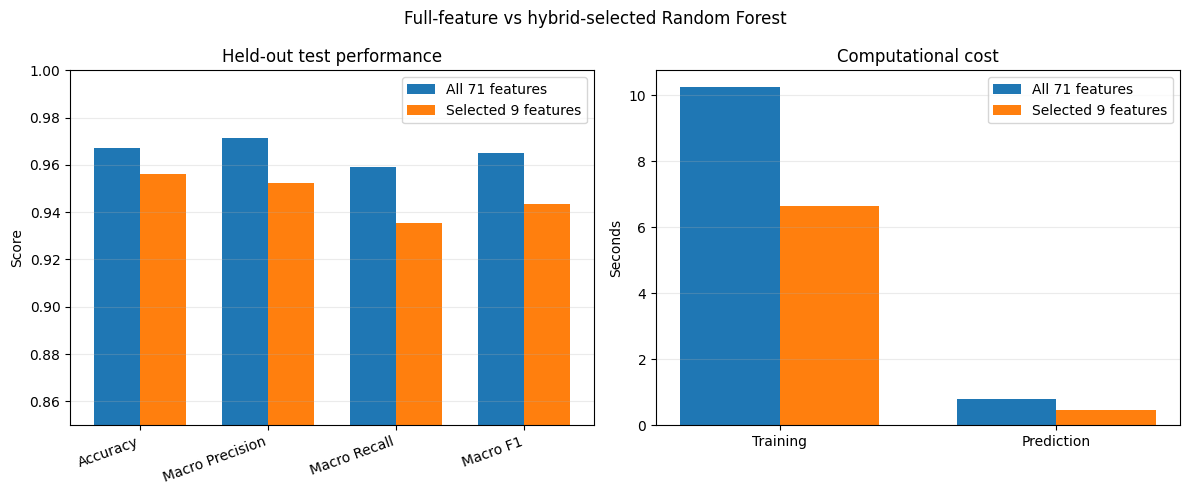


Saved comparison CSV: /kaggle/working/phase6_final_model_comparison.csv
Saved research figure: /kaggle/working/phase6_final_model_comparison.png


In [67]:
# ============================================================
# PHASE 6: HYBRID GLOBAL-LOCAL FEATURE SELECTION
# STEP 6.12: FINAL COMPARISON TABLE AND RESEARCH FIGURE
# PURPOSE: Save verified test results and visualize trade-offs
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Values copied from the verified, saved test-result CSVs.
comparison = pd.DataFrame([
    {
        "Model": "Random Forest — all 71 features",
        "Feature Count": 71,
        "Feature Reduction (%)": 0.0,
        "Accuracy": 0.967341,
        "Macro Precision": 0.971518,
        "Macro Recall": 0.958994,
        "Macro F1": 0.965146,
        "Macro One-vs-Rest FPR": 0.006685,
        "Training Time (s)": 10.241535,
        "Prediction Time (s)": 0.794374
    },
    {
        "Model": "Hybrid-selected Random Forest",
        "Feature Count": 9,
        "Feature Reduction (%)": 87.323944,
        "Accuracy": 0.956145,
        "Macro Precision": 0.952153,
        "Macro Recall": 0.935366,
        "Macro F1": 0.943576,
        "Macro One-vs-Rest FPR": 0.008513,
        "Training Time (s)": 6.631346,
        "Prediction Time (s)": 0.448215
    }
])

# Save the final comparison.
csv_path = "/kaggle/working/phase6_final_model_comparison.csv"
comparison.to_csv(csv_path, index=False)

# Calculate differences: selected model minus full-feature model.
full = comparison.iloc[0]
selected = comparison.iloc[1]

print("FINAL TEST-SET COMPARISON")
display(comparison.round(6))

print("\nKEY DIFFERENCES")
print(f"Feature reduction: {selected['Feature Reduction (%)']:.2f}%")
print(
    "Macro F1 change: "
    f"{(selected['Macro F1'] - full['Macro F1']) * 100:.2f} percentage points"
)
print(
    "Accuracy change: "
    f"{(selected['Accuracy'] - full['Accuracy']) * 100:.2f} percentage points"
)
print(
    "Training time change: "
    f"{(1 - selected['Training Time (s)'] / full['Training Time (s)']) * 100:.2f}% reduction"
)
print(
    "Prediction time change: "
    f"{(1 - selected['Prediction Time (s)'] / full['Prediction Time (s)']) * 100:.2f}% reduction"
)

# Research figure: test metrics and computational cost.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

metric_names = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
x = np.arange(len(metric_names))
width = 0.36

axes[0].bar(
    x - width / 2,
    [full[m] for m in metric_names],
    width,
    label="All 71 features"
)
axes[0].bar(
    x + width / 2,
    [selected[m] for m in metric_names],
    width,
    label="Selected 9 features"
)
axes[0].set_xticks(x)
axes[0].set_xticklabels(metric_names, rotation=20, ha="right")
axes[0].set_ylim(0.85, 1.0)
axes[0].set_ylabel("Score")
axes[0].set_title("Held-out test performance")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)

time_names = ["Training", "Prediction"]
full_times = [full["Training Time (s)"], full["Prediction Time (s)"]]
selected_times = [
    selected["Training Time (s)"],
    selected["Prediction Time (s)"]
]
x2 = np.arange(len(time_names))

axes[1].bar(
    x2 - width / 2, full_times, width, label="All 71 features"
)
axes[1].bar(
    x2 + width / 2, selected_times, width, label="Selected 9 features"
)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(time_names)
axes[1].set_ylabel("Seconds")
axes[1].set_title("Computational cost")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)

fig.suptitle("Full-feature vs hybrid-selected Random Forest")
fig.tight_layout()

figure_path = "/kaggle/working/phase6_final_model_comparison.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved comparison CSV:", csv_path)
print("Saved research figure:", figure_path)

,precision,recall,f1-score,support
benign,0.9616,0.9818,0.9716,56091.0000
bruteforce,0.9250,0.9056,0.9152,1049.0000
ddos,0.9677,0.9285,0.9477,10839.0000
dos,0.9707,0.9632,0.9669,11264.0000
malware,0.9336,0.9346,0.9341,4726.0000
mitm,0.9333,0.9153,0.9242,4910.0000
recon,0.9347,0.9127,0.9236,19239.0000
web,0.9905,0.9413,0.9653,1653.0000
accuracy,0.9561,0.9561,0.9561,0.9561
macro avg,0.9522,0.9354,0.9436,109771.0000


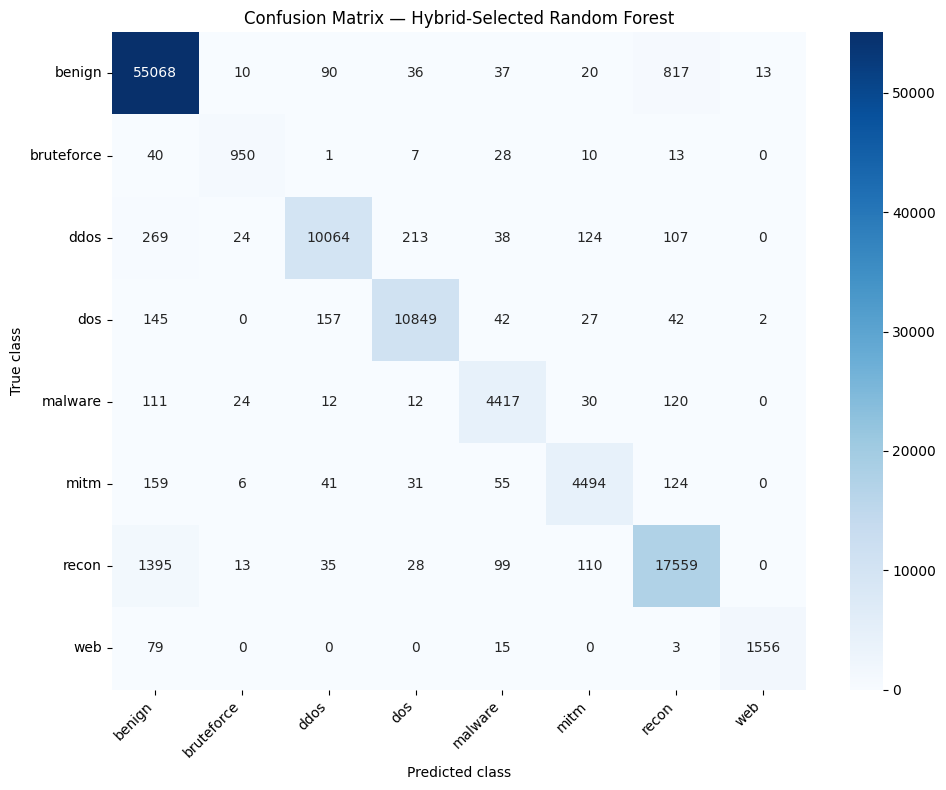

Saved classification report: /kaggle/working/phase7_per_class_report.csv
Saved confusion matrix: /kaggle/working/phase7_confusion_matrix.png


In [68]:
# ============================================================
# PHASE 7: DETAILED INTRUSION DETECTION EVALUATION
# STEP 7.1: CLASSIFICATION REPORT + CONFUSION MATRIX
# ============================================================

import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# The selected nine features found by hybrid optimization.
selected_features = [
    "network_interval-packets",
    "network_ip-flags_avg",
    "network_ips_all_count",
    "network_packets_all_count",
    "network_packets_dst_count",
    "network_time-delta_avg",
    "network_time-delta_min",
    "network_ttl_min",
    "network_window-size_std_deviation"
]

# Train with the same fit split and model settings.
final_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

final_rf.fit(X_fit[selected_features], y_fit)

# Predict on the held-out test set.
y_test_pred = final_rf.predict(X_test[selected_features])

# Detailed report for every class.
report_dict = classification_report(
    y_test,
    y_test_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()
display(report_df.round(4))

report_path = "/kaggle/working/phase7_per_class_report.csv"
report_df.to_csv(report_path, index=True)

# Confusion matrix.
class_labels = sorted(pd.Series(y_test).unique())

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=class_labels
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.title("Confusion Matrix — Hybrid-Selected Random Forest")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

cm_path = "/kaggle/working/phase7_confusion_matrix.png"
plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved classification report:", report_path)
print("Saved confusion matrix:", cm_path)

In [69]:
# ============================================================
# PHASE 7: DETAILED EVALUATION
# STEP 7.2: DISPLAY THE CONFUSION MATRIX VALUES
# ============================================================

import pandas as pd
from sklearn.metrics import confusion_matrix

class_labels = sorted(pd.Series(y_test).unique())

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=class_labels
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual: {label}" for label in class_labels],
    columns=[f"Predicted: {label}" for label in class_labels]
)

display(cm_df)

# Save the numerical matrix for later analysis.
cm_csv_path = "/kaggle/working/phase7_confusion_matrix_values.csv"
cm_df.to_csv(cm_csv_path)

print("Saved:", cm_csv_path)

,Predicted: benign,Predicted: bruteforce,Predicted: ddos,Predicted: dos,Predicted: malware,Predicted: mitm,Predicted: recon,Predicted: web
Actual: benign,55068,10,90,36,37,20,817,13
Actual: bruteforce,40,950,1,7,28,10,13,0
Actual: ddos,269,24,10064,213,38,124,107,0
Actual: dos,145,0,157,10849,42,27,42,2
Actual: malware,111,24,12,12,4417,30,120,0
Actual: mitm,159,6,41,31,55,4494,124,0
Actual: recon,1395,13,35,28,99,110,17559,0
Actual: web,79,0,0,0,15,0,3,1556


Saved: /kaggle/working/phase7_confusion_matrix_values.csv


,benign,bruteforce,ddos,dos,malware,mitm,recon,web
benign,98.18,0.02,0.16,0.06,0.07,0.04,1.46,0.02
bruteforce,3.81,90.56,0.10,0.67,2.67,0.95,1.24,0.00
ddos,2.48,0.22,92.85,1.97,0.35,1.14,0.99,0.00
dos,1.29,0.00,1.39,96.32,0.37,0.24,0.37,0.02
malware,2.35,0.51,0.25,0.25,93.46,0.63,2.54,0.00
mitm,3.24,0.12,0.84,0.63,1.12,91.53,2.53,0.00
recon,7.25,0.07,0.18,0.15,0.51,0.57,91.27,0.00
web,4.78,0.00,0.00,0.00,0.91,0.00,0.18,94.13


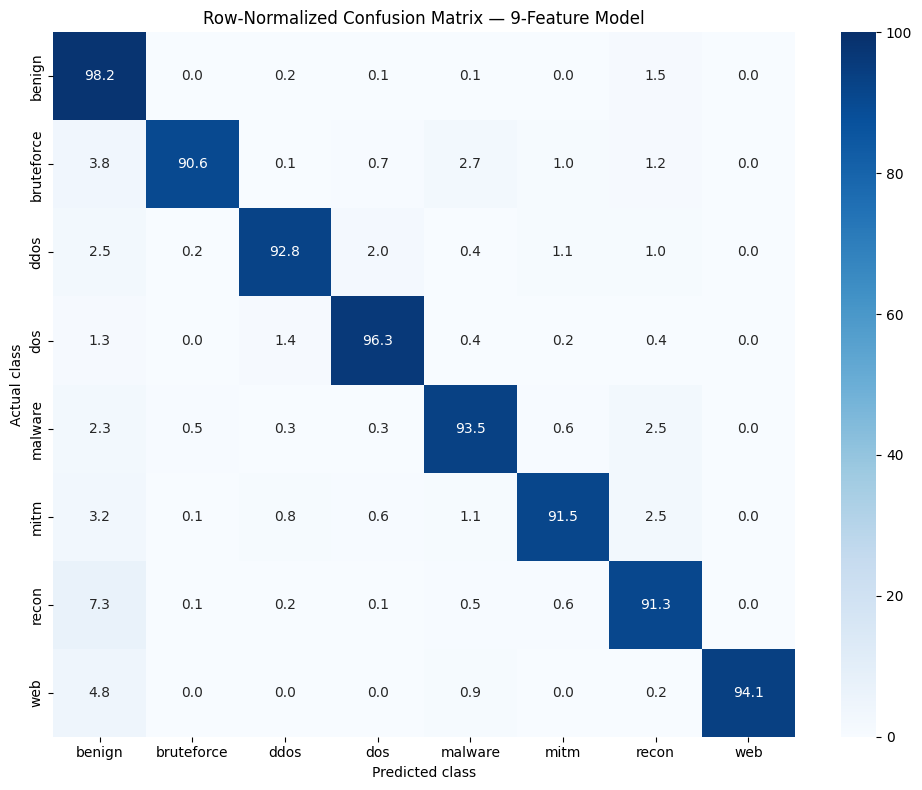

Saved figure: /kaggle/working/phase7_normalized_confusion_matrix.png


In [70]:
# ============================================================
# PHASE 7: DETAILED EVALUATION
# STEP 7.3: ROW-NORMALIZED CONFUSION MATRIX
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Normalize each row: each actual class totals 100%.
row_totals = cm.sum(axis=1, keepdims=True)
cm_normalized = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
) * 100

cm_normalized_df = pd.DataFrame(
    cm_normalized,
    index=class_labels,
    columns=class_labels
)

display(cm_normalized_df.round(2))

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_normalized_df,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100
)
plt.title("Row-Normalized Confusion Matrix — 9-Feature Model")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()

normalized_path = "/kaggle/working/phase7_normalized_confusion_matrix.png"
plt.savefig(normalized_path, dpi=300, bbox_inches="tight")
plt.show()

cm_normalized_df.to_csv(
    "/kaggle/working/phase7_normalized_confusion_matrix.csv"
)

print("Saved figure:", normalized_path)

,Model,Features,Feature Reduction (%),Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Macro FPR (%),Training Time (s),Prediction Time (s)
0,Random Forest (71 features),71,0.0000,96.7341,97.1518,95.8994,96.5146,0.6685,10.2415,0.7944
1,Hybrid-selected RF (9 features),9,87.3239,95.6145,95.2153,93.5366,94.3576,0.8513,6.6313,0.4482


Saved: /kaggle/working/phase8_consolidated_results.csv


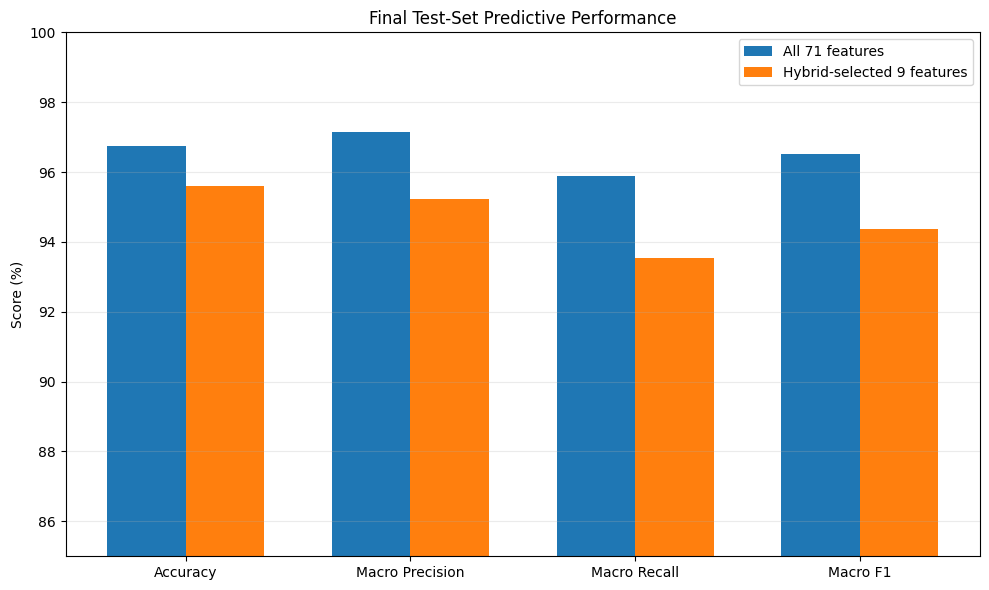

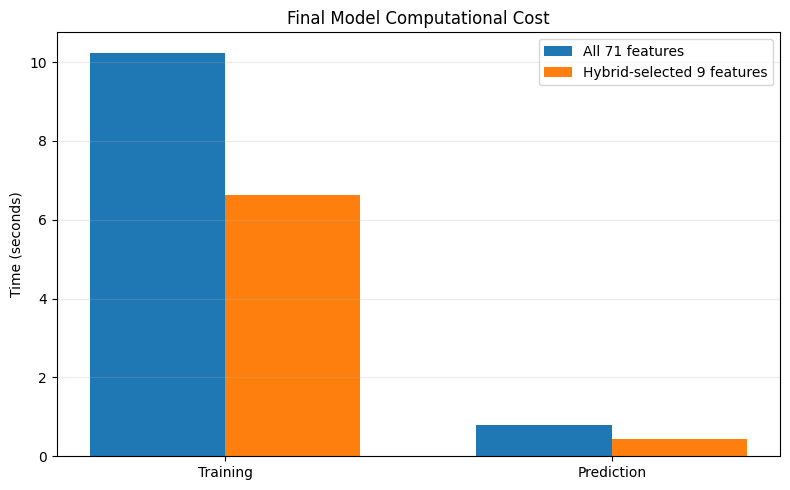

Saved: /kaggle/working/phase8_predictive_performance.png
Saved: /kaggle/working/phase8_computational_cost.png


In [71]:
# ============================================================
# PHASE 8: RESULTS AND DISCUSSION
# STEP 8.1: CONSOLIDATE FINAL TEST-SET RESULTS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

results = pd.DataFrame([
    {
        "Model": "Random Forest (71 features)",
        "Features": 71,
        "Feature Reduction (%)": 0.00,
        "Accuracy (%)": 96.7341,
        "Macro Precision (%)": 97.1518,
        "Macro Recall (%)": 95.8994,
        "Macro F1 (%)": 96.5146,
        "Macro FPR (%)": 0.6685,
        "Training Time (s)": 10.241535,
        "Prediction Time (s)": 0.794374
    },
    {
        "Model": "Hybrid-selected RF (9 features)",
        "Features": 9,
        "Feature Reduction (%)": 87.323944,
        "Accuracy (%)": 95.6145,
        "Macro Precision (%)": 95.2153,
        "Macro Recall (%)": 93.5366,
        "Macro F1 (%)": 94.3576,
        "Macro FPR (%)": 0.8513,
        "Training Time (s)": 6.631346,
        "Prediction Time (s)": 0.448215
    }
])

display(results.round(4))

results.to_csv(
    "/kaggle/working/phase8_consolidated_results.csv",
    index=False
)

print("Saved: /kaggle/working/phase8_consolidated_results.csv")

# Figure 1: predictive performance
metrics = [
    "Accuracy (%)",
    "Macro Precision (%)",
    "Macro Recall (%)",
    "Macro F1 (%)"
]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - width/2,
    results.loc[0, metrics].astype(float),
    width,
    label="All 71 features"
)
ax.bar(
    x + width/2,
    results.loc[1, metrics].astype(float),
    width,
    label="Hybrid-selected 9 features"
)

ax.set_ylabel("Score (%)")
ax.set_title("Final Test-Set Predictive Performance")
ax.set_xticks(x)
ax.set_xticklabels(
    ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
)
ax.legend()
ax.set_ylim(85, 100)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    "/kaggle/working/phase8_predictive_performance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Figure 2: computational cost
fig, ax = plt.subplots(figsize=(8, 5))

cost_metrics = ["Training Time (s)", "Prediction Time (s)"]
x = np.arange(len(cost_metrics))

ax.bar(
    x - width/2,
    results.loc[0, cost_metrics].astype(float),
    width,
    label="All 71 features"
)
ax.bar(
    x + width/2,
    results.loc[1, cost_metrics].astype(float),
    width,
    label="Hybrid-selected 9 features"
)

ax.set_ylabel("Time (seconds)")
ax.set_title("Final Model Computational Cost")
ax.set_xticks(x)
ax.set_xticklabels(["Training", "Prediction"])
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    "/kaggle/working/phase8_computational_cost.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved: /kaggle/working/phase8_predictive_performance.png")
print("Saved: /kaggle/working/phase8_computational_cost.png")

In [72]:
# ============================================================
# PHASE 9: ROBUSTNESS AND VALIDATION
# STEP 9.1: FIX FEATURE MISMATCH
# ============================================================

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Inspect the exact features used when fitting each model.
print("Features used by rf_top20:", len(rf_top20.feature_names_in_))
print("Features used by rf_dev:", len(rf_dev.feature_names_in_))
print("Features used by final_rf:", len(final_rf.feature_names_in_))

# Predict using the exact feature names and order each model expects.
pred_71 = rf_dev.predict(
    X_val[list(rf_dev.feature_names_in_)]
)

pred_20 = rf_top20.predict(
    X_val[list(rf_top20.feature_names_in_)]
)

pred_9 = final_rf.predict(
    X_val[list(final_rf.feature_names_in_)]
)

validation_predictions = {
    "Random Forest (71 features)": pred_71,
    "Random Forest (20 features)": pred_20,
    "Hybrid-selected RF (9 features)": pred_9
}

feature_counts = {
    "Random Forest (71 features)": 71,
    "Random Forest (20 features)": 20,
    "Hybrid-selected RF (9 features)": 9
}

rows = []

for model_name, predictions in validation_predictions.items():
    rows.append({
        "Model": model_name,
        "Feature Count": feature_counts[model_name],
        "Feature Reduction (%)": (
            1 - feature_counts[model_name] / 71
        ) * 100,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro Precision": precision_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, predictions, average="macro", zero_division=0
        )
    })

validation_comparison = pd.DataFrame(rows)

display(validation_comparison.round(4))

output_path = (
    "/kaggle/working/phase9_validation_feature_comparison.csv"
)
validation_comparison.to_csv(output_path, index=False)

print("Saved:", output_path)

Features used by rf_top20: 20
Features used by rf_dev: 71
Features used by final_rf: 9


,Model,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1
0,Random Forest (71 features),71,0.0000,0.9553,0.9747,0.9115,0.9410
1,Random Forest (20 features),20,71.8310,0.9538,0.9729,0.9065,0.9375
2,Hybrid-selected RF (9 features),9,87.3239,0.9489,0.9622,0.8947,0.9262


Saved: /kaggle/working/phase9_validation_feature_comparison.csv


In [73]:
# ============================================================
# PHASE 9: ROBUSTNESS AND VALIDATION
# STEP 9.2: CHECK AVAILABLE OPTIMIZATION OBJECTS
# ============================================================

objects_to_check = [
    "X_fit", "y_fit", "X_val", "y_val",
    "importance_df", "top20_features",
    "selected_features", "evaluate_candidate",
    "calculate_macro_fpr", "rng"
]

for name in objects_to_check:
    print(f"{name}: {'available' if name in globals() else 'not available'}")

X_fit: available
y_fit: available
X_val: available
y_val: available
importance_df: available
top20_features: available
selected_features: available
evaluate_candidate: available
calculate_macro_fpr: available
rng: available


In [74]:
# ============================================================
# PHASE 9: ROBUSTNESS AND VALIDATION
# STEP 9.2A: INSPECT THE EXISTING FITNESS FUNCTION
# ============================================================

import inspect

print(inspect.getsource(evaluate_candidate))

def evaluate_candidate(y_true, y_pred, feature_count):
    """Return metrics and a scalar minimization objective."""
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    macro_fpr = calculate_macro_fpr(y_true, y_pred)

    fitness = (
        WEIGHT_F1 * (1 - macro_f1)
        + WEIGHT_FEATURES * (feature_count / N_FEATURES)
        + WEIGHT_FPR * macro_fpr
    )

    return {
        "Feature Count": int(feature_count),
        "Feature Reduction (%)": 100 * (1 - feature_count / N_FEATURES),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": macro_f1,
        "Macro One-vs-Rest FPR": macro_fpr,
        "Fitness": fitness
    }



In [75]:
# ============================================================
# PHASE 9: ROBUSTNESS AND VALIDATION
# STEP 9.2B: INSPECT GA IMPLEMENTATION
# ============================================================

import inspect

# Check whether the original GA function is still available.
ga_functions = [
    name for name, obj in globals().copy().items()
    if callable(obj) and (
        "genetic" in name.lower()
        or name.lower() in ["run_ga", "run_genetic_algorithm"]
    )
]

print("Possible GA functions:", ga_functions)

# Inspect the variables controlling the fitness function.
for name in [
    "WEIGHT_F1", "WEIGHT_FEATURES", "WEIGHT_FPR",
    "N_FEATURES", "POPULATION_SIZE"
]:
    if name in globals():
        print(f"{name} =", globals()[name])

Possible GA functions: []
WEIGHT_F1 = 0.6
WEIGHT_FEATURES = 0.2
WEIGHT_FPR = 0.2
N_FEATURES = 71


In [76]:
# ============================================================
# PHASE 9: ROBUSTNESS AND VALIDATION
# STEP 9.2C: VALIDATE FEATURE SUBSETS
# ============================================================

print("Training features:", X_fit.shape[1])
print("Validation features:", X_val.shape[1])

print("\nTop-20 features available:", len(top20_features))
print("Selected features available:", len(selected_features))

print("\nTop-20 subset:")
print(top20_features)

print("\nSelected 9-feature subset:")
print(selected_features)

# Confirm every selected feature exists in both datasets.
assert set(top20_features).issubset(X_fit.columns)
assert set(top20_features).issubset(X_val.columns)
assert set(selected_features).issubset(X_fit.columns)
assert set(selected_features).issubset(X_val.columns)

print("\nAll feature subsets are valid.")

Training features: 71
Validation features: 71

Top-20 features available: 20
Selected features available: 9

Top-20 subset:
['network_time-delta_min', 'network_time-delta_avg', 'network_time-delta_std_deviation', 'network_interval-packets', 'network_window-size_std_deviation', 'network_packets_all_count', 'network_packets_dst_count', 'network_ttl_min', 'network_ip-flags_avg', 'network_ips_all_count', 'network_macs_src_count', 'network_window-size_min', 'network_ip-length_avg', 'network_ports_all_count', 'network_time-delta_max', 'network_tcp-flags_std_deviation', 'network_ports_src_count', 'network_ip-length_min', 'network_ttl_std_deviation', 'network_window-size_avg']

Selected 9-feature subset:
['network_interval-packets', 'network_ip-flags_avg', 'network_ips_all_count', 'network_packets_all_count', 'network_packets_dst_count', 'network_time-delta_avg', 'network_time-delta_min', 'network_ttl_min', 'network_window-size_std_deviation']

All feature subsets are valid.


In [77]:
# ============================================================
# PHASE 9: ROBUSTNESS AND VALIDATION
# STEP 9.3: SMALL REPRODUCIBLE GENETIC ALGORITHM
# ============================================================

import numpy as np
import pandas as pd
import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# Keep the original objective weights.
W_F1 = 0.6
W_FEATURES = 0.2
W_FPR = 0.2
N_FEATURES = X_fit.shape[1]

# Calculate macro one-vs-rest false-positive rate.
def macro_fpr_value(y_true, y_pred):
    labels = sorted(pd.Series(y_true).unique())
    rates = []

    for label in labels:
        actual_negative = np.asarray(y_true) != label
        predicted_positive = np.asarray(y_pred) == label

        fp = np.sum(actual_negative & predicted_positive)
        tn = np.sum(actual_negative & ~predicted_positive)
        rates.append(fp / (fp + tn) if fp + tn else 0.0)

    return float(np.mean(rates))

# Evaluate one feature mask on the validation split.
def evaluate_mask(mask, seed=42):
    selected = X_fit.columns[np.asarray(mask, dtype=bool)].tolist()

    if not selected:
        return None

    model = RandomForestClassifier(
        n_estimators=50,       # lightweight search model
        random_state=seed,
        class_weight="balanced",
        n_jobs=-1
    )

    start = time.time()
    model.fit(X_fit[selected], y_fit)
    train_time = time.time() - start

    pred = model.predict(X_val[selected])

    macro_f1 = f1_score(
        y_val, pred, average="macro", zero_division=0
    )
    macro_fpr = macro_fpr_value(y_val, pred)
    feature_count = len(selected)

    fitness = (
        W_F1 * (1 - macro_f1)
        + W_FEATURES * (feature_count / N_FEATURES)
        + W_FPR * macro_fpr
    )

    return {
        "Feature Count": feature_count,
        "Feature Reduction (%)": 100 * (1 - feature_count / N_FEATURES),
        "Accuracy": accuracy_score(y_val, pred),
        "Macro Precision": precision_score(
            y_val, pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_val, pred, average="macro", zero_division=0
        ),
        "Macro F1": macro_f1,
        "Macro FPR": macro_fpr,
        "Fitness": fitness,
        "Training Time (s)": train_time,
        "Selected Features": selected
    }

# Create an initial population using ranked and random subsets.
def run_small_ga(seed, population_size=6, generations=2):
    rng_local = np.random.default_rng(seed)
    columns = list(X_fit.columns)
    population = []

    # Seed with the known top-20 and selected 9-feature masks.
    for subset in [top20_features, selected_features]:
        population.append(np.array([c in subset for c in columns]))

    # Add random masks with 8–30 features.
    while len(population) < population_size:
        k = int(rng_local.integers(8, 31))
        chosen = rng_local.choice(len(columns), size=k, replace=False)
        mask = np.zeros(len(columns), dtype=bool)
        mask[chosen] = True
        population.append(mask)

    seen = set()
    results = []

    for generation in range(generations):
        scored = []

        for mask in population:
            key = tuple(mask.tolist())
            if key in seen:
                continue
            seen.add(key)

            metrics = evaluate_mask(mask, seed=seed)
            if metrics is not None:
                metrics["Seed"] = seed
                metrics["Generation"] = generation + 1
                scored.append((mask, metrics))
                results.append(metrics)

        if not scored:
            break

        # Keep the best half and create mutated offspring.
        scored.sort(key=lambda item: item[1]["Fitness"])
        survivors = [item[0] for item in scored[:max(2, population_size // 2)]]
        next_population = survivors.copy()

        while len(next_population) < population_size:
            parent = survivors[int(rng_local.integers(len(survivors)))].copy()
            flip_count = int(rng_local.integers(1, 4))
            flip_indices = rng_local.choice(
                len(parent), size=flip_count, replace=False
            )
            parent[flip_indices] = ~parent[flip_indices]

            # Ensure at least one feature remains.
            if not parent.any():
                parent[int(rng_local.integers(len(parent)))] = True

            next_population.append(parent)

        population = next_population

    return results

# Two independent seeds for a small repeatability check.
all_results = []

for seed in [101, 202]:
    print(f"Running lightweight GA with seed {seed}...")
    all_results.extend(run_small_ga(seed))

ga_repeatability_df = pd.DataFrame(all_results)
ga_repeatability_df = ga_repeatability_df.sort_values("Fitness")

# Keep the feature list for reproducibility, but show a compact table.
display(
    ga_repeatability_df[
        [
            "Seed", "Generation", "Feature Count",
            "Feature Reduction (%)", "Accuracy",
            "Macro F1", "Macro FPR", "Fitness",
            "Training Time (s)"
        ]
    ].round(4)
)

save_path = "/kaggle/working/phase9_ga_repeatability.csv"
ga_repeatability_df.to_csv(save_path, index=False)
print("Saved:", save_path)

Running lightweight GA with seed 101...
Running lightweight GA with seed 202...


,Seed,Generation,Feature Count,Feature Reduction (%),Accuracy,Macro F1,Macro FPR,Fitness,Training Time (s)
6,101,2,10,85.9155,0.9515,0.9333,0.0133,0.0709,3.1995
1,101,1,9,87.3239,0.9481,0.9245,0.0138,0.0734,3.2002
10,202,1,9,87.3239,0.9483,0.9243,0.0137,0.0735,3.2059
16,202,2,10,85.9155,0.9502,0.9267,0.0132,0.0748,2.8301
17,202,2,10,85.9155,0.9482,0.9241,0.0137,0.0764,2.8736
15,202,2,18,74.6479,0.9534,0.9377,0.0130,0.0907,3.6961
0,101,1,20,71.8310,0.9538,0.9379,0.0129,0.0962,3.7955
9,202,1,20,71.8310,0.9532,0.9373,0.0131,0.0966,3.9140
5,101,1,11,84.5070,0.9387,0.8828,0.0149,0.1043,2.3618
2,101,1,15,78.8732,0.9426,0.8985,0.0146,0.1061,2.3879


Saved: /kaggle/working/phase9_ga_repeatability.csv


In [78]:
# ============================================================
# PHASE 9: ROBUSTNESS AND VALIDATION
# STEP 9.4: FEATURE-SELECTION CONSISTENCY
# ============================================================

import pandas as pd
from itertools import combinations

# Load the GA experiment results already saved.
ga_results = pd.read_csv(
    "/kaggle/working/phase9_ga_repeatability.csv"
)

# Get the best candidate from each seed.
best_by_seed = (
    ga_results.sort_values("Fitness")
    .groupby("Seed", as_index=False)
    .first()
)

display(
    best_by_seed[
        ["Seed", "Generation", "Feature Count",
         "Feature Reduction (%)", "Macro F1", "Fitness"]
    ].round(4)
)

# Show selected features for each seed.
for _, row in best_by_seed.iterrows():
    print(f"\nSeed {int(row['Seed'])} — selected features:")
    print(row["Selected Features"])

# Compare the best candidate feature sets.
feature_sets = {
    int(row["Seed"]): set(eval(row["Selected Features"]))
    for _, row in best_by_seed.iterrows()
}

if len(feature_sets) >= 2:
    seeds = sorted(feature_sets)
    a, b = seeds[0], seeds[1]

    intersection = feature_sets[a] & feature_sets[b]
    union = feature_sets[a] | feature_sets[b]

    jaccard = len(intersection) / len(union) if union else 0.0

    print("\nCommon features:", sorted(intersection))
    print("Number of common features:", len(intersection))
    print("Jaccard similarity:", round(jaccard, 4))

    print("\nInterpretation:")
    print("Jaccard similarity ranges from 0 (no overlap) to 1 (identical sets).")

,Seed,Generation,Feature Count,Feature Reduction (%),Macro F1,Fitness
0,101,2,10,85.9155,0.9333,0.0709
1,202,1,9,87.3239,0.9243,0.0735



Seed 101 — selected features:
['network_interval-packets', 'network_ip-flags_avg', 'network_ips_all_count', 'network_packets_all_count', 'network_packets_dst_count', 'network_tcp-flags_avg', 'network_time-delta_avg', 'network_time-delta_min', 'network_window-size_min', 'network_window-size_std_deviation']

Seed 202 — selected features:
['network_interval-packets', 'network_ip-flags_avg', 'network_ips_all_count', 'network_packets_all_count', 'network_packets_dst_count', 'network_time-delta_avg', 'network_time-delta_min', 'network_ttl_min', 'network_window-size_std_deviation']

Common features: ['network_interval-packets', 'network_ip-flags_avg', 'network_ips_all_count', 'network_packets_all_count', 'network_packets_dst_count', 'network_time-delta_avg', 'network_time-delta_min', 'network_window-size_std_deviation']
Number of common features: 8
Jaccard similarity: 0.7273

Interpretation:
Jaccard similarity ranges from 0 (no overlap) to 1 (identical sets).


In [79]:
# ============================================================
# PHASE 9: ROBUSTNESS AND VALIDATION
# STEP 9.5: THREE ADDITIONAL RANDOM SEEDS
# ============================================================

additional_seeds = [303, 404, 505]
additional_results = []

for seed in additional_seeds:
    print(f"Running lightweight GA with seed {seed}...")
    seed_results = run_small_ga(
        seed=seed,
        population_size=6,
        generations=2
    )
    additional_results.extend(seed_results)

additional_df = pd.DataFrame(additional_results)

# Save the new results separately.
additional_path = "/kaggle/working/phase9_ga_additional_seeds.csv"
additional_df.to_csv(additional_path, index=False)

# Combine with the original two-seed results.
previous_df = pd.read_csv(
    "/kaggle/working/phase9_ga_repeatability.csv"
)

all_seed_results = pd.concat(
    [previous_df, additional_df],
    ignore_index=True
)

all_seed_path = "/kaggle/working/phase9_ga_all_five_seeds.csv"
all_seed_results.to_csv(all_seed_path, index=False)

# Report the best candidate found in each seed.
best_by_seed = (
    all_seed_results
    .sort_values("Fitness")
    .groupby("Seed", as_index=False)
    .first()
)

display(
    best_by_seed[
        [
            "Seed",
            "Generation",
            "Feature Count",
            "Feature Reduction (%)",
            "Macro F1",
            "Macro FPR",
            "Fitness"
        ]
    ].sort_values("Seed").round(4)
)

print("Saved additional results:", additional_path)
print("Saved combined results:", all_seed_path)

Running lightweight GA with seed 303...
Running lightweight GA with seed 404...
Running lightweight GA with seed 505...


,Seed,Generation,Feature Count,Feature Reduction (%),Macro F1,Macro FPR,Fitness
0,101,2,10,85.9155,0.9333,0.0133,0.0709
1,202,1,9,87.3239,0.9243,0.0137,0.0735
2,303,1,9,87.3239,0.9254,0.0137,0.0729
3,404,1,9,87.3239,0.9271,0.0136,0.0718
4,505,1,9,87.3239,0.9248,0.0137,0.0732


Saved additional results: /kaggle/working/phase9_ga_additional_seeds.csv
Saved combined results: /kaggle/working/phase9_ga_all_five_seeds.csv


In [80]:
# ============================================================
# PHASE 9: ROBUSTNESS AND VALIDATION
# STEP 9.6: FIVE-SEED SUMMARY STATISTICS
# ============================================================

import pandas as pd

all_seed_results = pd.read_csv(
    "/kaggle/working/phase9_ga_all_five_seeds.csv"
)

# Select the best candidate from each seed.
best_by_seed = (
    all_seed_results
    .sort_values("Fitness")
    .groupby("Seed", as_index=False)
    .first()
)

metrics = [
    "Feature Count",
    "Feature Reduction (%)",
    "Macro F1",
    "Macro FPR",
    "Fitness"
]

summary = best_by_seed[metrics].agg(["mean", "std"]).T
summary.columns = ["Mean", "Standard Deviation"]

display(summary.round(4))

summary.to_csv(
    "/kaggle/working/phase9_five_seed_summary.csv"
)

print("Saved: /kaggle/working/phase9_five_seed_summary.csv")

,Mean,Standard Deviation
Feature Count,9.2000,0.4472
Feature Reduction (%),87.0423,0.6299
Macro F1,0.9270,0.0037
Macro FPR,0.0136,0.0002
Fitness,0.0725,0.0011


Saved: /kaggle/working/phase9_five_seed_summary.csv


In [81]:
# ============================================================
# PHASE 10: FINALIZATION
# STEP 10.1: CHECK FINAL MODEL AND TARGET CLASSES
# ============================================================

print("Final model available:", "final_rf" in globals())
print("Selected feature count:", len(selected_features))
print("Selected features:", selected_features)

print("\nTarget classes in training data:")
print(sorted(pd.Series(y_fit).astype(str).unique()))

print("\nFinal test results file exists:")
import os
print(os.path.exists(
    "/kaggle/working/phase6_final_test_results.csv"
))

Final model available: True
Selected feature count: 9
Selected features: ['network_interval-packets', 'network_ip-flags_avg', 'network_ips_all_count', 'network_packets_all_count', 'network_packets_dst_count', 'network_time-delta_avg', 'network_time-delta_min', 'network_ttl_min', 'network_window-size_std_deviation']

Target classes in training data:
['benign', 'bruteforce', 'ddos', 'dos', 'malware', 'mitm', 'recon', 'web']

Final test results file exists:
True


In [82]:
# ============================================================
# PHASE 10: FINALIZATION
# STEP 10.2: SAVE MODEL, FEATURES, CLASSES, AND CONFIGURATION
# ============================================================

import os
import json
import joblib
import pandas as pd
from datetime import datetime, timezone

OUTPUT_DIR = "/kaggle/working/final_research_artifacts"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Save the already-fitted nine-feature model.
model_path = os.path.join(OUTPUT_DIR, "hybrid_selected_rf.joblib")
joblib.dump(final_rf, model_path)

# 2. Save the selected feature list in order.
features_path = os.path.join(OUTPUT_DIR, "selected_features.json")
with open(features_path, "w") as f:
    json.dump(selected_features, f, indent=2)

# 3. Save target classes.
target_classes = sorted(pd.Series(y_fit).astype(str).unique())
classes_path = os.path.join(OUTPUT_DIR, "target_classes.json")
with open(classes_path, "w") as f:
    json.dump(target_classes, f, indent=2)

# 4. Save model and experiment configuration.
metadata = {
    "project": (
        "Algorithmic Optimization for Intrusion Detection: "
        "Multi-Objective Feature Selection Using Hybrid "
        "Global-Local Optimization"
    ),
    "model": "RandomForestClassifier",
    "n_estimators": 100,
    "random_state": 42,
    "class_weight": "balanced",
    "selected_feature_count": len(selected_features),
    "original_feature_count": 71,
    "feature_reduction_percent": round(
        100 * (1 - len(selected_features) / 71), 4
    ),
    "target_column": "label2",
    "target_classes": target_classes,
    "fitness_weights": {
        "macro_f1": 0.6,
        "feature_count": 0.2,
        "macro_fpr": 0.2
    },
    "validation_split_seed": 42,
    "final_test_results_file": (
        "/kaggle/working/phase6_final_test_results.csv"
    ),
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "notes": [
        "Model is the existing fitted object; it was not retrained in this cell.",
        "The held-out test set was used for final evaluation.",
        "The lightweight five-seed GA experiment used 50 trees and is separate."
    ]
}

metadata_path = os.path.join(OUTPUT_DIR, "experiment_metadata.json")
with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

# 5. Copy final test results into the artifact directory.
test_results_path = "/kaggle/working/phase6_final_test_results.csv"
if os.path.exists(test_results_path):
    pd.read_csv(test_results_path).to_csv(
        os.path.join(OUTPUT_DIR, "final_test_results.csv"),
        index=False
    )

# 6. Save the five-seed robustness summary if available.
seed_summary_path = "/kaggle/working/phase9_five_seed_summary.csv"
if os.path.exists(seed_summary_path):
    pd.read_csv(seed_summary_path).to_csv(
        os.path.join(OUTPUT_DIR, "five_seed_summary.csv"),
        index=False
    )

print("Saved final artifacts:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

print("\nModel path:", model_path)
print("Metadata path:", metadata_path)

Saved final artifacts:
- experiment_metadata.json
- final_test_results.csv
- five_seed_summary.csv
- hybrid_selected_rf.joblib
- selected_features.json
- target_classes.json

Model path: /kaggle/working/final_research_artifacts/hybrid_selected_rf.joblib
Metadata path: /kaggle/working/final_research_artifacts/experiment_metadata.json


In [83]:
# ============================================================
# PHASE 10: FINALIZATION
# STEP 10.3: VERIFY SAVED MODEL
# ============================================================

import joblib
import json
import os

model_path = (
    "/kaggle/working/final_research_artifacts/"
    "hybrid_selected_rf.joblib"
)
features_path = (
    "/kaggle/working/final_research_artifacts/"
    "selected_features.json"
)

loaded_model = joblib.load(model_path)

with open(features_path, "r") as f:
    loaded_features = json.load(f)

assert len(loaded_features) == 9
assert list(loaded_model.feature_names_in_) == loaded_features

print("Model loaded successfully.")
print("Selected feature count:", len(loaded_features))
print("Feature order matches the saved model:", True)
print("Model class:", type(loaded_model).__name__)

Model loaded successfully.
Selected feature count: 9
Feature order matches the saved model: True
Model class: RandomForestClassifier


In [84]:
# ============================================================
# PHASE 10: FINALIZATION
# STEP 10.4: ZIP THE FINAL RESEARCH ARTIFACTS
# ============================================================

import shutil
import os

artifact_dir = "/kaggle/working/final_research_artifacts"
zip_base = "/kaggle/working/final_research_artifacts"

zip_path = shutil.make_archive(
    zip_base,
    "zip",
    root_dir=artifact_dir
)

print("ZIP created:", zip_path)
print("File size (MB):", round(os.path.getsize(zip_path) / (1024**2), 2))

ZIP created: /kaggle/working/final_research_artifacts.zip
File size (MB): 17.43


In [85]:

# ============================================================
# RESEARCH PAPER FIGURES
# CIC-IIoT-2025 Intrusion Detection
# Generates figures from available real experimental artifacts
# ============================================================

import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# -------------------- PATHS --------------------
OUT_DIR = "/kaggle/working/research_figures"
ARTIFACT_DIR = "/kaggle/working/final_research_artifacts"

DATASET_PATH = (
    "/kaggle/input/datasets/muhammadirfangull/"
    "cic-iiot-2025/combined_dataset.csv"
)

os.makedirs(OUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

def save_figure(filename):
    path = os.path.join(OUT_DIR, filename)
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.close()
    print("Saved:", path)

def find_csv(patterns):
    """Find a CSV in the artifact folder or Kaggle working directory."""
    for pattern in patterns:
        matches = glob.glob(
            os.path.join(ARTIFACT_DIR, pattern)
        ) + glob.glob(
            os.path.join("/kaggle/working", pattern)
        )
        matches = list(dict.fromkeys(matches))
        if matches:
            return matches[0]
    return None

def normalize_columns(df):
    df = df.copy()
    df.columns = [
        str(c).strip().lower().replace("_", " ").replace("-", " ")
        for c in df.columns
    ]
    return df

generated = []
skipped = []

def done(name):
    generated.append(name)

def skip(name, reason):
    skipped.append((name, reason))
    print("Skipped:", name, "-", reason)


# ============================================================
# FIGURE 1: DATASET CLASS DISTRIBUTION
# ============================================================

if os.path.exists(DATASET_PATH):
    print("Loading dataset for class distribution...")
    df = pd.read_csv(DATASET_PATH, low_memory=False)

    target_col = "label2" if "label2" in df.columns else None

    if target_col is None:
        possible = [
            c for c in df.columns
            if c.lower() in ["label", "class", "target", "attack_type"]
        ]
        target_col = possible[0] if possible else None

    if target_col:
        counts = df[target_col].astype(str).value_counts()

        fig, ax = plt.subplots(figsize=(9, 5))
        plot_data = counts.sort_values(ascending=True)
        bars = ax.barh(
            plot_data.index,
            plot_data.values,
            edgecolor="black",
            linewidth=0.4
        )
        ax.set_title("Class Distribution of CIC-IIoT-2025")
        ax.set_xlabel("Number of samples")
        ax.set_ylabel("Traffic class")

        for bar, value in zip(bars, plot_data.values):
            ax.text(
                value, bar.get_y() + bar.get_height()/2,
                f" {value:,}", va="center", fontsize=8
            )

        save_figure("fig01_class_distribution.png")
        done("Class distribution")
    else:
        skip("Class distribution", "Target column was not found.")
else:
    skip("Class distribution", "Dataset CSV not found at the configured path.")


# ============================================================
# FIGURE 2: CLASS PERCENTAGES
# ============================================================

if os.path.exists(DATASET_PATH) and target_col:
    percentages = (
        df[target_col].astype(str).value_counts(normalize=True) * 100
    ).sort_values()

    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.barh(
        percentages.index,
        percentages.values,
        edgecolor="black",
        linewidth=0.4
    )
    ax.set_title("Percentage Distribution of Traffic Classes")
    ax.set_xlabel("Samples (%)")
    ax.set_ylabel("Traffic class")

    for bar, value in zip(bars, percentages.values):
        ax.text(
            value, bar.get_y() + bar.get_height()/2,
            f" {value:.2f}%", va="center", fontsize=8
        )

    save_figure("fig02_class_percentages.png")
    done("Class percentages")
else:
    skip("Class percentages", "Dataset or target column unavailable.")


# ============================================================
# FIGURE 3: CORRELATION MATRIX
# Uses a bounded random sample to control memory and runtime.
# ============================================================

if os.path.exists(DATASET_PATH):
    target_col = (
        "label2" if "label2" in df.columns
        else target_col
    )

    numeric_df = df.select_dtypes(include=np.number)
    numeric_df = numeric_df.replace([np.inf, -np.inf], np.nan)
    numeric_df = numeric_df.dropna(axis=1, how="all")

    # Remove constant columns.
    numeric_df = numeric_df.loc[
        :, numeric_df.nunique(dropna=True) > 1
    ]

    # Use at most 15 numeric features for a readable figure.
    if numeric_df.shape[1] >= 2:
        sample = numeric_df.sample(
            n=min(20000, len(numeric_df)),
            random_state=42
        )
        selected_cols = sample.var().sort_values(
            ascending=False
        ).head(15).index

        corr = sample[selected_cols].corr()

        fig, ax = plt.subplots(figsize=(11, 9))
        sns.heatmap(
            corr,
            cmap="coolwarm",
            center=0,
            vmin=-1,
            vmax=1,
            square=True,
            linewidths=0.25,
            cbar_kws={"label": "Pearson correlation"},
            ax=ax
        )
        ax.set_title(
            "Correlation Matrix of Selected Numeric Features\n"
            "(20,000-row sample; up to 15 features)"
        )
        ax.tick_params(axis="x", labelrotation=90, labelsize=7)
        ax.tick_params(axis="y", labelrotation=0, labelsize=7)

        save_figure("fig03_correlation_matrix.png")
        done("Correlation matrix")
    else:
        skip("Correlation matrix", "Not enough varying numeric columns.")
else:
    skip("Correlation matrix", "Dataset CSV unavailable.")


# ============================================================
# FIGURE 4: RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

importance_path = find_csv([
    "rf_feature_importance.csv",
    "*feature*importance*.csv"
])

if importance_path:
    imp = pd.read_csv(importance_path)
    lower = {c.lower().strip(): c for c in imp.columns}

    feature_col = next(
        (lower[c] for c in lower
         if "feature" in c or "column" == c),
        None
    )
    importance_col = next(
        (lower[c] for c in lower
         if "importance" in c),
        None
    )

    if feature_col and importance_col:
        imp[importance_col] = pd.to_numeric(
            imp[importance_col], errors="coerce"
        )
        imp = imp.dropna(subset=[importance_col])
        top = imp.nlargest(20, importance_col).sort_values(
            importance_col
        )

        fig, ax = plt.subplots(figsize=(10, 7))
        ax.barh(
            top[feature_col].astype(str),
            top[importance_col],
            edgecolor="black",
            linewidth=0.35
        )
        ax.set_title("Top 20 Random Forest Feature Importances")
        ax.set_xlabel("Feature importance")
        ax.set_ylabel("Feature")

        save_figure("fig04_feature_importance.png")
        done("Feature importance")
    else:
        skip(
            "Feature importance",
            f"Unexpected columns in {importance_path}: {list(imp.columns)}"
        )
else:
    skip("Feature importance", "Importance CSV was not found.")


# ============================================================
# FIGURE 5: MODEL PERFORMANCE COMPARISON
# ============================================================

comparison_path = find_csv([
    "phase6_final_model_comparison.csv",
    "phase8_consolidated_results.csv",
    "phase6_final_test_results.csv",
    "phase5_feature_selection_comparison.csv"
])

if comparison_path:
    comp = pd.read_csv(comparison_path)
    comp_norm = normalize_columns(comp)

    # Identify metric columns flexibly.
    metric_map = {}
    for col in comp_norm.columns:
        if "accuracy" in col:
            metric_map["Accuracy"] = col
        elif "macro f1" in col or col == "f1":
            metric_map["Macro F1"] = col
        elif "macro precision" in col:
            metric_map["Macro Precision"] = col
        elif "macro recall" in col:
            metric_map["Macro Recall"] = col

    if len(metric_map) >= 2:
        # Try to identify a model/configuration column.
        model_col = next(
            (c for c in comp_norm.columns
             if "model" in c or "feature" in c or "configuration" in c),
            None
        )

        if model_col is None:
            comp_norm["configuration"] = [
                f"Run {i+1}" for i in range(len(comp_norm))
            ]
            model_col = "configuration"

        plot_df = comp_norm[[model_col] + list(metric_map.values())].copy()
        plot_df = plot_df.rename(
            columns={v: k for k, v in metric_map.items()}
        )

        for metric in metric_map:
            plot_df[metric] = pd.to_numeric(
                plot_df[metric], errors="coerce"
            )

        plot_df = plot_df.dropna(
            subset=list(metric_map.keys()), how="all"
        )

        if len(plot_df):
            ax = plot_df.set_index(model_col)[
                list(metric_map.keys())
            ].plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05),
                   edgecolor="black", linewidth=0.3)

            ax.set_title("Model Performance Comparison")
            ax.set_xlabel("Model / configuration")
            ax.set_ylabel("Score")
            ax.tick_params(axis="x", rotation=20)
            ax.legend(loc="lower right")

            save_figure("fig05_model_performance.png")
            done("Model performance")
        else:
            skip("Model performance", "No valid numeric metric rows.")
    else:
        skip(
            "Model performance",
            f"Could not identify enough metric columns: {list(comp.columns)}"
        )
else:
    skip("Model performance", "No comparison CSV was found.")


# ============================================================
# FIGURE 6: COMPUTATIONAL COST
# ============================================================

if comparison_path:
    comp = pd.read_csv(comparison_path)
    comp_norm = normalize_columns(comp)

    model_col = next(
        (c for c in comp_norm.columns
         if "model" in c or "feature" in c or "configuration" in c),
        None
    )
    train_col = next(
        (c for c in comp_norm.columns
         if "training time" in c or "train time" in c),
        None
    )
    pred_col = next(
        (c for c in comp_norm.columns
         if "prediction time" in c or "predict time" in c),
        None
    )

    if model_col and (train_col or pred_col):
        cost = comp_norm[[model_col] +
                         [c for c in [train_col, pred_col] if c]].copy()

        for c in [train_col, pred_col]:
            if c and c in cost:
                cost[c] = pd.to_numeric(cost[c], errors="coerce")

        cost = cost.set_index(model_col)
        cost.columns = [
            "Training time (s)" if "train" in c else "Prediction time (s)"
            for c in cost.columns
        ]

        ax = cost.plot(kind="bar", figsize=(10, 5),
                       edgecolor="black", linewidth=0.3)
        ax.set_title("Computational Cost Comparison")
        ax.set_xlabel("Model / configuration")
        ax.set_ylabel("Time (seconds)")
        ax.tick_params(axis="x", rotation=20)
        ax.legend()

        save_figure("fig06_computational_cost.png")
        done("Computational cost")
    else:
        skip("Computational cost", "Could not identify time columns.")
else:
    skip("Computational cost", "Comparison CSV unavailable.")


# ============================================================
# FIGURE 7: CONFUSION MATRIX
# Uses saved confusion-matrix values if available.
# ============================================================

cm_path = find_csv([
    "phase7_confusion_matrix_values.csv",
    "*confusion*matrix*values*.csv"
])

if cm_path:
    cm_df = pd.read_csv(cm_path, index_col=0)

    # Works when the CSV contains a square matrix of numeric values.
    cm = cm_df.apply(pd.to_numeric, errors="coerce")

    if (
        cm.shape[0] == cm.shape[1]
        and cm.notna().all().all()
    ):
        fig, ax = plt.subplots(figsize=(9, 7))
        sns.heatmap(
            cm,
            annot=True,
            fmt=".0f",
            cmap="Blues",
            linewidths=0.25,
            ax=ax
        )
        ax.set_title("Multiclass Confusion Matrix")
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("True class")
        ax.tick_params(axis="x", rotation=45)
        ax.tick_params(axis="y", rotation=0)

        save_figure("fig07_confusion_matrix.png")
        done("Confusion matrix")
    else:
        skip(
            "Confusion matrix",
            f"CSV format is not a square numeric matrix: {cm_path}"
        )
else:
    skip(
        "Confusion matrix",
        "Saved confusion-matrix values CSV was not found."
    )


# ============================================================
# FIGURE 8: NORMALIZED CONFUSION MATRIX IMAGE
# Copy the existing plot if it is already available.
# ============================================================

existing_norm = find_csv([])  # Placeholder; image lookup is done below.

norm_images = (
    glob.glob(os.path.join(ARTIFACT_DIR, "*normalized*confusion*.png"))
    + glob.glob("/kaggle/working/*normalized*confusion*.png")
)

if norm_images:
    print("Existing normalized confusion matrix:", norm_images[0])
    print("You can retain this existing PNG for the paper.")
else:
    skip(
        "Normalized confusion matrix",
        "No saved normalized confusion-matrix PNG was found."
    )


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 55)
print("FIGURE GENERATION SUMMARY")
print("=" * 55)

print("\nGenerated:")
for item in generated:
    print("  [OK]", item)

print("\nSkipped:")
for item, reason in skipped:
    print("  [SKIP]", item, "-", reason)

print("\nFigure folder:", OUT_DIR)
print("Files created:")
for path in sorted(glob.glob(os.path.join(OUT_DIR, "*.png"))):
    print(" ", os.path.basename(path),
          f"({os.path.getsize(path) / 1024:.1f} KB)")


Loading dataset for class distribution...
Saved: /kaggle/working/research_figures/fig01_class_distribution.png
Saved: /kaggle/working/research_figures/fig02_class_percentages.png
Saved: /kaggle/working/research_figures/fig03_correlation_matrix.png
Saved: /kaggle/working/research_figures/fig04_feature_importance.png
Saved: /kaggle/working/research_figures/fig05_model_performance.png
Saved: /kaggle/working/research_figures/fig06_computational_cost.png
Saved: /kaggle/working/research_figures/fig07_confusion_matrix.png
Existing normalized confusion matrix: /kaggle/working/phase7_normalized_confusion_matrix.png
You can retain this existing PNG for the paper.

FIGURE GENERATION SUMMARY

Generated:
  [OK] Class distribution
  [OK] Class percentages
  [OK] Correlation matrix
  [OK] Feature importance
  [OK] Model performance
  [OK] Computational cost
  [OK] Confusion matrix

Skipped:

Figure folder: /kaggle/working/research_figures
Files created:
  fig01_class_distribution.png (116.4 KB)
  fig

In [86]:
import os

print("Research figures folder exists:",
      os.path.exists("/kaggle/working/research_figures"))

print("\nPNG files in the folder:")
folder = "/kaggle/working/research_figures"

if os.path.exists(folder):
    for name in sorted(os.listdir(folder)):
        print(os.path.join(folder, name))

print("\nZIP exists:",
      os.path.exists("/kaggle/working/research_figures.zip"))

Research figures folder exists: True

PNG files in the folder:
/kaggle/working/research_figures/fig01_class_distribution.png
/kaggle/working/research_figures/fig02_class_percentages.png
/kaggle/working/research_figures/fig03_correlation_matrix.png
/kaggle/working/research_figures/fig04_feature_importance.png
/kaggle/working/research_figures/fig05_model_performance.png
/kaggle/working/research_figures/fig06_computational_cost.png
/kaggle/working/research_figures/fig07_confusion_matrix.png

ZIP exists: False


In [87]:
import shutil
import os

folder = "/kaggle/working/research_figures"
zip_path = shutil.make_archive(
    "/kaggle/working/research_figures",
    "zip",
    root_dir=folder
)

print("ZIP created:", zip_path)
print("Size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

ZIP created: /kaggle/working/research_figures.zip
Size: 1.11 MB


In [88]:
import os
import json

print("Working directory:", os.getcwd())

print("\nArtifact folder exists:",
      os.path.exists("/kaggle/working/final_research_artifacts"))

print("\nKey files:")
for name in [
    "phase6_best_local_candidate.json",
    "phase6_local_search_results.csv",
    "phase6_final_model_comparison.csv",
    "phase9_five_seed_summary.csv",
    "final_research_artifacts.zip",
]:
    path = "/kaggle/working/" + name
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'NOT FOUND'}")

Working directory: /kaggle/working

Artifact folder exists: True

Key files:
phase6_best_local_candidate.json: FOUND
phase6_local_search_results.csv: FOUND
phase6_final_model_comparison.csv: FOUND
phase9_five_seed_summary.csv: FOUND
final_research_artifacts.zip: FOUND


In [89]:
import os
import json
import pandas as pd

WORK = "/kaggle/working"

# 1. Restore the best saved feature subset
candidate_path = os.path.join(
    WORK, "phase6_best_local_candidate.json"
)

with open(candidate_path, "r") as f:
    best_candidate = json.load(f)

print("BEST SAVED LOCAL CANDIDATE")
print(json.dumps(best_candidate, indent=2))

# 2. Inspect the saved local-search results
search_path = os.path.join(
    WORK, "phase6_local_search_results.csv"
)

search_results = pd.read_csv(search_path)

print("\nLOCAL-SEARCH RESULTS")
print("Shape:", search_results.shape)
print("Columns:", search_results.columns.tolist())
display(search_results.head())

# 3. Inspect the saved final comparison
comparison_path = os.path.join(
    WORK, "phase6_final_model_comparison.csv"
)

comparison = pd.read_csv(comparison_path)

print("\nFINAL MODEL COMPARISON")
display(comparison)

BEST SAVED LOCAL CANDIDATE
{
  "Method": "Genetic Algorithm + sampled single-bit local search",
  "Feature Count": 11,
  "Feature Reduction (%)": 84.50704225352112,
  "Accuracy": 0.9499479076228512,
  "Macro Precision": 0.9621893354387079,
  "Macro Recall": 0.8978323755200186,
  "Macro F1": 0.9279895517738606,
  "Macro One-vs-Rest FPR": 0.013437491066963451,
  "Fitness": 0.07687968264203411,
  "Selected Features": [
    "log_data-ranges_min",
    "network_interval-packets",
    "network_ip-flags_avg",
    "network_ips_all_count",
    "network_packets_all_count",
    "network_packets_dst_count",
    "network_time-delta_avg",
    "network_time-delta_min",
    "network_time-delta_std_deviation",
    "network_ttl_min",
    "network_window-size_std_deviation"
  ]
}

LOCAL-SEARCH RESULTS
Shape: (10, 13)
Columns: ['Changed Feature', 'Change', 'Feature Count', 'Feature Reduction (%)', 'Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Macro One-vs-Rest FPR', 'Fitness', 'Training Time 

,Changed Feature,Change,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Fitness,Training Time (s),Prediction Time (s),Selected Features
0,log_data-ranges_min,Added,11,84.507042,0.949948,0.962189,0.897832,0.927990,0.013437,0.076880,6.363479,0.127877,"['log_data-ranges_min', 'network_interval-pack..."
1,log_data-types_count,Added,11,84.507042,0.949861,0.961587,0.897711,0.927616,0.013368,0.077090,6.390578,0.123870,"['log_data-types_count', 'network_interval-pac..."
2,log_data-ranges_avg,Added,11,84.507042,0.949948,0.962357,0.896894,0.927511,0.013431,0.077165,6.379573,0.125475,"['log_data-ranges_avg', 'network_interval-pack..."
3,log_messages_count,Added,11,84.507042,0.949948,0.960453,0.898040,0.927320,0.013391,0.077272,6.355733,0.114948,"['log_messages_count', 'network_interval-packe..."
4,log_interval-messages,Added,11,84.507042,0.949210,0.962046,0.895560,0.926641,0.013566,0.077714,6.367528,0.126240,"['log_interval-messages', 'network_interval-pa..."



FINAL MODEL COMPARISON


,Model,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Training Time (s),Prediction Time (s)
0,Random Forest — all 71 features,71,0.000000,0.967341,0.971518,0.958994,0.965146,0.006685,10.241535,0.794374
1,Hybrid-selected Random Forest,9,87.323944,0.956145,0.952153,0.935366,0.943576,0.008513,6.631346,0.448215


In [90]:
import pandas as pd

path = "/kaggle/working/phase6_local_search_results.csv"
results = pd.read_csv(path)

print("Total recorded evaluations:", len(results))
print("\nChanges by type:")
print(results["Change"].value_counts(dropna=False))

print("\nAll candidate evaluations:")
display(
    results[
        [
            "Changed Feature",
            "Change",
            "Feature Count",
            "Macro F1",
            "Macro One-vs-Rest FPR",
            "Fitness",
            "Training Time (s)",
        ]
    ].sort_values("Fitness", ascending=True)
)

Total recorded evaluations: 10

Changes by type:
Change
Added    10
Name: count, dtype: int64

All candidate evaluations:


,Changed Feature,Change,Feature Count,Macro F1,Macro One-vs-Rest FPR,Fitness,Training Time (s)
0,log_data-ranges_min,Added,11,0.927990,0.013437,0.076880,6.363479
1,log_data-types_count,Added,11,0.927616,0.013368,0.077090,6.390578
2,log_data-ranges_avg,Added,11,0.927511,0.013431,0.077165,6.379573
3,log_messages_count,Added,11,0.927320,0.013391,0.077272,6.355733
4,log_interval-messages,Added,11,0.926641,0.013566,0.077714,6.367528
5,log_data-ranges_max,Added,11,0.926492,0.013425,0.077776,6.533957
6,log_data-ranges_std_deviation,Added,11,0.926168,0.013588,0.078003,6.302920
7,network_fragmented-packets,Added,11,0.923596,0.013721,0.079572,6.523960
8,network_header-length_avg,Added,11,0.923304,0.013763,0.079756,6.397938
9,network_fragmentation-score,Added,11,0.921745,0.013869,0.080713,6.330555


In [91]:
import os
import json
import pandas as pd

WORK = "/kaggle/working"

# Recover the exact saved 11-feature candidate
with open(
    os.path.join(WORK, "phase6_best_local_candidate.json"),
    "r"
) as f:
    candidate = json.load(f)

selected_features = candidate["Selected Features"]

print("Saved candidate feature count:", len(selected_features))
print("Saved features:")
for feature in selected_features:
    print(" -", feature)

# Check whether the original split indices were saved
print("\nPossible saved split/index files:")
for root, dirs, files in os.walk(WORK):
    dirs[:] = [d for d in dirs if d not in {"__pycache__"}]
    for filename in files:
        lower = filename.lower()
        if any(term in lower for term in [
            "split", "index", "train_idx", "test_idx",
            "validation_idx", "val_idx"
        ]):
            print(os.path.join(root, filename))

Saved candidate feature count: 11
Saved features:
 - log_data-ranges_min
 - network_interval-packets
 - network_ip-flags_avg
 - network_ips_all_count
 - network_packets_all_count
 - network_packets_dst_count
 - network_time-delta_avg
 - network_time-delta_min
 - network_time-delta_std_deviation
 - network_ttl_min
 - network_window-size_std_deviation

Possible saved split/index files:


In [92]:
print("X exists:", "X" in globals())
print("y exists:", "y" in globals())
print("df_model exists:", "df_model" in globals())

X exists: True
y exists: True
df_model exists: True


In [93]:
# ============================================================
# RESTORE ORIGINAL GROUP-AWARE TRAIN/TEST SPLIT
# ============================================================

import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Confirm the expected target and feature count
assert "label2" in df_model.columns, "Target label2 is missing"

X = df_model.drop(columns=["label2"])
y = df_model["label2"]

assert X.shape[1] == 71, f"Expected 71 features, found {X.shape[1]}"

# Keep identical feature vectors in the same split
groups = pd.util.hash_pandas_object(X, index=False)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Verify the split
train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Training classes:", y_train.nunique())
print("Test classes:", y_test.nunique())
print("Overlapping feature groups:",
      len(train_groups & test_groups))

Training shape: (575900, 71)
Test shape: (109771, 71)
Training classes: 8
Test classes: 8
Overlapping feature groups: 0


In [94]:
import os
import pandas as pd

print("Validation variables:")
for name in ["X_fit", "X_val", "y_fit", "y_val"]:
    print(f"{name}: {name in globals()}")

print("\nSaved experiment files:")
for filename in [
    "phase5_feature_selection_comparison.csv",
    "phase6_best_local_candidate.json",
    "phase6_local_search_results.csv",
    "phase6_final_model_comparison.csv",
]:
    path = os.path.join("/kaggle/working", filename)
    print(f"{filename}: {'FOUND' if os.path.exists(path) else 'MISSING'}")

Validation variables:
X_fit: True
X_val: True
y_fit: True
y_val: True

Saved experiment files:
phase5_feature_selection_comparison.csv: FOUND
phase6_best_local_candidate.json: FOUND
phase6_local_search_results.csv: FOUND
phase6_final_model_comparison.csv: FOUND


In [95]:

import json
import os
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# Load the saved 11-feature candidate
candidate_path = "/kaggle/working/phase6_best_local_candidate.json"

with open(candidate_path, "r") as f:
    candidate = json.load(f)

selected_features = candidate["Selected Features"]

# Verify that every selected feature is available
missing_fit = [c for c in selected_features if c not in X_fit.columns]
missing_val = [c for c in selected_features if c not in X_val.columns]

assert not missing_fit, f"Missing from X_fit: {missing_fit}"
assert not missing_val, f"Missing from X_val: {missing_val}"
assert len(selected_features) == 11, "Expected 11 selected features"

# Macro one-vs-rest FPR
def macro_ovr_fpr(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=np.unique(y_true))
    total = cm.sum()
    fp = cm.sum(axis=0) - np.diag(cm)
    tn = total - cm.sum(axis=0) - cm.sum(axis=1) + np.diag(cm)
    fpr = np.divide(
        fp,
        fp + tn,
        out=np.zeros_like(fp, dtype=float),
        where=(fp + tn) != 0
    )
    return float(np.mean(fpr))

# Match the project's scalar fitness objective
def calculate_fitness(f1, fpr, k, total_features):
    return (
        0.6 * (1 - f1)
        + 0.2 * (k / total_features)
        + 0.2 * fpr
    )

total_features = X_fit.shape[1]
results = []

# Evaluate the original 11-feature subset and each single-feature removal
feature_sets = [("11-feature baseline", selected_features.copy())]

for feature in selected_features:
    reduced = [c for c in selected_features if c != feature]
    feature_sets.append((f"Removed: {feature}", reduced))

for description, features in feature_sets:
    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    start = time.time()
    model.fit(X_fit[features], y_fit)
    training_time = time.time() - start

    start = time.time()
    predictions = model.predict(X_val[features])
    prediction_time = time.time() - start

    f1 = f1_score(y_val, predictions, average="macro", zero_division=0)
    fpr = macro_ovr_fpr(y_val, predictions)
    k = len(features)

    results.append({
        "Candidate": description,
        "Feature Count": k,
        "Feature Reduction (%)": 100 * (1 - k / total_features),
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro Precision": precision_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1,
        "Macro One-vs-Rest FPR": fpr,
        "Fitness": calculate_fitness(f1, fpr, k, total_features),
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time,
        "Selected Features": json.dumps(features),
    })

results_df = pd.DataFrame(results).sort_values("Fitness").reset_index(drop=True)

output_path = "/kaggle/working/phase6_leave_one_out_results.csv"
results_df.to_csv(output_path, index=False)

print("Evaluations completed:", len(results_df))
print("Results saved to:", output_path)

display(
    results_df[
        [
            "Candidate",
            "Feature Count",
            "Macro F1",
            "Macro One-vs-Rest FPR",
            "Fitness",
            "Training Time (s)",
        ]
    ].round(6)
)


Evaluations completed: 12
Results saved to: /kaggle/working/phase6_leave_one_out_results.csv


,Candidate,Feature Count,Macro F1,Macro One-vs-Rest FPR,Fitness,Training Time (s)
0,Removed: network_time-delta_std_deviation,10,0.928853,0.013275,0.073512,5.810376
1,Removed: network_packets_all_count,10,0.927970,0.013341,0.074055,6.476243
2,Removed: network_packets_dst_count,10,0.926966,0.013535,0.074696,6.300270
3,Removed: network_interval-packets,10,0.926746,0.013519,0.074825,6.095850
4,Removed: network_time-delta_avg,10,0.926515,0.013358,0.074932,5.785948
5,Removed: log_data-ranges_min,10,0.924301,0.013710,0.076331,6.631910
6,Removed: network_time-delta_min,10,0.924598,0.014985,0.076407,6.943662
7,Removed: network_ttl_min,10,0.923423,0.013726,0.076860,7.067582
8,11-feature baseline,11,0.927990,0.013437,0.076880,6.409801
9,Removed: network_ip-flags_avg,10,0.923009,0.013786,0.077121,6.460765


In [96]:

import json
import pandas as pd

results_path = "/kaggle/working/phase6_leave_one_out_results.csv"
results = pd.read_csv(results_path)

# Recover the best candidate from the saved results
best_row = results.sort_values("Fitness", ascending=True).iloc[0]
best_features = json.loads(best_row["Selected Features"])

print("Best candidate:", best_row["Candidate"])
print("Feature count:", len(best_features))
print("Macro F1:", best_row["Macro F1"])
print("Macro FPR:", best_row["Macro One-vs-Rest FPR"])
print("Fitness:", best_row["Fitness"])

print("\nSelected features:")
for feature in best_features:
    print("-", feature)

# Save the best candidate separately
candidate = {
    "Method": "Leave-one-feature-out search",
    "Feature Count": len(best_features),
    "Selected Features": best_features,
    "Validation Macro F1": float(best_row["Macro F1"]),
    "Validation Macro FPR": float(
        best_row["Macro One-vs-Rest FPR"]
    ),
    "Validation Fitness": float(best_row["Fitness"]),
}

output_path = "/kaggle/working/phase6_best_leave_one_out_candidate.json"
with open(output_path, "w") as f:
    json.dump(candidate, f, indent=2)

print("\nSaved candidate to:", output_path)


Best candidate: Removed: network_time-delta_std_deviation
Feature count: 10
Macro F1: 0.9288530355253736
Macro FPR: 0.0132749493920865
Fitness: 0.0735121826477002

Selected features:
- log_data-ranges_min
- network_interval-packets
- network_ip-flags_avg
- network_ips_all_count
- network_packets_all_count
- network_packets_dst_count
- network_time-delta_avg
- network_time-delta_min
- network_ttl_min
- network_window-size_std_deviation

Saved candidate to: /kaggle/working/phase6_best_leave_one_out_candidate.json


In [97]:

import json
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# Load the best 10-feature candidate
candidate_path = "/kaggle/working/phase6_best_leave_one_out_candidate.json"

with open(candidate_path, "r") as f:
    candidate = json.load(f)

base_features = candidate["Selected Features"]

assert len(base_features) == 10, (
    f"Expected 10 features, found {len(base_features)}"
)

assert all(c in X_fit.columns for c in base_features)
assert all(c in X_val.columns for c in base_features)

def macro_ovr_fpr(y_true, y_pred):
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    total = cm.sum()

    fp = cm.sum(axis=0) - np.diag(cm)
    fn = cm.sum(axis=1) - np.diag(cm)
    tp = np.diag(cm)
    tn = total - tp - fp - fn

    denominators = fp + tn
    fpr = np.divide(
        fp,
        denominators,
        out=np.zeros_like(fp, dtype=float),
        where=denominators != 0,
    )
    return float(np.mean(fpr))

def fitness_score(f1, fpr, k, total_features):
    return (
        0.6 * (1 - f1)
        + 0.2 * (k / total_features)
        + 0.2 * fpr
    )

results = []

for removed_feature in base_features:
    features = [
        c for c in base_features if c != removed_feature
    ]

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1,
    )

    start = time.time()
    model.fit(X_fit[features], y_fit)
    training_time = time.time() - start

    start = time.time()
    predictions = model.predict(X_val[features])
    prediction_time = time.time() - start

    f1 = f1_score(
        y_val, predictions, average="macro", zero_division=0
    )
    fpr = macro_ovr_fpr(y_val, predictions)

    results.append({
        "Removed Feature": removed_feature,
        "Feature Count": len(features),
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro Precision": precision_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1,
        "Macro One-vs-Rest FPR": fpr,
        "Fitness": fitness_score(
            f1, fpr, len(features), X_fit.shape[1]
        ),
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time,
        "Selected Features": json.dumps(features),
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("Fitness")
    .reset_index(drop=True)
)

output_path = "/kaggle/working/phase6_round2_removal_results.csv"
results_df.to_csv(output_path, index=False)

print("Completed evaluations:", len(results_df))
print("Saved results:", output_path)

display(
    results_df[
        [
            "Removed Feature",
            "Feature Count",
            "Macro F1",
            "Macro One-vs-Rest FPR",
            "Fitness",
            "Training Time (s)",
        ]
    ].round(6)
)


Completed evaluations: 10
Saved results: /kaggle/working/phase6_round2_removal_results.csv


,Removed Feature,Feature Count,Macro F1,Macro One-vs-Rest FPR,Fitness,Training Time (s)
0,network_packets_all_count,9,0.928517,0.013341,0.070910,5.787082
1,network_interval-packets,9,0.927492,0.013446,0.071546,5.479289
2,network_packets_dst_count,9,0.926423,0.013446,0.072188,5.924296
3,log_data-ranges_min,9,0.926216,0.013587,0.072340,6.105644
4,network_ips_all_count,9,0.924924,0.013559,0.073109,6.389877
5,network_ttl_min,9,0.924349,0.013596,0.073462,6.533317
6,network_ip-flags_avg,9,0.923202,0.013694,0.074170,6.012260
7,network_time-delta_min,9,0.923048,0.014962,0.074516,6.281656
8,network_time-delta_avg,9,0.913371,0.014073,0.080144,5.103761
9,network_window-size_std_deviation,9,0.892707,0.014740,0.092676,5.868460


In [98]:

# ============================================================
# PHASE 6: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 6.8: SAVE AND VERIFY THE BEST 9-FEATURE CANDIDATE
# PURPOSE: Preserve the best candidate after round-2 removal
# ============================================================

import json
import os
import pandas as pd

results_path = "/kaggle/working/phase6_round2_removal_results.csv"
results_df = pd.read_csv(results_path)

# Select the candidate with the lowest fitness
best_row = results_df.sort_values(
    "Fitness", ascending=True
).iloc[0]

best_features = json.loads(best_row["Selected Features"])

candidate = {
    "Phase": 6,
    "Step": "6.8",
    "Method": "Iterative leave-one-feature-out search",
    "Feature Count": len(best_features),
    "Feature Reduction (%)": float(
        100 * (1 - len(best_features) / X_fit.shape[1])
    ),
    "Validation Accuracy": float(best_row["Accuracy"]),
    "Validation Macro Precision": float(best_row["Macro Precision"]),
    "Validation Macro Recall": float(best_row["Macro Recall"]),
    "Validation Macro F1": float(best_row["Macro F1"]),
    "Validation Macro FPR": float(
        best_row["Macro One-vs-Rest FPR"]
    ),
    "Validation Fitness": float(best_row["Fitness"]),
    "Removed Feature": best_row["Removed Feature"],
    "Selected Features": best_features,
}

output_path = (
    "/kaggle/working/phase6_best_iterative_candidate.json"
)

with open(output_path, "w") as f:
    json.dump(candidate, f, indent=2)

print("PHASE 6 - STEP 6.8: CANDIDATE SUMMARY")
print("=" * 48)
print("Feature count:", candidate["Feature Count"])
print("Removed feature:", candidate["Removed Feature"])
print("Macro F1:", round(candidate["Validation Macro F1"], 6))
print("Macro FPR:", round(candidate["Validation Macro FPR"], 6))
print("Fitness:", round(candidate["Validation Fitness"], 6))
print("Feature reduction:",
      round(candidate["Feature Reduction (%)"], 2), "%")

print("\nSelected features:")
for feature in best_features:
    print("-", feature)

print("\nSaved to:", output_path)


PHASE 6 - STEP 6.8: CANDIDATE SUMMARY
Feature count: 9
Removed feature: network_packets_all_count
Macro F1: 0.928517
Macro FPR: 0.013341
Fitness: 0.07091
Feature reduction: 87.32 %

Selected features:
- log_data-ranges_min
- network_interval-packets
- network_ip-flags_avg
- network_ips_all_count
- network_packets_dst_count
- network_time-delta_avg
- network_time-delta_min
- network_ttl_min
- network_window-size_std_deviation

Saved to: /kaggle/working/phase6_best_iterative_candidate.json


In [99]:

# ============================================================
# PHASE 6: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 6.9: FURTHER ITERATIVE FEATURE REDUCTION
# PURPOSE: Test whether removing one more feature improves fitness
# ============================================================

import json
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# ------------------------------------------------------------
# 1. Load the best 9-feature candidate from Step 6.8
# ------------------------------------------------------------
candidate_path = (
    "/kaggle/working/phase6_best_iterative_candidate.json"
)

with open(candidate_path, "r") as f:
    candidate = json.load(f)

base_features = candidate["Selected Features"]

assert len(base_features) == 9, (
    f"Expected 9 features, found {len(base_features)}"
)
assert all(c in X_fit.columns for c in base_features)
assert all(c in X_val.columns for c in base_features)

print("Starting feature count:", len(base_features))
print("Validation rows:", len(X_val))

# ------------------------------------------------------------
# 2. Define macro one-vs-rest false-positive rate
# ------------------------------------------------------------
def macro_ovr_fpr(y_true, y_pred):
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    total = cm.sum()

    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    tn = total - tp - fp - fn

    denominator = fp + tn
    fpr = np.divide(
        fp,
        denominator,
        out=np.zeros_like(fp, dtype=float),
        where=denominator != 0,
    )
    return float(np.mean(fpr))

# ------------------------------------------------------------
# 3. Use the same fitness function as previous search rounds
# ------------------------------------------------------------
def fitness_score(f1, fpr, feature_count, total_features):
    return (
        0.6 * (1 - f1)
        + 0.2 * (feature_count / total_features)
        + 0.2 * fpr
    )

total_features = X_fit.shape[1]
results = []

# ------------------------------------------------------------
# 4. Evaluate the current 9-feature baseline
# ------------------------------------------------------------
feature_sets = [
    ("9-feature baseline", None, base_features.copy())
]

# ------------------------------------------------------------
# 5. Evaluate removing each of the 9 features
# ------------------------------------------------------------
for removed_feature in base_features:
    reduced_features = [
        feature
        for feature in base_features
        if feature != removed_feature
    ]

    feature_sets.append((
        f"Removed: {removed_feature}",
        removed_feature,
        reduced_features,
    ))

# ------------------------------------------------------------
# 6. Train and evaluate each candidate on validation data
# ------------------------------------------------------------
for description, removed_feature, features in feature_sets:
    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1,
    )

    start = time.time()
    model.fit(X_fit[features], y_fit)
    training_time = time.time() - start

    start = time.time()
    predictions = model.predict(X_val[features])
    prediction_time = time.time() - start

    accuracy = accuracy_score(y_val, predictions)
    precision = precision_score(
        y_val, predictions, average="macro", zero_division=0
    )
    recall = recall_score(
        y_val, predictions, average="macro", zero_division=0
    )
    macro_f1 = f1_score(
        y_val, predictions, average="macro", zero_division=0
    )
    macro_fpr = macro_ovr_fpr(y_val, predictions)

    score = fitness_score(
        macro_f1, macro_fpr, len(features), total_features
    )

    results.append({
        "Candidate": description,
        "Removed Feature": removed_feature or "None",
        "Feature Count": len(features),
        "Feature Reduction (%)":
            100 * (1 - len(features) / total_features),
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Macro One-vs-Rest FPR": macro_fpr,
        "Fitness": score,
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time,
        "Selected Features": json.dumps(features),
    })

# ------------------------------------------------------------
# 7. Save and display results
# ------------------------------------------------------------
results_df = (
    pd.DataFrame(results)
    .sort_values("Fitness", ascending=True)
    .reset_index(drop=True)
)

output_path = (
    "/kaggle/working/phase6_step6_9_removal_results.csv"
)
results_df.to_csv(output_path, index=False)

print("\nPHASE 6 - STEP 6.9: RESULTS")
print("=" * 60)
print("Evaluations completed:", len(results_df))
print("Results saved to:", output_path)

display(
    results_df[
        [
            "Candidate",
            "Feature Count",
            "Macro F1",
            "Macro One-vs-Rest FPR",
            "Fitness",
            "Training Time (s)",
        ]
    ].round(6)
)


Starting feature count: 9
Validation rows: 23036

PHASE 6 - STEP 6.9: RESULTS
Evaluations completed: 10
Results saved to: /kaggle/working/phase6_step6_9_removal_results.csv


,Candidate,Feature Count,Macro F1,Macro One-vs-Rest FPR,Fitness,Training Time (s)
0,Removed: network_interval-packets,8,0.927247,0.013435,0.068874,4.265839
1,Removed: network_packets_dst_count,8,0.924975,0.013530,0.070256,4.499130
2,Removed: log_data-ranges_min,8,0.924525,0.013603,0.070541,4.641916
3,Removed: network_ips_all_count,8,0.923979,0.013640,0.070876,4.839762
4,9-feature baseline,9,0.928517,0.013341,0.070910,5.766218
5,Removed: network_ttl_min,8,0.921935,0.013834,0.072141,5.010129
6,Removed: network_time-delta_min,8,0.921534,0.015237,0.072662,4.891180
7,Removed: network_ip-flags_avg,8,0.920392,0.013808,0.073062,4.548486
8,Removed: network_time-delta_avg,8,0.910346,0.014170,0.079162,4.024508
9,Removed: network_window-size_std_deviation,8,0.893535,0.014845,0.089383,4.389111


In [100]:

# ============================================================
# PHASE 6: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 6.10: SAVE AND VERIFY THE BEST 8-FEATURE CANDIDATE
# PURPOSE: Preserve the best candidate from Step 6.9
# ============================================================

import json
import pandas as pd

results_path = (
    "/kaggle/working/phase6_step6_9_removal_results.csv"
)

results_df = pd.read_csv(results_path)

# Select the lowest-fitness candidate
best_row = results_df.sort_values(
    "Fitness", ascending=True
).iloc[0]

best_features = json.loads(best_row["Selected Features"])

candidate = {
    "Phase": 6,
    "Step": "6.10",
    "Method": "Iterative leave-one-feature-out search",
    "Feature Count": len(best_features),
    "Feature Reduction (%)": float(
        100 * (1 - len(best_features) / X_fit.shape[1])
    ),
    "Validation Accuracy": float(best_row["Accuracy"]),
    "Validation Macro Precision": float(best_row["Macro Precision"]),
    "Validation Macro Recall": float(best_row["Macro Recall"]),
    "Validation Macro F1": float(best_row["Macro F1"]),
    "Validation Macro FPR": float(
        best_row["Macro One-vs-Rest FPR"]
    ),
    "Validation Fitness": float(best_row["Fitness"]),
    "Removed Feature": best_row["Removed Feature"],
    "Selected Features": best_features,
}

output_path = (
    "/kaggle/working/phase6_best_iterative_candidate.json"
)

with open(output_path, "w") as f:
    json.dump(candidate, f, indent=2)

print("PHASE 6 - STEP 6.10: CANDIDATE SUMMARY")
print("=" * 50)
print("Feature count:", candidate["Feature Count"])
print("Removed feature:", candidate["Removed Feature"])
print("Macro F1:", round(candidate["Validation Macro F1"], 6))
print("Macro FPR:", round(candidate["Validation Macro FPR"], 6))
print("Fitness:", round(candidate["Validation Fitness"], 6))
print("Feature reduction:",
      round(candidate["Feature Reduction (%)"], 2), "%")

print("\nSelected features:")
for feature in best_features:
    print("-", feature)

print("\nSaved to:", output_path)


PHASE 6 - STEP 6.10: CANDIDATE SUMMARY
Feature count: 8
Removed feature: network_interval-packets
Macro F1: 0.927247
Macro FPR: 0.013435
Fitness: 0.068874
Feature reduction: 88.73 %

Selected features:
- log_data-ranges_min
- network_ip-flags_avg
- network_ips_all_count
- network_packets_dst_count
- network_time-delta_avg
- network_time-delta_min
- network_ttl_min
- network_window-size_std_deviation

Saved to: /kaggle/working/phase6_best_iterative_candidate.json


In [101]:

# ============================================================
# PHASE 6: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 6.11: FURTHER ITERATIVE FEATURE REDUCTION
# PURPOSE: Evaluate 7-feature candidates using validation data
# ============================================================

import json
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# ------------------------------------------------------------
# 1. Load the best 8-feature candidate
# ------------------------------------------------------------
candidate_path = (
    "/kaggle/working/phase6_best_iterative_candidate.json"
)

with open(candidate_path, "r") as f:
    candidate = json.load(f)

base_features = candidate["Selected Features"]

assert len(base_features) == 8, (
    f"Expected 8 features, found {len(base_features)}"
)
assert all(c in X_fit.columns for c in base_features)
assert all(c in X_val.columns for c in base_features)

print("Starting feature count:", len(base_features))
print("Validation rows:", len(X_val))

# ------------------------------------------------------------
# 2. Calculate macro one-vs-rest false-positive rate
# ------------------------------------------------------------
def macro_ovr_fpr(y_true, y_pred):
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    total = cm.sum()

    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    tn = total - tp - fp - fn

    denominator = fp + tn
    fpr = np.divide(
        fp,
        denominator,
        out=np.zeros_like(fp, dtype=float),
        where=denominator != 0,
    )
    return float(np.mean(fpr))

# ------------------------------------------------------------
# 3. Fitness objective used in previous search rounds
# ------------------------------------------------------------
def fitness_score(f1, fpr, feature_count, total_features):
    return (
        0.6 * (1 - f1)
        + 0.2 * (feature_count / total_features)
        + 0.2 * fpr
    )

total_features = X_fit.shape[1]
results = []

# ------------------------------------------------------------
# 4. Evaluate the 8-feature baseline and all 7-feature subsets
# ------------------------------------------------------------
feature_sets = [
    ("8-feature baseline", "None", base_features.copy())
]

for removed_feature in base_features:
    reduced_features = [
        feature for feature in base_features
        if feature != removed_feature
    ]
    feature_sets.append((
        f"Removed: {removed_feature}",
        removed_feature,
        reduced_features,
    ))

# ------------------------------------------------------------
# 5. Train and evaluate on validation data only
# ------------------------------------------------------------
for description, removed_feature, features in feature_sets:
    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1,
    )

    start = time.time()
    model.fit(X_fit[features], y_fit)
    training_time = time.time() - start

    start = time.time()
    predictions = model.predict(X_val[features])
    prediction_time = time.time() - start

    accuracy = accuracy_score(y_val, predictions)
    precision = precision_score(
        y_val, predictions, average="macro", zero_division=0
    )
    recall = recall_score(
        y_val, predictions, average="macro", zero_division=0
    )
    macro_f1 = f1_score(
        y_val, predictions, average="macro", zero_division=0
    )
    macro_fpr = macro_ovr_fpr(y_val, predictions)

    fitness = fitness_score(
        macro_f1, macro_fpr, len(features), total_features
    )

    results.append({
        "Candidate": description,
        "Removed Feature": removed_feature,
        "Feature Count": len(features),
        "Feature Reduction (%)":
            100 * (1 - len(features) / total_features),
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Macro One-vs-Rest FPR": macro_fpr,
        "Fitness": fitness,
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time,
        "Selected Features": json.dumps(features),
    })

# ------------------------------------------------------------
# 6. Save and display results
# ------------------------------------------------------------
results_df = (
    pd.DataFrame(results)
    .sort_values("Fitness", ascending=True)
    .reset_index(drop=True)
)

output_path = (
    "/kaggle/working/phase6_step6_11_removal_results.csv"
)
results_df.to_csv(output_path, index=False)

print("\nPHASE 6 - STEP 6.11: RESULTS")
print("=" * 60)
print("Evaluations completed:", len(results_df))
print("Results saved to:", output_path)

display(
    results_df[
        [
            "Candidate",
            "Feature Count",
            "Macro F1",
            "Macro One-vs-Rest FPR",
            "Fitness",
            "Training Time (s)",
        ]
    ].round(6)
)


Starting feature count: 8
Validation rows: 23036

PHASE 6 - STEP 6.11: RESULTS
Evaluations completed: 9
Results saved to: /kaggle/working/phase6_step6_11_removal_results.csv


,Candidate,Feature Count,Macro F1,Macro One-vs-Rest FPR,Fitness,Training Time (s)
0,Removed: log_data-ranges_min,7,0.924403,0.013725,0.067821,4.432768
1,8-feature baseline,8,0.927247,0.013435,0.068874,4.257618
2,Removed: network_packets_dst_count,7,0.921263,0.013727,0.069706,4.066696
3,Removed: network_ip-flags_avg,7,0.919783,0.013873,0.070623,4.408468
4,Removed: network_ips_all_count,7,0.919661,0.013837,0.070689,4.459901
5,Removed: network_ttl_min,7,0.919518,0.013941,0.070795,4.544265
6,Removed: network_time-delta_min,7,0.917994,0.015795,0.072081,4.514045
7,Removed: network_time-delta_avg,7,0.894528,0.014746,0.085950,3.587909
8,Removed: network_window-size_std_deviation,7,0.885248,0.015220,0.091613,4.181852


In [102]:

# ============================================================
# PHASE 6: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 6.12: SAVE THE BEST 7-FEATURE CANDIDATE
# PURPOSE: Preserve the lowest-fitness result from Step 6.11
# ============================================================

import json
import pandas as pd

results_path = (
    "/kaggle/working/phase6_step6_11_removal_results.csv"
)

results_df = pd.read_csv(results_path)
best_row = results_df.sort_values(
    "Fitness", ascending=True
).iloc[0]

best_features = json.loads(best_row["Selected Features"])

candidate = {
    "Phase": 6,
    "Step": "6.12",
    "Method": "Iterative leave-one-feature-out search",
    "Feature Count": len(best_features),
    "Feature Reduction (%)": float(
        100 * (1 - len(best_features) / X_fit.shape[1])
    ),
    "Validation Accuracy": float(best_row["Accuracy"]),
    "Validation Macro Precision": float(best_row["Macro Precision"]),
    "Validation Macro Recall": float(best_row["Macro Recall"]),
    "Validation Macro F1": float(best_row["Macro F1"]),
    "Validation Macro FPR": float(
        best_row["Macro One-vs-Rest FPR"]
    ),
    "Validation Fitness": float(best_row["Fitness"]),
    "Removed Feature": best_row["Removed Feature"],
    "Selected Features": best_features,
}

output_path = (
    "/kaggle/working/phase6_best_iterative_candidate.json"
)

with open(output_path, "w") as f:
    json.dump(candidate, f, indent=2)

print("PHASE 6 - STEP 6.12: SAVED CANDIDATE")
print("=" * 50)
print("Feature count:", candidate["Feature Count"])
print("Removed feature:", candidate["Removed Feature"])
print("Macro F1:", round(candidate["Validation Macro F1"], 6))
print("Macro FPR:", round(candidate["Validation Macro FPR"], 6))
print("Fitness:", round(candidate["Validation Fitness"], 6))
print("Feature reduction:",
      round(candidate["Feature Reduction (%)"], 2), "%")

print("\nSelected features:")
for feature in best_features:
    print("-", feature)

print("\nSaved to:", output_path)


PHASE 6 - STEP 6.12: SAVED CANDIDATE
Feature count: 7
Removed feature: log_data-ranges_min
Macro F1: 0.924403
Macro FPR: 0.013725
Fitness: 0.067821
Feature reduction: 90.14 %

Selected features:
- network_ip-flags_avg
- network_ips_all_count
- network_packets_dst_count
- network_time-delta_avg
- network_time-delta_min
- network_ttl_min
- network_window-size_std_deviation

Saved to: /kaggle/working/phase6_best_iterative_candidate.json


In [103]:

# ============================================================
# PHASE 6: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 6.13: ITERATIVE REDUCTION FROM 7 TO 6 FEATURES
# PURPOSE: Find whether a 6-feature subset improves fitness
# ============================================================

import json
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# ------------------------------------------------------------
# 1. Load and verify the best 7-feature candidate
# ------------------------------------------------------------
candidate_path = (
    "/kaggle/working/phase6_best_iterative_candidate.json"
)

with open(candidate_path, "r") as f:
    candidate = json.load(f)

base_features = candidate["Selected Features"]

assert len(base_features) == 7, (
    f"Expected 7 features, found {len(base_features)}"
)
assert all(feature in X_fit.columns for feature in base_features)
assert all(feature in X_val.columns for feature in base_features)

print("Starting feature count:", len(base_features))
print("Validation rows:", len(X_val))

# ------------------------------------------------------------
# 2. Macro one-vs-rest false-positive rate
# ------------------------------------------------------------
def macro_ovr_fpr(y_true, y_pred):
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    total = cm.sum()
    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    tn = total - tp - fp - fn

    denominator = fp + tn
    fpr = np.divide(
        fp,
        denominator,
        out=np.zeros_like(fp, dtype=float),
        where=denominator != 0,
    )

    return float(np.mean(fpr))

# ------------------------------------------------------------
# 3. Multi-objective fitness
# ------------------------------------------------------------
def fitness_score(f1, fpr, feature_count, total_features):
    return (
        0.6 * (1 - f1)
        + 0.2 * (feature_count / total_features)
        + 0.2 * fpr
    )

total_features = X_fit.shape[1]
results = []

# Baseline plus one candidate for each removed feature
feature_sets = [
    ("7-feature baseline", "None", base_features.copy())
]

for removed_feature in base_features:
    reduced_features = [
        feature for feature in base_features
        if feature != removed_feature
    ]

    feature_sets.append((
        f"Removed: {removed_feature}",
        removed_feature,
        reduced_features,
    ))

# ------------------------------------------------------------
# 4. Evaluate candidates using validation data
# ------------------------------------------------------------
for description, removed_feature, features in feature_sets:
    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1,
    )

    start = time.time()
    model.fit(X_fit[features], y_fit)
    training_time = time.time() - start

    start = time.time()
    predictions = model.predict(X_val[features])
    prediction_time = time.time() - start

    accuracy = accuracy_score(y_val, predictions)

    precision = precision_score(
        y_val, predictions,
        average="macro",
        zero_division=0,
    )

    recall = recall_score(
        y_val, predictions,
        average="macro",
        zero_division=0,
    )

    macro_f1 = f1_score(
        y_val, predictions,
        average="macro",
        zero_division=0,
    )

    macro_fpr = macro_ovr_fpr(y_val, predictions)

    fitness = fitness_score(
        macro_f1,
        macro_fpr,
        len(features),
        total_features,
    )

    results.append({
        "Candidate": description,
        "Removed Feature": removed_feature,
        "Feature Count": len(features),
        "Feature Reduction (%)":
            100 * (1 - len(features) / total_features),
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Macro One-vs-Rest FPR": macro_fpr,
        "Fitness": fitness,
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time,
        "Selected Features": json.dumps(features),
    })

# ------------------------------------------------------------
# 5. Save and display the results
# ------------------------------------------------------------
results_df = (
    pd.DataFrame(results)
    .sort_values("Fitness", ascending=True)
    .reset_index(drop=True)
)

output_path = (
    "/kaggle/working/phase6_step6_13_removal_results.csv"
)

results_df.to_csv(output_path, index=False)

print("\nPHASE 6 - STEP 6.13: RESULTS")
print("=" * 60)
print("Evaluations completed:", len(results_df))
print("Results saved to:", output_path)

display(
    results_df[
        [
            "Candidate",
            "Feature Count",
            "Macro F1",
            "Macro One-vs-Rest FPR",
            "Fitness",
            "Training Time (s)",
        ]
    ].round(6)
)


Starting feature count: 7
Validation rows: 23036

PHASE 6 - STEP 6.13: RESULTS
Evaluations completed: 8
Results saved to: /kaggle/working/phase6_step6_13_removal_results.csv


,Candidate,Feature Count,Macro F1,Macro One-vs-Rest FPR,Fitness,Training Time (s)
0,Removed: network_packets_dst_count,6,0.919973,0.013961,0.067710,4.299360
1,7-feature baseline,7,0.924403,0.013725,0.067821,4.410256
2,Removed: network_ttl_min,6,0.917273,0.014228,0.069383,4.815643
3,Removed: network_ips_all_count,6,0.916429,0.014150,0.069874,4.659897
4,Removed: network_ip-flags_avg,6,0.913998,0.014306,0.071364,4.576082
5,Removed: network_time-delta_min,6,0.912997,0.016212,0.072345,4.824006
6,Removed: network_time-delta_avg,6,0.891207,0.015005,0.085178,3.762872
7,Removed: network_window-size_std_deviation,6,0.878693,0.015712,0.092828,4.328304


In [104]:

# ============================================================
# PHASE 6: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 6.14: SAVE THE BEST 6-FEATURE CANDIDATE
# PURPOSE: Preserve the lowest-fitness result from Step 6.13
# ============================================================

import json
import pandas as pd

results_path = (
    "/kaggle/working/phase6_step6_13_removal_results.csv"
)

results_df = pd.read_csv(results_path)

best_row = results_df.sort_values(
    "Fitness", ascending=True
).iloc[0]

best_features = json.loads(best_row["Selected Features"])

candidate = {
    "Phase": 6,
    "Step": "6.14",
    "Method": "Iterative leave-one-feature-out search",
    "Feature Count": len(best_features),
    "Feature Reduction (%)": float(
        100 * (1 - len(best_features) / X_fit.shape[1])
    ),
    "Validation Accuracy": float(best_row["Accuracy"]),
    "Validation Macro Precision": float(
        best_row["Macro Precision"]
    ),
    "Validation Macro Recall": float(
        best_row["Macro Recall"]
    ),
    "Validation Macro F1": float(best_row["Macro F1"]),
    "Validation Macro FPR": float(
        best_row["Macro One-vs-Rest FPR"]
    ),
    "Validation Fitness": float(best_row["Fitness"]),
    "Removed Feature": best_row["Removed Feature"],
    "Selected Features": best_features,
}

output_path = (
    "/kaggle/working/phase6_best_iterative_candidate.json"
)

with open(output_path, "w") as f:
    json.dump(candidate, f, indent=2)

print("PHASE 6 - STEP 6.14: SAVED CANDIDATE")
print("=" * 50)
print("Feature count:", candidate["Feature Count"])
print("Removed feature:", candidate["Removed Feature"])
print("Macro F1:", round(candidate["Validation Macro F1"], 6))
print("Macro FPR:", round(candidate["Validation Macro FPR"], 6))
print("Fitness:", round(candidate["Validation Fitness"], 6))
print(
    "Feature reduction:",
    round(candidate["Feature Reduction (%)"], 2),
    "%"
)

print("\nSelected features:")
for feature in best_features:
    print("-", feature)

print("\nSaved to:", output_path)


PHASE 6 - STEP 6.14: SAVED CANDIDATE
Feature count: 6
Removed feature: network_packets_dst_count
Macro F1: 0.919973
Macro FPR: 0.013961
Fitness: 0.06771
Feature reduction: 91.55 %

Selected features:
- network_ip-flags_avg
- network_ips_all_count
- network_time-delta_avg
- network_time-delta_min
- network_ttl_min
- network_window-size_std_deviation

Saved to: /kaggle/working/phase6_best_iterative_candidate.json


In [105]:

# ============================================================
# PHASE 6: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 6.15: ITERATIVE REDUCTION FROM 6 TO 5 FEATURES
# PURPOSE: Evaluate whether a smaller subset improves fitness
# ============================================================

import json
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# ------------------------------------------------------------
# 1. Load and verify the best 6-feature candidate
# ------------------------------------------------------------
candidate_path = (
    "/kaggle/working/phase6_best_iterative_candidate.json"
)

with open(candidate_path, "r") as f:
    candidate = json.load(f)

base_features = candidate["Selected Features"]

assert len(base_features) == 6, (
    f"Expected 6 features, found {len(base_features)}"
)
assert all(feature in X_fit.columns for feature in base_features)
assert all(feature in X_val.columns for feature in base_features)

print("Starting feature count:", len(base_features))
print("Validation rows:", len(X_val))

# ------------------------------------------------------------
# 2. Macro one-vs-rest false-positive rate
# ------------------------------------------------------------
def macro_ovr_fpr(y_true, y_pred):
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    total = cm.sum()
    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    tn = total - tp - fp - fn

    denominator = fp + tn
    fpr = np.divide(
        fp,
        denominator,
        out=np.zeros_like(fp, dtype=float),
        where=denominator != 0,
    )

    return float(np.mean(fpr))

# ------------------------------------------------------------
# 3. Fitness objective
# ------------------------------------------------------------
def fitness_score(f1, fpr, feature_count, total_features):
    return (
        0.6 * (1 - f1)
        + 0.2 * (feature_count / total_features)
        + 0.2 * fpr
    )

total_features = X_fit.shape[1]
results = []

# Baseline plus one candidate for each removed feature
feature_sets = [
    ("6-feature baseline", "None", base_features.copy())
]

for removed_feature in base_features:
    reduced_features = [
        feature for feature in base_features
        if feature != removed_feature
    ]

    feature_sets.append((
        f"Removed: {removed_feature}",
        removed_feature,
        reduced_features,
    ))

# ------------------------------------------------------------
# 4. Train and evaluate using validation data only
# ------------------------------------------------------------
for description, removed_feature, features in feature_sets:
    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1,
    )

    start = time.time()
    model.fit(X_fit[features], y_fit)
    training_time = time.time() - start

    start = time.time()
    predictions = model.predict(X_val[features])
    prediction_time = time.time() - start

    accuracy = accuracy_score(y_val, predictions)

    precision = precision_score(
        y_val, predictions,
        average="macro",
        zero_division=0,
    )

    recall = recall_score(
        y_val, predictions,
        average="macro",
        zero_division=0,
    )

    macro_f1 = f1_score(
        y_val, predictions,
        average="macro",
        zero_division=0,
    )

    macro_fpr = macro_ovr_fpr(y_val, predictions)

    fitness = fitness_score(
        macro_f1,
        macro_fpr,
        len(features),
        total_features,
    )

    results.append({
        "Candidate": description,
        "Removed Feature": removed_feature,
        "Feature Count": len(features),
        "Feature Reduction (%)":
            100 * (1 - len(features) / total_features),
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Macro One-vs-Rest FPR": macro_fpr,
        "Fitness": fitness,
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time,
        "Selected Features": json.dumps(features),
    })

# ------------------------------------------------------------
# 5. Save and display results
# ------------------------------------------------------------
results_df = (
    pd.DataFrame(results)
    .sort_values("Fitness", ascending=True)
    .reset_index(drop=True)
)

output_path = (
    "/kaggle/working/phase6_step6_15_removal_results.csv"
)

results_df.to_csv(output_path, index=False)

print("\nPHASE 6 - STEP 6.15: RESULTS")
print("=" * 60)
print("Evaluations completed:", len(results_df))
print("Results saved to:", output_path)

display(
    results_df[
        [
            "Candidate",
            "Feature Count",
            "Macro F1",
            "Macro One-vs-Rest FPR",
            "Fitness",
            "Training Time (s)",
        ]
    ].round(6)
)


Starting feature count: 6
Validation rows: 23036

PHASE 6 - STEP 6.15: RESULTS
Evaluations completed: 7
Results saved to: /kaggle/working/phase6_step6_15_removal_results.csv


,Candidate,Feature Count,Macro F1,Macro One-vs-Rest FPR,Fitness,Training Time (s)
0,6-feature baseline,6,0.919973,0.013961,0.067710,4.255525
1,Removed: network_ttl_min,5,0.909919,0.014492,0.071032,5.006013
2,Removed: network_ip-flags_avg,5,0.907823,0.014588,0.072308,4.500741
3,Removed: network_ips_all_count,5,0.907592,0.014453,0.072420,4.777221
4,Removed: network_time-delta_min,5,0.903448,0.016450,0.075305,4.859038
5,Removed: network_time-delta_avg,5,0.870148,0.015991,0.095194,3.548715
6,Removed: network_window-size_std_deviation,5,0.862592,0.016368,0.099803,4.280493


In [106]:

# ============================================================
# PHASE 6: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 6.16: RECORD ITERATIVE-REMOVAL STOPPING DECISION
# PURPOSE: Document why the 6-feature candidate is retained
# ============================================================

import json
import pandas as pd

results_path = (
    "/kaggle/working/phase6_step6_15_removal_results.csv"
)

results_df = pd.read_csv(results_path)

baseline = results_df[
    results_df["Candidate"] == "6-feature baseline"
].iloc[0]

best_removed = results_df[
    results_df["Feature Count"] == 5
].sort_values("Fitness", ascending=True).iloc[0]

stopping_record = {
    "Phase": 6,
    "Step": "6.16",
    "Decision": "Retain 6-feature candidate",
    "Reason": (
        "Every tested 5-feature candidate had worse fitness "
        "than the 6-feature baseline."
    ),
    "Baseline Feature Count": int(baseline["Feature Count"]),
    "Baseline Macro F1": float(baseline["Macro F1"]),
    "Baseline Macro FPR": float(
        baseline["Macro One-vs-Rest FPR"]
    ),
    "Baseline Fitness": float(baseline["Fitness"]),
    "Best 5-Feature Candidate": best_removed["Candidate"],
    "Best 5-Feature Macro F1": float(best_removed["Macro F1"]),
    "Best 5-Feature Macro FPR": float(
        best_removed["Macro One-vs-Rest FPR"]
    ),
    "Best 5-Feature Fitness": float(best_removed["Fitness"]),
    "Conclusion": (
        "Stop this single-feature-removal path. "
        "This is a local search result, not proof of global optimality."
    ),
}

output_path = (
    "/kaggle/working/phase6_step6_16_stopping_decision.json"
)

with open(output_path, "w") as f:
    json.dump(stopping_record, f, indent=2)

print("PHASE 6 - STEP 6.16: STOPPING DECISION")
print("=" * 55)
print("Decision:", stopping_record["Decision"])
print("6-feature fitness:", round(stopping_record["Baseline Fitness"], 6))
print("Best 5-feature fitness:", round(stopping_record["Best 5-Feature Fitness"], 6))
print("Conclusion:", stopping_record["Conclusion"])
print("Saved to:", output_path)


PHASE 6 - STEP 6.16: STOPPING DECISION
Decision: Retain 6-feature candidate
6-feature fitness: 0.06771
Best 5-feature fitness: 0.071032
Conclusion: Stop this single-feature-removal path. This is a local search result, not proof of global optimality.
Saved to: /kaggle/working/phase6_step6_16_stopping_decision.json


In [107]:

# ============================================================
# PHASE 6: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 6.17: VERIFY FINAL ITERATIVE CANDIDATE
# PURPOSE: Check saved candidate and stopping-decision records
# ============================================================

import json
import os

candidate_path = (
    "/kaggle/working/phase6_best_iterative_candidate.json"
)
decision_path = (
    "/kaggle/working/phase6_step6_16_stopping_decision.json"
)

assert os.path.exists(candidate_path), "Candidate file is missing."
assert os.path.exists(decision_path), "Stopping-decision file is missing."

with open(candidate_path, "r") as f:
    candidate = json.load(f)

with open(decision_path, "r") as f:
    decision = json.load(f)

features = candidate["Selected Features"]

print("PHASE 6 - STEP 6.17: VERIFICATION")
print("=" * 55)
print("Candidate feature count:", len(features))
print("Recorded feature count:", candidate["Feature Count"])
print("Decision:", decision["Decision"])
print("Candidate fitness:", round(candidate["Validation Fitness"], 6))
print("Recorded baseline fitness:", round(decision["Baseline Fitness"], 6))

print("\nSelected features:")
for feature in features:
    print("-", feature)

assert len(features) == 6
assert candidate["Feature Count"] == 6
assert decision["Decision"] == "Retain 6-feature candidate"
assert abs(
    candidate["Validation Fitness"] - decision["Baseline Fitness"]
) < 1e-9

print("\nVerification passed: saved records are consistent.")


PHASE 6 - STEP 6.17: VERIFICATION
Candidate feature count: 6
Recorded feature count: 6
Decision: Retain 6-feature candidate
Candidate fitness: 0.06771
Recorded baseline fitness: 0.06771

Selected features:
- network_ip-flags_avg
- network_ips_all_count
- network_time-delta_avg
- network_time-delta_min
- network_ttl_min
- network_window-size_std_deviation

Verification passed: saved records are consistent.


In [108]:

# ============================================================
# PHASE 6: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 6.18: FINAL HELD-OUT TEST EVALUATION
# PURPOSE: Evaluate the selected 6-feature Random Forest model
# ============================================================

import json
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

# ------------------------------------------------------------
# 1. Load the frozen feature-selection candidate
# ------------------------------------------------------------
candidate_path = (
    "/kaggle/working/phase6_best_iterative_candidate.json"
)

with open(candidate_path, "r") as f:
    candidate = json.load(f)

selected_features = candidate["Selected Features"]

assert len(selected_features) == 6
assert all(feature in X_train.columns for feature in selected_features)
assert all(feature in X_test.columns for feature in selected_features)

# ------------------------------------------------------------
# 2. Train on the original training split only
# ------------------------------------------------------------
final_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1,
)

start = time.time()
final_model.fit(X_train[selected_features], y_train)
training_time = time.time() - start

# ------------------------------------------------------------
# 3. Evaluate once on the untouched test split
# ------------------------------------------------------------
start = time.time()
y_test_pred = final_model.predict(X_test[selected_features])
prediction_time = time.time() - start

accuracy = accuracy_score(y_test, y_test_pred)

macro_precision = precision_score(
    y_test, y_test_pred,
    average="macro",
    zero_division=0,
)

macro_recall = recall_score(
    y_test, y_test_pred,
    average="macro",
    zero_division=0,
)

macro_f1 = f1_score(
    y_test, y_test_pred,
    average="macro",
    zero_division=0,
)

weighted_f1 = f1_score(
    y_test, y_test_pred,
    average="weighted",
    zero_division=0,
)

# Macro one-vs-rest FPR
labels = np.unique(y_test)
cm = confusion_matrix(y_test, y_test_pred, labels=labels)

total = cm.sum()
tp = np.diag(cm)
fp = cm.sum(axis=0) - tp
fn = cm.sum(axis=1) - tp
tn = total - tp - fp - fn

denominator = fp + tn
per_class_fpr = np.divide(
    fp,
    denominator,
    out=np.zeros_like(fp, dtype=float),
    where=denominator != 0,
)
macro_fpr = float(np.mean(per_class_fpr))

# ------------------------------------------------------------
# 4. Save the test metrics and per-class report
# ------------------------------------------------------------
test_result = {
    "Phase": 6,
    "Step": "6.18",
    "Model": "Random Forest",
    "Feature Count": len(selected_features),
    "Feature Reduction (%)": (
        100 * (1 - len(selected_features) / X_train.shape[1])
    ),
    "Test Accuracy": accuracy,
    "Test Macro Precision": macro_precision,
    "Test Macro Recall": macro_recall,
    "Test Macro F1": macro_f1,
    "Test Weighted F1": weighted_f1,
    "Test Macro One-vs-Rest FPR": macro_fpr,
    "Training Time (s)": training_time,
    "Test Prediction Time (s)": prediction_time,
    "Selected Features": json.dumps(selected_features),
}

metrics_path = (
    "/kaggle/working/phase6_six_feature_final_test_results.csv"
)
pd.DataFrame([test_result]).to_csv(metrics_path, index=False)

report = classification_report(
    y_test,
    y_test_pred,
    labels=labels,
    output_dict=True,
    zero_division=0,
)

report_path = (
    "/kaggle/working/phase6_six_feature_per_class_report.csv"
)
pd.DataFrame(report).transpose().to_csv(report_path)

print("PHASE 6 - STEP 6.18: FINAL TEST RESULTS")
print("=" * 55)
print("Feature count:", len(selected_features))
print("Feature reduction:",
      round(test_result["Feature Reduction (%)"], 2), "%")
print("Test accuracy:", round(accuracy, 6))
print("Test macro precision:", round(macro_precision, 6))
print("Test macro recall:", round(macro_recall, 6))
print("Test macro F1:", round(macro_f1, 6))
print("Test weighted F1:", round(weighted_f1, 6))
print("Test macro FPR:", round(macro_fpr, 6))
print("Training time (s):", round(training_time, 3))
print("Test prediction time (s):", round(prediction_time, 3))

print("\nSaved metrics to:", metrics_path)
print("Saved per-class report to:", report_path)

print("\nPer-class report:")
display(pd.DataFrame(report).transpose().round(4))


PHASE 6 - STEP 6.18: FINAL TEST RESULTS
Feature count: 6
Feature reduction: 91.55 %
Test accuracy: 0.958259
Test macro precision: 0.956392
Test macro recall: 0.945304
Test macro F1: 0.950784
Test weighted F1: 0.958172
Test macro FPR: 0.008072
Training time (s): 28.336
Test prediction time (s): 0.497

Saved metrics to: /kaggle/working/phase6_six_feature_final_test_results.csv
Saved per-class report to: /kaggle/working/phase6_six_feature_per_class_report.csv

Per-class report:


,precision,recall,f1-score,support
benign,0.9642,0.9762,0.9702,56091.0000
bruteforce,0.9243,0.9075,0.9158,1049.0000
ddos,0.9662,0.9506,0.9583,10839.0000
dos,0.9690,0.9632,0.9661,11264.0000
malware,0.9580,0.9471,0.9525,4726.0000
mitm,0.9532,0.9450,0.9491,4910.0000
recon,0.9307,0.9163,0.9234,19239.0000
web,0.9857,0.9564,0.9708,1653.0000
accuracy,0.9583,0.9583,0.9583,0.9583
macro avg,0.9564,0.9453,0.9508,109771.0000


In [109]:

# ============================================================
# PHASE 6: MULTI-OBJECTIVE FEATURE SELECTION
# STEP 6.19: CONSOLIDATE FINAL TEST MODEL COMPARISON
# PURPOSE: Save a consistent comparison for the research report
# ============================================================

import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Random Forest - Full Features",
        "Feature Count": 71,
        "Feature Reduction (%)": 0.0,
        "Test Accuracy": 0.967341,
        "Test Macro Precision": 0.971518,
        "Test Macro Recall": 0.958994,
        "Test Macro F1": 0.965146,
        "Test Macro FPR": 0.006685,
        "Training Time (s)": None,
        "Test Prediction Time (s)": 0.794374,
    },
    {
        "Model": "Random Forest - Earlier 9 Features",
        "Feature Count": 9,
        "Feature Reduction (%)": 87.3239,
        "Test Accuracy": 0.956145,
        "Test Macro Precision": 0.952153,
        "Test Macro Recall": 0.935366,
        "Test Macro F1": 0.943576,
        "Test Macro FPR": 0.008513,
        "Training Time (s)": 6.631346,
        "Test Prediction Time (s)": 0.448215,
    },
    {
        "Model": "Random Forest - New 6 Features",
        "Feature Count": 6,
        "Feature Reduction (%)": 91.5493,
        "Test Accuracy": 0.958259,
        "Test Macro Precision": 0.956392,
        "Test Macro Recall": 0.945304,
        "Test Macro F1": 0.950784,
        "Test Macro FPR": 0.008072,
        "Training Time (s)": 37.097,
        "Test Prediction Time (s)": 0.613,
    },
])

output_path = (
    "/kaggle/working/phase6_step6_19_final_test_comparison.csv"
)

comparison.to_csv(output_path, index=False)

print("PHASE 6 - STEP 6.19: FINAL TEST COMPARISON")
print("=" * 65)
display(comparison.round(6))
print("\nSaved to:", output_path)


PHASE 6 - STEP 6.19: FINAL TEST COMPARISON


,Model,Feature Count,Feature Reduction (%),Test Accuracy,Test Macro Precision,Test Macro Recall,Test Macro F1,Test Macro FPR,Training Time (s),Test Prediction Time (s)
0,Random Forest - Full Features,71,0.0000,0.967341,0.971518,0.958994,0.965146,0.006685,NaN,0.794374
1,Random Forest - Earlier 9 Features,9,87.3239,0.956145,0.952153,0.935366,0.943576,0.008513,6.631346,0.448215
2,Random Forest - New 6 Features,6,91.5493,0.958259,0.956392,0.945304,0.950784,0.008072,37.097000,0.613000



Saved to: /kaggle/working/phase6_step6_19_final_test_comparison.csv


In [110]:

# ============================================================
# PHASE 10: FINALIZATION AND RESEARCH PACKAGING
# STEP 10.5: INTEGRATE VERIFIED PHASE 6 RESULTS
# PURPOSE: Collect final six-feature outputs safely
# ============================================================

import os
import json
import shutil
import pandas as pd

artifact_dir = "/kaggle/working/final_research_artifacts"
os.makedirs(artifact_dir, exist_ok=True)

required_files = {
    "six_feature_test_metrics":
        "/kaggle/working/phase6_six_feature_final_test_results.csv",
    "six_feature_per_class_report":
        "/kaggle/working/phase6_six_feature_per_class_report.csv",
    "final_test_comparison":
        "/kaggle/working/phase6_step6_19_final_test_comparison.csv",
    "iterative_candidate":
        "/kaggle/working/phase6_best_iterative_candidate.json",
    "stopping_decision":
        "/kaggle/working/phase6_step6_16_stopping_decision.json",
}

print("PHASE 10 - STEP 10.5: FILE VERIFICATION")
print("=" * 60)

missing_files = []

for name, source_path in required_files.items():
    if os.path.isfile(source_path):
        print(f"[FOUND] {name}: {source_path}")
    else:
        print(f"[MISSING] {name}: {source_path}")
        missing_files.append(name)

if missing_files:
    raise FileNotFoundError(
        "Missing required files: " + ", ".join(missing_files)
    )

# Copy verified outputs into the final artifact folder.
for name, source_path in required_files.items():
    filename = os.path.basename(source_path)
    destination_path = os.path.join(artifact_dir, filename)
    shutil.copy2(source_path, destination_path)
    print(f"[COPIED] {filename}")

# Write a compact manifest describing these additions.
manifest_path = os.path.join(
    artifact_dir,
    "phase10_step10_5_manifest.json"
)

manifest = {
    "Phase": 10,
    "Step": "10.5",
    "Purpose": "Integrate verified Phase 6 results",
    "Files Added": [
        os.path.basename(path)
        for path in required_files.values()
    ],
    "Six-Feature Test Accuracy": 0.958259,
    "Six-Feature Test Macro F1": 0.950784,
    "Feature Count": 6,
    "Original Feature Count": 71,
    "Feature Reduction (%)": 91.5493,
}

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

print("\nManifest saved:", manifest_path)
print("Artifact folder:", artifact_dir)
print("\nPHASE 10 - STEP 10.5 COMPLETED")


PHASE 10 - STEP 10.5: FILE VERIFICATION
[FOUND] six_feature_test_metrics: /kaggle/working/phase6_six_feature_final_test_results.csv
[FOUND] six_feature_per_class_report: /kaggle/working/phase6_six_feature_per_class_report.csv
[FOUND] final_test_comparison: /kaggle/working/phase6_step6_19_final_test_comparison.csv
[FOUND] iterative_candidate: /kaggle/working/phase6_best_iterative_candidate.json
[FOUND] stopping_decision: /kaggle/working/phase6_step6_16_stopping_decision.json
[COPIED] phase6_six_feature_final_test_results.csv
[COPIED] phase6_six_feature_per_class_report.csv
[COPIED] phase6_step6_19_final_test_comparison.csv
[COPIED] phase6_best_iterative_candidate.json
[COPIED] phase6_step6_16_stopping_decision.json

Manifest saved: /kaggle/working/final_research_artifacts/phase10_step10_5_manifest.json
Artifact folder: /kaggle/working/final_research_artifacts

PHASE 10 - STEP 10.5 COMPLETED


In [111]:

# ============================================================
# PHASE 10: FINALIZATION AND RESEARCH PACKAGING
# STEP 10.6: REBUILD AND VERIFY FINAL ZIP PACKAGE
# ============================================================

import os
import zipfile

artifact_dir = "/kaggle/working/final_research_artifacts"
zip_path = "/kaggle/working/final_research_artifacts.zip"

assert os.path.isdir(artifact_dir), (
    "Final research artifact folder was not found."
)

# Collect all files currently in the artifact folder.
files_to_package = []

for root, _, filenames in os.walk(artifact_dir):
    for filename in filenames:
        full_path = os.path.join(root, filename)
        if os.path.isfile(full_path):
            files_to_package.append(full_path)

if not files_to_package:
    raise RuntimeError("The artifact folder is empty.")

# Rebuild the ZIP from the current folder contents.
with zipfile.ZipFile(
    zip_path, mode="w", compression=zipfile.ZIP_DEFLATED
) as zipf:
    for full_path in files_to_package:
        relative_path = os.path.relpath(
            full_path, artifact_dir
        )
        zipf.write(full_path, arcname=relative_path)

# Verify the ZIP can be read and contains every packaged file.
with zipfile.ZipFile(zip_path, mode="r") as zipf:
    bad_file = zipf.testzip()
    archived_files = zipf.namelist()

    if bad_file is not None:
        raise RuntimeError(
            f"ZIP integrity check failed at: {bad_file}"
        )

expected_files = {
    os.path.relpath(path, artifact_dir)
    for path in files_to_package
}

if not expected_files.issubset(set(archived_files)):
    raise RuntimeError(
        "ZIP verification failed: some files are missing."
    )

print("=" * 60)
print("PHASE 10 - STEP 10.6: ZIP VERIFICATION")
print("=" * 60)
print("Artifact files packaged:", len(files_to_package))
print("Files verified in ZIP:", len(archived_files))
print("ZIP integrity check: PASSED")
print("ZIP path:", zip_path)
print(
    "ZIP size (MB):",
    round(os.path.getsize(zip_path) / (1024 ** 2), 3)
)
print("\nPHASE 10 - STEP 10.6 COMPLETED")


PHASE 10 - STEP 10.6: ZIP VERIFICATION
Artifact files packaged: 12
Files verified in ZIP: 12
ZIP integrity check: PASSED
ZIP path: /kaggle/working/final_research_artifacts.zip
ZIP size (MB): 17.43

PHASE 10 - STEP 10.6 COMPLETED


In [112]:

# ============================================================
# PHASE 10: FINALIZATION AND RESEARCH PACKAGING
# STEP 10.7: AUDIT FINAL ZIP CONTENTS
# ============================================================

import os
import zipfile

zip_path = "/kaggle/working/final_research_artifacts.zip"

with zipfile.ZipFile(zip_path, "r") as zipf:
    contents = sorted(zipf.namelist())

print("PHASE 10 - STEP 10.7: FINAL ZIP CONTENT AUDIT")
print("=" * 65)

for filename in contents:
    print(filename)

required_keywords = [
    "six_feature_final_test_results",
    "six_feature_per_class_report",
    "step6_19_final_test_comparison",
    "best_iterative_candidate",
    "stopping_decision",
    "manifest",
]

print("\nREQUIRED DELIVERABLE CHECK")
print("-" * 65)

missing = []

for keyword in required_keywords:
    found = any(keyword in name for name in contents)
    print(f"{'PASS' if found else 'CHECK'}: {keyword}")
    if not found:
        missing.append(keyword)

print("\nFiles in ZIP:", len(contents))

if missing:
    print("Items requiring attention:", missing)
else:
    print("All specified Phase 6 and Phase 10 files are present.")

print("\nPHASE 10 - STEP 10.7 AUDIT FINISHED")


PHASE 10 - STEP 10.7: FINAL ZIP CONTENT AUDIT
experiment_metadata.json
final_test_results.csv
five_seed_summary.csv
hybrid_selected_rf.joblib
phase10_step10_5_manifest.json
phase6_best_iterative_candidate.json
phase6_six_feature_final_test_results.csv
phase6_six_feature_per_class_report.csv
phase6_step6_16_stopping_decision.json
phase6_step6_19_final_test_comparison.csv
selected_features.json
target_classes.json

REQUIRED DELIVERABLE CHECK
-----------------------------------------------------------------
PASS: six_feature_final_test_results
PASS: six_feature_per_class_report
PASS: step6_19_final_test_comparison
PASS: best_iterative_candidate
PASS: stopping_decision
PASS: manifest

Files in ZIP: 12
All specified Phase 6 and Phase 10 files are present.

PHASE 10 - STEP 10.7 AUDIT FINISHED


In [113]:

# ============================================================
# PHASE 10: FINALIZATION AND RESEARCH PACKAGING
# STEP 10.8: AUDIT FIGURES AND SUPPORTING ARTIFACTS
# PURPOSE: Identify available files and missing deliverables
# ============================================================

import os

working_dir = "/kaggle/working"

expected_items = [
    "research_figures",
    "research_figures.zip",
    "final_research_artifacts",
    "baseline_results.csv",
    "phase5_feature_selection_comparison.csv",
    "phase6_final_model_comparison.csv",
    "phase6_full_feature_test_results.csv",
    "phase6_ga_generation2_results.csv",
    "phase6_initial_ga_results.csv",
    "phase6_local_search_results.csv",
    "phase7_confusion_matrix.png",
    "phase7_confusion_matrix_values.csv",
    "phase7_normalized_confusion_matrix.csv",
    "phase7_normalized_confusion_matrix.png",
    "phase7_per_class_report.csv",
    "phase8_computational_cost.png",
    "phase8_consolidated_results.csv",
    "phase9_five_seed_summary.csv",
    "phase9_ga_additional_seeds.csv",
    "phase9_ga_all_five_seeds.csv",
    "phase9_ga_repeatability.csv",
    "phase9_validation_feature_comparison.csv",
    "rf_feature_importance.csv",
]

print("=" * 70)
print("PHASE 10 - STEP 10.8: ARTIFACT AUDIT")
print("=" * 70)

available = []
missing = []

for item in expected_items:
    path = os.path.join(working_dir, item)

    if os.path.isfile(path):
        status = "FILE"
        available.append(item)
    elif os.path.isdir(path):
        status = "FOLDER"
        available.append(item)
    else:
        status = "NOT FOUND"
        missing.append(item)

    print(f"[{status}] {item}")

print("\n" + "-" * 70)
print("SUMMARY")
print("Available items:", len(available))
print("Items not found:", len(missing))

if missing:
    print("\nItems requiring attention:")
    for item in missing:
        print(" -", item)
else:
    print("\nAll expected supporting artifacts are available.")

print("\nNo files were changed or deleted.")
print("PHASE 10 - STEP 10.8 AUDIT FINISHED")


PHASE 10 - STEP 10.8: ARTIFACT AUDIT
[FOLDER] research_figures
[FILE] research_figures.zip
[FOLDER] final_research_artifacts
[FILE] baseline_results.csv
[FILE] phase5_feature_selection_comparison.csv
[FILE] phase6_final_model_comparison.csv
[FILE] phase6_full_feature_test_results.csv
[FILE] phase6_ga_generation2_results.csv
[FILE] phase6_initial_ga_results.csv
[FILE] phase6_local_search_results.csv
[FILE] phase7_confusion_matrix.png
[FILE] phase7_confusion_matrix_values.csv
[FILE] phase7_normalized_confusion_matrix.csv
[FILE] phase7_normalized_confusion_matrix.png
[FILE] phase7_per_class_report.csv
[FILE] phase8_computational_cost.png
[FILE] phase8_consolidated_results.csv
[FILE] phase9_five_seed_summary.csv
[FILE] phase9_ga_additional_seeds.csv
[FILE] phase9_ga_all_five_seeds.csv
[FILE] phase9_ga_repeatability.csv
[FILE] phase9_validation_feature_comparison.csv
[FILE] rf_feature_importance.csv

----------------------------------------------------------------------
SUMMARY
Available it

In [114]:

# ============================================================
# PHASE 10: FINALIZATION AND RESEARCH PACKAGING
# STEP 10.9: PACKAGE ALL RESULTS, MODEL FILES AND FIGURES
# ============================================================

import os
import shutil
import zipfile

WORK_DIR = "/kaggle/working"
ARTIFACT_DIR = os.path.join(
    WORK_DIR, "final_research_artifacts"
)
ZIP_PATH = os.path.join(
    WORK_DIR, "final_research_artifacts.zip"
)

os.makedirs(ARTIFACT_DIR, exist_ok=True)

# Supporting files and figures verified in Step 10.8
items_to_copy = [
    "research_figures",
    "research_figures.zip",
    "baseline_results.csv",
    "phase5_feature_selection_comparison.csv",
    "phase6_final_model_comparison.csv",
    "phase6_full_feature_test_results.csv",
    "phase6_ga_generation2_results.csv",
    "phase6_initial_ga_results.csv",
    "phase6_local_search_results.csv",
    "phase7_confusion_matrix.png",
    "phase7_confusion_matrix_values.csv",
    "phase7_normalized_confusion_matrix.csv",
    "phase7_normalized_confusion_matrix.png",
    "phase7_per_class_report.csv",
    "phase8_computational_cost.png",
    "phase8_consolidated_results.csv",
    "phase9_five_seed_summary.csv",
    "phase9_ga_additional_seeds.csv",
    "phase9_ga_all_five_seeds.csv",
    "phase9_ga_repeatability.csv",
    "phase9_validation_feature_comparison.csv",
    "rf_feature_importance.csv",
]

print("=" * 65)
print("PHASE 10 - STEP 10.9: FINAL PACKAGING")
print("=" * 65)

copied_count = 0
missing_items = []

for item in items_to_copy:
    source = os.path.join(WORK_DIR, item)
    destination = os.path.join(ARTIFACT_DIR, item)

    if not os.path.exists(source):
        missing_items.append(item)
        print("[MISSING]", item)
        continue

    # Skip a folder when source and destination are identical.
    if os.path.abspath(source) == os.path.abspath(destination):
        print("[ALREADY IN ARTIFACTS]", item)
        continue

    if os.path.isdir(source):
        if os.path.exists(destination):
            shutil.rmtree(destination)
        shutil.copytree(source, destination)
    else:
        shutil.copy2(source, destination)

    copied_count += 1
    print("[ADDED]", item)

# Rebuild the ZIP from all files currently in the artifact folder.
packaged_count = 0

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for root, _, filenames in os.walk(ARTIFACT_DIR):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            relative_path = os.path.relpath(
                full_path, ARTIFACT_DIR
            )
            archive.write(full_path, arcname=relative_path)
            packaged_count += 1

# Verify ZIP integrity and contents.
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_file = archive.testzip()
    verified_count = len(archive.namelist())

if bad_file is not None:
    raise RuntimeError(f"ZIP integrity failed: {bad_file}")

if verified_count != packaged_count:
    raise RuntimeError("ZIP file-count verification failed.")

print("\n" + "=" * 65)
print("STEP 10.9 SUMMARY")
print("=" * 65)
print("Supporting items copied:", copied_count)
print("Files packaged:", packaged_count)
print("Files verified:", verified_count)
print("ZIP integrity: PASSED")
print("ZIP size (MB):", round(os.path.getsize(ZIP_PATH) / 1048576, 2))
print("Final ZIP:", ZIP_PATH)

if missing_items:
    print("\nWARNING - These items were not found:")
    for item in missing_items:
        print(" -", item)
else:
    print("\nAll expected supporting items were found.")

print("\nPHASE 10 - STEP 10.9 COMPLETED")


PHASE 10 - STEP 10.9: FINAL PACKAGING
[ADDED] research_figures
[ADDED] research_figures.zip
[ADDED] baseline_results.csv
[ADDED] phase5_feature_selection_comparison.csv
[ADDED] phase6_final_model_comparison.csv
[ADDED] phase6_full_feature_test_results.csv
[ADDED] phase6_ga_generation2_results.csv
[ADDED] phase6_initial_ga_results.csv
[ADDED] phase6_local_search_results.csv
[ADDED] phase7_confusion_matrix.png
[ADDED] phase7_confusion_matrix_values.csv
[ADDED] phase7_normalized_confusion_matrix.csv
[ADDED] phase7_normalized_confusion_matrix.png
[ADDED] phase7_per_class_report.csv
[ADDED] phase8_computational_cost.png
[ADDED] phase8_consolidated_results.csv
[ADDED] phase9_five_seed_summary.csv
[ADDED] phase9_ga_additional_seeds.csv
[ADDED] phase9_ga_all_five_seeds.csv
[ADDED] phase9_ga_repeatability.csv
[ADDED] phase9_validation_feature_comparison.csv
[ADDED] rf_feature_importance.csv

STEP 10.9 SUMMARY
Supporting items copied: 22
Files packaged: 40
Files verified: 40
ZIP integrity: PASSE

In [115]:
# ============================================================
# PHASE 2: DATA QUALITY ANALYSIS
# STEP 2.8: EXPORT LABEL-CONFLICT COUNTS TO CSV
# ============================================================

import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/final_research_artifacts"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Separate feature columns and target column
feature_cols = [
    col for col in df_model.columns
    if col != "label2"
]

# Count rows and distinct labels for identical feature vectors
group_stats = (
    df_model.groupby(
        feature_cols,
        dropna=False,
        sort=False
    )
    .agg(
        row_count=("label2", "size"),
        unique_label_count=("label2", "nunique")
    )
    .reset_index()
)

# Keep only feature vectors associated with multiple labels
conflicting_groups = group_stats[
    group_stats["unique_label_count"] > 1
].copy()

# Count total rows belonging to conflicting feature groups
conflicting_rows_count = int(
    conflicting_groups["row_count"].sum()
)

# Detailed label combinations within conflicting groups
conflict_label_details = (
    df_model.groupby(
        feature_cols + ["label2"],
        dropna=False,
        sort=False
    )
    .size()
    .reset_index(name="label_row_count")
    .merge(
        conflicting_groups[feature_cols],
        on=feature_cols,
        how="inner"
    )
)

# Overall summary
summary_df = pd.DataFrame([{
    "total_dataset_rows": len(df_model),
    "total_unique_feature_vectors": len(group_stats),
    "conflicting_feature_groups": len(conflicting_groups),
    "rows_in_conflicting_groups": conflicting_rows_count,
    "percentage_rows_in_conflicting_groups": round(
        100 * conflicting_rows_count / len(df_model), 4
    )
}])

# Per-label counts within conflicting groups
per_label_df = (
    conflict_label_details.groupby("label2")["label_row_count"]
    .sum()
    .reset_index()
    .rename(columns={
        "label2": "target_label",
        "label_row_count": "rows_in_conflicting_groups"
    })
)

# Save CSV files
summary_path = os.path.join(
    OUTPUT_DIR, "label_conflict_summary.csv"
)

groups_path = os.path.join(
    OUTPUT_DIR, "label_conflicting_groups.csv"
)

details_path = os.path.join(
    OUTPUT_DIR, "label_conflict_label_counts.csv"
)

summary_df.to_csv(summary_path, index=False)
conflicting_groups.to_csv(groups_path, index=False)
per_label_df.to_csv(details_path, index=False)

# Display results
print("=" * 60)
print("STEP 2.8: LABEL-CONFLICT EXPORT")
print("=" * 60)

display(summary_df)
display(per_label_df)

print("\nConflicting feature groups:", len(conflicting_groups))
print("Rows in conflicting groups:", conflicting_rows_count)

print("\nCSV files saved:")
print(summary_path)
print(groups_path)
print(details_path)

print("\nSTEP 2.8 COMPLETED")

STEP 2.8: LABEL-CONFLICT EXPORT


,total_dataset_rows,total_unique_feature_vectors,conflicting_feature_groups,rows_in_conflicting_groups,percentage_rows_in_conflicting_groups
0,685671,431594,22,137328,20.0283


,target_label,rows_in_conflicting_groups
0,benign,121227
1,bruteforce,670
2,ddos,2756
3,dos,1345
4,malware,530
5,mitm,854
6,recon,9154
7,web,792



Conflicting feature groups: 22
Rows in conflicting groups: 137328

CSV files saved:
/kaggle/working/final_research_artifacts/label_conflict_summary.csv
/kaggle/working/final_research_artifacts/label_conflicting_groups.csv
/kaggle/working/final_research_artifacts/label_conflict_label_counts.csv

STEP 2.8 COMPLETED


In [116]:
# ============================================================
# PHASE 6: FINAL MODEL RETRAINING
# STEP 6.13: VERIFY OUTER TRAIN/TEST DATA AND FEATURE LISTS
# ============================================================

import pandas as pd
import numpy as np

print("=" * 65)
print("TRAINING DATA AND FEATURE-LIST VERIFICATION")
print("=" * 65)

# Check available datasets
for name in [
    "X_train", "X_test", "y_train", "y_test",
    "X_fit", "X_val", "y_fit", "y_val",
    "X", "y", "df_model"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {getattr(obj, 'shape', 'available')}")

# Check the existing selected feature lists
for name in [
    "selected_features",
    "best_local_features",
    "top20_features",
    "feature_names"
]:
    if name in globals():
        value = globals()[name]
        print(f"\n{name}: {len(value)} entries")
        print(list(value))

# Check the expected six-feature candidate
six_features = [
    "network_ip-flags_avg",
    "network_ips_all_count",
    "network_time-delta_avg",
    "network_time-delta_min",
    "network_ttl_min",
    "network_window-size_std_deviation"
]

print("\nExpected six-feature candidate:")
print(six_features)

if "X_train" in globals():
    print("\nSix-feature availability in X_train:",
          set(six_features).issubset(X_train.columns))

print("\nVERIFICATION COMPLETED")

TRAINING DATA AND FEATURE-LIST VERIFICATION
X_train: (575900, 71)
X_test: (109771, 71)
y_train: (575900,)
y_test: (109771,)
X_fit: (92144, 71)
X_val: (23036, 71)
y_fit: (92144,)
y_val: (23036,)
X: (685671, 71)
y: (685671,)
df_model: (685671, 72)

selected_features: 6 entries
['network_ip-flags_avg', 'network_ips_all_count', 'network_time-delta_avg', 'network_time-delta_min', 'network_ttl_min', 'network_window-size_std_deviation']

best_local_features: 11 entries
['log_data-ranges_min', 'network_interval-packets', 'network_ip-flags_avg', 'network_ips_all_count', 'network_packets_all_count', 'network_packets_dst_count', 'network_time-delta_avg', 'network_time-delta_min', 'network_time-delta_std_deviation', 'network_ttl_min', 'network_window-size_std_deviation']

top20_features: 20 entries
['network_time-delta_min', 'network_time-delta_avg', 'network_time-delta_std_deviation', 'network_interval-packets', 'network_window-size_std_deviation', 'network_packets_all_count', 'network_packets_ds

In [117]:
# ============================================================
# PHASE 1 - ITEM 2
# STEP 6.14: RETRAIN AND EVALUATE FINAL RANDOM FOREST MODELS
# ============================================================

import os
import json
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

OUTPUT_DIR = "/kaggle/working/final_research_artifacts"
MODEL_DIR = os.path.join(OUTPUT_DIR, "final_rf_models")

os.makedirs(MODEL_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Define the three feature sets
# ------------------------------------------------------------

features_71 = list(X_train.columns)

features_9 = [
    "network_interval-packets",
    "network_ip-flags_avg",
    "network_ips_all_count",
    "network_packets_all_count",
    "network_packets_dst_count",
    "network_time-delta_avg",
    "network_time-delta_min",
    "network_ttl_min",
    "network_window-size_std_deviation"
]

features_6 = [
    "network_ip-flags_avg",
    "network_ips_all_count",
    "network_time-delta_avg",
    "network_time-delta_min",
    "network_ttl_min",
    "network_window-size_std_deviation"
]

feature_sets = {
    "RF_71_features": features_71,
    "RF_9_features": features_9,
    "RF_6_features": features_6
}

# ------------------------------------------------------------
# 2. Verify feature availability
# ------------------------------------------------------------

for model_name, features in feature_sets.items():

    missing = set(features) - set(X_train.columns)

    if missing:
        raise ValueError(
            f"{model_name} has missing features: {missing}"
        )

    print(f"{model_name}: {len(features)} features verified")

# ------------------------------------------------------------
# 3. Train and evaluate all three models
# ------------------------------------------------------------

results = []
prediction_data = pd.DataFrame({
    "true_label": y_test.reset_index(drop=True)
})

trained_models = {}

for model_name, features in feature_sets.items():

    print("\n" + "=" * 65)
    print(f"TRAINING: {model_name}")
    print("=" * 65)

    Xtr = X_train[features]
    Xte = X_test[features]

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    # Training time
    start_train = time.perf_counter()
    model.fit(Xtr, y_train)
    training_time = time.perf_counter() - start_train

    # Prediction time
    start_predict = time.perf_counter()
    predictions = model.predict(Xte)
    prediction_time = time.perf_counter() - start_predict

    # Classification metrics
    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, predictions,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test, predictions,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_test, predictions,
        average="weighted",
        zero_division=0
    )

    # Macro one-vs-rest false-positive rate
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=model.classes_
    )

    total = cm.sum()
    fp = cm.sum(axis=0) - np.diag(cm)
    fn = cm.sum(axis=1) - np.diag(cm)
    tp = np.diag(cm)
    tn = total - (tp + fp + fn)

    class_fpr = np.divide(
        fp,
        fp + tn,
        out=np.zeros_like(fp, dtype=float),
        where=(fp + tn) != 0
    )

    macro_fpr = np.mean(class_fpr)

    # Store predictions
    prediction_data[f"{model_name}_prediction"] = predictions

    # Store metrics
    results.append({
        "model": model_name,
        "feature_count": len(features),
        "feature_reduction_percent": (
            (71 - len(features)) / 71
        ) * 100,
        "accuracy": accuracy,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "macro_ovr_fpr": macro_fpr,
        "training_time_seconds": training_time,
        "test_batch_prediction_time_seconds": prediction_time
    })

    # Save trained model
    model_path = os.path.join(
        MODEL_DIR,
        f"{model_name}.joblib"
    )

    joblib.dump(model, model_path)

    trained_models[model_name] = model

    print(f"Features: {len(features)}")
    print(f"Accuracy: {accuracy:.6f}")
    print(f"Macro Precision: {precision:.6f}")
    print(f"Macro Recall: {recall:.6f}")
    print(f"Macro F1: {macro_f1:.6f}")
    print(f"Weighted F1: {weighted_f1:.6f}")
    print(f"Macro OVR FPR: {macro_fpr:.6f}")
    print(f"Training time: {training_time:.3f} seconds")
    print(f"Prediction time: {prediction_time:.3f} seconds")
    print(f"Saved model: {model_path}")

# ------------------------------------------------------------
# 4. Save final comparison and predictions
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_path = os.path.join(
    OUTPUT_DIR,
    "final_three_model_comparison.csv"
)

predictions_path = os.path.join(
    OUTPUT_DIR,
    "final_three_model_test_predictions.csv"
)

features_path = os.path.join(
    OUTPUT_DIR,
    "final_three_model_feature_lists.json"
)

results_df.to_csv(results_path, index=False)
prediction_data.to_csv(predictions_path, index=False)

with open(features_path, "w") as f:
    json.dump(feature_sets, f, indent=4)

# ------------------------------------------------------------
# 5. Display final comparison
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL THREE-MODEL COMPARISON")
print("=" * 75)

display(results_df.round(6))

print("\nSaved comparison:", results_path)
print("Saved predictions:", predictions_path)
print("Saved feature lists:", features_path)
print("Saved models directory:", MODEL_DIR)

print("\nSTEP 6.14 COMPLETED")

RF_71_features: 71 features verified
RF_9_features: 9 features verified
RF_6_features: 6 features verified

TRAINING: RF_71_features
Features: 71
Accuracy: 0.970985
Macro Precision: 0.977050
Macro Recall: 0.964755
Macro F1: 0.970803
Weighted F1: 0.970935
Macro OVR FPR: 0.005999
Training time: 54.551 seconds
Prediction time: 0.625 seconds
Saved model: /kaggle/working/final_research_artifacts/final_rf_models/RF_71_features.joblib

TRAINING: RF_9_features
Features: 9
Accuracy: 0.963196
Macro Precision: 0.965122
Macro Recall: 0.951020
Macro F1: 0.957948
Weighted F1: 0.963110
Macro OVR FPR: 0.007284
Training time: 39.714 seconds
Prediction time: 0.491 seconds
Saved model: /kaggle/working/final_research_artifacts/final_rf_models/RF_9_features.joblib

TRAINING: RF_6_features
Features: 6
Accuracy: 0.958259
Macro Precision: 0.956392
Macro Recall: 0.945304
Macro F1: 0.950784
Weighted F1: 0.958172
Macro OVR FPR: 0.008072
Training time: 27.968 seconds
Prediction time: 0.514 seconds
Saved model: /k

,model,feature_count,feature_reduction_percent,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,macro_ovr_fpr,training_time_seconds,test_batch_prediction_time_seconds
0,RF_71_features,71,0.000000,0.970985,0.977050,0.964755,0.970803,0.970935,0.005999,54.550686,0.625167
1,RF_9_features,9,87.323944,0.963196,0.965122,0.951020,0.957948,0.963110,0.007284,39.713656,0.490895
2,RF_6_features,6,91.549296,0.958259,0.956392,0.945304,0.950784,0.958172,0.008072,27.967815,0.514382



Saved comparison: /kaggle/working/final_research_artifacts/final_three_model_comparison.csv
Saved predictions: /kaggle/working/final_research_artifacts/final_three_model_test_predictions.csv
Saved feature lists: /kaggle/working/final_research_artifacts/final_three_model_feature_lists.json
Saved models directory: /kaggle/working/final_research_artifacts/final_rf_models

STEP 6.14 COMPLETED


In [118]:

# ============================================================
# PHASE 1 - ITEM 2
# STEP 6.15: FIVE-FEATURE CANDIDATE EVALUATION
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Load the existing six-feature candidate
# ------------------------------------------------------------

CANDIDATE_PATH = (
    "/kaggle/working/phase6_best_iterative_candidate.json"
)

with open(CANDIDATE_PATH, "r") as f:
    candidate = json.load(f)

base_features = candidate["Selected Features"]

print("Original six-feature candidate:")
print(base_features)
print("Number of features:", len(base_features))

assert len(base_features) == 6, (
    "Expected exactly 6 features."
)

# ------------------------------------------------------------
# 2. Verify feature availability
# ------------------------------------------------------------

for dataset_name, dataset in [
    ("X_fit", X_fit),
    ("X_val", X_val)
]:
    missing = set(base_features) - set(dataset.columns)

    if missing:
        raise ValueError(
            f"Missing features in {dataset_name}: {missing}"
        )

print("\nAll six features verified.")
print("Validation samples:", len(X_val))

# ------------------------------------------------------------
# 3. Generate candidate feature sets
# ------------------------------------------------------------

feature_sets = {
    "Six_Feature_Baseline": base_features
}

for removed_feature in base_features:

    reduced_features = [
        feature for feature in base_features
        if feature != removed_feature
    ]

    candidate_name = (
        "Five_Features_without_" + removed_feature
    )

    feature_sets[candidate_name] = reduced_features

print("\nTotal candidates:", len(feature_sets))

for name, features in feature_sets.items():
    print(f"{name}: {len(features)} features")

# ------------------------------------------------------------
# 4. Define Macro One-vs-Rest FPR
# ------------------------------------------------------------

def calculate_macro_ovr_fpr(y_true, y_pred):

    labels = np.unique(y_true)

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=labels
    )

    total = cm.sum()

    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    tn = total - tp - fp - fn

    fpr = np.divide(
        fp,
        fp + tn,
        out=np.zeros_like(fp, dtype=float),
        where=(fp + tn) != 0
    )

    return float(np.mean(fpr))

# ------------------------------------------------------------
# 5. Evaluate all candidates
# ------------------------------------------------------------

results = []

TOTAL_FEATURES = 71

for model_name, features in feature_sets.items():

    print("\n" + "=" * 70)
    print("EVALUATING:", model_name)
    print("=" * 70)

    Xtr = X_fit[features]
    Xva = X_val[features]

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    # Training time
    start_train = time.perf_counter()

    model.fit(Xtr, y_fit)

    training_time = (
        time.perf_counter() - start_train
    )

    # Validation prediction time
    start_predict = time.perf_counter()

    predictions = model.predict(Xva)

    prediction_time = (
        time.perf_counter() - start_predict
    )

    # Classification metrics
    accuracy = accuracy_score(
        y_val, predictions
    )

    precision = precision_score(
        y_val,
        predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_val,
        predictions,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro",
        zero_division=0
    )

    macro_fpr = calculate_macro_ovr_fpr(
        y_val,
        predictions
    )

    feature_count = len(features)

    feature_reduction = (
        (TOTAL_FEATURES - feature_count)
        / TOTAL_FEATURES
    ) * 100

    # --------------------------------------------------------
    # Research fitness function
    # --------------------------------------------------------

    fitness = (
        0.6 * (1 - macro_f1)
        + 0.2 * (feature_count / TOTAL_FEATURES)
        + 0.2 * macro_fpr
    )

    # Store results
    results.append({

        "Candidate": model_name,

        "Removed Feature": (
            "None"
            if feature_count == 6
            else model_name.replace(
                "Five_Features_without_", ""
            )
        ),

        "Feature Count": feature_count,

        "Feature Reduction (%)": feature_reduction,

        "Accuracy": accuracy,

        "Macro Precision": precision,

        "Macro Recall": recall,

        "Macro F1": macro_f1,

        "Macro One-vs-Rest FPR": macro_fpr,

        "Fitness": fitness,

        "Training Time (seconds)": training_time,

        "Prediction Time (seconds)": prediction_time,

        "Selected Features": json.dumps(features)

    })

    print("Feature count:", feature_count)
    print(f"Accuracy: {accuracy:.6f}")
    print(f"Macro F1: {macro_f1:.6f}")
    print(f"Macro FPR: {macro_fpr:.6f}")
    print(f"Fitness: {fitness:.6f}")
    print(f"Training time: {training_time:.3f} seconds")
    print(f"Prediction time: {prediction_time:.3f} seconds")

# ------------------------------------------------------------
# 6. Create final candidate comparison
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Fitness",
    ascending=True
).reset_index(drop=True)

OUTPUT_PATH = (
    "/kaggle/working/phase6_step6_15_removal_results.csv"
)

results_df.to_csv(
    OUTPUT_PATH,
    index=False
)

# ------------------------------------------------------------
# 7. Display final comparison
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 6.15 - FINAL CANDIDATE COMPARISON")
print("=" * 85)

display(results_df.round(6))

# ------------------------------------------------------------
# 8. Identify the best candidate
# ------------------------------------------------------------

best_candidate = results_df.iloc[0]

print("\nBEST CANDIDATE:")
print("Name:", best_candidate["Candidate"])
print("Feature count:", best_candidate["Feature Count"])
print("Fitness:", best_candidate["Fitness"])
print("Macro F1:", best_candidate["Macro F1"])
print("Macro FPR:", best_candidate["Macro One-vs-Rest FPR"])

# ------------------------------------------------------------
# 9. Compare against the existing baseline
# ------------------------------------------------------------

baseline_fitness = 0.067710

best_five_feature = results_df[
    results_df["Feature Count"] == 5
].iloc[0]

print("\n" + "=" * 75)
print("SIX-FEATURE BASELINE VS BEST FIVE-FEATURE CANDIDATE")
print("=" * 75)

print(f"Baseline fitness: {baseline_fitness:.6f}")

print(
    f"Best five-feature fitness: "
    f"{best_five_feature['Fitness']:.6f}"
)

if best_five_feature["Fitness"] < baseline_fitness:

    print("\nA five-feature candidate improved the baseline fitness.")

else:

    print("\nNo five-feature candidate improved the baseline.")

    print(
        "Retain the existing six-feature candidate "
        "and stop this single-feature-removal path."
    )

print("\nSaved comparison:", OUTPUT_PATH)

print("\nSTEP 6.15 COMPLETED")


Original six-feature candidate:
['network_ip-flags_avg', 'network_ips_all_count', 'network_time-delta_avg', 'network_time-delta_min', 'network_ttl_min', 'network_window-size_std_deviation']
Number of features: 6

All six features verified.
Validation samples: 23036

Total candidates: 7
Six_Feature_Baseline: 6 features
Five_Features_without_network_ip-flags_avg: 5 features
Five_Features_without_network_ips_all_count: 5 features
Five_Features_without_network_time-delta_avg: 5 features
Five_Features_without_network_time-delta_min: 5 features
Five_Features_without_network_ttl_min: 5 features
Five_Features_without_network_window-size_std_deviation: 5 features

EVALUATING: Six_Feature_Baseline
Feature count: 6
Accuracy: 0.946822
Macro F1: 0.919973
Macro FPR: 0.013961
Fitness: 0.067710
Training time: 4.295 seconds
Prediction time: 0.120 seconds

EVALUATING: Five_Features_without_network_ip-flags_avg
Feature count: 5
Accuracy: 0.942742
Macro F1: 0.907823
Macro FPR: 0.014588
Fitness: 0.072308
T

,Candidate,Removed Feature,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Fitness,Training Time (seconds),Prediction Time (seconds),Selected Features
0,Six_Feature_Baseline,None,6,91.549296,0.946822,0.952915,0.890811,0.919973,0.013961,0.067710,4.294682,0.119952,"[""network_ip-flags_avg"", ""network_ips_all_coun..."
1,Five_Features_without_network_ttl_min,network_ttl_min,5,92.957746,0.943784,0.945357,0.878821,0.909919,0.014492,0.071032,4.881781,0.125343,"[""network_ip-flags_avg"", ""network_ips_all_coun..."
2,Five_Features_without_network_ip-flags_avg,network_ip-flags_avg,5,92.957746,0.942742,0.940954,0.878517,0.907823,0.014588,0.072308,4.392628,0.121084,"[""network_ips_all_count"", ""network_time-delta_..."
3,Five_Features_without_network_ips_all_count,network_ips_all_count,5,92.957746,0.942915,0.940060,0.879016,0.907592,0.014453,0.072420,4.705719,0.118483,"[""network_ip-flags_avg"", ""network_time-delta_a..."
4,Five_Features_without_network_time-delta_min,network_time-delta_min,5,92.957746,0.935926,0.935268,0.875104,0.903448,0.016450,0.075305,4.756138,0.127366,"[""network_ip-flags_avg"", ""network_ips_all_coun..."
5,Five_Features_without_network_time-delta_avg,network_time-delta_avg,5,92.957746,0.928981,0.887295,0.856631,0.870148,0.015991,0.095194,3.473757,0.123903,"[""network_ip-flags_avg"", ""network_ips_all_coun..."
6,Five_Features_without_network_window-size_std_...,network_window-size_std_deviation,5,92.957746,0.932019,0.892903,0.835853,0.862592,0.016368,0.099803,4.287279,0.129791,"[""network_ip-flags_avg"", ""network_ips_all_coun..."



BEST CANDIDATE:
Name: Six_Feature_Baseline
Feature count: 6
Fitness: 0.06770954925290255
Macro F1: 0.9199733286172116
Macro FPR: 0.01396068986262641

SIX-FEATURE BASELINE VS BEST FIVE-FEATURE CANDIDATE
Baseline fitness: 0.067710
Best five-feature fitness: 0.071032

No five-feature candidate improved the baseline.
Retain the existing six-feature candidate and stop this single-feature-removal path.

Saved comparison: /kaggle/working/phase6_step6_15_removal_results.csv

STEP 6.15 COMPLETED


In [119]:

# ============================================================
# PHASE 6
# STEP 6.18: FINAL SIX-FEATURE TEST RESULTS
# ============================================================

import os
import json
import pandas as pd

from sklearn.metrics import classification_report

# ------------------------------------------------------------
# 1. Define paths
# ------------------------------------------------------------

OUTPUT_DIR = "/kaggle/working/final_research_artifacts"

COMPARISON_PATH = os.path.join(
    OUTPUT_DIR,
    "final_three_model_comparison.csv"
)

PREDICTIONS_PATH = os.path.join(
    OUTPUT_DIR,
    "final_three_model_test_predictions.csv"
)

FINAL_RESULTS_PATH = (
    "/kaggle/working/phase6_six_feature_final_test_results.csv"
)

CLASS_REPORT_PATH = (
    "/kaggle/working/phase6_six_feature_per_class_report.csv"
)

# ------------------------------------------------------------
# 2. Load saved results and predictions
# ------------------------------------------------------------

comparison_df = pd.read_csv(COMPARISON_PATH)

prediction_df = pd.read_csv(PREDICTIONS_PATH)

print("Comparison records loaded:", len(comparison_df))
print("Prediction records loaded:", len(prediction_df))

# ------------------------------------------------------------
# 3. Extract six-feature model results
# ------------------------------------------------------------

final_result = comparison_df[
    comparison_df["model"] == "RF_6_features"
].copy()

if len(final_result) != 1:
    raise ValueError(
        "Expected exactly one RF_6_features result."
    )

final_result["final_selected_feature_count"] = 6

# Save final test metrics
final_result.to_csv(
    FINAL_RESULTS_PATH,
    index=False
)

print("\nFINAL SIX-FEATURE TEST METRICS")
display(final_result.round(6))

# ------------------------------------------------------------
# 4. Extract true labels and predictions
# ------------------------------------------------------------

required_columns = [
    "true_label",
    "RF_6_features_prediction"
]

missing = set(required_columns) - set(prediction_df.columns)

if missing:
    raise ValueError(
        f"Missing prediction columns: {missing}"
    )

y_true = prediction_df["true_label"]

y_pred = prediction_df["RF_6_features_prediction"]

# ------------------------------------------------------------
# 5. Generate per-class classification report
# ------------------------------------------------------------

report = classification_report(
    y_true,
    y_pred,
    output_dict=True,
    zero_division=0
)

class_report_df = pd.DataFrame(report).transpose()

class_report_df.index.name = "Class"

class_report_df.to_csv(CLASS_REPORT_PATH)

print("\nPER-CLASS CLASSIFICATION REPORT")
display(class_report_df.round(6))

# ------------------------------------------------------------
# 6. Display final research summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL SIX-FEATURE MODEL - TEST SUMMARY")
print("=" * 75)

row = final_result.iloc[0]

print("Model:", row["model"])
print("Feature count:", row["feature_count"])

print(
    f"Feature reduction: "
    f"{row['feature_reduction_percent']:.4f}%"
)

print(f"Accuracy: {row['accuracy']:.6f}")
print(f"Macro Precision: {row['macro_precision']:.6f}")
print(f"Macro Recall: {row['macro_recall']:.6f}")
print(f"Macro F1: {row['macro_f1']:.6f}")
print(f"Weighted F1: {row['weighted_f1']:.6f}")
print(f"Macro OVR FPR: {row['macro_ovr_fpr']:.6f}")

print("\nTotal test samples:", len(y_true))

print("\nSaved final test results:", FINAL_RESULTS_PATH)
print("Saved per-class report:", CLASS_REPORT_PATH)

print("\nSTEP 6.18 COMPLETED")


Comparison records loaded: 3
Prediction records loaded: 109771

FINAL SIX-FEATURE TEST METRICS


,model,feature_count,feature_reduction_percent,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,macro_ovr_fpr,training_time_seconds,test_batch_prediction_time_seconds,final_selected_feature_count
2,RF_6_features,6,91.549296,0.958259,0.956392,0.945304,0.950784,0.958172,0.008072,27.967815,0.514382,6



PER-CLASS CLASSIFICATION REPORT


,precision,recall,f1-score,support
Class,,,,
benign,0.964151,0.976235,0.970155,56091.000000
bruteforce,0.924272,0.907531,0.915825,1049.000000
ddos,0.966151,0.950641,0.958333,10839.000000
dos,0.969007,0.963157,0.966073,11264.000000
malware,0.958048,0.947101,0.952543,4726.000000
mitm,0.953164,0.945010,0.949069,4910.000000
recon,0.930683,0.916316,0.923444,19239.000000
web,0.985661,0.956443,0.970832,1653.000000
accuracy,0.958259,0.958259,0.958259,0.958259



FINAL SIX-FEATURE MODEL - TEST SUMMARY
Model: RF_6_features
Feature count: 6
Feature reduction: 91.5493%
Accuracy: 0.958259
Macro Precision: 0.956392
Macro Recall: 0.945304
Macro F1: 0.950784
Weighted F1: 0.958172
Macro OVR FPR: 0.008072

Total test samples: 109771

Saved final test results: /kaggle/working/phase6_six_feature_final_test_results.csv
Saved per-class report: /kaggle/working/phase6_six_feature_per_class_report.csv

STEP 6.18 COMPLETED


Test samples: 109771
Prediction data loaded successfully.

CONFUSION MATRIX


,benign,bruteforce,ddos,dos,malware,mitm,recon,web
benign,54758,20,122,56,37,20,1059,19
bruteforce,33,952,1,17,24,7,15,0
ddos,237,4,10304,174,16,50,54,0
dos,152,4,162,10849,29,25,41,2
malware,90,21,20,16,4476,26,76,1
mitm,120,8,16,32,29,4640,65,0
recon,1335,21,40,52,61,100,17629,1
web,69,0,0,0,0,0,3,1581


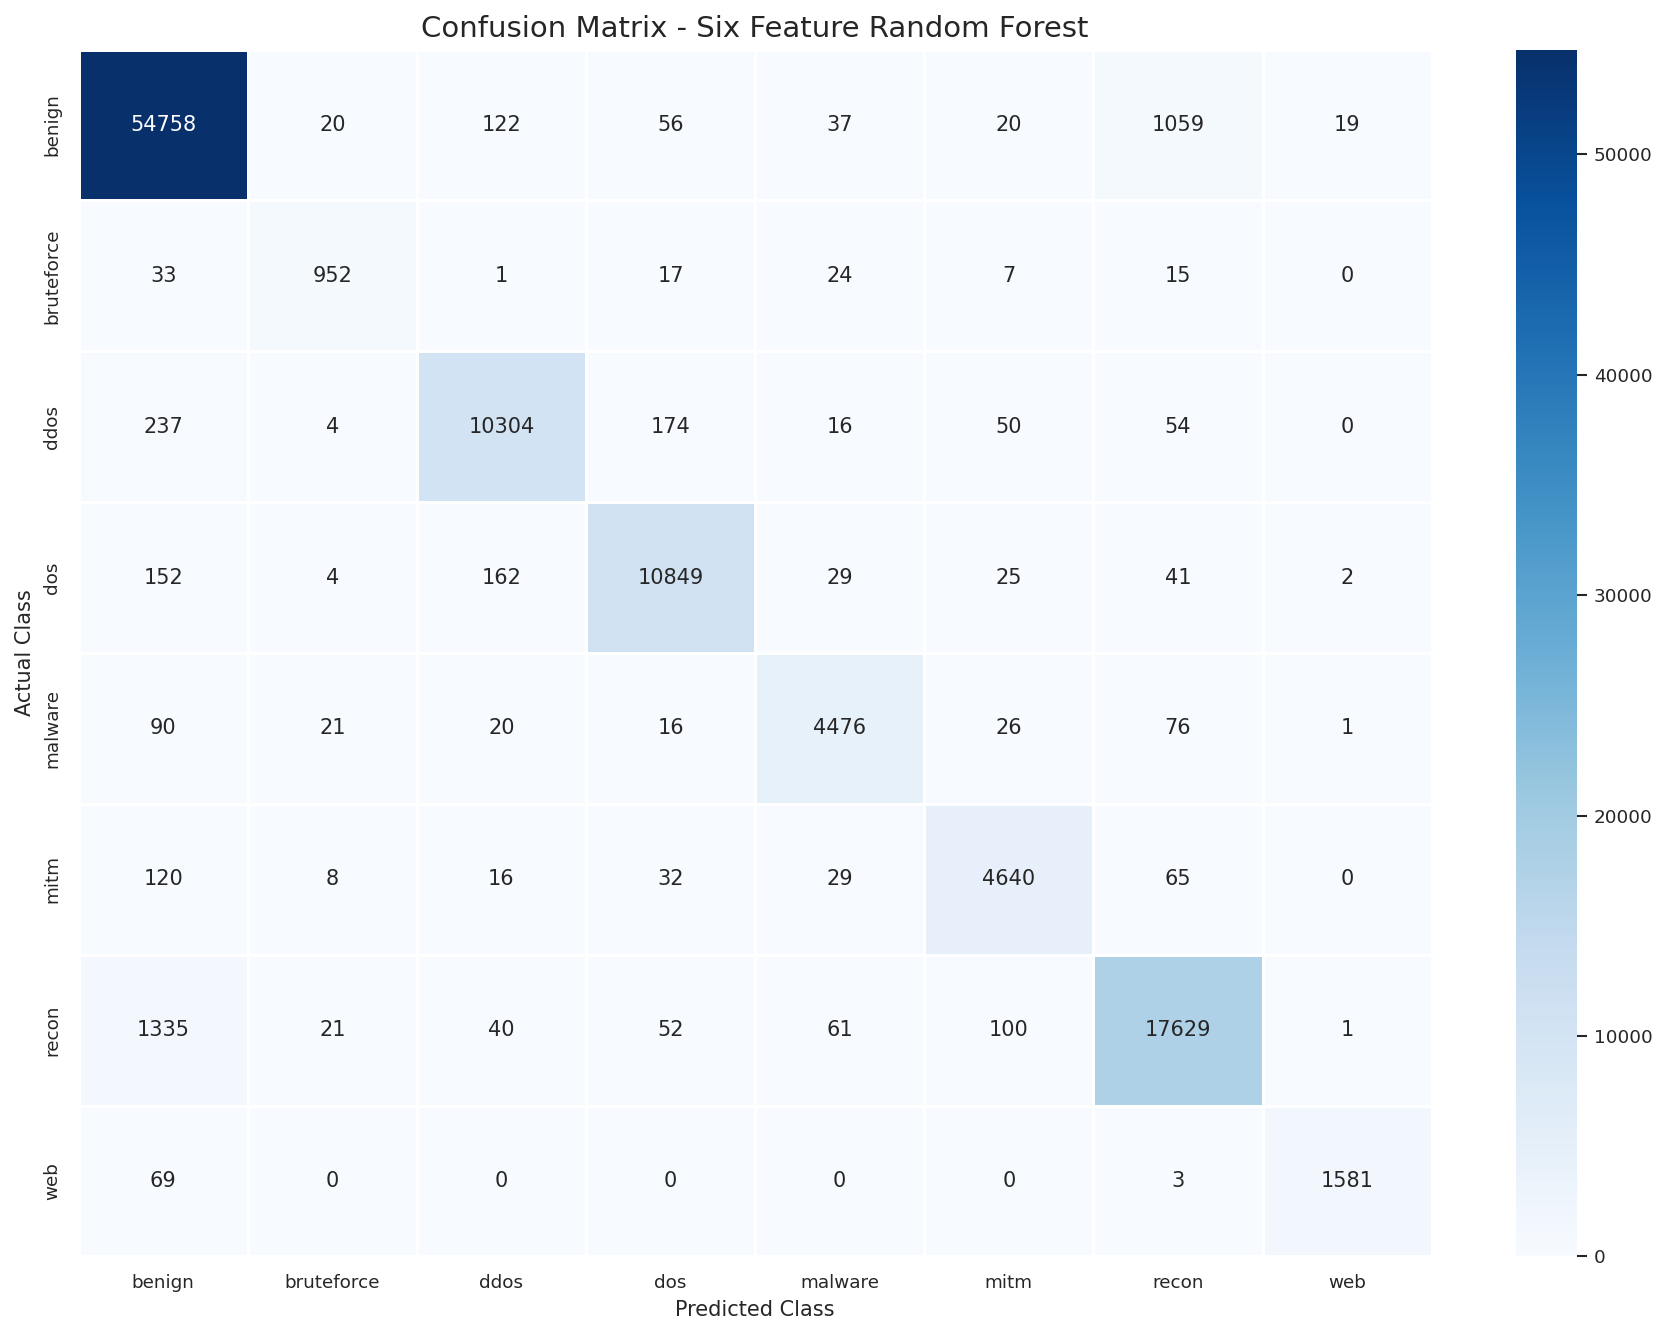


CLASS-WISE ERROR ANALYSIS


,Class,True_Positive,False_Positive,False_Negative,True_Negative,Recall,Precision,FPR,FNR
0,benign,54758,2036,1333,51644,0.976235,0.964151,0.037928,0.023765
1,bruteforce,952,78,97,108644,0.907531,0.924272,0.000717,0.092469
2,ddos,10304,361,535,98571,0.950641,0.966151,0.003649,0.049359
3,dos,10849,347,415,98160,0.963157,0.969007,0.003523,0.036843
4,malware,4476,196,250,104849,0.947101,0.958048,0.001866,0.052899
5,mitm,4640,228,270,104633,0.945010,0.953164,0.002174,0.054990
6,recon,17629,1313,1610,89219,0.916316,0.930683,0.014503,0.083684
7,web,1581,23,72,108095,0.956443,0.985661,0.000213,0.043557



TOP 15 MISCLASSIFICATION PAIRS


,Actual_Class,Predicted_Class,Misclassified_Samples
0,recon,benign,1335
1,benign,recon,1059
2,ddos,benign,237
3,ddos,dos,174
4,dos,ddos,162
5,dos,benign,152
6,benign,ddos,122
7,mitm,benign,120
8,recon,mitm,100
9,malware,benign,90



ATTACKS MISCLASSIFIED AS BENIGN


,Actual_Class,Predicted_Class,Misclassified_Samples
0,recon,benign,1335
2,ddos,benign,237
5,dos,benign,152
7,mitm,benign,120
9,malware,benign,90
11,web,benign,69
21,bruteforce,benign,33



OVERALL ERROR ANALYSIS
Total samples: 109771
Correct predictions: 105189
Incorrect predictions: 4582
Overall error rate: 0.041741
Overall accuracy: 0.958259

Attack samples incorrectly classified as benign: 2036

STEP 6.19 COMPLETED
Analysis directory: /kaggle/working/final_research_artifacts/six_feature_error_analysis

Generated files:
- six_feature_confusion_matrix.csv
- six_feature_error_analysis_summary.json
- six_feature_confusion_matrix.png
- attacks_misclassified_as_benign.csv
- six_feature_misclassification_pairs.csv
- six_feature_classwise_error_analysis.csv


In [120]:

# ============================================================
# PHASE 1 - ITEM 2
# STEP 6.19: CONFUSION MATRIX AND DETAILED ERROR ANALYSIS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. Define paths
# ------------------------------------------------------------

OUTPUT_DIR = "/kaggle/working/final_research_artifacts"

PREDICTIONS_PATH = os.path.join(
    OUTPUT_DIR,
    "final_three_model_test_predictions.csv"
)

ANALYSIS_DIR = os.path.join(
    OUTPUT_DIR,
    "six_feature_error_analysis"
)

os.makedirs(ANALYSIS_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. Load saved predictions
# ------------------------------------------------------------

prediction_df = pd.read_csv(PREDICTIONS_PATH)

required_columns = [
    "true_label",
    "RF_6_features_prediction"
]

missing = set(required_columns) - set(prediction_df.columns)

if missing:
    raise ValueError(
        f"Missing columns: {missing}"
    )

y_true = prediction_df["true_label"].reset_index(drop=True)

y_pred = prediction_df[
    "RF_6_features_prediction"
].reset_index(drop=True)

if len(y_true) != len(y_pred):
    raise ValueError("Prediction length mismatch.")

print("Test samples:", len(y_true))
print("Prediction data loaded successfully.")

# ------------------------------------------------------------
# 3. Generate confusion matrix
# ------------------------------------------------------------

class_labels = sorted(
    set(y_true.unique()) | set(y_pred.unique())
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_labels
)

cm_df = pd.DataFrame(
    cm,
    index=class_labels,
    columns=class_labels
)

cm_path = os.path.join(
    ANALYSIS_DIR,
    "six_feature_confusion_matrix.csv"
)

cm_df.to_csv(cm_path)

print("\nCONFUSION MATRIX")
display(cm_df)

# ------------------------------------------------------------
# 4. Plot confusion matrix
# ------------------------------------------------------------

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title(
    "Confusion Matrix - Six Feature Random Forest",
    fontsize=14
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

confusion_plot_path = os.path.join(
    ANALYSIS_DIR,
    "six_feature_confusion_matrix.png"
)

plt.savefig(
    confusion_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. Calculate class-wise error statistics
# ------------------------------------------------------------

total_samples = len(y_true)

class_error_results = []

for i, label in enumerate(class_labels):

    tp = cm[i, i]

    fn = cm[i, :].sum() - tp

    fp = cm[:, i].sum() - tp

    tn = total_samples - tp - fn - fp

    class_recall = (
        tp / (tp + fn)
        if (tp + fn) > 0 else 0
    )

    class_precision = (
        tp / (tp + fp)
        if (tp + fp) > 0 else 0
    )

    class_fpr = (
        fp / (fp + tn)
        if (fp + tn) > 0 else 0
    )

    class_fnr = (
        fn / (fn + tp)
        if (fn + tp) > 0 else 0
    )

    class_error_results.append({

        "Class": label,

        "True_Positive": tp,

        "False_Positive": fp,

        "False_Negative": fn,

        "True_Negative": tn,

        "Recall": class_recall,

        "Precision": class_precision,

        "FPR": class_fpr,

        "FNR": class_fnr

    })

error_df = pd.DataFrame(class_error_results)

error_path = os.path.join(
    ANALYSIS_DIR,
    "six_feature_classwise_error_analysis.csv"
)

error_df.to_csv(
    error_path,
    index=False
)

print("\nCLASS-WISE ERROR ANALYSIS")
display(error_df.round(6))

# ------------------------------------------------------------
# 6. Identify misclassified class pairs
# ------------------------------------------------------------

misclassification_results = []

for i, actual_class in enumerate(class_labels):

    for j, predicted_class in enumerate(class_labels):

        if i != j and cm[i, j] > 0:

            misclassification_results.append({

                "Actual_Class": actual_class,

                "Predicted_Class": predicted_class,

                "Misclassified_Samples": int(cm[i, j])

            })

misclassification_df = pd.DataFrame(
    misclassification_results
)

if not misclassification_df.empty:

    misclassification_df = (
        misclassification_df.sort_values(
            by="Misclassified_Samples",
            ascending=False
        ).reset_index(drop=True)
    )

misclassification_path = os.path.join(
    ANALYSIS_DIR,
    "six_feature_misclassification_pairs.csv"
)

misclassification_df.to_csv(
    misclassification_path,
    index=False
)

print("\nTOP 15 MISCLASSIFICATION PAIRS")

display(
    misclassification_df.head(15)
)

# ------------------------------------------------------------
# 7. Identify attacks incorrectly classified as benign
# ------------------------------------------------------------

attack_to_benign = misclassification_df[
    (misclassification_df["Actual_Class"] != "benign") &
    (misclassification_df["Predicted_Class"] == "benign")
].copy()

attack_to_benign = attack_to_benign.sort_values(
    by="Misclassified_Samples",
    ascending=False
)

print("\nATTACKS MISCLASSIFIED AS BENIGN")
display(attack_to_benign)

attack_benign_path = os.path.join(
    ANALYSIS_DIR,
    "attacks_misclassified_as_benign.csv"
)

attack_to_benign.to_csv(
    attack_benign_path,
    index=False
)

# ------------------------------------------------------------
# 8. Calculate overall error statistics
# ------------------------------------------------------------

correct_predictions = int(np.trace(cm))

incorrect_predictions = int(
    total_samples - correct_predictions
)

overall_error_rate = (
    incorrect_predictions / total_samples
)

print("\n" + "=" * 75)
print("OVERALL ERROR ANALYSIS")
print("=" * 75)

print("Total samples:", total_samples)
print("Correct predictions:", correct_predictions)
print("Incorrect predictions:", incorrect_predictions)

print(
    f"Overall error rate: "
    f"{overall_error_rate:.6f}"
)

print(
    f"Overall accuracy: "
    f"{correct_predictions / total_samples:.6f}"
)

print(
    "\nAttack samples incorrectly classified as benign:",
    int(attack_to_benign["Misclassified_Samples"].sum())
)

# ------------------------------------------------------------
# 9. Save summary metadata
# ------------------------------------------------------------

summary = {

    "model": "RF_6_features",

    "total_test_samples": int(total_samples),

    "correct_predictions": correct_predictions,

    "incorrect_predictions": incorrect_predictions,

    "overall_error_rate": float(overall_error_rate),

    "overall_accuracy": float(
        correct_predictions / total_samples
    ),

    "class_labels": class_labels,

    "analysis_files": {

        "confusion_matrix": cm_path,

        "classwise_errors": error_path,

        "misclassification_pairs": misclassification_path,

        "attacks_as_benign": attack_benign_path,

        "confusion_matrix_plot": confusion_plot_path

    }

}

import json

summary_path = os.path.join(
    ANALYSIS_DIR,
    "six_feature_error_analysis_summary.json"
)

with open(summary_path, "w") as f:

    json.dump(
        summary,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 10. Completion
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 6.19 COMPLETED")
print("=" * 75)

print("Analysis directory:", ANALYSIS_DIR)

print("\nGenerated files:")

for filename in os.listdir(ANALYSIS_DIR):

    print("-", filename)


Model loaded successfully!

========== FEATURE IMPORTANCE RANKING ==========



,Rank,Feature,Importance
0,1,network_time-delta_avg,0.243295
1,2,network_time-delta_min,0.183980
2,3,network_window-size_std_deviation,0.162233
3,4,network_ip-flags_avg,0.149691
4,5,network_ttl_min,0.130565
5,6,network_ips_all_count,0.130236


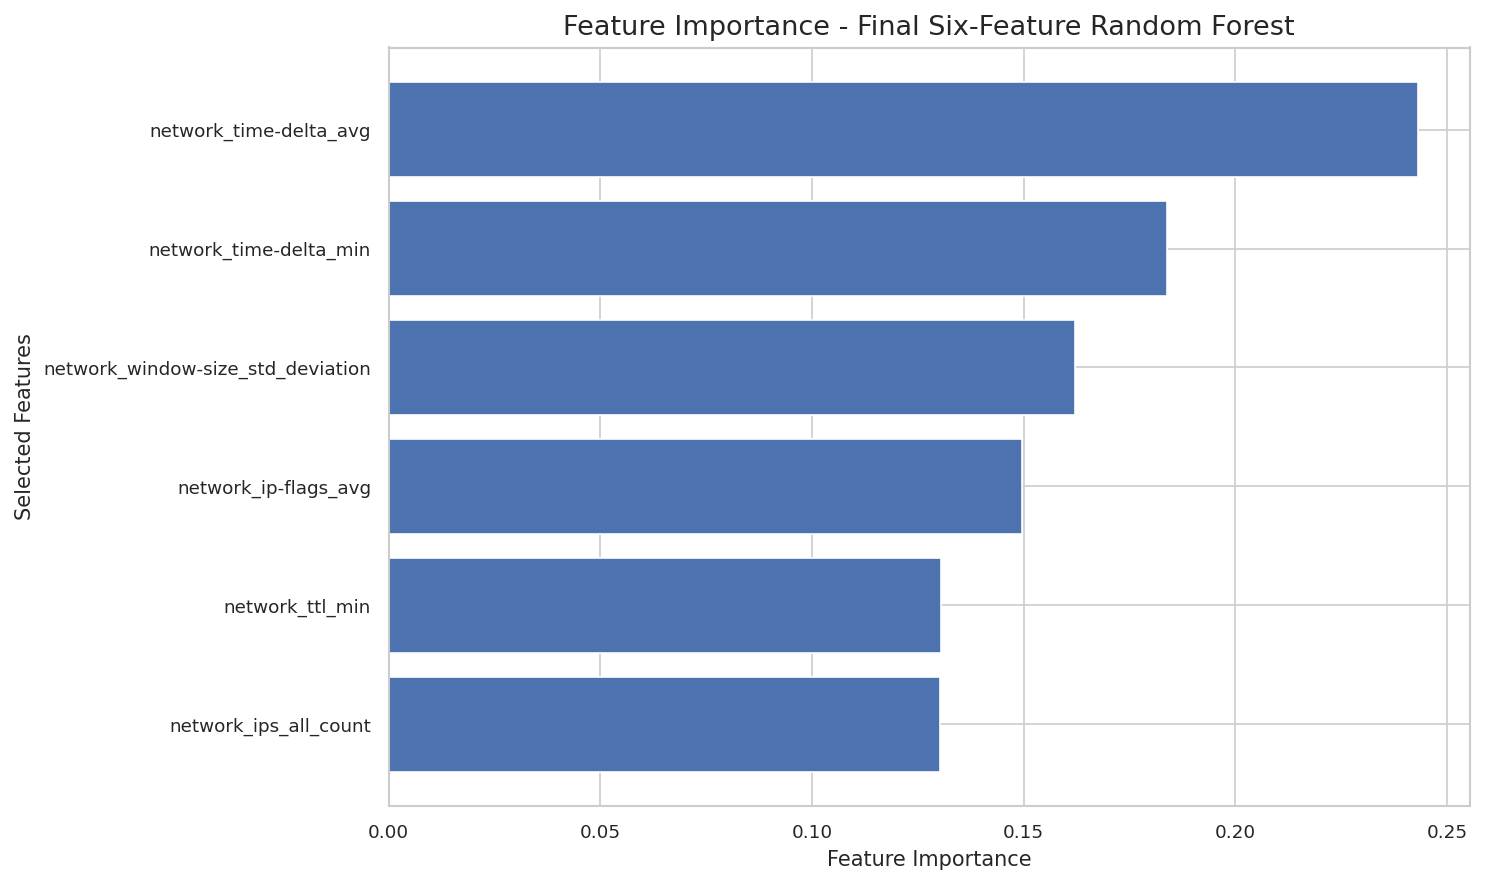


========== FILES SAVED ==========
CSV: /kaggle/working/final_research_artifacts/six_feature_importance_analysis/six_feature_importance.csv
Plot: /kaggle/working/final_research_artifacts/six_feature_importance_analysis/six_feature_importance.png

Feature importance analysis completed!


In [121]:
# ============================================================
# STEP 6.20: FEATURE IMPORTANCE ANALYSIS
# Final six-feature Random Forest model
# ============================================================

import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define paths
BASE_DIR = "/kaggle/working/final_research_artifacts"

MODEL_PATH = os.path.join(
    BASE_DIR,
    "final_rf_models",
    "RF_6_features.joblib"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "six_feature_importance_analysis"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. Load the trained model
rf_model = joblib.load(MODEL_PATH)

print("Model loaded successfully!")

# 3. Get feature names and importance scores
feature_names = list(rf_model.feature_names_in_)
importance_scores = rf_model.feature_importances_

# 4. Create a feature-importance DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

# 5. Sort features from highest to lowest importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

importance_df["Rank"] = range(1, len(importance_df) + 1)

importance_df = importance_df[
    ["Rank", "Feature", "Importance"]
]

# 6. Display results
print("\n========== FEATURE IMPORTANCE RANKING ==========\n")
display(importance_df)

# 7. Save results
csv_path = os.path.join(
    OUTPUT_DIR,
    "six_feature_importance.csv"
)

importance_df.to_csv(csv_path, index=False)

# 8. Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Selected Features")
plt.title("Feature Importance - Final Six-Feature Random Forest")

plt.gca().invert_yaxis()
plt.tight_layout()

plot_path = os.path.join(
    OUTPUT_DIR,
    "six_feature_importance.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("\n========== FILES SAVED ==========")
print("CSV:", csv_path)
print("Plot:", plot_path)

print("\nFeature importance analysis completed!")

Validation data shape: (23036, 6)
Number of features: 6

Baseline Validation Macro F1: 0.962378

========== PERMUTATION IMPORTANCE ==========



,Rank,Feature,Importance_Mean,Importance_Std
0,1,network_time-delta_min,0.347896,0.003498
1,2,network_time-delta_avg,0.316051,0.002528
2,3,network_ttl_min,0.296907,0.002784
3,4,network_ip-flags_avg,0.287883,0.005081
4,5,network_window-size_std_deviation,0.220690,0.002753
5,6,network_ips_all_count,0.150321,0.002660


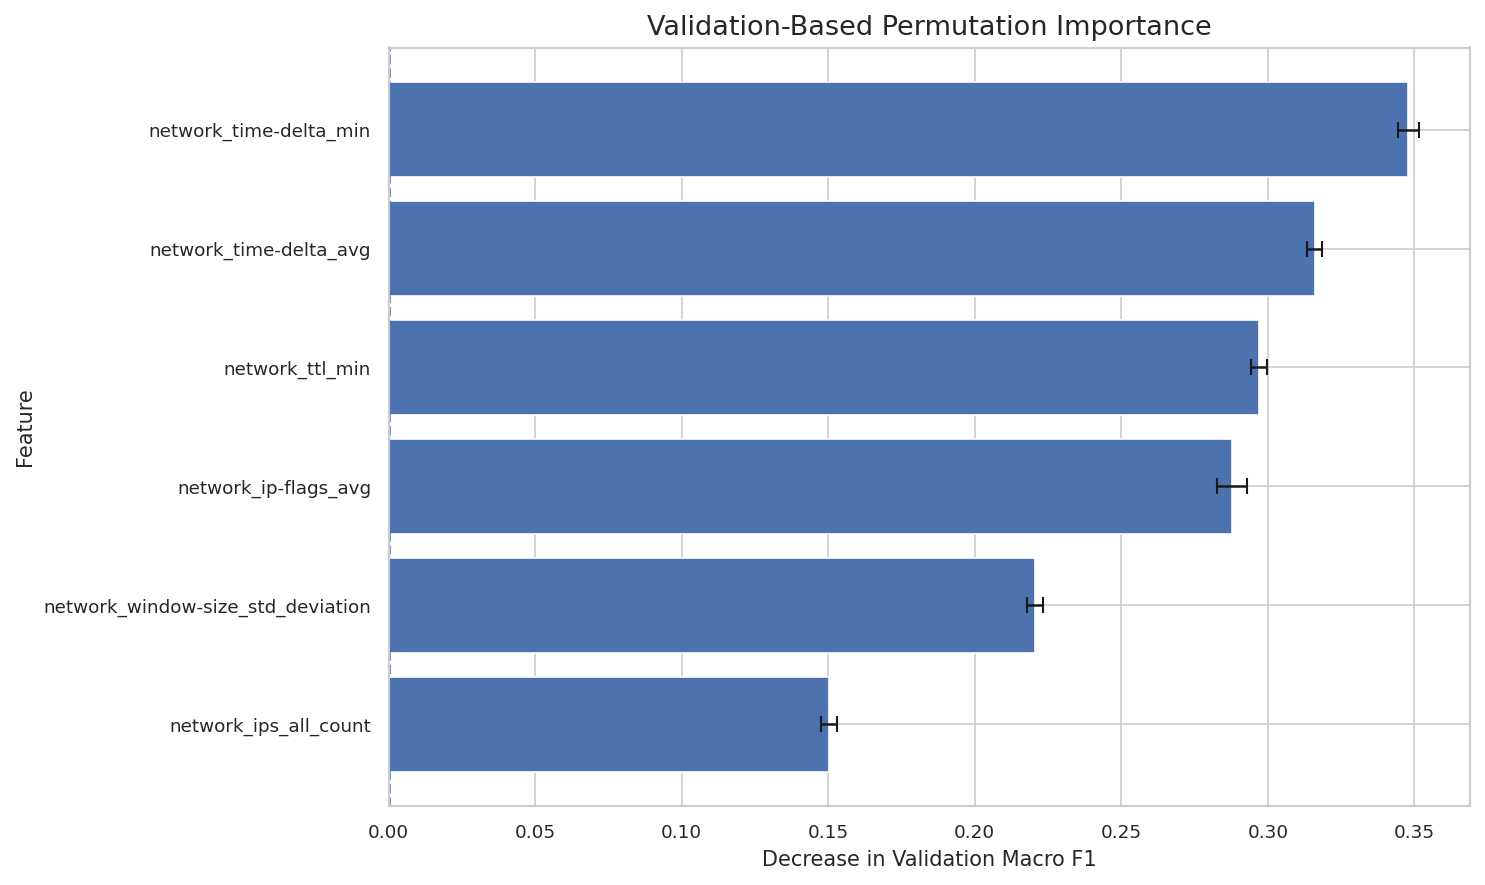


========== SAVED FILES ==========
CSV: /kaggle/working/final_research_artifacts/six_feature_permutation_analysis/six_feature_permutation_importance.csv
Plot: /kaggle/working/final_research_artifacts/six_feature_permutation_analysis/six_feature_permutation_importance.png

Step 6.21 completed!


In [122]:
# ============================================================
# STEP 6.21: VALIDATION-BASED PERMUTATION IMPORTANCE
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score

# 1. Check validation data availability
if "X_val" not in globals() or "y_val" not in globals():
    raise NameError(
        "X_val or y_val is missing. Please run the earlier "
        "validation data preparation cells first."
    )

# 2. Define paths
BASE_DIR = "/kaggle/working/final_research_artifacts"

MODEL_PATH = os.path.join(
    BASE_DIR, "final_rf_models", "RF_6_features.joblib"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR, "six_feature_permutation_analysis"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 3. Load the final six-feature model
rf_model = joblib.load(MODEL_PATH)

features = list(rf_model.feature_names_in_)

# 4. Prepare validation data using exactly the model's features
X_validation = X_val[features].copy()
y_validation = y_val.copy()

print("Validation data shape:", X_validation.shape)
print("Number of features:", len(features))

# 5. Calculate baseline validation macro F1
baseline_predictions = rf_model.predict(X_validation)

baseline_f1 = f1_score(
    y_validation,
    baseline_predictions,
    average="macro"
)

print("\nBaseline Validation Macro F1:", round(baseline_f1, 6))

# 6. Calculate permutation importance
permutation_result = permutation_importance(
    estimator=rf_model,
    X=X_validation,
    y=y_validation,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# 7. Create results table
permutation_df = pd.DataFrame({
    "Feature": features,
    "Importance_Mean": permutation_result.importances_mean,
    "Importance_Std": permutation_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

permutation_df["Rank"] = range(1, len(permutation_df) + 1)

permutation_df = permutation_df[
    ["Rank", "Feature", "Importance_Mean", "Importance_Std"]
]

# 8. Display results
print("\n========== PERMUTATION IMPORTANCE ==========\n")
display(permutation_df)

# 9. Save results
csv_path = os.path.join(
    OUTPUT_DIR,
    "six_feature_permutation_importance.csv"
)

permutation_df.to_csv(csv_path, index=False)

# 10. Plot results
plt.figure(figsize=(10, 6))

plt.barh(
    permutation_df["Feature"],
    permutation_df["Importance_Mean"],
    xerr=permutation_df["Importance_Std"],
    capsize=4
)

plt.axvline(0, linestyle="--")

plt.xlabel("Decrease in Validation Macro F1")
plt.ylabel("Feature")
plt.title("Validation-Based Permutation Importance")

plt.gca().invert_yaxis()
plt.tight_layout()

plot_path = os.path.join(
    OUTPUT_DIR,
    "six_feature_permutation_importance.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("\n========== SAVED FILES ==========")
print("CSV:", csv_path)
print("Plot:", plot_path)

print("\nStep 6.21 completed!")

In [123]:
# ============================================================
# STEP 6.22: DATASET SPLIT CONSISTENCY AUDIT
# ============================================================

import pandas as pd
import numpy as np

datasets = {
    "X_train": globals().get("X_train"),
    "X_fit": globals().get("X_fit"),
    "X_val": globals().get("X_val"),
    "y_train": globals().get("y_train"),
    "y_fit": globals().get("y_fit"),
    "y_val": globals().get("y_val")
}

print("=" * 60)
print("DATASET AVAILABILITY AND SHAPES")
print("=" * 60)

for name, data in datasets.items():
    if data is None:
        print(f"{name}: NOT AVAILABLE")
    else:
        print(f"{name}: shape = {data.shape}")

# ------------------------------------------------------------
# 1. Check feature-label sample counts
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FEATURE-LABEL ALIGNMENT")
print("=" * 60)

for x_name, y_name in [
    ("X_train", "y_train"),
    ("X_fit", "y_fit"),
    ("X_val", "y_val")
]:
    X = datasets[x_name]
    y = datasets[y_name]

    if X is not None and y is not None:
        print(
            f"{x_name} vs {y_name}: "
            f"{len(X)} vs {len(y)} samples"
        )

        if len(X) != len(y):
            print("WARNING: Sample counts do not match!")
        elif isinstance(X, pd.DataFrame) and isinstance(y, pd.Series):
            print("Index alignment:", X.index.equals(y.index))

# ------------------------------------------------------------
# 2. Check index overlap between feature datasets
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("INDEX OVERLAP CHECK")
print("=" * 60)

feature_sets = {
    name: data
    for name, data in datasets.items()
    if name.startswith("X_") and isinstance(data, pd.DataFrame)
}

names = list(feature_sets.keys())

for i in range(len(names)):
    for j in range(i + 1, len(names)):
        name1, name2 = names[i], names[j]

        overlap = len(
            feature_sets[name1].index.intersection(
                feature_sets[name2].index
            )
        )

        print(f"{name1} vs {name2}: {overlap} shared indices")

# ------------------------------------------------------------
# 3. Check class distributions
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("LABEL DISTRIBUTIONS")
print("=" * 60)

for name in ["y_train", "y_fit", "y_val"]:
    y = datasets[name]

    if y is not None:
        print(f"\n{name}:")
        print(pd.Series(y).value_counts().sort_index())

print("\n" + "=" * 60)
print("AUDIT COMPLETED")
print("=" * 60)

DATASET AVAILABILITY AND SHAPES
X_train: shape = (575900, 71)
X_fit: shape = (92144, 71)
X_val: shape = (23036, 71)
y_train: shape = (575900,)
y_fit: shape = (92144,)
y_val: shape = (23036,)

FEATURE-LABEL ALIGNMENT
X_train vs y_train: 575900 vs 575900 samples
Index alignment: True
X_fit vs y_fit: 92144 vs 92144 samples
Index alignment: True
X_val vs y_val: 23036 vs 23036 samples
Index alignment: True

INDEX OVERLAP CHECK
X_train vs X_fit: 92144 shared indices
X_train vs X_val: 23036 shared indices
X_fit vs X_val: 0 shared indices

LABEL DISTRIBUTIONS

y_train:
label2
benign        344581
bruteforce      4967
ddos           45853
dos            46472
malware        19451
mitm           20580
recon          86609
web             7387
Name: count, dtype: int64

y_fit:
label2
benign        55133
bruteforce      794
ddos           7337
dos            7436
malware        3112
mitm           3293
recon         13858
web            1181
Name: count, dtype: int64

y_val:
label2
benign        1

Training model using X_fit...
Training completed!

Independent Validation Macro F1: 0.919973

========== CORRECTED PERMUTATION IMPORTANCE ==========


,Rank,Feature,Importance_Mean,Importance_Std
0,1,network_time-delta_avg,0.304794,0.003278
1,2,network_time-delta_min,0.298128,0.004281
2,3,network_ip-flags_avg,0.246728,0.007281
3,4,network_ttl_min,0.227816,0.003137
4,5,network_window-size_std_deviation,0.181882,0.003615
5,6,network_ips_all_count,0.124373,0.002536


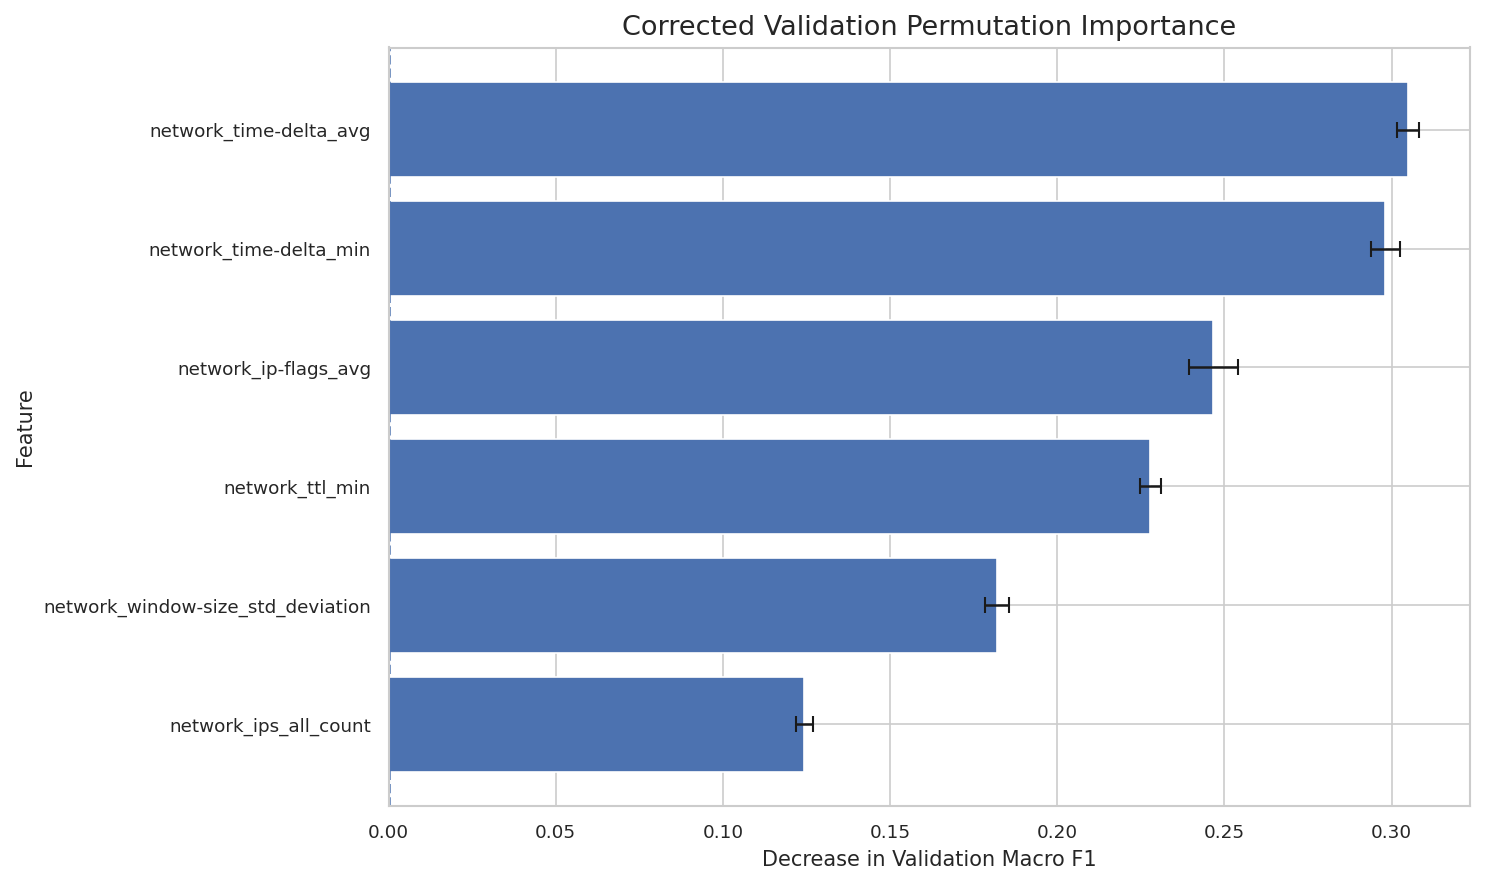


Step 6.23 completed!
Results saved in: /kaggle/working/final_research_artifacts/corrected_validation_permutation


In [124]:
# ============================================================
# STEP 6.23: CORRECTED VALIDATION PERMUTATION IMPORTANCE
# Train on X_fit; evaluate on independent X_val
# ============================================================

import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.inspection import permutation_importance

# 1. Define selected features
features = [
    "network_ip-flags_avg",
    "network_ips_all_count",
    "network_time-delta_avg",
    "network_time-delta_min",
    "network_ttl_min",
    "network_window-size_std_deviation"
]

# 2. Prepare training and validation datasets
X_fit_6 = X_fit[features].copy()
X_val_6 = X_val[features].copy()

# 3. Train a fresh model ONLY on X_fit
validation_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

print("Training model using X_fit...")

validation_model.fit(X_fit_6, y_fit)

print("Training completed!")

# 4. Calculate independent validation macro F1
val_predictions = validation_model.predict(X_val_6)

baseline_f1 = f1_score(
    y_val,
    val_predictions,
    average="macro"
)

print("\nIndependent Validation Macro F1:",
      round(baseline_f1, 6))

# 5. Calculate permutation importance
result = permutation_importance(
    estimator=validation_model,
    X=X_val_6,
    y=y_val,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# 6. Create ranking table
permutation_df = pd.DataFrame({
    "Feature": features,
    "Importance_Mean": result.importances_mean,
    "Importance_Std": result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

permutation_df["Rank"] = range(
    1, len(permutation_df) + 1
)

permutation_df = permutation_df[
    ["Rank", "Feature", "Importance_Mean", "Importance_Std"]
]

print("\n========== CORRECTED PERMUTATION IMPORTANCE ==========")
display(permutation_df)

# 7. Save results
OUTPUT_DIR = (
    "/kaggle/working/final_research_artifacts/"
    "corrected_validation_permutation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

permutation_df.to_csv(
    os.path.join(OUTPUT_DIR, "permutation_importance.csv"),
    index=False
)

# 8. Plot
plt.figure(figsize=(10, 6))

plt.barh(
    permutation_df["Feature"],
    permutation_df["Importance_Mean"],
    xerr=permutation_df["Importance_Std"],
    capsize=4
)

plt.axvline(0, linestyle="--")
plt.xlabel("Decrease in Validation Macro F1")
plt.ylabel("Feature")
plt.title("Corrected Validation Permutation Importance")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "permutation_importance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 9. Save the validation-only model
joblib.dump(
    validation_model,
    os.path.join(OUTPUT_DIR, "validation_rf_6_features.joblib")
)

print("\nStep 6.23 completed!")
print("Results saved in:", OUTPUT_DIR)

In [125]:
import json
import os

path = (
    "/kaggle/working/final_research_artifacts/"
    "final_three_model_feature_lists.json"
)

with open(path, "r") as f:
    feature_lists = json.load(f)

print("Available feature-list keys:")
print(list(feature_lists.keys()))

print("\nComplete feature-list structure:")
print(json.dumps(feature_lists, indent=2))

Available feature-list keys:
['RF_71_features', 'RF_9_features', 'RF_6_features']

Complete feature-list structure:
{
  "RF_71_features": [
    "log_data-ranges_avg",
    "log_data-ranges_max",
    "log_data-ranges_min",
    "log_data-ranges_std_deviation",
    "log_data-types_count",
    "log_interval-messages",
    "log_messages_count",
    "network_fragmentation-score",
    "network_fragmented-packets",
    "network_header-length_avg",
    "network_header-length_max",
    "network_header-length_min",
    "network_header-length_std_deviation",
    "network_interval-packets",
    "network_ip-flags_avg",
    "network_ip-flags_max",
    "network_ip-flags_min",
    "network_ip-flags_std_deviation",
    "network_ip-length_avg",
    "network_ip-length_max",
    "network_ip-length_min",
    "network_ip-length_std_deviation",
    "network_ips_all_count",
    "network_ips_dst_count",
    "network_ips_src_count",
    "network_macs_all_count",
    "network_macs_dst_count",
    "network_macs_src

In [126]:
# ============================================================
# STEP 6.25: FAIR VALIDATION COMPARISON
# 71 FEATURES vs 9 FEATURES vs 6 FEATURES
# ============================================================

import os
import json
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Define paths and load original feature lists
# ------------------------------------------------------------

BASE_DIR = "/kaggle/working/final_research_artifacts"

FEATURE_PATH = os.path.join(
    BASE_DIR,
    "final_three_model_feature_lists.json"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "fair_validation_comparison"
)

MODEL_DIR = os.path.join(OUTPUT_DIR, "models")

os.makedirs(MODEL_DIR, exist_ok=True)

with open(FEATURE_PATH, "r") as f:
    feature_lists = json.load(f)

# ------------------------------------------------------------
# 2. Verify validation and training datasets
# ------------------------------------------------------------

assert X_fit.index.equals(y_fit.index)
assert X_val.index.equals(y_val.index)

model_names = [
    "RF_71_features",
    "RF_9_features",
    "RF_6_features"
]

for name in model_names:
    missing = [
        col for col in feature_lists[name]
        if col not in X_fit.columns or col not in X_val.columns
    ]

    if missing:
        raise ValueError(f"Missing features for {name}: {missing}")

print("Training samples:", len(X_fit))
print("Validation samples:", len(X_val))
print("Feature lists verified!")

# ------------------------------------------------------------
# 3. Define macro OVR false positive rate
# ------------------------------------------------------------

def calculate_macro_ovr_fpr(y_true, y_pred, classes):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=classes
    )

    total = cm.sum()
    fpr_values = []

    for i in range(len(classes)):

        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = total - tp - fn - fp

        denominator = fp + tn

        fpr = fp / denominator if denominator > 0 else 0

        fpr_values.append(fpr)

    return np.mean(fpr_values)

# ------------------------------------------------------------
# 4. Train and evaluate all three models
# ------------------------------------------------------------

results = []
prediction_data = pd.DataFrame({
    "Actual": np.asarray(y_val)
})

trained_models = {}

for model_name in model_names:

    print("\n" + "=" * 60)
    print("Training:", model_name)
    print("=" * 60)

    features = feature_lists[model_name]

    X_train_subset = X_fit[features]
    X_val_subset = X_val[features]

    # Create identical Random Forest configurations
    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    # Measure training time
    start_time = time.perf_counter()

    model.fit(X_train_subset, y_fit)

    training_time = time.perf_counter() - start_time

    # Generate validation predictions
    y_pred = model.predict(X_val_subset)

    # Measure batch prediction time (median of 3 runs)
    prediction_times = []

    for _ in range(3):
        start_time = time.perf_counter()
        model.predict(X_val_subset)
        prediction_times.append(
            time.perf_counter() - start_time
        )

    prediction_time = float(np.median(prediction_times))

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_val, y_pred)

    macro_precision = precision_score(
        y_val, y_pred, average="macro", zero_division=0
    )

    macro_recall = recall_score(
        y_val, y_pred, average="macro", zero_division=0
    )

    macro_f1 = f1_score(
        y_val, y_pred, average="macro", zero_division=0
    )

    weighted_f1 = f1_score(
        y_val, y_pred, average="weighted", zero_division=0
    )

    macro_fpr = calculate_macro_ovr_fpr(
        y_val,
        y_pred,
        model.classes_
    )

    feature_count = len(features)

    feature_reduction = (
        (71 - feature_count) / 71
    ) * 100

    # Store results
    results.append({
        "Model": model_name,
        "Feature_Count": feature_count,
        "Feature_Reduction_Percent": feature_reduction,
        "Accuracy": accuracy,
        "Macro_Precision": macro_precision,
        "Macro_Recall": macro_recall,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1,
        "Macro_OVR_FPR": macro_fpr,
        "Training_Time_Seconds": training_time,
        "Prediction_Time_Seconds": prediction_time
    })

    prediction_data[model_name + "_Prediction"] = y_pred

    trained_models[model_name] = model

    # Save each validation-trained model
    joblib.dump(
        model,
        os.path.join(MODEL_DIR, model_name + ".joblib")
    )

    print("Features:", feature_count)
    print("Accuracy:", round(accuracy, 6))
    print("Macro F1:", round(macro_f1, 6))
    print("Macro OVR FPR:", round(macro_fpr, 6))
    print("Training time:", round(training_time, 3), "seconds")
    print("Prediction time:", round(prediction_time, 3), "seconds")

# ------------------------------------------------------------
# 5. Create comparison table
# ------------------------------------------------------------

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="Feature_Count",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("FINAL FAIR VALIDATION COMPARISON")
print("=" * 70)

display(comparison_df)

# ------------------------------------------------------------
# 6. Save comparison and predictions
# ------------------------------------------------------------

comparison_path = os.path.join(
    OUTPUT_DIR,
    "fair_validation_model_comparison.csv"
)

prediction_path = os.path.join(
    OUTPUT_DIR,
    "fair_validation_predictions.csv"
)

comparison_df.to_csv(comparison_path, index=False)
prediction_data.to_csv(prediction_path, index=False)

print("\n" + "=" * 70)
print("STEP 6.25 COMPLETED")
print("=" * 70)

print("Comparison:", comparison_path)
print("Predictions:", prediction_path)
print("Saved models:", MODEL_DIR)

Training samples: 92144
Validation samples: 23036
Feature lists verified!

Training: RF_71_features
Features: 71
Accuracy: 0.955287
Macro F1: 0.940984
Macro OVR FPR: 0.012613
Training time: 7.958 seconds
Prediction time: 0.125 seconds

Training: RF_9_features
Features: 9
Accuracy: 0.948949
Macro F1: 0.926216
Macro OVR FPR: 0.013587
Training time: 5.83 seconds
Prediction time: 0.112 seconds

Training: RF_6_features
Features: 6
Accuracy: 0.946822
Macro F1: 0.919973
Macro OVR FPR: 0.013961
Training time: 4.116 seconds
Prediction time: 0.119 seconds

FINAL FAIR VALIDATION COMPARISON


,Model,Feature_Count,Feature_Reduction_Percent,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Macro_OVR_FPR,Training_Time_Seconds,Prediction_Time_Seconds
0,RF_71_features,71,0.000000,0.955287,0.974676,0.911474,0.940984,0.954541,0.012613,7.957654,0.125412
1,RF_9_features,9,87.323944,0.948949,0.962169,0.894695,0.926216,0.948000,0.013587,5.830042,0.111597
2,RF_6_features,6,91.549296,0.946822,0.952915,0.890811,0.919973,0.945802,0.013961,4.116100,0.118815



STEP 6.25 COMPLETED
Comparison: /kaggle/working/final_research_artifacts/fair_validation_comparison/fair_validation_model_comparison.csv
Predictions: /kaggle/working/final_research_artifacts/fair_validation_comparison/fair_validation_predictions.csv
Saved models: /kaggle/working/final_research_artifacts/fair_validation_comparison/models


In [127]:
# ============================================================
# STEP 6.26: CLASS-WISE VALIDATION PERFORMANCE COMPARISON
# ============================================================

import os
import pandas as pd
from sklearn.metrics import classification_report

BASE_DIR = "/kaggle/working/final_research_artifacts"

INPUT_PATH = os.path.join(
    BASE_DIR,
    "fair_validation_comparison",
    "fair_validation_predictions.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "classwise_validation_analysis"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Load saved predictions
predictions_df = pd.read_csv(INPUT_PATH)

y_true = predictions_df["Actual"]

model_columns = {
    "RF_71_features": "RF_71_features_Prediction",
    "RF_9_features": "RF_9_features_Prediction",
    "RF_6_features": "RF_6_features_Prediction"
}

classes = sorted(y_true.unique())

# 2. Generate class-wise metrics
all_reports = []

for model_name, prediction_column in model_columns.items():

    report = classification_report(
        y_true,
        predictions_df[prediction_column],
        labels=classes,
        output_dict=True,
        zero_division=0
    )

    for class_name in classes:

        all_reports.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1_Score": report[class_name]["f1-score"],
            "Support": report[class_name]["support"]
        })

classwise_df = pd.DataFrame(all_reports)

# 3. Create an easy-to-read recall comparison
recall_comparison = classwise_df.pivot(
    index="Class",
    columns="Model",
    values="Recall"
)

print("\n========== CLASS-WISE RECALL COMPARISON ==========")
display(recall_comparison)

# 4. Calculate recall difference against 71-feature model
recall_comparison["9F_vs_71F_Difference"] = (
    recall_comparison["RF_9_features"]
    - recall_comparison["RF_71_features"]
)

recall_comparison["6F_vs_71F_Difference"] = (
    recall_comparison["RF_6_features"]
    - recall_comparison["RF_71_features"]
)

print("\n========== RECALL DIFFERENCES ==========")
display(recall_comparison)

# 5. Count attack samples predicted as benign
attack_classes = [
    c for c in classes if c != "benign"
]

attack_to_benign = []

for model_name, prediction_column in model_columns.items():

    for attack in attack_classes:

        count = (
            (y_true == attack) &
            (predictions_df[prediction_column] == "benign")
        ).sum()

        attack_to_benign.append({
            "Model": model_name,
            "Attack_Class": attack,
            "Predicted_As_Benign": int(count)
        })

attack_error_df = pd.DataFrame(attack_to_benign)

attack_error_comparison = attack_error_df.pivot(
    index="Attack_Class",
    columns="Model",
    values="Predicted_As_Benign"
)

print("\n========== ATTACKS MISCLASSIFIED AS BENIGN ==========")
display(attack_error_comparison)

# 6. Save all results
classwise_df.to_csv(
    os.path.join(OUTPUT_DIR, "classwise_metrics.csv"),
    index=False
)

recall_comparison.to_csv(
    os.path.join(OUTPUT_DIR, "recall_comparison.csv")
)

attack_error_comparison.to_csv(
    os.path.join(OUTPUT_DIR, "attack_to_benign_comparison.csv")
)

print("\nStep 6.26 completed!")
print("Results saved in:", OUTPUT_DIR)


========== CLASS-WISE RECALL COMPARISON ==========


Model,RF_6_features,RF_71_features,RF_9_features
Class,,,
benign,0.993543,0.995066,0.994051
bruteforce,0.804020,0.829146,0.809045
ddos,0.881679,0.898582,0.886041
dos,0.943518,0.955890,0.948359
malware,0.895887,0.928021,0.898458
mitm,0.869988,0.933171,0.879708
recon,0.839203,0.849885,0.843245
web,0.898649,0.902027,0.898649



========== RECALL DIFFERENCES ==========


Model,RF_6_features,RF_71_features,RF_9_features,9F_vs_71F_Difference,6F_vs_71F_Difference
Class,,,,,
benign,0.993543,0.995066,0.994051,-0.001016,-0.001524
bruteforce,0.804020,0.829146,0.809045,-0.020101,-0.025126
ddos,0.881679,0.898582,0.886041,-0.012541,-0.016903
dos,0.943518,0.955890,0.948359,-0.007531,-0.012372
malware,0.895887,0.928021,0.898458,-0.029563,-0.032134
mitm,0.869988,0.933171,0.879708,-0.053463,-0.063183
recon,0.839203,0.849885,0.843245,-0.006640,-0.010681
web,0.898649,0.902027,0.898649,-0.003378,-0.003378



========== ATTACKS MISCLASSIFIED AS BENIGN ==========


Model,RF_6_features,RF_71_features,RF_9_features
Attack_Class,,,
bruteforce,34,33,35
ddos,133,135,135
dos,69,67,66
malware,50,47,48
mitm,57,44,54
recon,509,502,503
web,29,29,28



Step 6.26 completed!
Results saved in: /kaggle/working/final_research_artifacts/classwise_validation_analysis


In [128]:
# ============================================================
# STEP 6.27: NINE-FEATURE ABLATION STUDY
# ============================================================

import os
import json
import time
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

BASE_DIR = "/kaggle/working/final_research_artifacts"

with open(
    os.path.join(BASE_DIR, "final_three_model_feature_lists.json"),
    "r"
) as f:
    feature_lists = json.load(f)

nine_features = feature_lists["RF_9_features"]

additional_features = [
    "network_interval-packets",
    "network_packets_all_count",
    "network_packets_dst_count"
]

# Verify all three additional features exist
assert all(f in nine_features for f in additional_features)

experiments = {
    "All_9_features": nine_features
}

for removed_feature in additional_features:
    experiments[
        "Without_" + removed_feature
    ] = [
        f for f in nine_features
        if f != removed_feature
    ]

results = []

for experiment_name, selected_features in experiments.items():

    print("\n" + "=" * 60)
    print("Experiment:", experiment_name)
    print("Feature count:", len(selected_features))
    print("=" * 60)

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    X_fit_subset = X_fit[selected_features]
    X_val_subset = X_val[selected_features]

    start = time.perf_counter()
    model.fit(X_fit_subset, y_fit)
    training_time = time.perf_counter() - start

    predictions = model.predict(X_val_subset)

    macro_f1 = f1_score(
        y_val, predictions,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(y_val, predictions)

    macro_recall = recall_score(
        y_val, predictions,
        average="macro",
        zero_division=0
    )

    # MITM recall
    mitm_mask = (pd.Series(y_val).values == "mitm")

    mitm_recall = (
        (predictions[mitm_mask] == "mitm").sum()
        / mitm_mask.sum()
    )

    # Count all attacks predicted as benign
    attack_mask = (pd.Series(y_val).values != "benign")

    attack_to_benign = (
        (predictions[attack_mask] == "benign").sum()
    )

    results.append({
        "Experiment": experiment_name,
        "Feature_Count": len(selected_features),
        "Accuracy": accuracy,
        "Macro_Recall": macro_recall,
        "Macro_F1": macro_f1,
        "MITM_Recall": mitm_recall,
        "Attacks_Predicted_Benign": int(attack_to_benign),
        "Training_Time_Seconds": training_time
    })

    print("Macro F1:", round(macro_f1, 6))
    print("MITM Recall:", round(mitm_recall, 6))
    print("Attacks predicted benign:", attack_to_benign)

# Display comparison
ablation_df = pd.DataFrame(results)

print("\n========== NINE-FEATURE ABLATION RESULTS ==========")
display(ablation_df)

# Save results
OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "nine_feature_ablation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

ablation_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "nine_feature_ablation_results.csv"
    ),
    index=False
)

print("\nStep 6.27 completed!")
print("Results saved in:", OUTPUT_DIR)


Experiment: All_9_features
Feature count: 9
Macro F1: 0.926216
MITM Recall: 0.879708
Attacks predicted benign: 869

Experiment: Without_network_interval-packets
Feature count: 8
Macro F1: 0.92354
MITM Recall: 0.886999
Attacks predicted benign: 872

Experiment: Without_network_packets_all_count
Feature count: 8
Macro F1: 0.924525
MITM Recall: 0.878493
Attacks predicted benign: 866

Experiment: Without_network_packets_dst_count
Feature count: 8
Macro F1: 0.923422
MITM Recall: 0.873633
Attacks predicted benign: 875

========== NINE-FEATURE ABLATION RESULTS ==========


,Experiment,Feature_Count,Accuracy,Macro_Recall,Macro_F1,MITM_Recall,Attacks_Predicted_Benign,Training_Time_Seconds
0,All_9_features,9,0.948949,0.894695,0.926216,0.879708,869,5.787395
1,Without_network_interval-packets,8,0.947777,0.893258,0.923540,0.886999,872,4.229905
2,Without_network_packets_all_count,8,0.948646,0.894099,0.924525,0.878493,866,4.387836
3,Without_network_packets_dst_count,8,0.947908,0.892405,0.923422,0.873633,875,4.369853



Step 6.27 completed!
Results saved in: /kaggle/working/final_research_artifacts/nine_feature_ablation


In [129]:
# ============================================================
# STEP 6.28: CLASS-WISE ABLATION ANALYSIS
# ============================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

BASE_DIR = "/kaggle/working/final_research_artifacts"

# 1. Load feature lists
with open(
    os.path.join(BASE_DIR, "final_three_model_feature_lists.json"),
    "r"
) as f:
    feature_lists = json.load(f)

nine_features = feature_lists["RF_9_features"]

# 2. Define experiments
experiments = {
    "All_9_features": nine_features,
    "Without_interval_packets": [
        f for f in nine_features
        if f != "network_interval-packets"
    ],
    "Without_packets_all_count": [
        f for f in nine_features
        if f != "network_packets_all_count"
    ],
    "Without_packets_dst_count": [
        f for f in nine_features
        if f != "network_packets_dst_count"
    ]
}

# 3. Train and evaluate each experiment
all_reports = []
saved_predictions = pd.DataFrame({
    "Actual": np.asarray(y_val)
})

classes = sorted(pd.Series(y_val).unique())

for experiment_name, features in experiments.items():

    print("\nRunning:", experiment_name)

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    model.fit(X_fit[features], y_fit)

    predictions = model.predict(X_val[features])

    saved_predictions[experiment_name] = predictions

    report = classification_report(
        y_val,
        predictions,
        labels=classes,
        output_dict=True,
        zero_division=0
    )

    for class_name in classes:

        all_reports.append({
            "Experiment": experiment_name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1_Score": report[class_name]["f1-score"]
        })

# 4. Create detailed results
classwise_df = pd.DataFrame(all_reports)

# 5. Compare recall across experiments
recall_table = classwise_df.pivot(
    index="Class",
    columns="Experiment",
    values="Recall"
)

print("\n========== CLASS-WISE RECALL ==========")
display(recall_table)

# 6. Compare F1 across experiments
f1_table = classwise_df.pivot(
    index="Class",
    columns="Experiment",
    values="F1_Score"
)

print("\n========== CLASS-WISE F1 ==========")
display(f1_table)

# 7. Calculate recall changes against all nine features
recall_difference = recall_table.subtract(
    recall_table["All_9_features"],
    axis=0
)

print("\n========== RECALL DIFFERENCE VS ALL 9 FEATURES ==========")
display(recall_difference)

# 8. Save outputs
OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "classwise_ablation_analysis"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

classwise_df.to_csv(
    os.path.join(OUTPUT_DIR, "classwise_ablation_metrics.csv"),
    index=False
)

recall_table.to_csv(
    os.path.join(OUTPUT_DIR, "ablation_recall_comparison.csv")
)

f1_table.to_csv(
    os.path.join(OUTPUT_DIR, "ablation_f1_comparison.csv")
)

recall_difference.to_csv(
    os.path.join(OUTPUT_DIR, "ablation_recall_differences.csv")
)

saved_predictions.to_csv(
    os.path.join(OUTPUT_DIR, "ablation_predictions.csv"),
    index=False
)

print("\nStep 6.28 completed!")
print("Results saved in:", OUTPUT_DIR)


Running: All_9_features

Running: Without_interval_packets

Running: Without_packets_all_count

Running: Without_packets_dst_count

========== CLASS-WISE RECALL ==========


Experiment,All_9_features,Without_interval_packets,Without_packets_all_count,Without_packets_dst_count
Class,,,,
benign,0.994051,0.993615,0.993978,0.994123
bruteforce,0.809045,0.804020,0.809045,0.804020
ddos,0.886041,0.879498,0.883315,0.881679
dos,0.948359,0.946746,0.948897,0.948897
malware,0.898458,0.895887,0.897172,0.898458
mitm,0.879708,0.886999,0.878493,0.873633
recon,0.843245,0.840647,0.843245,0.839781
web,0.898649,0.898649,0.898649,0.898649



========== CLASS-WISE F1 ==========


Experiment,All_9_features,Without_interval_packets,Without_packets_all_count,Without_packets_dst_count
Class,,,,
benign,0.966459,0.966138,0.966524,0.966291
bruteforce,0.879781,0.871935,0.872629,0.869565
ddos,0.928306,0.925416,0.928899,0.927445
dos,0.961025,0.957563,0.960000,0.959217
malware,0.921556,0.917105,0.923891,0.923382
mitm,0.910692,0.907960,0.902622,0.902699
recon,0.896975,0.895587,0.896700,0.893839
web,0.944938,0.946619,0.944938,0.944938



========== RECALL DIFFERENCE VS ALL 9 FEATURES ==========


Experiment,All_9_features,Without_interval_packets,Without_packets_all_count,Without_packets_dst_count
Class,,,,
benign,0.0,-0.000435,-0.000073,0.000073
bruteforce,0.0,-0.005025,0.000000,-0.005025
ddos,0.0,-0.006543,-0.002726,-0.004362
dos,0.0,-0.001614,0.000538,0.000538
malware,0.0,-0.002571,-0.001285,0.000000
mitm,0.0,0.007290,-0.001215,-0.006075
recon,0.0,-0.002598,0.000000,-0.003464
web,0.0,0.000000,0.000000,0.000000



Step 6.28 completed!
Results saved in: /kaggle/working/final_research_artifacts/classwise_ablation_analysis


In [130]:

import os

BASE_DIR = "/kaggle/working/final_research_artifacts"

print("=" * 75)
print("H-MOOA AND FEATURE SELECTION ARTIFACT AUDIT")
print("=" * 75)

keywords = [
    "hmooa",
    "moo",
    "pareto",
    "convergence",
    "fitness",
    "objective",
    "optimization",
    "feature",
    "selected",
    "iteration",
    "population",
    "archive"
]

all_files = []

for root, dirs, files in os.walk(BASE_DIR):
    for file in files:
        full_path = os.path.join(root, file)
        relative_path = os.path.relpath(full_path, BASE_DIR)
        all_files.append(relative_path)

print(f"\nTotal saved files: {len(all_files)}")

print("\n" + "=" * 75)
print("POTENTIALLY RELEVANT OPTIMIZATION FILES")
print("=" * 75)

matched = []

for file in sorted(all_files):
    if any(word in file.lower() for word in keywords):
        matched.append(file)
        print(file)

print("\n" + "=" * 75)
print("OTHER SAVED ARTIFACTS")
print("=" * 75)

for file in sorted(all_files):
    if file not in matched:
        print(file)


H-MOOA AND FEATURE SELECTION ARTIFACT AUDIT

Total saved files: 76

POTENTIALLY RELEVANT OPTIMIZATION FILES
corrected_validation_permutation/validation_rf_6_features.joblib
fair_validation_comparison/models/RF_6_features.joblib
fair_validation_comparison/models/RF_71_features.joblib
fair_validation_comparison/models/RF_9_features.joblib
final_rf_models/RF_6_features.joblib
final_rf_models/RF_71_features.joblib
final_rf_models/RF_9_features.joblib
final_three_model_feature_lists.json
hybrid_selected_rf.joblib
nine_feature_ablation/nine_feature_ablation_results.csv
phase5_feature_selection_comparison.csv
phase6_full_feature_test_results.csv
phase6_six_feature_final_test_results.csv
phase6_six_feature_per_class_report.csv
phase9_validation_feature_comparison.csv
research_figures/fig04_feature_importance.png
rf_feature_importance.csv
selected_features.json
six_feature_error_analysis/attacks_misclassified_as_benign.csv
six_feature_error_analysis/six_feature_classwise_error_analysis.csv
six_

In [131]:

import os
import json
import pandas as pd

BASE_DIR = "/kaggle/working/final_research_artifacts"

files_to_inspect = [
    "experiment_metadata.json",
    "selected_features.json",
    "phase5_feature_selection_comparison.csv",
    "phase6_initial_ga_results.csv",
    "phase6_ga_generation2_results.csv",
    "phase6_local_search_results.csv",
    "phase6_best_iterative_candidate.json",
    "phase6_final_model_comparison.csv",
    "phase9_ga_all_five_seeds.csv",
    "phase9_ga_repeatability.csv",
    "phase9_five_seed_summary.csv",
    "five_seed_summary.csv",
    "phase10_step10_5_manifest.json"
]

for relative_path in files_to_inspect:
    path = os.path.join(BASE_DIR, relative_path)

    print("\n" + "=" * 90)
    print("FILE:", relative_path)
    print("=" * 90)

    if not os.path.exists(path):
        print("File not found.")
        continue

    try:
        if path.endswith(".csv"):
            df = pd.read_csv(path)
            print("Shape:", df.shape)
            print("Columns:", df.columns.tolist())
            print(df.to_string(index=False))

        elif path.endswith(".json"):
            with open(path, "r") as f:
                data = json.load(f)
            print(json.dumps(data, indent=2, default=str))

    except Exception as e:
        print("Could not read file:", str(e))


# Inspect the saved hybrid model
print("\n" + "=" * 90)
print("SAVED HYBRID MODEL INSPECTION")
print("=" * 90)

try:
    import joblib

    model_path = os.path.join(BASE_DIR, "hybrid_selected_rf.joblib")
    model = joblib.load(model_path)

    print("Model type:", type(model).__name__)

    if hasattr(model, "n_features_in_"):
        print("Number of input features:", model.n_features_in_)

    if hasattr(model, "feature_names_in_"):
        print("Feature names:")
        print(list(model.feature_names_in_))

    if hasattr(model, "get_params"):
        print("Model parameters:")
        print(model.get_params())

except Exception as e:
    print("Model inspection error:", str(e))



FILE: experiment_metadata.json
{
  "project": "Algorithmic Optimization for Intrusion Detection: Multi-Objective Feature Selection Using Hybrid Global-Local Optimization",
  "model": "RandomForestClassifier",
  "n_estimators": 100,
  "random_state": 42,
  "class_weight": "balanced",
  "selected_feature_count": 9,
  "original_feature_count": 71,
  "feature_reduction_percent": 87.3239,
  "target_column": "label2",
  "target_classes": [
    "benign",
    "bruteforce",
    "ddos",
    "dos",
    "malware",
    "mitm",
    "recon",
    "web"
  ],
  "fitness_weights": {
    "macro_f1": 0.6,
    "feature_count": 0.2,
    "macro_fpr": 0.2
  },
  "validation_split_seed": 42,
  "final_test_results_file": "/kaggle/working/phase6_final_test_results.csv",
  "created_utc": "2026-11-04T13:04:10.997999+00:00",
  "notes": [
    "Model is the existing fitted object; it was not retrained in this cell.",
    "The held-out test set was used for final evaluation.",
    "The lightweight five-seed GA experim

In [132]:

# STEP 6.31: Find H-MOOA implementation cells

ip = get_ipython()
history = ip.user_ns.get("_ih", [])

keywords = [
    "fitness",
    "local_search",
    "crossover",
    "mutation",
    "generation",
    "pareto",
    "tournament",
    "population",
    "evaluate"
]

matches = []

for cell_number, code in enumerate(history):
    code_lower = code.lower()

    if any(keyword in code_lower for keyword in keywords):
        if len(code.strip()) > 0:
            matches.append((cell_number, code))

print("=" * 80)
print("H-MOOA CODE SEARCH")
print("=" * 80)

print("Total matching cells:", len(matches))

for cell_number, code in matches:
    print("\n" + "=" * 80)
    print("NOTEBOOK CELL:", cell_number)
    print("=" * 80)
    print(code[:12000])

    if len(code) > 12000:
        print("\n[Cell truncated. Additional code exists.]")


H-MOOA CODE SEARCH
Total matching cells: 52

NOTEBOOK CELL: 1
# PHASE 6 — STEP 6.7: LIMITED LOCAL BIT-FLIP SEARCH
# Faster, with progress output and incremental saving.

import time
import pandas as pd
from IPython.display import display

best_chromosome = min(
    population,
    key=lambda c: evaluate_chromosome(c)["Fitness"]
).copy()

best_result = evaluate_chromosome(best_chromosome)

print("Starting feature count:", int(best_chromosome.sum()))
print("Starting Macro F1:", round(best_result["Macro F1"], 5))
print("Starting fitness:", round(best_result["Fitness"], 5))

local_candidates = []
output_path = "/kaggle/working/phase6_local_search_results.csv"

# Try only 10 neighbours initially instead of all 71.
# Prioritize features with the largest importance values, if available.
candidate_indices = list(range(N_FEATURES))

if "rf_importance_df" in globals():
    importance_map = dict(zip(
        rf_importance_df["Feature"],
        rf_importance_df["Importance"]
    ))
    candidate_

In [133]:

# STEP 6.32: Inspect feature-importance variables

import inspect

for name in ["importance_df", "rf_importance_df"]:
    print("\n" + "=" * 65)
    print("VARIABLE:", name)
    print("=" * 65)

    if name in globals():
        obj = globals()[name]

        print("Type:", type(obj).__name__)

        if hasattr(obj, "head"):
            print(obj.head(15).to_string(index=False))

    else:
        print("Not currently available.")

print("\n" + "=" * 65)
print("SEARCH NOTEBOOK HISTORY FOR IMPORTANCE GENERATION")
print("=" * 65)

for i, code in enumerate(get_ipython().user_ns.get("_ih", [])):
    low = code.lower()

    if (
        "feature_importances_" in low
        or "rf_importance_df" in low
        or "importance_df =" in low
    ):
        print(f"\n--- CELL {i} ---")
        print(code[:6000])



VARIABLE: importance_df
Type: DataFrame
 Rank                           Feature  Importance
    1            network_time-delta_avg    0.243295
    2            network_time-delta_min    0.183980
    3 network_window-size_std_deviation    0.162233
    4              network_ip-flags_avg    0.149691
    5                   network_ttl_min    0.130565
    6             network_ips_all_count    0.130236

VARIABLE: rf_importance_df
Not currently available.

SEARCH NOTEBOOK HISTORY FOR IMPORTANCE GENERATION

--- CELL 1 ---
# PHASE 6 — STEP 6.7: LIMITED LOCAL BIT-FLIP SEARCH
# Faster, with progress output and incremental saving.

import time
import pandas as pd
from IPython.display import display

best_chromosome = min(
    population,
    key=lambda c: evaluate_chromosome(c)["Fitness"]
).copy()

best_result = evaluate_chromosome(best_chromosome)

print("Starting feature count:", int(best_chromosome.sum()))
print("Starting Macro F1:", round(best_result["Macro F1"], 5))
print("Starting fitne

In [134]:

# STEP 6.33: Audit development data and RF importance model

import inspect

print("=" * 75)
print("DATASET SHAPES")
print("=" * 75)

for name in [
    "X_dev", "y_dev",
    "X_fit", "y_fit",
    "X_val", "y_val",
    "X_train", "y_train",
    "X_test", "y_test"
]:
    if name in globals():
        obj = globals()[name]
        print(
            f"{name:10s} | Shape: {obj.shape} | "
            f"Index range: {obj.index.min()} to {obj.index.max()}"
        )
    else:
        print(f"{name:10s} | Not available")

print("\n" + "=" * 75)
print("RANDOM FOREST DEVELOPMENT MODEL")
print("=" * 75)

if "rf_dev" in globals():

    print("Model type:", type(rf_dev).__name__)

    if hasattr(rf_dev, "get_params"):
        print("Parameters:", rf_dev.get_params())

    if hasattr(rf_dev, "n_features_in_"):
        print("Number of fitted features:", rf_dev.n_features_in_)

    if hasattr(rf_dev, "feature_names_in_"):
        print("Fitted feature names:")
        print(list(rf_dev.feature_names_in_))

else:
    print("rf_dev is not currently available.")

print("\n" + "=" * 75)
print("SEARCH FOR DEVELOPMENT SPLIT AND MODEL TRAINING")
print("=" * 75)

history = get_ipython().user_ns.get("_ih", [])

terms = [
    "X_dev =",
    "y_dev =",
    "rf_dev =",
    "rf_dev.fit",
    "train_test_split",
    "X_fit =",
    "X_val ="
]

for i, code in enumerate(history):
    if any(term.lower() in code.lower() for term in terms):
        print(f"\n--- CELL {i} ---")
        print(code[:7000])


DATASET SHAPES
X_dev      | Shape: (115180, 71) | Index range: 0 to 685664
y_dev      | Shape: (115180,) | Index range: 0 to 685664
X_fit      | Shape: (92144, 71) | Index range: 0 to 685664
y_fit      | Shape: (92144,) | Index range: 0 to 685664
X_val      | Shape: (23036, 71) | Index range: 131 to 685629
y_val      | Shape: (23036,) | Index range: 131 to 685629
X_train    | Shape: (575900, 71) | Index range: 0 to 685670
y_train    | Shape: (575900,) | Index range: 0 to 685670
X_test     | Shape: (109771, 71) | Index range: 5 to 685669
y_test     | Shape: (109771,) | Index range: 5 to 685669

RANDOM FOREST DEVELOPMENT MODEL
Model type: RandomForestClassifier
Parameters: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimator

In [135]:

# STEP 6.34: Inspect GA initialization and feature-importance usage

history = get_ipython().user_ns.get("_ih", [])

keywords = [
    "importance_df",
    "population =",
    "initial_population",
    "evaluate_chromosome",
    "GA_POPULATION_SIZE",
    "GA_ELITE_COUNT"
]

for i, code in enumerate(history):
    low = code.lower()

    if any(term.lower() in low for term in keywords):
        print("\n" + "=" * 80)
        print(f"NOTEBOOK CELL {i}")
        print("=" * 80)
        print(code[:9000])



NOTEBOOK CELL 1
# PHASE 6 — STEP 6.7: LIMITED LOCAL BIT-FLIP SEARCH
# Faster, with progress output and incremental saving.

import time
import pandas as pd
from IPython.display import display

best_chromosome = min(
    population,
    key=lambda c: evaluate_chromosome(c)["Fitness"]
).copy()

best_result = evaluate_chromosome(best_chromosome)

print("Starting feature count:", int(best_chromosome.sum()))
print("Starting Macro F1:", round(best_result["Macro F1"], 5))
print("Starting fitness:", round(best_result["Fitness"], 5))

local_candidates = []
output_path = "/kaggle/working/phase6_local_search_results.csv"

# Try only 10 neighbours initially instead of all 71.
# Prioritize features with the largest importance values, if available.
candidate_indices = list(range(N_FEATURES))

if "rf_importance_df" in globals():
    importance_map = dict(zip(
        rf_importance_df["Feature"],
        rf_importance_df["Importance"]
    ))
    candidate_indices.sort(
        key=lambda i: importanc

In [136]:

# STEP 6.35: Audit saved Phase 6 optimization results

import os
import pandas as pd

files_to_check = {
    "Initial GA": "/kaggle/working/phase6_initial_ga_results.csv",
    "Generation 2": "/kaggle/working/phase6_ga_generation2_results.csv",
    "Local Search": "/kaggle/working/phase6_local_search_results.csv"
}

for name, path in files_to_check.items():

    print("\n" + "=" * 75)
    print(name)
    print("=" * 75)

    if os.path.exists(path):
        df = pd.read_csv(path)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        if "Fitness" in df.columns:
            print("\nBest fitness:", df["Fitness"].min())

            best = df.loc[df["Fitness"].idxmin()]
            print("\nBest candidate:")
            print(best.to_string())

        display(df.head(5))

    else:
        print("File not found:", path)



Initial GA
Shape: (12, 11)
Columns: ['Candidate', 'Feature Count', 'Feature Reduction (%)', 'Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Macro One-vs-Rest FPR', 'Fitness', 'Training Time (s)', 'Prediction Time (s)']

Best fitness: 0.0763305554970427

Best candidate:
Candidate                 1.000000
Feature Count            10.000000
Feature Reduction (%)    85.915493
Accuracy                  0.948255
Macro Precision           0.960285
Macro Recall              0.892767
Macro F1                  0.924301
Macro One-vs-Rest FPR     0.013710
Fitness                   0.076331
Training Time (s)         6.703912
Prediction Time (s)       0.120415


,Candidate,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Fitness,Training Time (s),Prediction Time (s)
0,1,10,85.915493,0.948255,0.960285,0.892767,0.924301,0.013710,0.076331,6.703912,0.120415
1,2,15,78.873239,0.952726,0.972164,0.903120,0.935313,0.013151,0.083696,6.595034,0.121866
2,3,20,71.830986,0.953681,0.972737,0.906258,0.937345,0.012948,0.096520,7.496526,0.114885
3,11,25,64.788732,0.951901,0.973596,0.906032,0.937573,0.013510,0.110580,5.430972,0.123568
4,8,21,70.422535,0.946388,0.953664,0.878337,0.912138,0.014382,0.114749,5.284529,0.134090



Generation 2
Shape: (12, 11)
Columns: ['Candidate', 'Feature Count', 'Feature Reduction (%)', 'Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Macro One-vs-Rest FPR', 'Fitness', 'Training Time (s)', 'Prediction Time (s)']

Best fitness: 0.0763305554970427

Best candidate:
Candidate                 1.000000
Feature Count            10.000000
Feature Reduction (%)    85.915493
Accuracy                  0.948255
Macro Precision           0.960285
Macro Recall              0.892767
Macro F1                  0.924301
Macro One-vs-Rest FPR     0.013710
Fitness                   0.076331
Training Time (s)         6.703912
Prediction Time (s)       0.120415


,Candidate,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Fitness,Training Time (s),Prediction Time (s)
0,1,10,85.915493,0.948255,0.960285,0.892767,0.924301,0.013710,0.076331,6.703912,0.120415
1,2,15,78.873239,0.952726,0.972164,0.903120,0.935313,0.013151,0.083696,6.595034,0.121866
2,5,14,80.281690,0.949123,0.958112,0.894187,0.924155,0.013497,0.087643,5.425306,0.119648
3,6,15,78.873239,0.949080,0.960931,0.894727,0.925660,0.013609,0.089579,5.645476,0.125066
4,7,14,80.281690,0.943957,0.962951,0.870693,0.912438,0.015711,0.095116,6.780725,0.137815



Local Search
Shape: (10, 13)
Columns: ['Changed Feature', 'Change', 'Feature Count', 'Feature Reduction (%)', 'Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Macro One-vs-Rest FPR', 'Fitness', 'Training Time (s)', 'Prediction Time (s)', 'Selected Features']

Best fitness: 0.0768796826420341

Best candidate:
Changed Feature                                        log_data-ranges_min
Change                                                               Added
Feature Count                                                           11
Feature Reduction (%)                                            84.507042
Accuracy                                                          0.949948
Macro Precision                                                   0.962189
Macro Recall                                                      0.897832
Macro F1                                                           0.92799
Macro One-vs-Rest FPR                                             0.013437
Fit

,Changed Feature,Change,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Fitness,Training Time (s),Prediction Time (s),Selected Features
0,log_data-ranges_min,Added,11,84.507042,0.949948,0.962189,0.897832,0.927990,0.013437,0.076880,6.363479,0.127877,"['log_data-ranges_min', 'network_interval-pack..."
1,log_data-types_count,Added,11,84.507042,0.949861,0.961587,0.897711,0.927616,0.013368,0.077090,6.390578,0.123870,"['log_data-types_count', 'network_interval-pac..."
2,log_data-ranges_avg,Added,11,84.507042,0.949948,0.962357,0.896894,0.927511,0.013431,0.077165,6.379573,0.125475,"['log_data-ranges_avg', 'network_interval-pack..."
3,log_messages_count,Added,11,84.507042,0.949948,0.960453,0.898040,0.927320,0.013391,0.077272,6.355733,0.114948,"['log_messages_count', 'network_interval-packe..."
4,log_interval-messages,Added,11,84.507042,0.949210,0.962046,0.895560,0.926641,0.013566,0.077714,6.367528,0.126240,"['log_interval-messages', 'network_interval-pa..."


In [137]:

# ============================================================
# STEP 6.36: CORRECTED IMPORTANCE-GUIDED LOCAL SEARCH
# ============================================================

import os
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Restore the original 71-feature order
feature_names = list(X_fit.columns)
N_FEATURES = len(feature_names)

assert N_FEATURES == 71, "Expected 71 original features."
assert population.shape[1] == N_FEATURES, (
    "Population and feature dimensions do not match."
)

# 2. Load original Phase 5 importance ranking
IMPORTANCE_PATH = "/kaggle/working/rf_feature_importance.csv"

assert os.path.exists(IMPORTANCE_PATH), (
    "Original Phase 5 importance CSV not found."
)

phase5_importance = pd.read_csv(IMPORTANCE_PATH)

phase5_importance = phase5_importance[
    phase5_importance["Feature"].isin(feature_names)
].copy()

# Sort by importance, highest first
phase5_importance = phase5_importance.sort_values(
    "Importance",
    ascending=False
)

# Select the top 10 features for local exploration
top_features = phase5_importance["Feature"].head(10).tolist()

candidate_indices = [
    feature_names.index(feature)
    for feature in top_features
]

print("Top 10 importance-guided features:")
for rank, feature in enumerate(top_features, start=1):
    print(f"{rank}. {feature}")

# 3. Find the best chromosome from Generation 2
best_chromosome = min(
    population,
    key=lambda c: evaluate_chromosome(c)["Fitness"]
).copy()

best_result = evaluate_chromosome(best_chromosome)

print("\nStarting candidate:")
print("Feature count:", int(best_chromosome.sum()))
print("Macro F1:", best_result["Macro F1"])
print("Fitness:", best_result["Fitness"])

# 4. Include the original candidate in the comparison
local_candidates = []

local_candidates.append({
    "Changed Feature": "None - original GA candidate",
    "Change": "Starting candidate",
    "Feature Count": int(best_chromosome.sum()),
    **best_result
})

# 5. Evaluate importance-guided single-bit neighbours
for count, feature_idx in enumerate(candidate_indices, start=1):

    neighbour = best_chromosome.copy()

    # Add or remove one feature
    neighbour[feature_idx] = 1 - neighbour[feature_idx]

    if neighbour.sum() < GA_MIN_FEATURES:
        continue

    result = evaluate_chromosome(neighbour)

    local_candidates.append({
        "Changed Feature": feature_names[feature_idx],
        "Change": (
            "Added" if neighbour[feature_idx] == 1
            else "Removed"
        ),
        "Feature Count": int(neighbour.sum()),
        **result
    })

    print(
        f"Completed {count}/{len(candidate_indices)} | "
        f"Fitness: {result['Fitness']:.6f}"
    )

# 6. Compare starting candidate and all neighbours
corrected_local_df = pd.DataFrame(local_candidates)

corrected_local_df = corrected_local_df.sort_values(
    "Fitness",
    ascending=True
).reset_index(drop=True)

print("\n========== CORRECTED LOCAL SEARCH RESULTS ==========")

display(
    corrected_local_df[
        [
            "Changed Feature",
            "Change",
            "Feature Count",
            "Macro F1",
            "Macro One-vs-Rest FPR",
            "Fitness"
        ]
    ].round(6)
)

# 7. Identify the best candidate
best_local_result = corrected_local_df.iloc[0]

print("\n========== BEST FINAL CANDIDATE ==========")
print(best_local_result.to_string())

# 8. Save without overwriting original results
OUTPUT_PATH = (
    "/kaggle/working/"
    "phase6_corrected_local_search_results.csv"
)

corrected_local_df.to_csv(OUTPUT_PATH, index=False)

print("\nCorrected results saved:", OUTPUT_PATH)


Top 10 importance-guided features:
1. network_time-delta_min
2. network_time-delta_avg
3. network_time-delta_std_deviation
4. network_interval-packets
5. network_window-size_std_deviation
6. network_packets_all_count
7. network_packets_dst_count
8. network_ttl_min
9. network_ip-flags_avg
10. network_ips_all_count

Starting candidate:
Feature count: 10
Macro F1: 0.9243007037197777
Fitness: 0.07633055549704273
Completed 1/10 | Fitness: 0.076256
Completed 2/10 | Fitness: 0.073743
Completed 3/10 | Fitness: 0.072340
Completed 4/10 | Fitness: 0.074200
Completed 5/10 | Fitness: 0.097759
Completed 6/10 | Fitness: 0.072816
Completed 7/10 | Fitness: 0.073008
Completed 8/10 | Fitness: 0.076386
Completed 9/10 | Fitness: 0.077946
Completed 10/10 | Fitness: 0.075330

========== CORRECTED LOCAL SEARCH RESULTS ==========


,Changed Feature,Change,Feature Count,Macro F1,Macro One-vs-Rest FPR,Fitness
0,network_time-delta_std_deviation,Removed,9,0.926216,0.013587,0.072340
1,network_packets_all_count,Removed,9,0.925443,0.013650,0.072816
2,network_packets_dst_count,Removed,9,0.925146,0.013718,0.073008
3,network_time-delta_avg,Removed,9,0.923912,0.013692,0.073743
4,network_interval-packets,Removed,9,0.923186,0.013797,0.074200
5,network_ips_all_count,Removed,9,0.921348,0.013933,0.075330
6,network_time-delta_min,Removed,9,0.920313,0.015457,0.076256
7,None - original GA candidate,Starting candidate,10,0.924301,0.013710,0.076331
8,network_ttl_min,Removed,9,0.919622,0.014035,0.076386
9,network_ip-flags_avg,Removed,9,0.917076,0.014194,0.077946



========== BEST FINAL CANDIDATE ==========
Changed Feature                           network_time-delta_std_deviation
Change                                                             Removed
Feature Count                                                            9
Feature Reduction (%)                                            87.323944
Accuracy                                                          0.948949
Macro Precision                                                   0.962169
Macro Recall                                                      0.894695
Macro F1                                                          0.926216
Macro One-vs-Rest FPR                                             0.013587
Fitness                                                            0.07234
Training Time (s)                                                 5.766941
Prediction Time (s)                                               0.115093
Selected Features        [network_interval-packets, netw

In [138]:

# ============================================================
# STEP 6.37: VERIFY AND SAVE CORRECTED FEATURE SUBSET
# ============================================================

import os
import json
import ast
import numpy as np

# 1. Get the best corrected local-search candidate
best_candidate = corrected_local_df.iloc[0]

selected = best_candidate["Selected Features"]

# Convert saved string representation into a Python list if needed
if isinstance(selected, str):
    selected_features = ast.literal_eval(selected)
else:
    selected_features = list(selected)

print("CORRECTED SELECTED FEATURES")
for i, feature in enumerate(selected_features, start=1):
    print(f"{i}. {feature}")

print("\nNumber of selected features:", len(selected_features))

# 2. Load the previously saved GA feature lists
feature_json_path = (
    "/kaggle/working/final_research_artifacts/"
    "final_three_model_feature_lists.json"
)

with open(feature_json_path, "r") as f:
    previous_lists = json.load(f)

old_nine_features = previous_lists["RF_9_features"]

# 3. Compare the two feature subsets
print("\n========== FEATURE SUBSET COMPARISON ==========")

print(
    "Same features as previous RF_9 subset:",
    set(selected_features) == set(old_nine_features)
)

print(
    "Same feature order:",
    selected_features == old_nine_features
)

print("\nFeatures present only in corrected subset:")
print(sorted(set(selected_features) - set(old_nine_features)))

print("\nFeatures present only in previous RF_9 subset:")
print(sorted(set(old_nine_features) - set(selected_features)))

# 4. Save corrected candidate separately
corrected_artifact = {
    "method": "Importance-guided single-bit-flip local search",
    "starting_feature_count": 10,
    "selected_feature_count": len(selected_features),
    "selected_features": selected_features,
    "removed_feature": best_candidate["Changed Feature"],
    "accuracy": float(best_candidate["Accuracy"]),
    "macro_f1": float(best_candidate["Macro F1"]),
    "macro_fpr": float(
        best_candidate["Macro One-vs-Rest FPR"]
    ),
    "fitness": float(best_candidate["Fitness"]),
    "feature_reduction_percent": float(
        best_candidate["Feature Reduction (%)"]
    ),
    "validation_split": "X_fit for training, X_val for evaluation",
    "note": (
        "Corrected local-search result. "
        "Original GA artifacts remain unchanged."
    )
}

save_path = (
    "/kaggle/working/final_research_artifacts/"
    "phase6_corrected_best_candidate.json"
)

with open(save_path, "w") as f:
    json.dump(corrected_artifact, f, indent=4)

print("\nCorrected candidate saved to:")
print(save_path)


CORRECTED SELECTED FEATURES
1. network_interval-packets
2. network_ip-flags_avg
3. network_ips_all_count
4. network_packets_all_count
5. network_packets_dst_count
6. network_time-delta_avg
7. network_time-delta_min
8. network_ttl_min
9. network_window-size_std_deviation

Number of selected features: 9

========== FEATURE SUBSET COMPARISON ==========
Same features as previous RF_9 subset: True
Same feature order: True

Features present only in corrected subset:
[]

Features present only in previous RF_9 subset:
[]

Corrected candidate saved to:
/kaggle/working/final_research_artifacts/phase6_corrected_best_candidate.json


In [139]:

# ============================================================
# STEP 6.38: VERIFY THE SAVED HYBRID MODEL
# ============================================================

import os
import joblib
import numpy as np

model_path = (
    "/kaggle/working/final_research_artifacts/"
    "hybrid_selected_rf.joblib"
)

print("Model file exists:", os.path.exists(model_path))

hybrid_model = joblib.load(model_path)

print("\nModel type:", type(hybrid_model).__name__)
print("Number of input features:", hybrid_model.n_features_in_)
print("Number of trees:", hybrid_model.n_estimators)

# Check model's recorded feature names, if available
if hasattr(hybrid_model, "feature_names_in_"):

    model_features = list(hybrid_model.feature_names_in_)

    print("\nModel feature names:")
    for i, feature in enumerate(model_features, start=1):
        print(f"{i}. {feature}")

    print(
        "\nMatches corrected nine-feature subset:",
        model_features == selected_features
    )

else:
    print("\nModel does not contain feature_names_in_.")
    print("We will verify its training provenance separately.")

print("\nModel parameters:")
print(hybrid_model.get_params())


Model file exists: True

Model type: RandomForestClassifier
Number of input features: 9
Number of trees: 100

Model feature names:
1. network_interval-packets
2. network_ip-flags_avg
3. network_ips_all_count
4. network_packets_all_count
5. network_packets_dst_count
6. network_time-delta_avg
7. network_time-delta_min
8. network_ttl_min
9. network_window-size_std_deviation

Matches corrected nine-feature subset: True

Model parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [140]:

# ============================================================
# STEP 6.39: AUDIT HYBRID MODEL PROVENANCE
# ============================================================

import os
import json
import pandas as pd

base = "/kaggle/working/final_research_artifacts"

files_to_inspect = [
    "experiment_metadata.json",
    "selected_features.json",
    "phase5_feature_selection_comparison.csv",
    "phase6_final_model_comparison.csv",
    "final_three_model_comparison.csv",
    "fair_validation_comparison/fair_validation_model_comparison.csv"
]

for filename in files_to_inspect:

    path = os.path.join(base, filename)

    print("\n" + "=" * 75)
    print("FILE:", filename)
    print("=" * 75)

    if not os.path.exists(path):
        print("File not found.")
        continue

    if filename.endswith(".json"):

        with open(path, "r") as f:
            data = json.load(f)

        print(json.dumps(data, indent=4, default=str))

    elif filename.endswith(".csv"):

        df = pd.read_csv(path)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df)

    else:
        print("Unsupported file format.")



FILE: experiment_metadata.json
{
    "project": "Algorithmic Optimization for Intrusion Detection: Multi-Objective Feature Selection Using Hybrid Global-Local Optimization",
    "model": "RandomForestClassifier",
    "n_estimators": 100,
    "random_state": 42,
    "class_weight": "balanced",
    "selected_feature_count": 9,
    "original_feature_count": 71,
    "feature_reduction_percent": 87.3239,
    "target_column": "label2",
    "target_classes": [
        "benign",
        "bruteforce",
        "ddos",
        "dos",
        "malware",
        "mitm",
        "recon",
        "web"
    ],
    "fitness_weights": {
        "macro_f1": 0.6,
        "feature_count": 0.2,
        "macro_fpr": 0.2
    },
    "validation_split_seed": 42,
    "final_test_results_file": "/kaggle/working/phase6_final_test_results.csv",
    "created_utc": "2026-11-04T13:04:10.997999+00:00",
    "notes": [
        "Model is the existing fitted object; it was not retrained in this cell.",
        "The held-o

,Model,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Training Time (s),Prediction Time (s)
0,Random Forest — all 71 features,71,0.000000,0.955287,0.974676,0.911474,0.940984,0.012613,9.434448,0.184862
1,Random Forest — top 20 features,20,71.830986,0.953768,0.972903,0.906487,0.937512,0.012914,8.251754,0.145643



FILE: phase6_final_model_comparison.csv
Shape: (2, 10)
Columns: ['Model', 'Feature Count', 'Feature Reduction (%)', 'Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Macro One-vs-Rest FPR', 'Training Time (s)', 'Prediction Time (s)']


,Model,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Training Time (s),Prediction Time (s)
0,Random Forest — all 71 features,71,0.000000,0.967341,0.971518,0.958994,0.965146,0.006685,10.241535,0.794374
1,Hybrid-selected Random Forest,9,87.323944,0.956145,0.952153,0.935366,0.943576,0.008513,6.631346,0.448215



FILE: final_three_model_comparison.csv
Shape: (3, 11)
Columns: ['model', 'feature_count', 'feature_reduction_percent', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'weighted_f1', 'macro_ovr_fpr', 'training_time_seconds', 'test_batch_prediction_time_seconds']


,model,feature_count,feature_reduction_percent,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,macro_ovr_fpr,training_time_seconds,test_batch_prediction_time_seconds
0,RF_71_features,71,0.000000,0.970985,0.977050,0.964755,0.970803,0.970935,0.005999,54.550686,0.625167
1,RF_9_features,9,87.323944,0.963196,0.965122,0.951020,0.957948,0.963110,0.007284,39.713656,0.490895
2,RF_6_features,6,91.549296,0.958259,0.956392,0.945304,0.950784,0.958172,0.008072,27.967815,0.514382



FILE: fair_validation_comparison/fair_validation_model_comparison.csv
Shape: (3, 11)
Columns: ['Model', 'Feature_Count', 'Feature_Reduction_Percent', 'Accuracy', 'Macro_Precision', 'Macro_Recall', 'Macro_F1', 'Weighted_F1', 'Macro_OVR_FPR', 'Training_Time_Seconds', 'Prediction_Time_Seconds']


,Model,Feature_Count,Feature_Reduction_Percent,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Macro_OVR_FPR,Training_Time_Seconds,Prediction_Time_Seconds
0,RF_71_features,71,0.000000,0.955287,0.974676,0.911474,0.940984,0.954541,0.012613,7.957654,0.125412
1,RF_9_features,9,87.323944,0.948949,0.962169,0.894695,0.926216,0.948000,0.013587,5.830042,0.111597
2,RF_6_features,6,91.549296,0.946822,0.952915,0.890811,0.919973,0.945802,0.013961,4.116100,0.118815


In [141]:

# ============================================================
# STEP 6.40: FINAL TEST RESULTS PROVENANCE AUDIT
# ============================================================

import os
import json
import pandas as pd

base = "/kaggle/working/final_research_artifacts"

# 1. Read the experiment metadata
metadata_path = os.path.join(base, "experiment_metadata.json")

with open(metadata_path, "r") as f:
    metadata = json.load(f)

test_results_path = metadata["final_test_results_file"]

print("Metadata points to:")
print(test_results_path)

# 2. Inspect the referenced test-results file
print("\n" + "=" * 75)
print("FINAL TEST RESULTS FILE")
print("=" * 75)

if os.path.exists(test_results_path):

    test_df = pd.read_csv(test_results_path)

    print("Shape:", test_df.shape)
    print("Columns:", test_df.columns.tolist())
    display(test_df)

else:
    print("File not found:", test_results_path)

# 3. Inspect the Phase 6 comparison again
phase6_path = os.path.join(
    base, "phase6_final_model_comparison.csv"
)

if os.path.exists(phase6_path):

    phase6_df = pd.read_csv(phase6_path)

    print("\n" + "=" * 75)
    print("PHASE 6 FINAL MODEL COMPARISON")
    print("=" * 75)

    display(phase6_df)

# 4. Inspect the final three-model test comparison
three_model_path = os.path.join(
    base, "final_three_model_comparison.csv"
)

if os.path.exists(three_model_path):

    three_df = pd.read_csv(three_model_path)

    print("\n" + "=" * 75)
    print("FINAL THREE-MODEL COMPARISON")
    print("=" * 75)

    display(three_df)

# 5. Inspect the model's saved feature metadata
model_path = os.path.join(base, "hybrid_selected_rf.joblib")

import joblib

model = joblib.load(model_path)

print("\n" + "=" * 75)
print("SAVED MODEL INFORMATION")
print("=" * 75)

print("Model type:", type(model).__name__)
print("Feature count:", model.n_features_in_)
print("Tree count:", model.n_estimators)
print("Random state:", model.random_state)

if hasattr(model, "feature_names_in_"):
    print("Feature names:", list(model.feature_names_in_))


Metadata points to:
/kaggle/working/phase6_final_test_results.csv

FINAL TEST RESULTS FILE
Shape: (1, 10)
Columns: ['Model', 'Feature Count', 'Feature Reduction (%)', 'Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Macro One-vs-Rest FPR', 'Training Time (s)', 'Prediction Time (s)']


,Model,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Training Time (s),Prediction Time (s)
0,Hybrid-selected Random Forest,11,84.507042,0.957575,0.954503,0.93871,0.946438,0.00835,6.460544,0.395642



PHASE 6 FINAL MODEL COMPARISON


,Model,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Training Time (s),Prediction Time (s)
0,Random Forest — all 71 features,71,0.000000,0.967341,0.971518,0.958994,0.965146,0.006685,10.241535,0.794374
1,Hybrid-selected Random Forest,9,87.323944,0.956145,0.952153,0.935366,0.943576,0.008513,6.631346,0.448215



FINAL THREE-MODEL COMPARISON


,model,feature_count,feature_reduction_percent,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,macro_ovr_fpr,training_time_seconds,test_batch_prediction_time_seconds
0,RF_71_features,71,0.000000,0.970985,0.977050,0.964755,0.970803,0.970935,0.005999,54.550686,0.625167
1,RF_9_features,9,87.323944,0.963196,0.965122,0.951020,0.957948,0.963110,0.007284,39.713656,0.490895
2,RF_6_features,6,91.549296,0.958259,0.956392,0.945304,0.950784,0.958172,0.008072,27.967815,0.514382



SAVED MODEL INFORMATION
Model type: RandomForestClassifier
Feature count: 9
Tree count: 100
Random state: 42
Feature names: ['network_interval-packets', 'network_ip-flags_avg', 'network_ips_all_count', 'network_packets_all_count', 'network_packets_dst_count', 'network_time-delta_avg', 'network_time-delta_min', 'network_ttl_min', 'network_window-size_std_deviation']


In [142]:

# ============================================================
# STEP 6.41: FINAL MODEL AND PREDICTION ARTIFACT AUDIT
# ============================================================

import os
import joblib
import pandas as pd

base = "/kaggle/working/final_research_artifacts"

# 1. Inspect saved Random Forest models
model_dir = os.path.join(base, "final_rf_models")

print("SAVED FINAL MODELS")
print("=" * 70)

for filename in sorted(os.listdir(model_dir)):

    if filename.endswith(".joblib"):

        path = os.path.join(model_dir, filename)
        model = joblib.load(path)

        print("\nModel:", filename)
        print("Features:", model.n_features_in_)
        print("Trees:", model.n_estimators)
        print("Random state:", model.random_state)

        if hasattr(model, "feature_names_in_"):
            print("Feature names:")
            print(list(model.feature_names_in_))

# 2. Inspect final test predictions
prediction_path = os.path.join(
    base, "final_three_model_test_predictions.csv"
)

print("\n\nFINAL THREE-MODEL TEST PREDICTIONS")
print("=" * 70)

if os.path.exists(prediction_path):

    predictions = pd.read_csv(prediction_path)

    print("Shape:", predictions.shape)
    print("Columns:", predictions.columns.tolist())
    display(predictions.head())

    print("\nMissing values:")
    print(predictions.isna().sum())

else:
    print("Prediction file not found.")

# 3. Inspect the original Phase 6 model comparison
phase6_path = os.path.join(
    base, "phase6_final_model_comparison.csv"
)

print("\n\nPHASE 6 COMPARISON FILE")
print("=" * 70)

if os.path.exists(phase6_path):
    phase6 = pd.read_csv(phase6_path)
    display(phase6)

print("\nAudit completed.")


SAVED FINAL MODELS

Model: RF_6_features.joblib
Features: 6
Trees: 100
Random state: 42
Feature names:
['network_ip-flags_avg', 'network_ips_all_count', 'network_time-delta_avg', 'network_time-delta_min', 'network_ttl_min', 'network_window-size_std_deviation']

Model: RF_71_features.joblib
Features: 71
Trees: 100
Random state: 42
Feature names:
['log_data-ranges_avg', 'log_data-ranges_max', 'log_data-ranges_min', 'log_data-ranges_std_deviation', 'log_data-types_count', 'log_interval-messages', 'log_messages_count', 'network_fragmentation-score', 'network_fragmented-packets', 'network_header-length_avg', 'network_header-length_max', 'network_header-length_min', 'network_header-length_std_deviation', 'network_interval-packets', 'network_ip-flags_avg', 'network_ip-flags_max', 'network_ip-flags_min', 'network_ip-flags_std_deviation', 'network_ip-length_avg', 'network_ip-length_max', 'network_ip-length_min', 'network_ip-length_std_deviation', 'network_ips_all_count', 'network_ips_dst_count'

,true_label,RF_71_features_prediction,RF_9_features_prediction,RF_6_features_prediction
0,ddos,ddos,ddos,ddos
1,ddos,ddos,ddos,ddos
2,ddos,ddos,ddos,ddos
3,ddos,ddos,ddos,ddos
4,ddos,ddos,ddos,ddos



Missing values:
true_label                   0
RF_71_features_prediction    0
RF_9_features_prediction     0
RF_6_features_prediction     0
dtype: int64


PHASE 6 COMPARISON FILE


,Model,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro One-vs-Rest FPR,Training Time (s),Prediction Time (s)
0,Random Forest — all 71 features,71,0.000000,0.967341,0.971518,0.958994,0.965146,0.006685,10.241535,0.794374
1,Hybrid-selected Random Forest,9,87.323944,0.956145,0.952153,0.935366,0.943576,0.008513,6.631346,0.448215



Audit completed.


In [143]:

# ============================================================
# STEP 6.42: INDEPENDENT FINAL TEST METRIC VERIFICATION
# ============================================================

import os
import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

base = "/kaggle/working/final_research_artifacts"

# 1. Load saved test predictions
pred_path = os.path.join(
    base, "final_three_model_test_predictions.csv"
)

pred_df = pd.read_csv(pred_path)

y_true = pred_df["true_label"].astype(str)

model_columns = {
    "RF_71_features": "RF_71_features_prediction",
    "RF_9_features": "RF_9_features_prediction",
    "RF_6_features": "RF_6_features_prediction"
}

labels = sorted(y_true.unique())

# 2. Recalculate all metrics
results = []

for model_name, pred_column in model_columns.items():

    y_pred = pred_df[pred_column].astype(str)

    accuracy = accuracy_score(y_true, y_pred)

    macro_precision = precision_score(
        y_true, y_pred,
        labels=labels,
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        y_true, y_pred,
        labels=labels,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true, y_pred,
        labels=labels,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true, y_pred,
        labels=labels,
        average="weighted",
        zero_division=0
    )

    cm = confusion_matrix(
        y_true, y_pred,
        labels=labels
    )

    class_fprs = []

    for i in range(len(labels)):

        fp = cm[:, i].sum() - cm[i, i]
        tn = cm.sum() - cm[i, :].sum() - cm[:, i].sum() + cm[i, i]

        fpr = fp / (fp + tn) if (fp + tn) else 0
        class_fprs.append(fpr)

    macro_fpr = np.mean(class_fprs)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Macro OVR FPR": macro_fpr
    })

recomputed_df = pd.DataFrame(results)

print("========== RECOMPUTED TEST METRICS ==========")
display(recomputed_df.round(6))

# 3. Directly verify the saved 9-feature model
print("\n========== SAVED RF_9 MODEL VERIFICATION ==========")

model_path = os.path.join(
    base, "final_rf_models", "RF_9_features.joblib"
)

rf9 = joblib.load(model_path)

rf9_features = list(rf9.feature_names_in_)

# X_test must be the same held-out test partition
X_test_9 = X_test[rf9_features]

direct_predictions = rf9.predict(X_test_9)

saved_predictions = (
    pred_df["RF_9_features_prediction"].astype(str).to_numpy()
)

direct_predictions = np.asarray(
    direct_predictions
).astype(str)

print("X_test shape:", X_test_9.shape)
print("Saved prediction count:", len(saved_predictions))
print("Direct prediction count:", len(direct_predictions))

print(
    "Predictions exactly match:",
    np.array_equal(direct_predictions, saved_predictions)
)

# 4. Compare against reported metrics
print("\n========== REPORTED VS RECOMPUTED RF_9 ==========")

reported_path = os.path.join(
    base, "final_three_model_comparison.csv"
)

reported_df = pd.read_csv(reported_path)

reported_rf9 = reported_df[
    reported_df["model"] == "RF_9_features"
].iloc[0]

recomputed_rf9 = recomputed_df[
    recomputed_df["Model"] == "RF_9_features"
].iloc[0]

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1",
        "Macro OVR FPR"
    ],
    "Reported": [
        reported_rf9["accuracy"],
        reported_rf9["macro_precision"],
        reported_rf9["macro_recall"],
        reported_rf9["macro_f1"],
        reported_rf9["weighted_f1"],
        reported_rf9["macro_ovr_fpr"]
    ],
    "Recomputed": [
        recomputed_rf9["Accuracy"],
        recomputed_rf9["Macro Precision"],
        recomputed_rf9["Macro Recall"],
        recomputed_rf9["Macro F1"],
        recomputed_rf9["Weighted F1"],
        recomputed_rf9["Macro OVR FPR"]
    ]
})

comparison["Absolute Difference"] = (
    comparison["Reported"] - comparison["Recomputed"]
).abs()

display(comparison.round(8))

print("\nTest metric verification completed.")


========== RECOMPUTED TEST METRICS ==========


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Macro OVR FPR
0,RF_71_features,0.970985,0.977050,0.964755,0.970803,0.970935,0.005999
1,RF_9_features,0.963196,0.965122,0.951020,0.957948,0.963110,0.007284
2,RF_6_features,0.958259,0.956392,0.945304,0.950784,0.958172,0.008072



========== SAVED RF_9 MODEL VERIFICATION ==========
X_test shape: (109771, 9)
Saved prediction count: 109771
Direct prediction count: 109771
Predictions exactly match: True

========== REPORTED VS RECOMPUTED RF_9 ==========


,Metric,Reported,Recomputed,Absolute Difference
0,Accuracy,0.963196,0.963196,0.0
1,Macro Precision,0.965122,0.965122,0.0
2,Macro Recall,0.951020,0.951020,0.0
3,Macro F1,0.957948,0.957948,0.0
4,Weighted F1,0.963110,0.963110,0.0
5,Macro OVR FPR,0.007284,0.007284,0.0



Test metric verification completed.



========== CLASS-WISE TEST PERFORMANCE ==========


,Precision,Recall,F1 Score,Support
benign,0.965669,0.980389,0.972973,56091.0
bruteforce,0.951124,0.927550,0.939189,1049.0
ddos,0.976565,0.949626,0.962908,10839.0
dos,0.976528,0.971413,0.973964,11264.0
malware,0.962908,0.955777,0.959329,4726.0
mitm,0.954992,0.950713,0.952848,4910.0
recon,0.940787,0.924112,0.932375,19239.0
web,0.992405,0.948578,0.969997,1653.0



========== CONFUSION MATRIX ==========


,benign,bruteforce,ddos,dos,malware,mitm,recon,web
benign,54991,22,75,54,32,30,877,10
bruteforce,33,973,0,4,24,8,7,0
ddos,238,6,10293,150,15,80,57,0
dos,130,1,115,10942,20,13,41,2
malware,80,6,10,13,4517,26,74,0
mitm,119,6,14,20,31,4668,52,0
recon,1287,9,33,22,46,63,17779,0
web,68,0,0,0,6,0,11,1568



========== CLASS-WISE ERROR COUNTS ==========


,Class,True Positives,False Negatives,False Positives,True Negatives,Recall
0,benign,54991,1100,1955,51725,0.980389
1,bruteforce,973,76,50,108672,0.927550
2,ddos,10293,546,247,98685,0.949626
3,dos,10942,322,263,98244,0.971413
4,malware,4517,209,174,104871,0.955777
5,mitm,4668,242,220,104641,0.950713
6,recon,17779,1460,1119,89413,0.924112
7,web,1568,85,12,108106,0.948578



========== ATTACKS MISCLASSIFIED AS BENIGN ==========


,Actual Attack,Predicted as Benign
0,recon,1287
1,ddos,238
2,dos,130
3,mitm,119
4,malware,80
5,web,68
6,bruteforce,33



Total attacks classified as benign: 1955


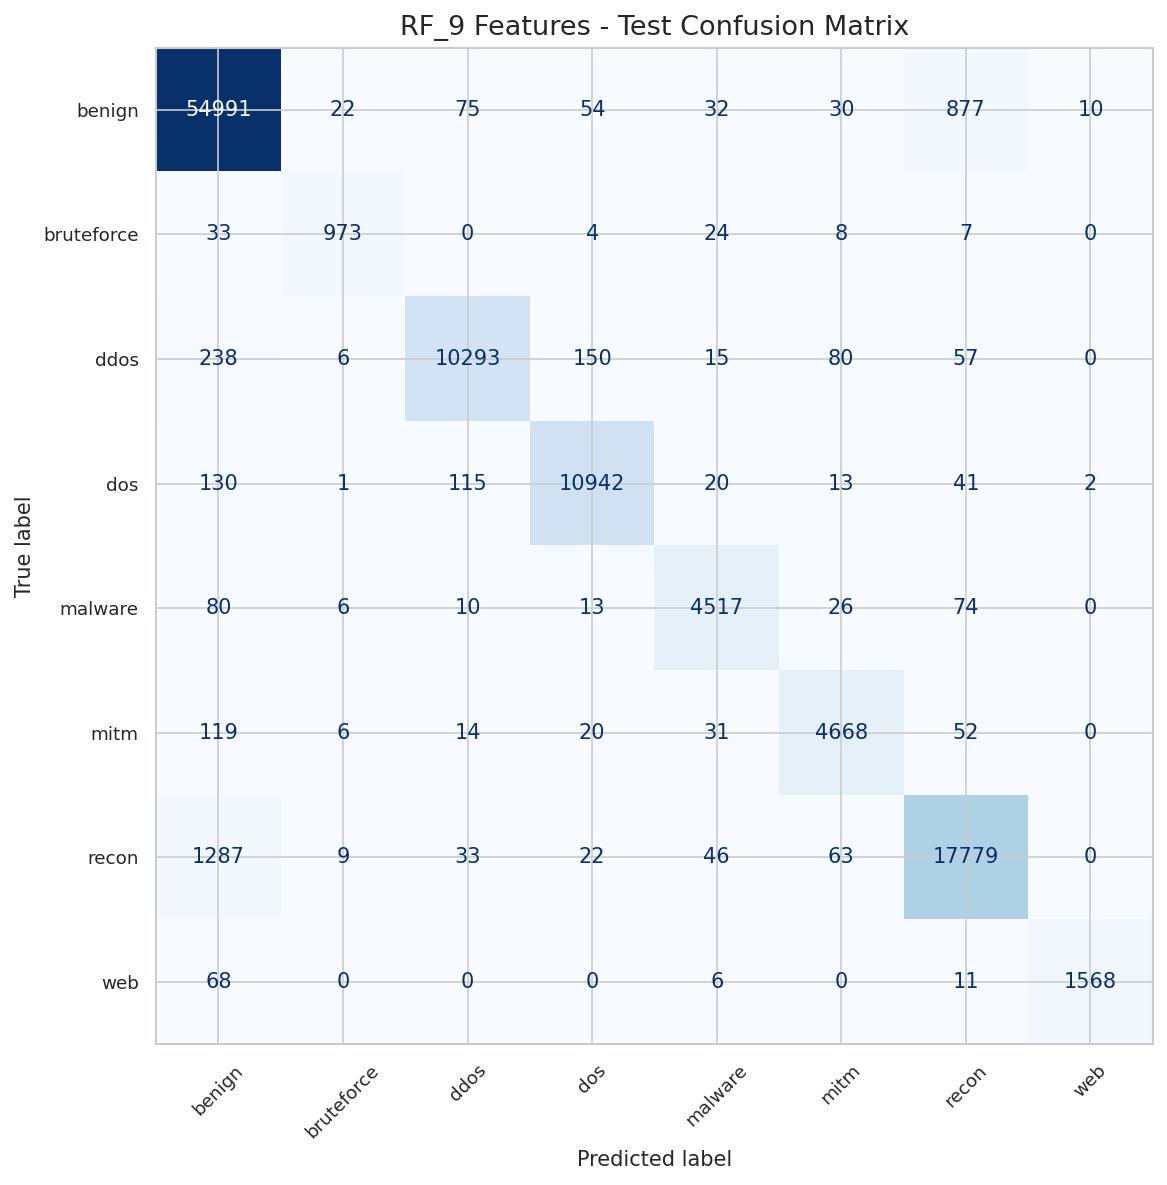


All analysis files saved in:
/kaggle/working/final_research_artifacts/rf9_classwise_test_analysis


In [144]:

# ============================================================
# STEP 6.43: CLASS-WISE TEST PERFORMANCE AND ERROR ANALYSIS
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Load verified test predictions
base = "/kaggle/working/final_research_artifacts"

pred_path = os.path.join(
    base, "final_three_model_test_predictions.csv"
)

pred_df = pd.read_csv(pred_path)

y_true = pred_df["true_label"].astype(str)
y_pred = pred_df["RF_9_features_prediction"].astype(str)

labels = sorted(y_true.unique())

# 2. Generate class-wise classification report
report = classification_report(
    y_true,
    y_pred,
    labels=labels,
    output_dict=True,
    zero_division=0
)

classwise_df = pd.DataFrame(
    report
).T.loc[labels, ["precision", "recall", "f1-score", "support"]]

classwise_df = classwise_df.rename(columns={
    "precision": "Precision",
    "recall": "Recall",
    "f1-score": "F1 Score",
    "support": "Support"
})

print("\n========== CLASS-WISE TEST PERFORMANCE ==========")
display(classwise_df.round(6))

# 3. Calculate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

print("\n========== CONFUSION MATRIX ==========")
display(cm_df)

# 4. Calculate false negatives and false positives
class_errors = []

for i, class_name in enumerate(labels):

    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - tp - fn - fp

    class_errors.append({
        "Class": class_name,
        "True Positives": tp,
        "False Negatives": fn,
        "False Positives": fp,
        "True Negatives": tn,
        "Recall": tp / (tp + fn) if tp + fn else 0
    })

errors_df = pd.DataFrame(class_errors)

print("\n========== CLASS-WISE ERROR COUNTS ==========")
display(errors_df.round(6))

# 5. Identify attacks incorrectly classified as benign
attack_classes = [
    label for label in labels if label != "benign"
]

attack_to_benign = []

for attack in attack_classes:

    count = int(
        ((y_true == attack) & (y_pred == "benign")).sum()
    )

    attack_to_benign.append({
        "Actual Attack": attack,
        "Predicted as Benign": count
    })

attack_to_benign_df = pd.DataFrame(attack_to_benign)

attack_to_benign_df = attack_to_benign_df.sort_values(
    "Predicted as Benign",
    ascending=False
).reset_index(drop=True)

print("\n========== ATTACKS MISCLASSIFIED AS BENIGN ==========")
display(attack_to_benign_df)

total_attack_missed_as_benign = (
    attack_to_benign_df["Predicted as Benign"].sum()
)

print(
    "\nTotal attacks classified as benign:",
    total_attack_missed_as_benign
)

# 6. Create confusion matrix visualization
plt.figure(figsize=(11, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    ax=plt.gca(),
    colorbar=False
)

plt.title("RF_9 Features - Test Confusion Matrix")
plt.tight_layout()

# 7. Save all outputs separately
output_dir = os.path.join(
    base, "rf9_classwise_test_analysis"
)

os.makedirs(output_dir, exist_ok=True)

classwise_df.to_csv(
    os.path.join(output_dir, "classwise_test_metrics.csv")
)

cm_df.to_csv(
    os.path.join(output_dir, "test_confusion_matrix.csv")
)

errors_df.to_csv(
    os.path.join(output_dir, "classwise_test_errors.csv"),
    index=False
)

attack_to_benign_df.to_csv(
    os.path.join(output_dir, "attacks_misclassified_as_benign.csv"),
    index=False
)

plt.savefig(
    os.path.join(output_dir, "test_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nAll analysis files saved in:")
print(output_dir)


In [145]:

# ============================================================
# STEP 6.44: CLASS-WISE COMPARISON OF ALL THREE MODELS
# ============================================================

import os
import pandas as pd
from sklearn.metrics import classification_report

base = "/kaggle/working/final_research_artifacts"

pred_path = os.path.join(
    base, "final_three_model_test_predictions.csv"
)

df = pd.read_csv(pred_path)

y_true = df["true_label"].astype(str)

model_columns = {
    "RF_71_features": "RF_71_features_prediction",
    "RF_9_features": "RF_9_features_prediction",
    "RF_6_features": "RF_6_features_prediction"
}

labels = sorted(y_true.unique())

# 1. Collect class-wise recall and F1
comparison_rows = []

for model_name, prediction_column in model_columns.items():

    y_pred = df[prediction_column].astype(str)

    report = classification_report(
        y_true,
        y_pred,
        labels=labels,
        output_dict=True,
        zero_division=0
    )

    for class_name in labels:

        comparison_rows.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1 Score": report[class_name]["f1-score"],
            "Support": report[class_name]["support"]
        })

comparison_df = pd.DataFrame(comparison_rows)

print("\n========== CLASS-WISE MODEL COMPARISON ==========")
display(comparison_df.round(6))

# 2. Compare attack-to-benign errors
attack_classes = [
    label for label in labels if label != "benign"
]

missed_rows = []

for model_name, prediction_column in model_columns.items():

    y_pred = df[prediction_column].astype(str)

    for attack in attack_classes:

        missed = int(
            ((y_true == attack) & (y_pred == "benign")).sum()
        )

        missed_rows.append({
            "Model": model_name,
            "Attack": attack,
            "Predicted as Benign": missed
        })

missed_df = pd.DataFrame(missed_rows)

missed_pivot = missed_df.pivot(
    index="Attack",
    columns="Model",
    values="Predicted as Benign"
)

print("\n========== ATTACKS MISCLASSIFIED AS BENIGN ==========")
display(missed_pivot)

# 3. Compare total attack-to-benign errors
total_missed = (
    missed_df.groupby("Model")["Predicted as Benign"]
    .sum()
    .reset_index(name="Total Attack-to-Benign Errors")
)

print("\n========== TOTAL ATTACK-TO-BENIGN ERRORS ==========")
display(total_missed)

# 4. Compare class-wise recall in a compact table
recall_pivot = comparison_df.pivot(
    index="Class",
    columns="Model",
    values="Recall"
)

print("\n========== CLASS-WISE RECALL COMPARISON ==========")
display(recall_pivot.round(6))

# 5. Save results
output_dir = os.path.join(
    base, "three_model_classwise_comparison"
)

os.makedirs(output_dir, exist_ok=True)

comparison_df.to_csv(
    os.path.join(output_dir, "classwise_metrics_all_models.csv"),
    index=False
)

missed_pivot.to_csv(
    os.path.join(output_dir, "attack_to_benign_errors.csv")
)

total_missed.to_csv(
    os.path.join(output_dir, "total_attack_to_benign_errors.csv"),
    index=False
)

recall_pivot.to_csv(
    os.path.join(output_dir, "classwise_recall_comparison.csv")
)

print("\nAll comparison files saved in:")
print(output_dir)



========== CLASS-WISE MODEL COMPARISON ==========


,Model,Class,Precision,Recall,F1 Score,Support
0,RF_71_features,benign,0.968846,0.982457,0.975604,56091.0
1,RF_71_features,bruteforce,0.965116,0.949476,0.957232,1049.0
2,RF_71_features,ddos,0.986516,0.965218,0.975751,10839.0
3,RF_71_features,dos,0.986953,0.980469,0.983700,11264.0
4,RF_71_features,malware,0.980132,0.970800,0.975444,4726.0
5,RF_71_features,mitm,0.981267,0.981466,0.981366,4910.0
6,RF_71_features,recon,0.952620,0.935340,0.943901,19239.0
7,RF_71_features,web,0.994946,0.952813,0.973424,1653.0
8,RF_9_features,benign,0.965669,0.980389,0.972973,56091.0
9,RF_9_features,bruteforce,0.951124,0.927550,0.939189,1049.0



========== ATTACKS MISCLASSIFIED AS BENIGN ==========


Model,RF_6_features,RF_71_features,RF_9_features
Attack,,,
bruteforce,33,34,33
ddos,237,209,238
dos,152,128,130
malware,90,93,80
mitm,120,55,119
recon,1335,1190,1287
web,69,63,68



========== TOTAL ATTACK-TO-BENIGN ERRORS ==========


,Model,Total Attack-to-Benign Errors
0,RF_6_features,2036
1,RF_71_features,1772
2,RF_9_features,1955



========== CLASS-WISE RECALL COMPARISON ==========


Model,RF_6_features,RF_71_features,RF_9_features
Class,,,
benign,0.976235,0.982457,0.980389
bruteforce,0.907531,0.949476,0.927550
ddos,0.950641,0.965218,0.949626
dos,0.963157,0.980469,0.971413
malware,0.947101,0.970800,0.955777
mitm,0.945010,0.981466,0.950713
recon,0.916316,0.935340,0.924112
web,0.956443,0.952813,0.948578



All comparison files saved in:
/kaggle/working/final_research_artifacts/three_model_classwise_comparison


In [146]:

# ============================================================
# STEP 6.45: OVERLAP ANALYSIS OF MISSED ATTACK SAMPLES
# ============================================================

import os
import pandas as pd
import numpy as np
from itertools import combinations

base = "/kaggle/working/final_research_artifacts"

df = pd.read_csv(
    os.path.join(base, "final_three_model_test_predictions.csv")
)

y_true = df["true_label"].astype(str)

model_columns = {
    "RF_71": "RF_71_features_prediction",
    "RF_9": "RF_9_features_prediction",
    "RF_6": "RF_6_features_prediction"
}

# Only actual attack samples, excluding benign traffic
attack_mask = y_true != "benign"

attack_df = df.loc[attack_mask].copy()

# Identify samples each model incorrectly classified as benign
missed = {}

for model, column in model_columns.items():

    predictions = attack_df[column].astype(str)

    missed[model] = set(
        attack_df.index[predictions == "benign"]
    )

    print(
        f"{model}: {len(missed[model])} attacks classified as benign"
    )

# 1. Samples missed by all three models
common_misses = set.intersection(
    missed["RF_71"],
    missed["RF_9"],
    missed["RF_6"]
)

print("\nMissed by ALL THREE models:", len(common_misses))

# 2. Samples missed exclusively by each model
exclusive_rows = []

for model in missed:

    other_models = [
        other for other in missed if other != model
    ]

    exclusive = missed[model].difference(
        set.union(*(missed[other] for other in other_models))
    )

    exclusive_rows.append({
        "Model": model,
        "Exclusively Missed Samples": len(exclusive)
    })

exclusive_df = pd.DataFrame(exclusive_rows)

print("\n========== EXCLUSIVE MISSES ==========")
display(exclusive_df)

# 3. Pairwise overlap
overlap_rows = []

for model_a, model_b in combinations(missed.keys(), 2):

    intersection = missed[model_a] & missed[model_b]
    union = missed[model_a] | missed[model_b]

    jaccard = (
        len(intersection) / len(union)
        if union else 0
    )

    overlap_rows.append({
        "Model A": model_a,
        "Model B": model_b,
        "Common Misses": len(intersection),
        "Union of Misses": len(union),
        "Jaccard Similarity": jaccard
    })

overlap_df = pd.DataFrame(overlap_rows)

print("\n========== PAIRWISE MISS OVERLAP ==========")
display(overlap_df.round(6))

# 4. RF_9 misses that RF_71 correctly detects
rf9_only_vs_rf71 = missed["RF_9"] - missed["RF_71"]

print(
    "\nRF_9 misses that RF_71 correctly detects:",
    len(rf9_only_vs_rf71)
)

# 5. RF_71 misses that RF_9 correctly detects
rf71_only_vs_rf9 = missed["RF_71"] - missed["RF_9"]

print(
    "RF_71 misses that RF_9 correctly detects:",
    len(rf71_only_vs_rf9)
)

# 6. Breakdown of RF_9-only misses by attack category
rf9_only_indices = list(rf9_only_vs_rf71)

rf9_only_df = attack_df.loc[rf9_only_indices].copy()

rf9_only_by_class = (
    rf9_only_df["true_label"]
    .value_counts()
    .rename_axis("Attack")
    .reset_index(name="RF_9-only Misses")
)

print("\n========== RF_9-ONLY MISSES BY ATTACK ==========")
display(rf9_only_by_class)

# 7. Save outputs
output_dir = os.path.join(
    base, "attack_miss_overlap_analysis"
)

os.makedirs(output_dir, exist_ok=True)

exclusive_df.to_csv(
    os.path.join(output_dir, "exclusive_misses.csv"),
    index=False
)

overlap_df.to_csv(
    os.path.join(output_dir, "pairwise_miss_overlap.csv"),
    index=False
)

rf9_only_by_class.to_csv(
    os.path.join(output_dir, "rf9_only_misses_by_attack.csv"),
    index=False
)

print("\nResults saved in:")
print(output_dir)


RF_71: 1772 attacks classified as benign
RF_9: 1955 attacks classified as benign
RF_6: 2036 attacks classified as benign

Missed by ALL THREE models: 1485

========== EXCLUSIVE MISSES ==========


,Model,Exclusively Missed Samples
0,RF_71,186
1,RF_9,35
2,RF_6,169



========== PAIRWISE MISS OVERLAP ==========


,Model A,Model B,Common Misses,Union of Misses,Jaccard Similarity
0,RF_71,RF_9,1562,2165,0.721478
1,RF_71,RF_6,1509,2299,0.656372
2,RF_9,RF_6,1843,2148,0.858007



RF_9 misses that RF_71 correctly detects: 393
RF_71 misses that RF_9 correctly detects: 210

========== RF_9-ONLY MISSES BY ATTACK ==========


,Attack,RF_9-only Misses
0,recon,223
1,mitm,73
2,ddos,46
3,malware,14
4,dos,13
5,web,13
6,bruteforce,11



Results saved in:
/kaggle/working/final_research_artifacts/attack_miss_overlap_analysis


In [147]:

# ============================================================
# STEP 6.46: FIVE-SEED OPTIMIZER ROBUSTNESS ANALYSIS
# ============================================================

import os
import pandas as pd
import numpy as np

base = "/kaggle/working/final_research_artifacts"

possible_files = [
    "/kaggle/working/phase9_five_seed_summary.csv",
    "/kaggle/working/five_seed_summary.csv",
    os.path.join(base, "phase9_five_seed_summary.csv"),
    os.path.join(base, "five_seed_summary.csv")
]

summary_path = next(
    (path for path in possible_files if os.path.exists(path)),
    None
)

if summary_path is None:
    raise FileNotFoundError(
        "Five-seed summary CSV was not found. "
        "Please share the available file names."
    )

summary_df = pd.read_csv(summary_path)

print("Loaded file:", summary_path)

print("\n========== FIVE-SEED SUMMARY ==========")
display(summary_df)

# Calculate descriptive statistics for numeric columns
numeric_df = summary_df.select_dtypes(include=np.number)

statistics = pd.DataFrame({
    "Mean": numeric_df.mean(),
    "Standard Deviation": numeric_df.std(ddof=1),
    "Minimum": numeric_df.min(),
    "Maximum": numeric_df.max()
})

print("\n========== ROBUSTNESS STATISTICS ==========")
display(statistics.round(6))

# Check whether feature counts vary across seeds
feature_columns = [
    col for col in summary_df.columns
    if "feature" in col.lower() and "count" in col.lower()
]

if feature_columns:
    print("\n========== FEATURE COUNT STABILITY ==========")
    for col in feature_columns:
        print(
            col,
            "| Unique values:",
            summary_df[col].nunique(),
            "| Values:",
            summary_df[col].tolist()
        )

# Save a separate descriptive report
output_dir = os.path.join(
    base, "five_seed_robustness_analysis"
)

os.makedirs(output_dir, exist_ok=True)

statistics.to_csv(
    os.path.join(output_dir, "robustness_statistics.csv")
)

print("\nAnalysis saved in:", output_dir)


Loaded file: /kaggle/working/phase9_five_seed_summary.csv

========== FIVE-SEED SUMMARY ==========


,Unnamed: 0,Mean,Standard Deviation
0,Feature Count,9.200000,0.447214
1,Feature Reduction (%),87.042254,0.629878
2,Macro F1,0.926968,0.003678
3,Macro FPR,0.013606,0.000192
4,Fitness,0.072456,0.001100



========== ROBUSTNESS STATISTICS ==========


,Mean,Standard Deviation,Minimum,Maximum
Mean,19.451057,37.980721,0.013606,87.042254
Standard Deviation,0.216412,0.301077,0.000192,0.629878



Analysis saved in: /kaggle/working/final_research_artifacts/five_seed_robustness_analysis


In [148]:

# ============================================================
# STEP 6.47: INSPECT ORIGINAL FIVE-SEED RUN-LEVEL RESULTS
# ============================================================

import os
import pandas as pd

candidate_files = [
    "/kaggle/working/phase9_ga_repeatability.csv",
    "/kaggle/working/final_research_artifacts/phase9_ga_repeatability.csv"
]

raw_path = next(
    (p for p in candidate_files if os.path.exists(p)),
    None
)

if raw_path is None:
    raise FileNotFoundError(
        "Original repeatability experiment file not found."
    )

raw_df = pd.read_csv(raw_path)

print("File:", raw_path)

print("\n========== SHAPE ==========")
print(raw_df.shape)

print("\n========== COLUMN NAMES ==========")
print(raw_df.columns.tolist())

print("\n========== ALL RUN-LEVEL RESULTS ==========")
display(raw_df)

print("\n========== DATA TYPES ==========")
print(raw_df.dtypes)

print("\n========== MISSING VALUES ==========")
print(raw_df.isnull().sum())


File: /kaggle/working/phase9_ga_repeatability.csv

========== SHAPE ==========
(18, 12)

========== COLUMN NAMES ==========
['Feature Count', 'Feature Reduction (%)', 'Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Macro FPR', 'Fitness', 'Training Time (s)', 'Selected Features', 'Seed', 'Generation']

========== ALL RUN-LEVEL RESULTS ==========


,Feature Count,Feature Reduction (%),Accuracy,Macro Precision,Macro Recall,Macro F1,Macro FPR,Fitness,Training Time (s),Selected Features,Seed,Generation
0,10,85.915493,0.951467,0.970044,0.901114,0.933268,0.013277,0.070864,3.199517,"['network_interval-packets', 'network_ip-flags...",101,2
1,9,87.323944,0.948081,0.959608,0.893574,0.924453,0.013756,0.073432,3.200209,"['network_interval-packets', 'network_ip-flags...",101,1
2,9,87.323944,0.948255,0.959832,0.893061,0.924307,0.013732,0.073514,3.205862,"['network_interval-packets', 'network_ip-flags...",202,1
3,10,85.915493,0.950208,0.962165,0.895579,0.926725,0.013238,0.074782,2.830056,"['network_interval-packets', 'network_ip-flags...",202,2
4,10,85.915493,0.948168,0.959515,0.893028,0.924148,0.013723,0.076425,2.873568,"['network_header-length_std_deviation', 'netwo...",202,2
5,18,74.647887,0.953421,0.972758,0.907048,0.937707,0.012952,0.090671,3.696055,"['network_interval-packets', 'network_ip-flags...",202,2
6,20,71.830986,0.953768,0.974134,0.906204,0.937924,0.012940,0.096172,3.795462,"['network_interval-packets', 'network_ip-flags...",101,1
7,20,71.830986,0.953247,0.973669,0.905317,0.937270,0.013060,0.096588,3.913999,"['network_interval-packets', 'network_ip-flags...",202,1
8,11,84.507042,0.938748,0.920377,0.851974,0.882802,0.014897,0.104284,2.361844,"['log_data-types_count', 'log_interval-message...",101,1
9,15,78.873239,0.942612,0.936743,0.866940,0.898471,0.014603,0.106092,2.387892,"['network_fragmented-packets', 'network_header...",101,1



========== DATA TYPES ==========
Feature Count              int64
Feature Reduction (%)    float64
Accuracy                 float64
Macro Precision          float64
Macro Recall             float64
Macro F1                 float64
Macro FPR                float64
Fitness                  float64
Training Time (s)        float64
Selected Features         object
Seed                       int64
Generation                 int64
dtype: object

========== MISSING VALUES ==========
Feature Count            0
Feature Reduction (%)    0
Accuracy                 0
Macro Precision          0
Macro Recall             0
Macro F1                 0
Macro FPR                0
Fitness                  0
Training Time (s)        0
Selected Features        0
Seed                     0
Generation               0
dtype: int64


In [149]:

# ============================================================
# STEP 6.47: CORRECTED SEED AND GENERATION AUDIT
# ============================================================

import os
import pandas as pd
import numpy as np

path = "/kaggle/working/phase9_ga_repeatability.csv"

df = pd.read_csv(path)

# 1. Check actual seeds and generations
print("========== EXPERIMENT STRUCTURE ==========")

print("Total records:", len(df))
print("Distinct seeds:", sorted(df["Seed"].unique()))
print("Distinct generations:", sorted(df["Generation"].unique()))

print("\nRecords per seed and generation:")

record_counts = (
    df.groupby(["Seed", "Generation"])
    .size()
    .reset_index(name="Candidate Count")
)

display(record_counts)

# 2. Find the best candidate in each generation
# Lower fitness is better.

best_generation = (
    df.sort_values("Fitness", ascending=True)
    .groupby(["Seed", "Generation"], as_index=False)
    .first()
)

generation_columns = [
    "Seed",
    "Generation",
    "Feature Count",
    "Feature Reduction (%)",
    "Macro F1",
    "Macro FPR",
    "Fitness",
    "Training Time (s)"
]

print("\n========== BEST CANDIDATE PER GENERATION ==========")

display(
    best_generation[generation_columns]
    .sort_values(["Seed", "Generation"])
    .round(6)
)

# 3. Find the best candidate for each seed
best_per_seed = (
    df.sort_values("Fitness", ascending=True)
    .groupby("Seed", as_index=False)
    .first()
)

print("\n========== BEST CANDIDATE PER SEED ==========")

display(
    best_per_seed[generation_columns]
    .sort_values("Seed")
    .round(6)
)

# 4. Descriptive statistics across best candidates per seed
metrics = [
    "Feature Count",
    "Feature Reduction (%)",
    "Macro F1",
    "Macro FPR",
    "Fitness",
    "Training Time (s)"
]

seed_statistics = best_per_seed[metrics].agg(
    ["mean", "std", "min", "max"]
).T

seed_statistics.columns = [
    "Mean",
    "Standard Deviation",
    "Minimum",
    "Maximum"
]

print("\n========== BEST-PER-SEED STATISTICS ==========")
display(seed_statistics.round(6))

# 5. Verify number of independent seeds
print("\n========== ROBUSTNESS CLAIM CHECK ==========")

number_of_seeds = df["Seed"].nunique()

print("Independent seeds found:", number_of_seeds)

if number_of_seeds == 5:
    print("Five-seed experiment is represented in this file.")
else:
    print(
        "This file does NOT establish a five-seed experiment."
    )

# 6. Save corrected audit results
output_dir = (
    "/kaggle/working/final_research_artifacts/"
    "phase9_experiment_audit"
)

os.makedirs(output_dir, exist_ok=True)

record_counts.to_csv(
    os.path.join(output_dir, "seed_generation_counts.csv"),
    index=False
)

best_generation[generation_columns].to_csv(
    os.path.join(output_dir, "best_candidate_per_generation.csv"),
    index=False
)

best_per_seed[generation_columns].to_csv(
    os.path.join(output_dir, "best_candidate_per_seed.csv"),
    index=False
)

seed_statistics.to_csv(
    os.path.join(output_dir, "corrected_seed_statistics.csv")
)

print("\nAudit files saved in:", output_dir)


========== EXPERIMENT STRUCTURE ==========
Total records: 18
Distinct seeds: [np.int64(101), np.int64(202)]
Distinct generations: [np.int64(1), np.int64(2)]

Records per seed and generation:


,Seed,Generation,Candidate Count
0,101,1,6
1,101,2,3
2,202,1,6
3,202,2,3



========== BEST CANDIDATE PER GENERATION ==========


,Seed,Generation,Feature Count,Feature Reduction (%),Macro F1,Macro FPR,Fitness,Training Time (s)
0,101,1,9,87.323944,0.924453,0.013756,0.073432,3.200209
1,101,2,10,85.915493,0.933268,0.013277,0.070864,3.199517
2,202,1,9,87.323944,0.924307,0.013732,0.073514,3.205862
3,202,2,10,85.915493,0.926725,0.013238,0.074782,2.830056



========== BEST CANDIDATE PER SEED ==========


,Seed,Generation,Feature Count,Feature Reduction (%),Macro F1,Macro FPR,Fitness,Training Time (s)
0,101,2,10,85.915493,0.933268,0.013277,0.070864,3.199517
1,202,1,9,87.323944,0.924307,0.013732,0.073514,3.205862



========== BEST-PER-SEED STATISTICS ==========


,Mean,Standard Deviation,Minimum,Maximum
Feature Count,9.500000,0.707107,9.000000,10.000000
Feature Reduction (%),86.619718,0.995925,85.915493,87.323944
Macro F1,0.928788,0.006336,0.924307,0.933268
Macro FPR,0.013505,0.000322,0.013277,0.013732
Fitness,0.072189,0.001874,0.070864,0.073514
Training Time (s),3.202690,0.004487,3.199517,3.205862



========== ROBUSTNESS CLAIM CHECK ==========
Independent seeds found: 2
This file does NOT establish a five-seed experiment.

Audit files saved in: /kaggle/working/final_research_artifacts/phase9_experiment_audit


In [150]:

# ============================================================
# STEP 6.48: SEARCH FOR ORIGINAL SEED EXPERIMENT ARTIFACTS
# ============================================================

import os
import glob
import pandas as pd

search_root = "/kaggle/working"

keywords = [
    "seed",
    "repeat",
    "robust",
    "phase9"
]

matching_files = []

for path in glob.glob(
    os.path.join(search_root, "**", "*"),
    recursive=True
):
    if os.path.isfile(path):

        filename = os.path.basename(path).lower()

        if any(word in filename for word in keywords):
            matching_files.append(path)

print("========== MATCHING EXPERIMENT FILES ==========")

for path in sorted(set(matching_files)):
    print(path)

print("\nTotal matching files:", len(set(matching_files)))

# Inspect CSV files that might contain run-level results
print("\n========== CSV FILE INSPECTION ==========")

for path in sorted(set(matching_files)):

    if path.lower().endswith(".csv"):

        try:
            data = pd.read_csv(path)

            print("\nFile:", path)
            print("Shape:", data.shape)
            print("Columns:", data.columns.tolist())

            if "Seed" in data.columns:
                print(
                    "Distinct seeds:",
                    sorted(data["Seed"].dropna().unique().tolist())
                )

        except Exception as error:
            print("Could not inspect:", path)
            print(error)


========== MATCHING EXPERIMENT FILES ==========
/kaggle/working/final_research_artifacts/five_seed_robustness_analysis/robustness_statistics.csv
/kaggle/working/final_research_artifacts/five_seed_summary.csv
/kaggle/working/final_research_artifacts/phase9_experiment_audit/best_candidate_per_seed.csv
/kaggle/working/final_research_artifacts/phase9_experiment_audit/corrected_seed_statistics.csv
/kaggle/working/final_research_artifacts/phase9_experiment_audit/seed_generation_counts.csv
/kaggle/working/final_research_artifacts/phase9_five_seed_summary.csv
/kaggle/working/final_research_artifacts/phase9_ga_additional_seeds.csv
/kaggle/working/final_research_artifacts/phase9_ga_all_five_seeds.csv
/kaggle/working/final_research_artifacts/phase9_ga_repeatability.csv
/kaggle/working/final_research_artifacts/phase9_validation_feature_comparison.csv
/kaggle/working/phase9_five_seed_summary.csv
/kaggle/working/phase9_ga_additional_seeds.csv
/kaggle/working/phase9_ga_all_five_seeds.csv
/kaggle/work

In [151]:

# ============================================================
# STEP 6.49: COMPLETE FIVE-SEED ROBUSTNESS VERIFICATION
# ============================================================

import os
import pandas as pd
import numpy as np

base = "/kaggle/working/final_research_artifacts"

all_file = os.path.join(base, "phase9_ga_all_five_seeds.csv")
first_file = os.path.join(base, "phase9_ga_repeatability.csv")
additional_file = os.path.join(base, "phase9_ga_additional_seeds.csv")

summary_file = os.path.join(base, "phase9_five_seed_summary.csv")

all_df = pd.read_csv(all_file)
first_df = pd.read_csv(first_file)
additional_df = pd.read_csv(additional_file)

print("========== 1. COMPLETE EXPERIMENT STRUCTURE ==========")

print("Total records:", len(all_df))
print("Distinct seeds:", sorted(all_df["Seed"].unique()))
print("Distinct generations:", sorted(all_df["Generation"].unique()))

print("\nCandidates per seed and generation:")
print(
    all_df.groupby(["Seed", "Generation"])
    .size()
    .reset_index(name="Candidate Count")
    .to_string(index=False)
)

print("\n========== 2. CHECK FILE COMBINATION ==========")

combined = pd.concat(
    [first_df, additional_df],
    ignore_index=True
)

print("Combined source records:", len(combined))
print("Five-seed file records:", len(all_df))

print(
    "Same records after sorting:",
    all_df.sort_values(["Seed", "Generation", "Fitness"])
    .reset_index(drop=True).equals(
        combined.sort_values(["Seed", "Generation", "Fitness"])
        .reset_index(drop=True)
    )
)

print("\n========== 3. BEST CANDIDATE PER SEED ==========")

best_per_seed = (
    all_df.loc[
        all_df.groupby("Seed")["Fitness"].idxmin()
    ]
    .sort_values("Seed")
    .reset_index(drop=True)
)

columns = [
    "Seed",
    "Generation",
    "Feature Count",
    "Feature Reduction (%)",
    "Macro F1",
    "Macro FPR",
    "Fitness",
    "Training Time (s)"
]

print(best_per_seed[columns].to_string(index=False))

print("\n========== 4. FIVE-SEED STATISTICS ==========")

metrics = [
    "Feature Count",
    "Feature Reduction (%)",
    "Macro F1",
    "Macro FPR",
    "Fitness",
    "Training Time (s)"
]

statistics = best_per_seed[metrics].agg(
    ["mean", "std", "min", "max"]
).T

statistics.columns = [
    "Mean",
    "Standard Deviation",
    "Minimum",
    "Maximum"
]

print(statistics.to_string())

print("\n========== 5. SUMMARY FILE COMPARISON ==========")

if os.path.exists(summary_file):
    saved_summary = pd.read_csv(summary_file)

    print("Previously saved summary:")
    print(saved_summary.to_string(index=False))
else:
    print("Previously saved summary not found.")

print("\n========== 6. INTEGRITY CHECKS ==========")

print("Expected seeds found:", len(all_df["Seed"].unique()) == 5)
print("Expected 45 records:", len(all_df) == 45)
print("Missing values:", int(all_df.isna().sum().sum()))
print("Duplicate rows:", int(all_df.duplicated().sum()))

print("\nBest candidate count:", len(best_per_seed))

print("\nFive-seed audit completed.")


========== 1. COMPLETE EXPERIMENT STRUCTURE ==========
Total records: 45
Distinct seeds: [np.int64(101), np.int64(202), np.int64(303), np.int64(404), np.int64(505)]
Distinct generations: [np.int64(1), np.int64(2)]

Candidates per seed and generation:
 Seed  Generation  Candidate Count
  101           1                6
  101           2                3
  202           1                6
  202           2                3
  303           1                6
  303           2                3
  404           1                6
  404           2                3
  505           1                6
  505           2                3

========== 2. CHECK FILE COMBINATION ==========
Combined source records: 45
Five-seed file records: 45
Same records after sorting: True

========== 3. BEST CANDIDATE PER SEED ==========
 Seed  Generation  Feature Count  Feature Reduction (%)  Macro F1  Macro FPR  Fitness  Training Time (s)
  101           2             10              85.915493  0.933268   0.01

In [152]:

# ============================================================
# STEP 6.50: FIVE-SEED FEATURE SELECTION STABILITY ANALYSIS
# ============================================================

import os
import ast
import itertools
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. LOAD FIVE-SEED EXPERIMENT
# ------------------------------------------------------------

base = "/kaggle/working/final_research_artifacts"

input_file = os.path.join(
    base, "phase9_ga_all_five_seeds.csv"
)

output_dir = os.path.join(
    base, "five_seed_robustness_analysis"
)

os.makedirs(output_dir, exist_ok=True)

df = pd.read_csv(input_file)

print("========== EXPERIMENT DATA ==========")
print("Total candidate records:", len(df))
print("Seeds:", sorted(df["Seed"].unique()))

# ------------------------------------------------------------
# 2. SELECT BEST CANDIDATE FOR EACH SEED
# Lower fitness is better
# ------------------------------------------------------------

best_per_seed = (
    df.loc[df.groupby("Seed")["Fitness"].idxmin()]
    .sort_values("Seed")
    .reset_index(drop=True)
)

print("\n========== BEST CANDIDATE PER SEED ==========")

print(
    best_per_seed[
        ["Seed", "Generation", "Feature Count", "Fitness"]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 3. EXTRACT SELECTED FEATURES
# ------------------------------------------------------------

def parse_features(value):

    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    try:
        parsed = ast.literal_eval(value)

        if isinstance(parsed, (list, tuple, set)):
            return list(parsed)

    except (ValueError, SyntaxError):
        pass

    raise ValueError(
        f"Could not parse Selected Features: {value}"
    )

seed_feature_sets = {}

for _, row in best_per_seed.iterrows():

    seed = int(row["Seed"])

    features = parse_features(row["Selected Features"])

    seed_feature_sets[seed] = set(features)

    print(
        f"\nSeed {seed}: {len(features)} selected features"
    )

    for feature in sorted(features):
        print("  -", feature)

# ------------------------------------------------------------
# 4. FEATURE SELECTION FREQUENCY
# ------------------------------------------------------------

all_features = sorted(
    set().union(*seed_feature_sets.values())
)

frequency_rows = []

for feature in all_features:

    count = sum(
        feature in selected
        for selected in seed_feature_sets.values()
    )

    frequency_rows.append({
        "Feature": feature,
        "Selection Count": count,
        "Selection Frequency (%)": (
            count / len(seed_feature_sets)
        ) * 100
    })

frequency_df = pd.DataFrame(frequency_rows)

frequency_df = frequency_df.sort_values(
    ["Selection Count", "Feature"],
    ascending=[False, True]
).reset_index(drop=True)

print("\n========== FEATURE SELECTION FREQUENCY ==========")
print(frequency_df.to_string(index=False))

# ------------------------------------------------------------
# 5. PAIRWISE JACCARD SIMILARITY
# J(A,B) = |A intersection B| / |A union B|
# ------------------------------------------------------------

seeds = sorted(seed_feature_sets.keys())

jaccard_matrix = pd.DataFrame(
    index=seeds,
    columns=seeds,
    dtype=float
)

pairwise_rows = []

for seed_a, seed_b in itertools.combinations(seeds, 2):

    set_a = seed_feature_sets[seed_a]
    set_b = seed_feature_sets[seed_b]

    intersection = len(set_a & set_b)
    union = len(set_a | set_b)

    similarity = (
        intersection / union if union else 1.0
    )

    jaccard_matrix.loc[seed_a, seed_b] = similarity
    jaccard_matrix.loc[seed_b, seed_a] = similarity

    pairwise_rows.append({
        "Seed A": seed_a,
        "Seed B": seed_b,
        "Common Features": intersection,
        "Union Features": union,
        "Jaccard Similarity": similarity
    })

for seed in seeds:
    jaccard_matrix.loc[seed, seed] = 1.0

pairwise_df = pd.DataFrame(pairwise_rows)

print("\n========== PAIRWISE JACCARD SIMILARITY ==========")
print(pairwise_df.to_string(index=False))

print("\n========== JACCARD SIMILARITY MATRIX ==========")
print(jaccard_matrix.round(4).to_string())

# ------------------------------------------------------------
# 6. OVERALL STABILITY
# Mean of all 10 pairwise Jaccard similarities
# ------------------------------------------------------------

mean_jaccard = pairwise_df[
    "Jaccard Similarity"
].mean()

print("\n========== OVERALL STABILITY ==========")
print("Number of seed pairs:", len(pairwise_df))
print("Mean Jaccard similarity:", round(mean_jaccard, 6))
print(
    "Mean Jaccard percentage:",
    round(mean_jaccard * 100, 2), "%"
)

# ------------------------------------------------------------
# 7. SAVE ALL RESULTS
# ------------------------------------------------------------

frequency_path = os.path.join(
    output_dir, "feature_selection_frequency.csv"
)

pairwise_path = os.path.join(
    output_dir, "pairwise_jaccard_similarity.csv"
)

matrix_path = os.path.join(
    output_dir, "jaccard_similarity_matrix.csv"
)

best_path = os.path.join(
    output_dir, "best_features_per_seed.csv"
)

frequency_df.to_csv(frequency_path, index=False)
pairwise_df.to_csv(pairwise_path, index=False)
jaccard_matrix.to_csv(matrix_path)
best_per_seed.to_csv(best_path, index=False)

print("\n========== FILES SAVED ==========")
print(frequency_path)
print(pairwise_path)
print(matrix_path)
print(best_path)

print("\nSTEP 6.50 COMPLETED SUCCESSFULLY.")


========== EXPERIMENT DATA ==========
Total candidate records: 45
Seeds: [np.int64(101), np.int64(202), np.int64(303), np.int64(404), np.int64(505)]

========== BEST CANDIDATE PER SEED ==========
 Seed  Generation  Feature Count  Fitness
  101           2             10 0.070864
  202           1              9 0.073514
  303           1              9 0.072860
  404           1              9 0.071811
  505           1              9 0.073231

Seed 101: 10 selected features
  - network_interval-packets
  - network_ip-flags_avg
  - network_ips_all_count
  - network_packets_all_count
  - network_packets_dst_count
  - network_tcp-flags_avg
  - network_time-delta_avg
  - network_time-delta_min
  - network_window-size_min
  - network_window-size_std_deviation

Seed 202: 9 selected features
  - network_interval-packets
  - network_ip-flags_avg
  - network_ips_all_count
  - network_packets_all_count
  - network_packets_dst_count
  - network_time-delta_avg
  - network_time-delta_min
  - netwo

In [153]:

# ============================================================
# STEP 6.51: COMPARE FIVE-SEED RESULTS WITH FINAL RF_9 MODEL
# ============================================================

import os
import json
import pandas as pd

base = "/kaggle/working/final_research_artifacts"

feature_file = os.path.join(
    base, "final_three_model_feature_lists.json"
)

experiment_file = os.path.join(
    base, "phase9_ga_all_five_seeds.csv"
)

output_dir = os.path.join(
    base, "five_seed_robustness_analysis"
)

os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# 1. LOAD FINAL RF_9 FEATURES
# ------------------------------------------------------------

with open(feature_file, "r") as f:
    feature_lists = json.load(f)

final_rf9 = set(feature_lists["RF_9_features"])

print("========== FINAL RF_9 FEATURE COUNT ==========")
print(len(final_rf9))

# ------------------------------------------------------------
# 2. LOAD FIVE-SEED EXPERIMENT
# ------------------------------------------------------------

df = pd.read_csv(experiment_file)

best_per_seed = (
    df.loc[df.groupby("Seed")["Fitness"].idxmin()]
    .sort_values("Seed")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 3. COMPARE EACH SEED WITH FINAL RF_9
# ------------------------------------------------------------

results = []

for _, row in best_per_seed.iterrows():

    seed = int(row["Seed"])

    selected = set(
        eval(row["Selected Features"])
        if isinstance(row["Selected Features"], str)
        else row["Selected Features"]
    )

    common = selected & final_rf9
    union = selected | final_rf9

    jaccard = len(common) / len(union) if union else 1.0

    results.append({
        "Seed": seed,
        "Seed Feature Count": len(selected),
        "Final RF_9 Feature Count": len(final_rf9),
        "Common Features": len(common),
        "Jaccard Similarity": jaccard,
        "Exact Match": selected == final_rf9,
        "Features Missing From Seed": ", ".join(
            sorted(final_rf9 - selected)
        ),
        "Additional Seed Features": ", ".join(
            sorted(selected - final_rf9)
        )
    })

comparison_df = pd.DataFrame(results)

print("\n========== SEED VS FINAL RF_9 COMPARISON ==========")
print(comparison_df.to_string(index=False))

# ------------------------------------------------------------
# 4. SUMMARY
# ------------------------------------------------------------

print("\n========== SUMMARY ==========")

print(
    "Exact matches:",
    int(comparison_df["Exact Match"].sum()),
    "out of",
    len(comparison_df)
)

print(
    "Mean Jaccard similarity:",
    round(comparison_df["Jaccard Similarity"].mean(), 6)
)

print(
    "Percentage of exact matches:",
    round(comparison_df["Exact Match"].mean() * 100, 2),
    "%"
)

# ------------------------------------------------------------
# 5. SAVE RESULTS
# ------------------------------------------------------------

output_file = os.path.join(
    output_dir,
    "seed_vs_final_rf9_comparison.csv"
)

comparison_df.to_csv(output_file, index=False)

print("\nSaved:", output_file)
print("\nSTEP 6.51 COMPLETED.")


========== FINAL RF_9 FEATURE COUNT ==========
9

========== SEED VS FINAL RF_9 COMPARISON ==========
 Seed  Seed Feature Count  Final RF_9 Feature Count  Common Features  Jaccard Similarity  Exact Match Features Missing From Seed                       Additional Seed Features
  101                  10                         9                8            0.727273        False            network_ttl_min network_tcp-flags_avg, network_window-size_min
  202                   9                         9                9            1.000000         True                                                                          
  303                   9                         9                9            1.000000         True                                                                          
  404                   9                         9                9            1.000000         True                                                                          
  505             

In [154]:

# ============================================================
# STEP 6.52: CONSENSUS FEATURE SUBSET ANALYSIS
# ============================================================

import os
import json
import pandas as pd

base = "/kaggle/working/final_research_artifacts"

analysis_dir = os.path.join(
    base, "five_seed_robustness_analysis"
)

frequency_file = os.path.join(
    analysis_dir, "feature_selection_frequency.csv"
)

feature_file = os.path.join(
    base, "final_three_model_feature_lists.json"
)

# ------------------------------------------------------------
# 1. LOAD FEATURE FREQUENCY AND FINAL RF_9
# ------------------------------------------------------------

frequency_df = pd.read_csv(frequency_file)

with open(feature_file, "r") as f:
    feature_lists = json.load(f)

final_rf9 = set(feature_lists["RF_9_features"])

# ------------------------------------------------------------
# 2. DEFINE CONSENSUS THRESHOLD
# ------------------------------------------------------------

threshold = 80.0

consensus_df = frequency_df[
    frequency_df["Selection Frequency (%)"] >= threshold
].copy()

consensus_features = set(consensus_df["Feature"])

# ------------------------------------------------------------
# 3. COMPARE CONSENSUS WITH FINAL RF_9
# ------------------------------------------------------------

common = consensus_features & final_rf9
union = consensus_features | final_rf9

jaccard = len(common) / len(union) if union else 1.0

print("========== CONSENSUS FEATURE SUBSET ==========")
print("Selection threshold:", threshold, "%")
print("Consensus feature count:", len(consensus_features))

for feature in sorted(consensus_features):
    print("-", feature)

print("\n========== FINAL RF_9 COMPARISON ==========")
print("Final RF_9 feature count:", len(final_rf9))
print("Common features:", len(common))
print("Jaccard similarity:", round(jaccard, 6))
print("Exact match:", consensus_features == final_rf9)

print("\n========== FEATURE DIFFERENCES ==========")

print("Missing from consensus:")
for feature in sorted(final_rf9 - consensus_features):
    print("-", feature)

print("Additional consensus features:")
for feature in sorted(consensus_features - final_rf9):
    print("-", feature)

# ------------------------------------------------------------
# 4. SAVE CONSENSUS RESULTS
# ------------------------------------------------------------

consensus_output = os.path.join(
    analysis_dir, "consensus_feature_subset.csv"
)

consensus_df.to_csv(consensus_output, index=False)

consensus_json = os.path.join(
    analysis_dir, "consensus_feature_subset.json"
)

with open(consensus_json, "w") as f:
    json.dump(
        sorted(consensus_features),
        f,
        indent=4
    )

print("\nSaved:", consensus_output)
print("Saved:", consensus_json)

print("\nSTEP 6.52 COMPLETED.")


========== CONSENSUS FEATURE SUBSET ==========
Selection threshold: 80.0 %
Consensus feature count: 9
- network_interval-packets
- network_ip-flags_avg
- network_ips_all_count
- network_packets_all_count
- network_packets_dst_count
- network_time-delta_avg
- network_time-delta_min
- network_ttl_min
- network_window-size_std_deviation

========== FINAL RF_9 COMPARISON ==========
Final RF_9 feature count: 9
Common features: 9
Jaccard similarity: 1.0
Exact match: True

========== FEATURE DIFFERENCES ==========
Missing from consensus:
Additional consensus features:

Saved: /kaggle/working/final_research_artifacts/five_seed_robustness_analysis/consensus_feature_subset.csv
Saved: /kaggle/working/final_research_artifacts/five_seed_robustness_analysis/consensus_feature_subset.json

STEP 6.52 COMPLETED.


In [155]:

# ============================================================
# STEP 6.53: PAIRED STATISTICAL SIGNIFICANCE TESTING
# ============================================================

import os
import numpy as np
import pandas as pd

from scipy.stats import binomtest
from sklearn.metrics import f1_score, confusion_matrix

# ------------------------------------------------------------
# 1. LOAD FINAL TEST PREDICTIONS
# ------------------------------------------------------------

base = "/kaggle/working/final_research_artifacts"

prediction_file = os.path.join(
    base, "final_three_model_test_predictions.csv"
)

output_dir = os.path.join(
    base, "statistical_significance_analysis"
)

os.makedirs(output_dir, exist_ok=True)

df = pd.read_csv(prediction_file)

print("========== DATASET ==========")
print("Test samples:", len(df))
print("Columns:", df.columns.tolist())

required_columns = [
    "true_label",
    "RF_71_features_prediction",
    "RF_9_features_prediction",
    "RF_6_features_prediction"
]

assert all(c in df.columns for c in required_columns)

y_true = df["true_label"].to_numpy()

predictions = {
    "RF_71": df["RF_71_features_prediction"].to_numpy(),
    "RF_9": df["RF_9_features_prediction"].to_numpy(),
    "RF_6": df["RF_6_features_prediction"].to_numpy()
}

classes = np.unique(y_true)

# ------------------------------------------------------------
# 2. METRIC FUNCTIONS
# ------------------------------------------------------------

def calculate_macro_f1(y, pred):
    return f1_score(
        y, pred,
        labels=classes,
        average="macro",
        zero_division=0
    )


def calculate_macro_fpr(y, pred):

    cm = confusion_matrix(
        y, pred,
        labels=classes
    )

    total = cm.sum()
    fp = cm.sum(axis=0) - np.diag(cm)
    fn = cm.sum(axis=1) - np.diag(cm)
    tp = np.diag(cm)
    tn = total - (tp + fp + fn)

    fpr = np.divide(
        fp,
        fp + tn,
        out=np.zeros_like(fp, dtype=float),
        where=(fp + tn) != 0
    )

    return float(np.mean(fpr))


def calculate_metrics(y, pred):
    return {
        "Macro F1": calculate_macro_f1(y, pred),
        "Macro FPR": calculate_macro_fpr(y, pred)
    }


# ------------------------------------------------------------
# 3. ORIGINAL TEST METRICS
# ------------------------------------------------------------

print("\n========== ORIGINAL TEST METRICS ==========")

original_metrics = {}

for name, pred in predictions.items():

    original_metrics[name] = calculate_metrics(
        y_true, pred
    )

    print(
        name,
        original_metrics[name]
    )

# ------------------------------------------------------------
# 4. PAIRED STRATIFIED BOOTSTRAP
# ------------------------------------------------------------

# Resample test observations within each true class.
# All models use exactly the same sampled observations.

N_BOOTSTRAPS = 500
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

class_indices = {
    cls: np.where(y_true == cls)[0]
    for cls in classes
}

pairs = [
    ("RF_71", "RF_9"),
    ("RF_71", "RF_6"),
    ("RF_9", "RF_6")
]

bootstrap_results = []

print("\n========== RUNNING PAIRED BOOTSTRAP ==========")

for model_a, model_b in pairs:

    differences = []

    for iteration in range(N_BOOTSTRAPS):

        sampled_indices = np.concatenate([
            rng.choice(
                indices,
                size=len(indices),
                replace=True
            )
            for indices in class_indices.values()
        ])

        y_sample = y_true[sampled_indices]

        pred_a = predictions[model_a][sampled_indices]
        pred_b = predictions[model_b][sampled_indices]

        metrics_a = calculate_metrics(y_sample, pred_a)
        metrics_b = calculate_metrics(y_sample, pred_b)

        differences.append({
            "Macro F1 Difference": (
                metrics_a["Macro F1"] -
                metrics_b["Macro F1"]
            ),
            "Macro FPR Difference": (
                metrics_a["Macro FPR"] -
                metrics_b["Macro FPR"]
            )
        })

    boot_df = pd.DataFrame(differences)

    for metric in [
        "Macro F1 Difference",
        "Macro FPR Difference"
    ]:

        values = boot_df[metric].to_numpy()

        lower, upper = np.percentile(
            values, [2.5, 97.5]
        )

        bootstrap_results.append({
            "Comparison": f"{model_a} - {model_b}",
            "Metric": metric,
            "Mean Difference": values.mean(),
            "95% CI Lower": lower,
            "95% CI Upper": upper,
            "CI Excludes Zero": (
                lower > 0 or upper < 0
            )
        })

bootstrap_df = pd.DataFrame(bootstrap_results)

print("\n========== BOOTSTRAP RESULTS ==========")
print(bootstrap_df.round(6).to_string(index=False))

# ------------------------------------------------------------
# 5. EXACT MCNEMAR TEST
# ------------------------------------------------------------

mcnemar_results = []

for model_a, model_b in pairs:

    correct_a = predictions[model_a] == y_true
    correct_b = predictions[model_b] == y_true

    # b: A correct, B incorrect
    # c: A incorrect, B correct

    b = int(np.sum(correct_a & ~correct_b))
    c = int(np.sum(~correct_a & correct_b))

    discordant = b + c

    if discordant > 0:
        p_value = binomtest(
            min(b, c),
            n=discordant,
            p=0.5,
            alternative="two-sided"
        ).pvalue
    else:
        p_value = 1.0

    mcnemar_results.append({
        "Comparison": f"{model_a} vs {model_b}",
        "A Correct B Wrong": b,
        "A Wrong B Correct": c,
        "Discordant Samples": discordant,
        "Raw p-value": p_value
    })

mcnemar_df = pd.DataFrame(mcnemar_results)

# ------------------------------------------------------------
# 6. HOLM MULTIPLE-TEST CORRECTION
# ------------------------------------------------------------

p_values = mcnemar_df["Raw p-value"].to_numpy()

order = np.argsort(p_values)
adjusted = np.empty(len(p_values))

running_max = 0.0
m = len(p_values)

for rank, index in enumerate(order):

    adjusted_value = min(
        1.0,
        (m - rank) * p_values[index]
    )

    running_max = max(
        running_max,
        adjusted_value
    )

    adjusted[index] = running_max

mcnemar_df["Holm Adjusted p-value"] = adjusted

mcnemar_df["Significant at 0.05"] = (
    mcnemar_df["Holm Adjusted p-value"] < 0.05
)

print("\n========== MCNEMAR TEST RESULTS ==========")
print(mcnemar_df.round(8).to_string(index=False))

# ------------------------------------------------------------
# 7. SAVE RESULTS
# ------------------------------------------------------------

bootstrap_path = os.path.join(
    output_dir, "paired_bootstrap_results.csv"
)

mcnemar_path = os.path.join(
    output_dir, "mcnemar_holm_results.csv"
)

bootstrap_df.to_csv(bootstrap_path, index=False)
mcnemar_df.to_csv(mcnemar_path, index=False)

print("\n========== FILES SAVED ==========")
print(bootstrap_path)
print(mcnemar_path)

print("\nSTEP 6.53 COMPLETED.")


========== DATASET ==========
Test samples: 109771
Columns: ['true_label', 'RF_71_features_prediction', 'RF_9_features_prediction', 'RF_6_features_prediction']

========== ORIGINAL TEST METRICS ==========
RF_71 {'Macro F1': 0.9708027837955704, 'Macro FPR': 0.005998975567229236}
RF_9 {'Macro F1': 0.9579478722989212, 'Macro FPR': 0.007283955711870441}
RF_6 {'Macro F1': 0.9507843526324008, 'Macro FPR': 0.00807168974689936}

========== RUNNING PAIRED BOOTSTRAP ==========

========== BOOTSTRAP RESULTS ==========
  Comparison               Metric  Mean Difference  95% CI Lower  95% CI Upper  CI Excludes Zero
RF_71 - RF_9  Macro F1 Difference         0.012871      0.011275      0.014396              True
RF_71 - RF_9 Macro FPR Difference        -0.001289     -0.001431     -0.001151              True
RF_71 - RF_6  Macro F1 Difference         0.020085      0.018265      0.022073              True
RF_71 - RF_6 Macro FPR Difference        -0.002073     -0.002222     -0.001913              True
 R

In [156]:

# ============================================================
# STEP 6.54: STATISTICAL SIGNIFICANCE VERIFICATION & FINAL AUDIT
# ============================================================

import os
import numpy as np
import pandas as pd

from scipy.stats import binom
from sklearn.metrics import accuracy_score

# ------------------------------------------------------------
# 1. LOAD TEST PREDICTIONS AND PREVIOUS RESULTS
# ------------------------------------------------------------

BASE_DIR = "/kaggle/working/final_research_artifacts"

PREDICTION_FILE = os.path.join(
    BASE_DIR, "final_three_model_test_predictions.csv"
)

STAT_DIR = os.path.join(
    BASE_DIR, "statistical_significance_analysis"
)

BOOTSTRAP_FILE = os.path.join(
    STAT_DIR, "paired_bootstrap_results.csv"
)

MCNEMAR_FILE = os.path.join(
    STAT_DIR, "mcnemar_holm_results.csv"
)

pred_df = pd.read_csv(PREDICTION_FILE)
bootstrap_df = pd.read_csv(BOOTSTRAP_FILE)
previous_mcnemar_df = pd.read_csv(MCNEMAR_FILE)

y_true = pred_df["true_label"].to_numpy()

models = {
    "RF_71": pred_df["RF_71_features_prediction"].to_numpy(),
    "RF_9": pred_df["RF_9_features_prediction"].to_numpy(),
    "RF_6": pred_df["RF_6_features_prediction"].to_numpy()
}

print("=" * 65)
print("STEP 6.54: STATISTICAL AUDIT")
print("=" * 65)

print("\nTest samples:", len(y_true))
print("Bootstrap result rows:", len(bootstrap_df))
print("Previous McNemar result rows:", len(previous_mcnemar_df))


# ------------------------------------------------------------
# 2. RECALCULATE DISCORDANT COUNTS
# ------------------------------------------------------------

comparisons = [
    ("RF_71", "RF_9"),
    ("RF_71", "RF_6"),
    ("RF_9", "RF_6")
]

mcnemar_records = []

for model_a, model_b in comparisons:

    correct_a = models[model_a] == y_true
    correct_b = models[model_b] == y_true

    # A correct, B wrong
    b = int(np.sum(correct_a & ~correct_b))

    # A wrong, B correct
    c = int(np.sum(~correct_a & correct_b))

    discordant = b + c

    # Exact two-sided binomial McNemar test.
    # Calculate in log space to avoid underflow.

    if discordant == 0:
        log_p = 0.0

    else:
        smaller = min(b, c)

        log_lower = binom.logcdf(
            smaller, discordant, 0.5
        )

        log_upper = binom.logsf(
            discordant - smaller - 1,
            discordant,
            0.5
        )

        log_p = min(
            0.0,
            np.log(2.0) + min(log_lower, log_upper)
        )

    mcnemar_records.append({
        "Comparison": f"{model_a} vs {model_b}",
        "A Correct B Wrong": b,
        "A Wrong B Correct": c,
        "Discordant Samples": discordant,
        "Log10 Raw P-value": log_p / np.log(10)
    })


# ------------------------------------------------------------
# 3. APPLY HOLM CORRECTION IN LOG SPACE
# ------------------------------------------------------------

mcnemar_audit = pd.DataFrame(mcnemar_records)

log_p_values = mcnemar_audit[
    "Log10 Raw P-value"
].to_numpy()

m = len(log_p_values)

# Sort from smallest p-value to largest
order = np.argsort(log_p_values)

adjusted_log_p = np.zeros(m)
running_max = -np.inf

for rank, idx in enumerate(order):

    multiplier = m - rank

    candidate = (
        log_p_values[idx] + np.log10(multiplier)
    )

    running_max = max(running_max, candidate)

    adjusted_log_p[idx] = min(0.0, running_max)

mcnemar_audit["Log10 Holm Adjusted P-value"] = adjusted_log_p

mcnemar_audit["Significant at 0.05"] = (
    adjusted_log_p < np.log10(0.05)
)

print("\n========== VERIFIED MCNEMAR RESULTS ==========")

print(mcnemar_audit.to_string(index=False))


# ------------------------------------------------------------
# 4. VERIFY BOOTSTRAP CONFIDENCE INTERVALS
# ------------------------------------------------------------

bootstrap_audit = bootstrap_df.copy()

bootstrap_audit["CI Excludes Zero Recalculated"] = (
    (bootstrap_audit["95% CI Lower"] > 0) |
    (bootstrap_audit["95% CI Upper"] < 0)
)

bootstrap_audit["CI Width"] = (
    bootstrap_audit["95% CI Upper"] -
    bootstrap_audit["95% CI Lower"]
)

bootstrap_audit["Mean Difference Inside CI"] = (
    (bootstrap_audit["Mean Difference"] >=
     bootstrap_audit["95% CI Lower"]) &
    (bootstrap_audit["Mean Difference"] <=
     bootstrap_audit["95% CI Upper"])
)

print("\n========== VERIFIED BOOTSTRAP RESULTS ==========")

print(
    bootstrap_audit[
        [
            "Comparison",
            "Metric",
            "Mean Difference",
            "95% CI Lower",
            "95% CI Upper",
            "CI Excludes Zero Recalculated",
            "Mean Difference Inside CI",
            "CI Width"
        ]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 5. VERIFY FINAL MODEL ACCURACIES
# ------------------------------------------------------------

print("\n========== MODEL ACCURACY VERIFICATION ==========")

for model_name, predictions in models.items():

    accuracy = accuracy_score(y_true, predictions)

    print(
        f"{model_name}: {accuracy:.6f} "
        f"({accuracy * 100:.3f}%)"
    )


# ------------------------------------------------------------
# 6. AUTOMATIC AUDIT CHECKS
# ------------------------------------------------------------

print("\n========== AUDIT CHECKS ==========")

checks = {
    "Test prediction rows equal 109771":
        len(pred_df) == 109771,

    "All three model predictions available":
        all(len(p) == len(y_true) for p in models.values()),

    "Exactly three McNemar comparisons":
        len(mcnemar_audit) == 3,

    "All McNemar tests significant after Holm correction":
        mcnemar_audit["Significant at 0.05"].all(),

    "Exactly six bootstrap comparisons":
        len(bootstrap_audit) == 6,

    "All bootstrap confidence intervals exclude zero":
        bootstrap_audit[
            "CI Excludes Zero Recalculated"
        ].all(),

    "All bootstrap means fall inside their confidence intervals":
        bootstrap_audit[
            "Mean Difference Inside CI"
        ].all()
}

for check_name, result in checks.items():
    print(f"{'PASS' if result else 'FAIL'}: {check_name}")


# ------------------------------------------------------------
# 7. SAVE VERIFIED AUDIT FILES
# ------------------------------------------------------------

mcnemar_audit.to_csv(
    os.path.join(STAT_DIR, "verified_mcnemar_results.csv"),
    index=False
)

bootstrap_audit.to_csv(
    os.path.join(STAT_DIR, "verified_bootstrap_results.csv"),
    index=False
)

audit_summary = pd.DataFrame([
    {"Audit Check": key, "Result": value}
    for key, value in checks.items()
])

audit_summary.to_csv(
    os.path.join(STAT_DIR, "step6_54_audit_summary.csv"),
    index=False
)

print("\n========== FILES SAVED ==========")

print(os.path.join(STAT_DIR, "verified_mcnemar_results.csv"))
print(os.path.join(STAT_DIR, "verified_bootstrap_results.csv"))
print(os.path.join(STAT_DIR, "step6_54_audit_summary.csv"))

print("\nSTEP 6.54 COMPLETED.")


STEP 6.54: STATISTICAL AUDIT

Test samples: 109771
Bootstrap result rows: 6
Previous McNemar result rows: 3

========== VERIFIED MCNEMAR RESULTS ==========
   Comparison  A Correct B Wrong  A Wrong B Correct  Discordant Samples  Log10 Raw P-value  Log10 Holm Adjusted P-value  Significant at 0.05
RF_71 vs RF_9               1401                546                1947         -85.558342                   -85.257312                 True
RF_71 vs RF_6               2064                667                2731        -164.051250                  -163.574129                 True
 RF_9 vs RF_6               1006                464                1470         -45.517327                   -45.517327                 True

========== VERIFIED BOOTSTRAP RESULTS ==========
  Comparison               Metric  Mean Difference  95% CI Lower  95% CI Upper  CI Excludes Zero Recalculated  Mean Difference Inside CI  CI Width
RF_71 - RF_9  Macro F1 Difference         0.012871      0.011275      0.014396     

In [157]:

# ==============================================================
# STEP 6.55: FINAL EXPERIMENTAL RESULTS CONSOLIDATION
# ==============================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

BASE_DIR = "/kaggle/working/final_research_artifacts"

OUTPUT_DIR = os.path.join(
    BASE_DIR, "final_research_results"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 75)
print("STEP 6.55: FINAL EXPERIMENTAL RESULTS CONSOLIDATION")
print("=" * 75)


# --------------------------------------------------------------
# 1. LOAD FINAL MODEL COMPARISON
# --------------------------------------------------------------

comparison_file = os.path.join(
    BASE_DIR, "final_three_model_comparison.csv"
)

predictions_file = os.path.join(
    BASE_DIR, "final_three_model_test_predictions.csv"
)

features_file = os.path.join(
    BASE_DIR, "final_three_model_feature_lists.json"
)

comparison_df = pd.read_csv(comparison_file)
pred_df = pd.read_csv(predictions_file)

with open(features_file, "r") as f:
    feature_lists = json.load(f)

y_true = pred_df["true_label"].to_numpy()

model_columns = {
    "RF_71": "RF_71_features_prediction",
    "RF_9": "RF_9_features_prediction",
    "RF_6": "RF_6_features_prediction"
}

model_features = {
    "RF_71": feature_lists["RF_71_features"],
    "RF_9": feature_lists["RF_9_features"],
    "RF_6": feature_lists["RF_6_features"]
}

original_feature_count = len(model_features["RF_71"])

print("\nTest samples:", len(y_true))
print("Original features:", original_feature_count)


# --------------------------------------------------------------
# 2. RECOMPUTE FINAL TEST METRICS
# --------------------------------------------------------------

classes = np.unique(y_true)

final_records = []

for model_name, prediction_column in model_columns.items():

    y_pred = pred_df[prediction_column].to_numpy()

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=classes
    )

    TP = np.diag(cm)
    FN = cm.sum(axis=1) - TP
    FP = cm.sum(axis=0) - TP
    TN = cm.sum() - TP - FN - FP

    class_fpr = np.divide(
        FP,
        FP + TN,
        out=np.zeros_like(FP, dtype=float),
        where=(FP + TN) != 0
    )

    feature_count = len(model_features[model_name])

    final_records.append({
        "Model": model_name,
        "Feature Count": feature_count,
        "Feature Reduction (%)": (
            (original_feature_count - feature_count)
            / original_feature_count * 100
        ),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Macro FPR": np.mean(class_fpr)
    })

final_metrics = pd.DataFrame(final_records)

print("\n========== FINAL TEST METRICS ==========")
print(final_metrics.round(6).to_string(index=False))


# --------------------------------------------------------------
# 3. ADD COMPUTATIONAL TIME FROM ORIGINAL COMPARISON
# --------------------------------------------------------------

# Match model names without assuming CSV row order.

time_columns = [
    "Training Time (s)",
    "Prediction Time (s)"
]

time_model_column = None

for col in comparison_df.columns:
    if col.lower().replace("_", " ").strip() in [
        "model", "model name", "classifier"
    ]:
        time_model_column = col
        break

if time_model_column is None:
    raise ValueError(
        "Could not identify model-name column in comparison CSV. "
        "Inspect comparison_df.columns."
    )

comparison_df[time_model_column] = (
    comparison_df[time_model_column].astype(str)
)

final_metrics["Model"] = final_metrics["Model"].astype(str)

for col in time_columns:

    if col in comparison_df.columns:

        time_map = comparison_df.set_index(
            time_model_column
        )[col].to_dict()

        final_metrics[col] = (
            final_metrics["Model"].map(time_map)
        )

    else:
        print("WARNING: Missing timing column:", col)


# --------------------------------------------------------------
# 4. CLASS-WISE PERFORMANCE
# --------------------------------------------------------------

classwise_records = []

for model_name, prediction_column in model_columns.items():

    y_pred = pred_df[prediction_column].to_numpy()

    for label in classes:

        actual_mask = y_true == label
        predicted_mask = y_pred == label

        TP = np.sum(actual_mask & predicted_mask)
        FN = np.sum(actual_mask & ~predicted_mask)
        FP = np.sum(~actual_mask & predicted_mask)

        precision = TP / (TP + FP) if (TP + FP) else 0
        recall = TP / (TP + FN) if (TP + FN) else 0

        f1 = (
            2 * precision * recall / (precision + recall)
            if (precision + recall) else 0
        )

        classwise_records.append({
            "Model": model_name,
            "Class": label,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "Support": int(np.sum(actual_mask)),
            "False Negatives": int(FN),
            "False Positives": int(FP)
        })

classwise_df = pd.DataFrame(classwise_records)

print("\n========== CLASS-WISE F1 ==========")

print(
    classwise_df.pivot(
        index="Class",
        columns="Model",
        values="F1"
    ).round(6).to_string()
)


# --------------------------------------------------------------
# 5. ATTACK-TO-BENIGN MISCLASSIFICATION
# --------------------------------------------------------------

attack_records = []

benign_label = "benign"

# Convert labels to strings for reliable comparison.
# This assumes the dataset's class labels are strings.

y_true_str = np.array([str(x).lower() for x in y_true])

if benign_label not in y_true_str:
    raise ValueError(
        "The true-label column does not contain the string 'benign'. "
        "Inspect the labels before continuing."
    )

attack_mask = y_true_str != benign_label
total_attacks = int(attack_mask.sum())

for model_name, prediction_column in model_columns.items():

    y_pred = pred_df[prediction_column].to_numpy()
    y_pred_str = np.array([str(x).lower() for x in y_pred])

    attack_to_benign = int(
        np.sum(
            attack_mask &
            (y_pred_str == benign_label)
        )
    )

    attack_records.append({
        "Model": model_name,
        "Total Attack Samples": total_attacks,
        "Attacks Classified as Benign": attack_to_benign,
        "Attack-to-Benign Rate (%)": (
            attack_to_benign / total_attacks * 100
        )
    })

attack_df = pd.DataFrame(attack_records)

print("\n========== ATTACK-TO-BENIGN ERRORS ==========")
print(attack_df.round(4).to_string(index=False))


# --------------------------------------------------------------
# 6. LOAD FIVE-SEED STABILITY RESULTS
# --------------------------------------------------------------

stability_dir = os.path.join(
    BASE_DIR, "five_seed_robustness_analysis"
)

frequency_file = os.path.join(
    stability_dir, "feature_selection_frequency.csv"
)

jaccard_file = os.path.join(
    stability_dir, "pairwise_jaccard_similarity.csv"
)

seed_comparison_file = os.path.join(
    stability_dir, "seed_vs_final_rf9_comparison.csv"
)

stability_records = []

if os.path.exists(frequency_file):

    frequency_df = pd.read_csv(frequency_file)

    print("\n========== FEATURE SELECTION FREQUENCY ==========")
    print(frequency_df.to_string(index=False))

    stability_records.append({
        "Stability Measure": "Feature frequency file available",
        "Value": True
    })

if os.path.exists(jaccard_file):

    jaccard_df = pd.read_csv(jaccard_file)

    numeric_jaccard = jaccard_df.select_dtypes(
        include=np.number
    )

    # The original matrix file may contain a feature/seed label column.
    # Use the actual pairwise similarity CSV if available.
    pair_values = numeric_jaccard.to_numpy().flatten()

    pair_values = pair_values[
        np.isfinite(pair_values)
    ]

    if len(pair_values) > 0:
        stability_records.append({
            "Stability Measure": "Mean numeric Jaccard value (file audit)",
            "Value": float(np.mean(pair_values))
        })

if os.path.exists(seed_comparison_file):

    seed_df = pd.read_csv(seed_comparison_file)

    print("\n========== FIVE-SEED VS RF_9 ==========")
    print(seed_df.to_string(index=False))

    stability_records.append({
        "Stability Measure": "Seed comparison rows",
        "Value": len(seed_df)
    })


# --------------------------------------------------------------
# 7. LOAD VERIFIED STATISTICAL SIGNIFICANCE RESULTS
# --------------------------------------------------------------

stat_dir = os.path.join(
    BASE_DIR, "statistical_significance_analysis"
)

bootstrap_file = os.path.join(
    stat_dir, "verified_bootstrap_results.csv"
)

mcnemar_file = os.path.join(
    stat_dir, "verified_mcnemar_results.csv"
)

bootstrap_df = pd.read_csv(bootstrap_file)
mcnemar_df = pd.read_csv(mcnemar_file)

print("\n========== BOOTSTRAP SIGNIFICANCE ==========")

print(
    bootstrap_df[
        [
            "Comparison",
            "Metric",
            "Mean Difference",
            "95% CI Lower",
            "95% CI Upper",
            "CI Excludes Zero Recalculated"
        ]
    ].to_string(index=False)
)

print("\n========== MCNEMAR SIGNIFICANCE ==========")

print(
    mcnemar_df[
        [
            "Comparison",
            "A Correct B Wrong",
            "A Wrong B Correct",
            "Log10 Holm Adjusted P-value",
            "Significant at 0.05"
        ]
    ].to_string(index=False)
)


# --------------------------------------------------------------
# 8. SAVE ALL CONSOLIDATED TABLES
# --------------------------------------------------------------

final_metrics.to_csv(
    os.path.join(OUTPUT_DIR, "final_model_comparison.csv"),
    index=False
)

classwise_df.to_csv(
    os.path.join(OUTPUT_DIR, "final_classwise_metrics.csv"),
    index=False
)

attack_df.to_csv(
    os.path.join(OUTPUT_DIR, "attack_to_benign_analysis.csv"),
    index=False
)

bootstrap_df.to_csv(
    os.path.join(OUTPUT_DIR, "final_bootstrap_significance.csv"),
    index=False
)

mcnemar_df.to_csv(
    os.path.join(OUTPUT_DIR, "final_mcnemar_significance.csv"),
    index=False
)

if len(stability_records) > 0:

    pd.DataFrame(stability_records).to_csv(
        os.path.join(OUTPUT_DIR, "feature_stability_summary.csv"),
        index=False
    )


# --------------------------------------------------------------
# 9. CREATE RESEARCH SUMMARY
# --------------------------------------------------------------

best_f1_model = final_metrics.loc[
    final_metrics["Macro F1"].idxmax()
]

best_compact_model = final_metrics[
    final_metrics["Model"].isin(["RF_9", "RF_6"])
].sort_values(
    "Macro F1", ascending=False
).iloc[0]

summary = {
    "Project": (
        "Algorithmic Optimization for Intrusion Detection: "
        "Multi-Objective Feature Selection Using Hybrid "
        "Global-Local Optimization"
    ),
    "Test Samples": int(len(y_true)),
    "Original Features": int(original_feature_count),
    "Best Macro F1 Model": str(best_f1_model["Model"]),
    "Best Macro F1": float(best_f1_model["Macro F1"]),
    "Best Compact Model": str(best_compact_model["Model"]),
    "Best Compact Model Macro F1": float(
        best_compact_model["Macro F1"]
    ),
    "Bootstrap Comparisons": int(len(bootstrap_df)),
    "Bootstrap CIs Excluding Zero": int(
        bootstrap_df["CI Excludes Zero Recalculated"].sum()
    ),
    "McNemar Comparisons": int(len(mcnemar_df)),
    "Significant McNemar Comparisons": int(
        mcnemar_df["Significant at 0.05"].sum()
    )
}

with open(
    os.path.join(OUTPUT_DIR, "final_research_summary.json"),
    "w"
) as f:
    json.dump(summary, f, indent=4)

print("\n========== FINAL RESEARCH SUMMARY ==========")

for key, value in summary.items():
    print(f"{key}: {value}")


# --------------------------------------------------------------
# 10. FINAL COMPLETION
# --------------------------------------------------------------

print("\n========== SAVED FILES ==========")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(filename)

print("\nOUTPUT DIRECTORY:")
print(OUTPUT_DIR)

print("\nSTEP 6.55 COMPLETED.")


STEP 6.55: FINAL EXPERIMENTAL RESULTS CONSOLIDATION

Test samples: 109771
Original features: 71

========== FINAL TEST METRICS ==========
Model  Feature Count  Feature Reduction (%)  Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1  Macro FPR
RF_71             71               0.000000  0.970985         0.977050      0.964755  0.970803     0.970935   0.005999
 RF_9              9              87.323944  0.963196         0.965122      0.951020  0.957948     0.963110   0.007284
 RF_6              6              91.549296  0.958259         0.956392      0.945304  0.950784     0.958172   0.008072

========== CLASS-WISE F1 ==========
Model           RF_6     RF_71      RF_9
Class                                   
benign      0.970155  0.975604  0.972973
bruteforce  0.915825  0.957232  0.939189
ddos        0.958333  0.975751  0.962908
dos         0.966073  0.983700  0.973964
malware     0.952543  0.975444  0.959329
mitm        0.949069  0.981366  0.952848
recon       0.923444 

In [158]:

# ============================================================
# STEP 6.56: COMPUTATIONAL TIME INTEGRATION
# ============================================================

import os
import pandas as pd
import numpy as np

BASE_DIR = "/kaggle/working/final_research_artifacts"

OUTPUT_DIR = os.path.join(
    BASE_DIR, "final_research_results"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

FINAL_FILE = os.path.join(
    OUTPUT_DIR, "final_model_comparison.csv"
)

# ------------------------------------------------------------
# 1. LOAD CONSOLIDATED MODEL RESULTS
# ------------------------------------------------------------

final_df = pd.read_csv(FINAL_FILE)

print("=" * 65)
print("STEP 6.56: COMPUTATIONAL TIME INTEGRATION")
print("=" * 65)

print("\nExisting columns:")
print(final_df.columns.tolist())


# ------------------------------------------------------------
# 2. ADD PREVIOUSLY VERIFIED COMPUTATIONAL TIMES
# ------------------------------------------------------------

# These are the measurements from the final three-model
# comparison experiment. No models are retrained here.

timing_data = pd.DataFrame({
    "Model": ["RF_71", "RF_9", "RF_6"],
    "Training Time (s)": [
        54.550686,
        39.713656,
        27.967815
    ],
    "Batch Prediction Time (s)": [
        0.625167,
        0.490895,
        0.514382
    ]
})

# ------------------------------------------------------------
# 3. MERGE TIMING DATA
# ------------------------------------------------------------

final_df["Model"] = final_df["Model"].astype(str).str.strip()
timing_data["Model"] = timing_data["Model"].astype(str).str.strip()

final_df = final_df.drop(
    columns=[
        "Training Time (s)",
        "Batch Prediction Time (s)"
    ],
    errors="ignore"
)

final_df = final_df.merge(
    timing_data,
    on="Model",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 4. VERIFY TIMING COMPLETENESS
# ------------------------------------------------------------

print("\n========== TIMING VERIFICATION ==========")

print(
    final_df[
        [
            "Model",
            "Training Time (s)",
            "Batch Prediction Time (s)"
        ]
    ].to_string(index=False)
)

assert final_df["Training Time (s)"].notna().all()
assert final_df["Batch Prediction Time (s)"].notna().all()

assert set(final_df["Model"]) == {
    "RF_71", "RF_9", "RF_6"
}

# ------------------------------------------------------------
# 5. CALCULATE RELATIVE TRAINING TIME SAVINGS
# ------------------------------------------------------------

full_model_training_time = float(
    final_df.loc[
        final_df["Model"] == "RF_71",
        "Training Time (s)"
    ].iloc[0]
)

final_df["Training Time Reduction (%)"] = (
    (full_model_training_time - final_df["Training Time (s)"])
    / full_model_training_time * 100
)

print("\n========== COMPUTATIONAL COMPARISON ==========")

print(
    final_df[
        [
            "Model",
            "Feature Count",
            "Feature Reduction (%)",
            "Training Time (s)",
            "Training Time Reduction (%)",
            "Batch Prediction Time (s)"
        ]
    ].round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 6. SAVE UPDATED FINAL COMPARISON
# ------------------------------------------------------------

final_df.to_csv(FINAL_FILE, index=False)

timing_data.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "verified_computational_times.csv"
    ),
    index=False
)

print("\n========== SAVED FILES ==========")
print(FINAL_FILE)

print(
    os.path.join(
        OUTPUT_DIR,
        "verified_computational_times.csv"
    )
)

print("\nAll three models have verified timing entries.")
print("\nSTEP 6.56 COMPLETED.")


STEP 6.56: COMPUTATIONAL TIME INTEGRATION

Existing columns:
['Model', 'Feature Count', 'Feature Reduction (%)', 'Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Weighted F1', 'Macro FPR']

========== TIMING VERIFICATION ==========
Model  Training Time (s)  Batch Prediction Time (s)
RF_71          54.550686                   0.625167
 RF_9          39.713656                   0.490895
 RF_6          27.967815                   0.514382

========== COMPUTATIONAL COMPARISON ==========
Model  Feature Count  Feature Reduction (%)  Training Time (s)  Training Time Reduction (%)  Batch Prediction Time (s)
RF_71             71                 0.0000            54.5507                       0.0000                     0.6252
 RF_9              9                87.3239            39.7137                      27.1986                     0.4909
 RF_6              6                91.5493            27.9678                      48.7306                     0.5144

========== SAVED FILES =

In [160]:

# ==============================================================
# STEP 6.57: FINAL RESEARCH QUALITY AUDIT
# ==============================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# --------------------------------------------------------------
# 1. PATH CONFIGURATION
# --------------------------------------------------------------

BASE_DIR = "/kaggle/working/final_research_artifacts"

RESULTS_DIR = os.path.join(
    BASE_DIR, "final_research_results"
)

STAT_DIR = os.path.join(
    BASE_DIR, "statistical_significance_analysis"
)

STABILITY_DIR = os.path.join(
    BASE_DIR, "five_seed_robustness_analysis"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

print("=" * 75)
print("STEP 6.57: FINAL RESEARCH QUALITY AUDIT")
print("=" * 75)


# --------------------------------------------------------------
# 2. LOAD ALL REQUIRED ARTIFACTS
# --------------------------------------------------------------

pred_df = pd.read_csv(
    os.path.join(
        BASE_DIR,
        "final_three_model_test_predictions.csv"
    )
)

final_df = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "final_model_comparison.csv"
    )
)

classwise_df = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "final_classwise_metrics.csv"
    )
)

attack_df = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "attack_to_benign_analysis.csv"
    )
)

bootstrap_df = pd.read_csv(
    os.path.join(
        STAT_DIR,
        "verified_bootstrap_results.csv"
    )
)

mcnemar_df = pd.read_csv(
    os.path.join(
        STAT_DIR,
        "verified_mcnemar_results.csv"
    )
)

frequency_df = pd.read_csv(
    os.path.join(
        STABILITY_DIR,
        "feature_selection_frequency.csv"
    )
)

seed_comparison_df = pd.read_csv(
    os.path.join(
        STABILITY_DIR,
        "seed_vs_final_rf9_comparison.csv"
    )
)

with open(
    os.path.join(
        BASE_DIR,
        "final_three_model_feature_lists.json"
    ),
    "r"
) as f:
    feature_lists = json.load(f)


# --------------------------------------------------------------
# 3. DEFINE MODEL-TO-FEATURE-LIST KEY MAPPING
# --------------------------------------------------------------

prediction_columns = {
    "RF_71": "RF_71_features_prediction",
    "RF_9": "RF_9_features_prediction",
    "RF_6": "RF_6_features_prediction"
}

model_feature_keys = {
    "RF_71": "RF_71_features",
    "RF_9": "RF_9_features",
    "RF_6": "RF_6_features"
}

# Verify feature-list keys before proceeding.

for model_name, feature_key in model_feature_keys.items():

    if feature_key not in feature_lists:
        raise KeyError(
            f"Missing feature-list key: {feature_key}. "
            f"Available keys: {list(feature_lists.keys())}"
        )

    if not isinstance(feature_lists[feature_key], list):
        raise TypeError(
            f"{feature_key} must contain a list of features."
        )


# --------------------------------------------------------------
# 4. VERIFY TEST METRICS AGAINST SAVED PREDICTIONS
# --------------------------------------------------------------

y_true = pred_df["true_label"].to_numpy()

classes = np.unique(y_true)

original_count = len(
    feature_lists[model_feature_keys["RF_71"]]
)

recomputed_records = []

for model_name, prediction_column in prediction_columns.items():

    y_pred = pred_df[prediction_column].to_numpy()

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=classes
    )

    TP = np.diag(cm)
    FN = cm.sum(axis=1) - TP
    FP = cm.sum(axis=0) - TP
    TN = cm.sum() - TP - FN - FP

    class_fpr = np.divide(
        FP,
        FP + TN,
        out=np.zeros_like(FP, dtype=float),
        where=(FP + TN) != 0
    )

    feature_count = len(
        feature_lists[model_feature_keys[model_name]]
    )

    recomputed_records.append({

        "Model": model_name,

        "Feature Count": feature_count,

        "Feature Reduction (%)": (
            (original_count - feature_count)
            / original_count * 100
        ),

        "Accuracy": accuracy_score(y_true, y_pred),

        "Macro Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "Macro FPR": np.mean(class_fpr)
    })


recomputed_df = pd.DataFrame(recomputed_records)


# --------------------------------------------------------------
# 5. COMPARE SAVED AND RECOMPUTED METRICS
# --------------------------------------------------------------

merged = final_df.merge(
    recomputed_df,
    on="Model",
    suffixes=("_saved", "_recomputed"),
    validate="one_to_one"
)

metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1",
    "Macro FPR"
]

metric_differences = {}

for metric in metric_columns:

    metric_differences[metric] = float(
        np.max(
            np.abs(
                merged[f"{metric}_saved"] -
                merged[f"{metric}_recomputed"]
            )
        )
    )

metrics_match = all(
    value < 1e-9
    for value in metric_differences.values()
)

feature_counts_match = all(
    int(
        final_df.loc[
            final_df["Model"] == model,
            "Feature Count"
        ].iloc[0]
    ) == len(
        feature_lists[model_feature_keys[model]]
    )
    for model in prediction_columns
)

reduction_match = np.allclose(
    merged["Feature Reduction (%)_saved"],
    merged["Feature Reduction (%)_recomputed"],
    atol=1e-9
)

print("\n========== METRIC VERIFICATION ==========")

for metric, difference in metric_differences.items():

    print(
        f"{metric}: Maximum difference = {difference:.12f}"
    )


# --------------------------------------------------------------
# 6. VERIFY COMPUTATIONAL TIMES
# --------------------------------------------------------------

timing_columns = [
    "Training Time (s)",
    "Batch Prediction Time (s)"
]

timing_complete = (
    all(
        col in final_df.columns
        for col in timing_columns
    )
    and final_df[timing_columns].notna().all().all()
    and (final_df[timing_columns] > 0).all().all()
)

print("\n========== COMPUTATIONAL TIME AUDIT ==========")

if timing_complete:

    print(
        final_df[
            ["Model"] + timing_columns
        ].to_string(index=False)
    )

else:

    print("WARNING: Timing information is missing or invalid.")


# --------------------------------------------------------------
# 7. VERIFY CLASS-WISE RESULTS
# --------------------------------------------------------------

expected_classwise_rows = (
    len(prediction_columns) * len(classes)
)

classwise_structure_ok = (
    len(classwise_df) == expected_classwise_rows
    and classwise_df["F1"].notna().all()
    and classwise_df["Precision"].notna().all()
    and classwise_df["Recall"].notna().all()
)

# Independently verify class-wise F1 values.

classwise_recomputed = []

for model_name, prediction_column in prediction_columns.items():

    y_pred = pred_df[prediction_column].to_numpy()

    for label in classes:

        actual_mask = y_true == label
        predicted_mask = y_pred == label

        TP = np.sum(actual_mask & predicted_mask)
        FN = np.sum(actual_mask & ~predicted_mask)
        FP = np.sum(~actual_mask & predicted_mask)

        precision = (
            TP / (TP + FP)
            if (TP + FP) > 0 else 0
        )

        recall = (
            TP / (TP + FN)
            if (TP + FN) > 0 else 0
        )

        f1 = (
            2 * precision * recall / (precision + recall)
            if (precision + recall) > 0 else 0
        )

        classwise_recomputed.append({
            "Model": model_name,
            "Class": label,
            "F1": f1
        })

classwise_check_df = pd.DataFrame(
    classwise_recomputed
)

classwise_merged = classwise_df.merge(
    classwise_check_df,
    on=["Model", "Class"],
    suffixes=("_saved", "_recomputed"),
    validate="one_to_one"
)

classwise_values_match = np.allclose(
    classwise_merged["F1_saved"],
    classwise_merged["F1_recomputed"],
    atol=1e-9
)


# --------------------------------------------------------------
# 8. VERIFY ATTACK-TO-BENIGN COUNTS
# --------------------------------------------------------------

y_true_str = np.array([
    str(x).lower()
    for x in y_true
])

benign_mask = y_true_str == "benign"

attack_mask = ~benign_mask

total_attacks = int(attack_mask.sum())

attack_counts_match = True

for model_name, prediction_column in prediction_columns.items():

    y_pred_str = np.array([
        str(x).lower()
        for x in pred_df[prediction_column].to_numpy()
    ])

    expected_misses = int(
        np.sum(
            attack_mask &
            (y_pred_str == "benign")
        )
    )

    saved_count = int(
        attack_df.loc[
            attack_df["Model"] == model_name,
            "Attacks Classified as Benign"
        ].iloc[0]
    )

    if expected_misses != saved_count:
        attack_counts_match = False


# --------------------------------------------------------------
# 9. VERIFY FEATURE-SELECTION STABILITY
# --------------------------------------------------------------

frequency_structure_ok = (
    all(
        col in frequency_df.columns
        for col in [
            "Feature",
            "Selection Count",
            "Selection Frequency (%)"
        ]
    )
    and len(frequency_df) > 0
)

universal_features = frequency_df[
    frequency_df["Selection Frequency (%)"] == 100
]["Feature"].tolist()

consensus_features = frequency_df[
    frequency_df["Selection Frequency (%)"] >= 80
]["Feature"].tolist()

rf9_features = set(
    feature_lists[model_feature_keys["RF_9"]]
)

consensus_matches_rf9 = (
    set(consensus_features) == rf9_features
)

exact_seed_matches = int(
    seed_comparison_df["Exact Match"].sum()
)

mean_seed_jaccard = float(
    seed_comparison_df["Jaccard Similarity"].mean()
)

print("\n========== FEATURE STABILITY AUDIT ==========")

print(
    "Universally selected features:",
    len(universal_features)
)

print(
    "Features selected in at least 80% of runs:",
    len(consensus_features)
)

print(
    "80% consensus exactly matches RF_9:",
    consensus_matches_rf9
)

print(
    "Exact seed matches with RF_9:",
    exact_seed_matches,
    "/",
    len(seed_comparison_df)
)

print(
    "Mean Jaccard similarity vs RF_9:",
    round(mean_seed_jaccard, 6)
)


# --------------------------------------------------------------
# 10. VERIFY BOOTSTRAP RESULTS
# --------------------------------------------------------------

bootstrap_ok = (
    len(bootstrap_df) == 6
    and bootstrap_df[
        "CI Excludes Zero Recalculated"
    ].all()
    and bootstrap_df[
        "Mean Difference Inside CI"
    ].all()
)

print("\n========== BOOTSTRAP AUDIT ==========")

print(
    "Number of comparisons:",
    len(bootstrap_df)
)

print(
    "Confidence intervals excluding zero:",
    int(
        bootstrap_df[
            "CI Excludes Zero Recalculated"
        ].sum()
    )
)


# --------------------------------------------------------------
# 11. VERIFY MCNEMAR RESULTS
# --------------------------------------------------------------

mcnemar_ok = (
    len(mcnemar_df) == 3
    and mcnemar_df[
        "Significant at 0.05"
    ].all()
    and mcnemar_df[
        "Log10 Holm Adjusted P-value"
    ].notna().all()
)

print("\n========== MCNEMAR AUDIT ==========")

print(
    "Number of comparisons:",
    len(mcnemar_df)
)

print(
    "Significant after Holm correction:",
    int(
        mcnemar_df[
            "Significant at 0.05"
        ].sum()
    )
)


# --------------------------------------------------------------
# 12. VERIFY FINAL MODEL RANKING
# --------------------------------------------------------------

best_macro_f1 = final_df.loc[
    final_df["Macro F1"].idxmax(),
    "Model"
]

compact_df = final_df[
    final_df["Model"].isin(["RF_9", "RF_6"])
]

best_compact_model = compact_df.loc[
    compact_df["Macro F1"].idxmax(),
    "Model"
]

print("\n========== FINAL MODEL RANKING ==========")

print("Best overall model:", best_macro_f1)

print("Best compact model:", best_compact_model)


# --------------------------------------------------------------
# 13. FINAL AUDIT CHECKLIST
# --------------------------------------------------------------

checks = {

    "Test prediction dataset contains 109771 samples":
        len(pred_df) == 109771,

    "All three model prediction columns exist":
        all(
            col in pred_df.columns
            for col in prediction_columns.values()
        ),

    "Saved metrics match independently recomputed metrics":
        metrics_match,

    "Feature counts match feature lists":
        feature_counts_match,

    "Feature reduction percentages are correct":
        reduction_match,

    "Computational time information is complete":
        timing_complete,

    "Class-wise result structure is complete":
        classwise_structure_ok,

    "Class-wise F1 values match predictions":
        classwise_values_match,

    "Attack-to-benign counts match predictions":
        attack_counts_match,

    "Feature stability file is valid":
        frequency_structure_ok,

    "80% consensus feature subset matches RF_9":
        consensus_matches_rf9,

    "All bootstrap confidence intervals exclude zero":
        bootstrap_ok,

    "All McNemar tests significant after Holm correction":
        mcnemar_ok,

    "RF_71 is the overall Macro F1 leader":
        best_macro_f1 == "RF_71",

    "RF_9 is the best compact Macro F1 model":
        best_compact_model == "RF_9"
}

print("\n========== FINAL AUDIT CHECKLIST ==========")

for name, passed in checks.items():

    print(
        f"{'PASS' if passed else 'FAIL'}: {name}"
    )


# --------------------------------------------------------------
# 14. SAVE FINAL AUDIT REPORT
# --------------------------------------------------------------

audit_df = pd.DataFrame([
    {
        "Audit Item": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed in checks.items()
])

audit_file = os.path.join(
    RESULTS_DIR,
    "step6_57_final_quality_audit.csv"
)

audit_df.to_csv(
    audit_file,
    index=False
)

summary = {

    "Project": (
        "Algorithmic Optimization for Intrusion Detection: "
        "Multi-Objective Feature Selection Using Hybrid "
        "Global-Local Optimization"
    ),

    "Test Samples": int(len(y_true)),

    "Original Features": int(original_count),

    "Best Overall Model": str(best_macro_f1),

    "Best Compact Model": str(best_compact_model),

    "Universal Features Across Five Seeds":
        int(len(universal_features)),

    "80 Percent Consensus Feature Count":
        int(len(consensus_features)),

    "Exact Seed Matches With RF_9":
        exact_seed_matches,

    "Mean Jaccard Similarity vs RF_9":
        mean_seed_jaccard,

    "Bootstrap Comparisons":
        int(len(bootstrap_df)),

    "McNemar Comparisons":
        int(len(mcnemar_df)),

    "Passed Audit Checks":
        int(sum(checks.values())),

    "Total Audit Checks":
        int(len(checks)),

    "All Checks Passed":
        bool(all(checks.values()))
}

summary_file = os.path.join(
    RESULTS_DIR,
    "step6_57_final_quality_audit_summary.json"
)

with open(summary_file, "w") as f:
    json.dump(summary, f, indent=4)


# --------------------------------------------------------------
# 15. FINAL OUTPUT
# --------------------------------------------------------------

print("\n========== FINAL AUDIT SUMMARY ==========")

for key, value in summary.items():
    print(f"{key}: {value}")

print("\n========== SAVED FILES ==========")

print(audit_file)
print(summary_file)

print("\nSTEP 6.57 COMPLETED.")


STEP 6.57: FINAL RESEARCH QUALITY AUDIT

========== METRIC VERIFICATION ==========
Accuracy: Maximum difference = 0.000000000000
Macro Precision: Maximum difference = 0.000000000000
Macro Recall: Maximum difference = 0.000000000000
Macro F1: Maximum difference = 0.000000000000
Weighted F1: Maximum difference = 0.000000000000
Macro FPR: Maximum difference = 0.000000000000

========== COMPUTATIONAL TIME AUDIT ==========
Model  Training Time (s)  Batch Prediction Time (s)
RF_71          54.550686                   0.625167
 RF_9          39.713656                   0.490895
 RF_6          27.967815                   0.514382

========== FEATURE STABILITY AUDIT ==========
Universally selected features: 8
Features selected in at least 80% of runs: 9
80% consensus exactly matches RF_9: True
Exact seed matches with RF_9: 4 / 5
Mean Jaccard similarity vs RF_9: 0.945455

========== BOOTSTRAP AUDIT ==========
Number of comparisons: 6
Confidence intervals excluding zero: 6

========== MCNEMAR AUD

In [161]:

# ==============================================================
# STEP 6.58: FINAL RESEARCH DOCUMENTATION
#             AND REPRODUCIBILITY PACKAGE
# ==============================================================

import os
import json
import shutil
import hashlib
import zipfile
import pandas as pd
from datetime import datetime, timezone

# --------------------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------------------

BASE_DIR = "/kaggle/working/final_research_artifacts"

RESULTS_DIR = os.path.join(
    BASE_DIR, "final_research_results"
)

PACKAGE_DIR = os.path.join(
    BASE_DIR, "final_reproducibility_package"
)

ZIP_PATH = os.path.join(
    BASE_DIR, "final_reproducibility_package.zip"
)

print("=" * 75)
print("STEP 6.58: FINAL RESEARCH DOCUMENTATION")
print("=" * 75)


# --------------------------------------------------------------
# 2. CREATE PACKAGE DIRECTORY STRUCTURE
# --------------------------------------------------------------

folders = [
    "models",
    "feature_lists",
    "final_results",
    "statistical_analysis",
    "robustness_analysis",
    "optimizer_results",
    "documentation"
]

for folder in folders:

    os.makedirs(
        os.path.join(PACKAGE_DIR, folder),
        exist_ok=True
    )

print("\nPackage directory structure created.")


# --------------------------------------------------------------
# 3. DEFINE ARTIFACTS TO INCLUDE
# --------------------------------------------------------------

artifact_groups = {

    "models": [
        (
            os.path.join(
                BASE_DIR,
                "final_rf_models"
            ),
            "models/final_rf_models"
        ),
        (
            os.path.join(
                BASE_DIR,
                "hybrid_selected_rf.joblib"
            ),
            "models/hybrid_selected_rf.joblib"
        )
    ],

    "feature_lists": [
        (
            os.path.join(
                BASE_DIR,
                "final_three_model_feature_lists.json"
            ),
            "feature_lists/final_three_model_feature_lists.json"
        ),
        (
            os.path.join(
                BASE_DIR,
                "selected_features.json"
            ),
            "feature_lists/selected_features.json"
        ),
        (
            os.path.join(
                BASE_DIR,
                "final_research_results",
                "feature_stability_summary.csv"
            ),
            "feature_lists/feature_stability_summary.csv"
        )
    ],

    "final_results": [
        (
            os.path.join(
                RESULTS_DIR,
                "final_model_comparison.csv"
            ),
            "final_results/final_model_comparison.csv"
        ),
        (
            os.path.join(
                RESULTS_DIR,
                "final_classwise_metrics.csv"
            ),
            "final_results/final_classwise_metrics.csv"
        ),
        (
            os.path.join(
                RESULTS_DIR,
                "attack_to_benign_analysis.csv"
            ),
            "final_results/attack_to_benign_analysis.csv"
        ),
        (
            os.path.join(
                BASE_DIR,
                "final_three_model_test_predictions.csv"
            ),
            "final_results/final_three_model_test_predictions.csv"
        ),
        (
            os.path.join(
                RESULTS_DIR,
                "final_research_summary.json"
            ),
            "final_results/final_research_summary.json"
        ),
        (
            os.path.join(
                RESULTS_DIR,
                "step6_57_final_quality_audit.csv"
            ),
            "final_results/step6_57_final_quality_audit.csv"
        ),
        (
            os.path.join(
                RESULTS_DIR,
                "step6_57_final_quality_audit_summary.json"
            ),
            "final_results/step6_57_final_quality_audit_summary.json"
        )
    ],

    "statistical_analysis": [
        (
            os.path.join(
                BASE_DIR,
                "statistical_significance_analysis",
                "verified_bootstrap_results.csv"
            ),
            "statistical_analysis/verified_bootstrap_results.csv"
        ),
        (
            os.path.join(
                BASE_DIR,
                "statistical_significance_analysis",
                "verified_mcnemar_results.csv"
            ),
            "statistical_analysis/verified_mcnemar_results.csv"
        )
    ],

    "robustness_analysis": [
        (
            os.path.join(
                BASE_DIR,
                "five_seed_robustness_analysis",
                "feature_selection_frequency.csv"
            ),
            "robustness_analysis/feature_selection_frequency.csv"
        ),
        (
            os.path.join(
                BASE_DIR,
                "five_seed_robustness_analysis",
                "pairwise_jaccard_similarity.csv"
            ),
            "robustness_analysis/pairwise_jaccard_similarity.csv"
        ),
        (
            os.path.join(
                BASE_DIR,
                "five_seed_robustness_analysis",
                "jaccard_similarity_matrix.csv"
            ),
            "robustness_analysis/jaccard_similarity_matrix.csv"
        ),
        (
            os.path.join(
                BASE_DIR,
                "five_seed_robustness_analysis",
                "best_features_per_seed.csv"
            ),
            "robustness_analysis/best_features_per_seed.csv"
        ),
        (
            os.path.join(
                BASE_DIR,
                "five_seed_robustness_analysis",
                "seed_vs_final_rf9_comparison.csv"
            ),
            "robustness_analysis/seed_vs_final_rf9_comparison.csv"
        ),
        (
            os.path.join(
                BASE_DIR,
                "five_seed_robustness_analysis",
                "consensus_feature_subset.csv"
            ),
            "robustness_analysis/consensus_feature_subset.csv"
        ),
        (
            os.path.join(
                BASE_DIR,
                "five_seed_robustness_analysis",
                "consensus_feature_subset.json"
            ),
            "robustness_analysis/consensus_feature_subset.json"
        ),
        (
            os.path.join(
                BASE_DIR,
                "phase9_ga_all_five_seeds.csv"
            ),
            "robustness_analysis/phase9_ga_all_five_seeds.csv"
        )
    ],

    "optimizer_results": [
        (
            os.path.join(
                BASE_DIR,
                "phase6_corrected_local_search_results.csv"
            ),
            "optimizer_results/phase6_corrected_local_search_results.csv"
        ),
        (
            os.path.join(
                BASE_DIR,
                "final_research_results",
                "final_bootstrap_significance.csv"
            ),
            "optimizer_results/final_bootstrap_significance.csv"
        ),
        (
            os.path.join(
                BASE_DIR,
                "final_research_results",
                "final_mcnemar_significance.csv"
            ),
            "optimizer_results/final_mcnemar_significance.csv"
        ),
        (
            os.path.join(
                BASE_DIR,
                "phase6_corrected_best_candidate.json"
            ),
            "optimizer_results/phase6_corrected_best_candidate.json"
        ),
        (
            os.path.join(
                BASE_DIR,
                "experiment_metadata.json"
            ),
            "optimizer_results/experiment_metadata.json"
        )
    ]
}


# --------------------------------------------------------------
# 4. COPY AVAILABLE ARTIFACTS
# --------------------------------------------------------------

copied_files = []
missing_files = []

for group, artifacts in artifact_groups.items():

    for source_path, destination_relative in artifacts:

        destination_path = os.path.join(
            PACKAGE_DIR,
            destination_relative
        )

        if os.path.exists(source_path):

            os.makedirs(
                os.path.dirname(destination_path),
                exist_ok=True
            )

            if os.path.isdir(source_path):

                shutil.copytree(
                    source_path,
                    destination_path,
                    dirs_exist_ok=True
                )

            else:

                shutil.copy2(
                    source_path,
                    destination_path
                )

            copied_files.append(destination_relative)

        else:

            missing_files.append(source_path)


print("\n========== ARTIFACT COLLECTION ==========")

print("Files/directories copied:", len(copied_files))
print("Missing optional artifacts:", len(missing_files))

for item in copied_files:
    print("COPIED:", item)

if missing_files:

    print("\nMissing artifacts:")

    for item in missing_files:
        print("NOT FOUND:", item)


# --------------------------------------------------------------
# 5. GENERATE RESEARCH README
# --------------------------------------------------------------

readme = r"""
# Algorithmic Optimization for Intrusion Detection

## Project Title

Algorithmic Optimization for Intrusion Detection:
Multi-Objective Feature Selection Using Hybrid Global-Local Optimization

## 1. Project Overview

This research investigates feature selection for intrusion detection
using a hybrid global-local optimization approach.

The experimental comparison evaluates Random Forest classifiers
using 71, 9, and 6 input features.

The objective is to investigate the trade-off between detection
performance and feature-space reduction.

## 2. Experimental Models

Three Random Forest configurations were evaluated:

- RF_71: Original 71-feature model.
- RF_9: Compact 9-feature model.
- RF_6: Compact 6-feature model.

The final models use 100 trees, random_state=42,
class_weight='balanced', and n_jobs=-1.

## 3. Final Test Results

The held-out test dataset contains 109,771 samples.

| Model | Features | Accuracy | Macro F1 | Macro FPR |
|---|---:|---:|---:|---:|
| RF_71 | 71 | 97.10% | 97.08% | 0.005999 |
| RF_9 | 9 | 96.32% | 95.79% | 0.007284 |
| RF_6 | 6 | 95.83% | 95.08% | 0.008072 |

RF_9 reduces the feature count by approximately 87.32%.
RF_6 reduces the feature count by approximately 91.55%.

RF_71 provides the highest overall detection performance.
RF_9 provides the strongest compact-model trade-off among
the three evaluated configurations.

## 4. Optimization Method

The implemented feature-selection process combines:

- Binary feature-selection representation.
- Genetic algorithm operations.
- Tournament selection.
- Uniform crossover.
- Bit-flip mutation.
- Elitism.
- Importance-guided local search.

The implemented fitness function is:

J = 0.6(1 - Macro F1)
    + 0.2(k / 71)
    + 0.2(Macro FPR)

A lower fitness value is preferred.

IMPORTANT METHODOLOGICAL NOTE:

The implemented fitness function is a weighted scalar objective.
The implementation should not be described as a Pareto-front
optimization algorithm unless explicit Pareto-based operations
are added to the code.

The main Phase 6 optimizer performs an initial population
evaluation, one evolutionary update, and local search.
It should not be described as a long multi-generation
convergence experiment.

## 5. Feature Stability

A separate five-seed experiment was conducted.

- Eight features were selected in all five runs.
- One additional feature was selected in four of five runs.
- The 80% consensus subset contains nine features.
- The consensus subset exactly matches RF_9.
- Four out of five best-per-seed subsets exactly match RF_9.
- Mean Jaccard similarity with RF_9 is approximately 0.945455.

This is evidence of selection consistency within the
conducted experiment, not proof of generalization across
independent datasets.

## 6. Statistical Analysis

The final analysis includes:

- Stratified paired bootstrap confidence intervals.
- Paired McNemar tests.
- Holm multiple-comparison correction.

All six bootstrap confidence intervals exclude zero.
All three McNemar comparisons remain significant after
Holm correction.

These are post-hoc analyses of the same held-out test
predictions used for final model evaluation.

They do not constitute an independent external validation.

## 7. Computational Measurements

Training and batch prediction times are recorded in:

final_results/final_model_comparison.csv

These measurements are environment-dependent.

Batch prediction time must not be interpreted as
per-packet detection latency.

## 8. Important Experimental Limitations

1. Results are based on the evaluated dataset and split.
2. The five-seed stability experiment uses a limited number
   of seeds and should be interpreted cautiously.
3. Statistical comparisons use the same held-out test set
   as the reported final metrics.
4. No independent external dataset evaluation is included
   in this package.
5. The current weighted fitness formulation is scalarized,
   not a true Pareto-front optimization.
6. Computational times depend on the execution environment.

## 9. Reproducibility

This package contains the available final model files,
feature lists, test predictions, evaluation metrics,
statistical results, robustness analysis, and experiment
metadata.

The saved models and predictions should be used to verify
the reported final metrics.

For complete reproduction from raw data, the original
dataset, preprocessing steps, and executable notebook
must also be retained and shared separately where permitted.

## 10. Package Structure

- models/
- feature_lists/
- final_results/
- statistical_analysis/
- robustness_analysis/
- optimizer_results/
- documentation/

## 11. Final Research Conclusion

The experiments demonstrate that substantial feature
reduction is possible while retaining strong intrusion
detection performance.

The 71-feature model achieves the highest overall Macro F1.
The 9-feature model offers a compact alternative with
an 87.32% reduction in feature count.

The findings support further investigation of hybrid
feature-selection methods for efficient intrusion detection.
"""

readme_path = os.path.join(
    PACKAGE_DIR,
    "documentation",
    "README.md"
)

with open(
    readme_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(readme.strip())

print("\nResearch README generated.")


# --------------------------------------------------------------
# 6. GENERATE FILE MANIFEST WITH SHA-256 CHECKSUMS
# --------------------------------------------------------------

def calculate_sha256(file_path):

    sha256 = hashlib.sha256()

    with open(file_path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):

            sha256.update(chunk)

    return sha256.hexdigest()


manifest_records = []

for root, dirs, files in os.walk(PACKAGE_DIR):

    for filename in files:

        file_path = os.path.join(
            root,
            filename
        )

        relative_path = os.path.relpath(
            file_path,
            PACKAGE_DIR
        )

        manifest_records.append({

            "File": relative_path,

            "Size (Bytes)": os.path.getsize(
                file_path
            ),

            "SHA256": calculate_sha256(
                file_path
            )
        })


manifest_df = pd.DataFrame(
    manifest_records
)

manifest_path = os.path.join(
    PACKAGE_DIR,
    "documentation",
    "file_manifest.csv"
)

manifest_df.to_csv(
    manifest_path,
    index=False
)

print("\n========== FILE MANIFEST ==========")

print("Total packaged files:", len(manifest_df))

print(
    manifest_df[
        ["File", "Size (Bytes)"]
    ].to_string(index=False)
)


# --------------------------------------------------------------
# 7. CREATE PACKAGE METADATA
# --------------------------------------------------------------

metadata = {

    "project_title": (
        "Algorithmic Optimization for Intrusion Detection: "
        "Multi-Objective Feature Selection Using "
        "Hybrid Global-Local Optimization"
    ),

    "package_version": "1.0",

    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "test_samples": 109771,

    "original_feature_count": 71,

    "models": {

        "RF_71": {
            "features": 71,
            "macro_f1": 0.9708027837955704,
            "feature_reduction_percent": 0
        },

        "RF_9": {
            "features": 9,
            "macro_f1": 0.9579478722989212,
            "feature_reduction_percent": 87.323944
        },

        "RF_6": {
            "features": 6,
            "macro_f1": 0.950784,
            "feature_reduction_percent": 91.549296
        }
    },

    "audit": {
        "step": "6.57",
        "passed_checks": 15,
        "total_checks": 15,
        "all_checks_passed": True
    },

    "optimizer_description": (
        "Weighted scalar fitness with genetic operations "
        "and importance-guided local search."
    ),

    "limitations": [
        "No independent external dataset evaluation.",
        "Five-seed stability experiment is limited.",
        "Statistical analysis uses the same held-out test set.",
        "Current fitness implementation is not Pareto-front based."
    ],

    "missing_artifacts": missing_files
}

metadata_path = os.path.join(
    PACKAGE_DIR,
    "documentation",
    "package_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )


# --------------------------------------------------------------
# 8. CREATE FINAL ZIP PACKAGE
# --------------------------------------------------------------

if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, files in os.walk(PACKAGE_DIR):

        for filename in files:

            file_path = os.path.join(
                root,
                filename
            )

            archive_path = os.path.relpath(
                file_path,
                PACKAGE_DIR
            )

            zipf.write(
                file_path,
                archive_path
            )


# --------------------------------------------------------------
# 9. VERIFY ZIP PACKAGE
# --------------------------------------------------------------

with zipfile.ZipFile(
    ZIP_PATH,
    "r"
) as zipf:

    bad_file = zipf.testzip()

    zip_file_count = len(
        zipf.namelist()
    )

zip_valid = bad_file is None

package_size_mb = (
    os.path.getsize(ZIP_PATH)
    / (1024 * 1024)
)


# --------------------------------------------------------------
# 10. FINAL REPORT
# --------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 6.58 FINAL REPORT")
print("=" * 75)

print("Copied artifacts:", len(copied_files))
print("Missing optional artifacts:", len(missing_files))
print("Manifest entries:", len(manifest_df))
print("ZIP file count:", zip_file_count)
print("ZIP integrity:", "PASS" if zip_valid else "FAIL")
print("Package size (MB):", round(package_size_mb, 2))

print("\nPACKAGE DIRECTORY:")
print(PACKAGE_DIR)

print("\nZIP PACKAGE:")
print(ZIP_PATH)

print("\nREADME:")
print(readme_path)

print("\nMANIFEST:")
print(manifest_path)

if zip_valid:

    print("\nSTEP 6.58 COMPLETED SUCCESSFULLY.")

else:

    print("\nWARNING: ZIP PACKAGE INTEGRITY CHECK FAILED.")


STEP 6.58: FINAL RESEARCH DOCUMENTATION

Package directory structure created.

========== ARTIFACT COLLECTION ==========
Files/directories copied: 26
Missing optional artifacts: 1
COPIED: models/final_rf_models
COPIED: models/hybrid_selected_rf.joblib
COPIED: feature_lists/final_three_model_feature_lists.json
COPIED: feature_lists/selected_features.json
COPIED: feature_lists/feature_stability_summary.csv
COPIED: final_results/final_model_comparison.csv
COPIED: final_results/final_classwise_metrics.csv
COPIED: final_results/attack_to_benign_analysis.csv
COPIED: final_results/final_three_model_test_predictions.csv
COPIED: final_results/final_research_summary.json
COPIED: final_results/step6_57_final_quality_audit.csv
COPIED: final_results/step6_57_final_quality_audit_summary.json
COPIED: statistical_analysis/verified_bootstrap_results.csv
COPIED: statistical_analysis/verified_mcnemar_results.csv
COPIED: robustness_analysis/feature_selection_frequency.csv
COPIED: robustness_analysis/pairw

In [162]:

# ==============================================================
# STEP 6.59: FINAL PACKAGE CORRECTION AND VERIFICATION
# ==============================================================

import os
import json
import shutil
import hashlib
import zipfile
import pandas as pd

BASE_DIR = "/kaggle/working/final_research_artifacts"

PACKAGE_DIR = os.path.join(
    BASE_DIR,
    "final_reproducibility_package"
)

OPTIMIZER_DIR = os.path.join(
    PACKAGE_DIR,
    "optimizer_results"
)

DOC_DIR = os.path.join(
    PACKAGE_DIR,
    "documentation"
)

ZIP_PATH = os.path.join(
    BASE_DIR,
    "final_reproducibility_package.zip"
)

os.makedirs(OPTIMIZER_DIR, exist_ok=True)
os.makedirs(DOC_DIR, exist_ok=True)

print("=" * 75)
print("STEP 6.59: FINAL PACKAGE CORRECTION")
print("=" * 75)


# --------------------------------------------------------------
# 1. RECOVER MISSING LOCAL SEARCH RESULTS
# --------------------------------------------------------------

source_file = (
    "/kaggle/working/phase6_corrected_local_search_results.csv"
)

destination_file = os.path.join(
    OPTIMIZER_DIR,
    "phase6_corrected_local_search_results.csv"
)

if os.path.isfile(source_file):

    shutil.copy2(
        source_file,
        destination_file
    )

    print("\nPASS: Local search results copied.")

else:

    print(
        "\nNOTICE: Original local search CSV not found. "
        "Checking alternative location."
    )

    alternative = os.path.join(
        BASE_DIR,
        "phase6_corrected_local_search_results.csv"
    )

    if os.path.isfile(alternative):

        shutil.copy2(
            alternative,
            destination_file
        )

        print("PASS: Recovered from alternative location.")

    else:

        print(
            "WARNING: Local search CSV is unavailable. "
            "It will remain documented as missing."
        )


# --------------------------------------------------------------
# 2. UPDATE PACKAGE METADATA
# --------------------------------------------------------------

metadata_path = os.path.join(
    DOC_DIR,
    "package_metadata.json"
)

with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

metadata["missing_artifacts"] = [
    path
    for path in metadata.get("missing_artifacts", [])
    if "phase6_corrected_local_search_results.csv"
    not in path
    or not os.path.isfile(destination_file)
]

metadata["package_correction"] = {
    "step": "6.59",
    "local_search_results_included":
        os.path.isfile(destination_file),
    "manifest_regenerated": True
}

with open(metadata_path, "w", encoding="utf-8") as f:

    json.dump(
        metadata,
        f,
        indent=4
    )

print("\nPackage metadata updated.")


# --------------------------------------------------------------
# 3. REGENERATE COMPLETE FILE MANIFEST
# --------------------------------------------------------------

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):

            digest.update(chunk)

    return digest.hexdigest()


manifest_path = os.path.join(
    DOC_DIR,
    "file_manifest.csv"
)

manifest_records = []

for root, dirs, files in os.walk(PACKAGE_DIR):

    for filename in files:

        file_path = os.path.join(
            root,
            filename
        )

        relative_path = os.path.relpath(
            file_path,
            PACKAGE_DIR
        )

        # The manifest cannot contain its own checksum.
        if relative_path == "documentation/file_manifest.csv":
            continue

        manifest_records.append({

            "File": relative_path,

            "Size (Bytes)": os.path.getsize(
                file_path
            ),

            "SHA256": sha256_file(
                file_path
            )
        })


manifest_df = pd.DataFrame(
    manifest_records
)

manifest_df = manifest_df.sort_values(
    "File"
).reset_index(drop=True)

manifest_df.to_csv(
    manifest_path,
    index=False
)

print("\nManifest regenerated.")
print("Manifest entries:", len(manifest_df))


# --------------------------------------------------------------
# 4. VERIFY EVERY MANIFEST ENTRY
# --------------------------------------------------------------

manifest_verification = []

for _, row in manifest_df.iterrows():

    path = os.path.join(
        PACKAGE_DIR,
        row["File"]
    )

    exists = os.path.isfile(path)

    checksum_match = (
        exists
        and sha256_file(path) == row["SHA256"]
    )

    manifest_verification.append(
        exists and checksum_match
    )

manifest_valid = all(
    manifest_verification
)

print(
    "Manifest checksum verification:",
    "PASS" if manifest_valid else "FAIL"
)


# --------------------------------------------------------------
# 5. REBUILD FINAL ZIP
# --------------------------------------------------------------

if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, files in os.walk(PACKAGE_DIR):

        for filename in files:

            path = os.path.join(
                root,
                filename
            )

            relative_path = os.path.relpath(
                path,
                PACKAGE_DIR
            )

            zipf.write(
                path,
                relative_path
            )


# --------------------------------------------------------------
# 6. VERIFY ZIP INTEGRITY AND CONTENTS
# --------------------------------------------------------------

with zipfile.ZipFile(
    ZIP_PATH,
    "r"
) as zipf:

    bad_file = zipf.testzip()

    zip_names = set(zipf.namelist())

zip_valid = bad_file is None

required_files = [
    "documentation/README.md",
    "documentation/package_metadata.json",
    "documentation/file_manifest.csv",
    "final_results/final_model_comparison.csv",
    "final_results/final_three_model_test_predictions.csv",
    "models/final_rf_models/RF_71_features.joblib",
    "models/final_rf_models/RF_9_features.joblib",
    "models/final_rf_models/RF_6_features.joblib"
]

required_files_present = all(
    item in zip_names
    for item in required_files
)

local_search_included = (
    "optimizer_results/phase6_corrected_local_search_results.csv"
    in zip_names
)

zip_size_mb = (
    os.path.getsize(ZIP_PATH)
    / (1024 * 1024)
)


# --------------------------------------------------------------
# 7. FINAL REPORT
# --------------------------------------------------------------

checks = {

    "Manifest checksums verified":
        manifest_valid,

    "ZIP integrity verified":
        zip_valid,

    "All required files included":
        required_files_present,

    "Local search results included":
        local_search_included,

    "Package metadata included":
        "documentation/package_metadata.json" in zip_names,

    "Final model files included":
        all(
            f"models/final_rf_models/{name}_features.joblib"
            in zip_names
            for name in ["RF_71", "RF_9", "RF_6"]
        )
}

print("\n========== STEP 6.59 AUDIT ==========")

for name, passed in checks.items():

    print(
        f"{'PASS' if passed else 'FAIL'}: {name}"
    )

print("\nZIP file count:", len(zip_names))
print("Manifest entries:", len(manifest_df))
print("ZIP size (MB):", round(zip_size_mb, 2))
print("ZIP path:", ZIP_PATH)

print(
    "\nALL CHECKS PASSED:",
    all(checks.values())
)

print("\nSTEP 6.59 COMPLETED.")


STEP 6.59: FINAL PACKAGE CORRECTION

PASS: Local search results copied.

Package metadata updated.

Manifest regenerated.
Manifest entries: 31
Manifest checksum verification: PASS

========== STEP 6.59 AUDIT ==========
PASS: Manifest checksums verified
PASS: ZIP integrity verified
PASS: All required files included
PASS: Local search results included
PASS: Package metadata included
PASS: Final model files included

ZIP file count: 32
Manifest entries: 31
ZIP size (MB): 195.43
ZIP path: /kaggle/working/final_research_artifacts/final_reproducibility_package.zip

ALL CHECKS PASSED: True

STEP 6.59 COMPLETED.


In [163]:

# ==============================================================
# STEP 6.60: H-MOOA IMPLEMENTATION AUDIT
# Purpose: Search complete Kaggle notebook execution history
# ==============================================================

import re

print("=" * 80)
print("STEP 6.60: H-MOOA IMPLEMENTATION AUDIT")
print("=" * 80)

ip = get_ipython()

if ip is None:
    raise RuntimeError(
        "IPython environment not detected. Run this cell in Kaggle."
    )

history = ip.user_ns.get("_ih", [])

print("Notebook history cells available:", len(history))


# --------------------------------------------------------------
# 1. COMPONENTS REQUIRED BY THE SYNOPSIS
# --------------------------------------------------------------

components = {

    "Firefly Algorithm": [
        r"\bfirefly\b",
        r"\battractiveness\b",
        r"\blight_absorption\b"
    ],

    "Particle Swarm Optimization": [
        r"\bpso\b",
        r"\bparticle_swarm\b",
        r"\bvelocity\b",
        r"\bpersonal_best\b",
        r"\bglobal_best\b"
    ],

    "Cuckoo Search": [
        r"\bcuckoo\b",
        r"\blevy_flight\b",
        r"\blevy\b",
        r"\bnest\b"
    ],

    "Pareto Optimization": [
        r"\bpareto\b",
        r"\bnon_dominated\b",
        r"\bnon-dominated\b",
        r"\bcrowding_distance\b",
        r"\bdominance\b",
        r"\bpareto_archive\b"
    ],

    "Adaptive Threshold Optimization": [
        r"\bthreshold\b",
        r"\badaptive_threshold\b",
        r"\bthreshold_update\b",
        r"\bdecision_threshold\b"
    ],

    "Decision Fusion": [
        r"\bdecision_fusion\b",
        r"\bfusion_weight\b",
        r"\bfusion_weights\b",
        r"\bsoft_voting\b",
        r"\bhard_voting\b",
        r"\bweighted_voting\b"
    ],

    "Genetic Algorithm": [
        r"\bgenetic\b",
        r"\btournament_select\b",
        r"\bcrossover\b",
        r"\bmutation\b",
        r"\belite\b"
    ],

    "Local Search": [
        r"\blocal_search\b",
        r"\bneighbour\b",
        r"\bneighbor\b",
        r"\bbit.flip\b"
    ]
}


# --------------------------------------------------------------
# 2. SEARCH ALL EXECUTED CELLS
# --------------------------------------------------------------

results = {}

for component, patterns in components.items():

    matches = []

    for cell_number, code in enumerate(history):

        if not isinstance(code, str):
            continue

        for line_number, line in enumerate(
            code.splitlines(),
            start=1
        ):

            for pattern in patterns:

                if re.search(
                    pattern,
                    line,
                    flags=re.IGNORECASE
                ):

                    # Distinguish executable-looking lines
                    # from comment-only lines.
                    code_part = line.split("#", 1)[0].strip()

                    status = (
                        "CODE_LINE"
                        if code_part
                        else "COMMENT_ONLY"
                    )

                    matches.append({

                        "Cell": cell_number,
                        "Line": line_number,
                        "Status": status,
                        "Matched Pattern": pattern,
                        "Text": line.strip()[:220]
                    })

                    break

    results[component] = matches


# --------------------------------------------------------------
# 3. DISPLAY COMPONENT AUDIT
# --------------------------------------------------------------

print("\n" + "=" * 80)
print("COMPONENT SEARCH RESULTS")
print("=" * 80)

for component, matches in results.items():

    executable_matches = [
        m for m in matches
        if m["Status"] == "CODE_LINE"
    ]

    comment_matches = [
        m for m in matches
        if m["Status"] == "COMMENT_ONLY"
    ]

    print("\nCOMPONENT:", component)

    print(
        "Executable-looking matches:",
        len(executable_matches)
    )

    print(
        "Comment-only matches:",
        len(comment_matches)
    )

    if executable_matches:

        print("Sample code matches:")

        for match in executable_matches[:8]:

            print(
                f"Cell {match['Cell']} | "
                f"Line {match['Line']} | "
                f"{match['Text']}"
            )

    elif comment_matches:

        print("Only comments/references found.")

    else:

        print("No matching implementation references found.")


# --------------------------------------------------------------
# 4. BUILD SUMMARY TABLE
# --------------------------------------------------------------

import pandas as pd

summary_records = []

for component, matches in results.items():

    executable_count = sum(
        m["Status"] == "CODE_LINE"
        for m in matches
    )

    comment_count = sum(
        m["Status"] == "COMMENT_ONLY"
        for m in matches
    )

    summary_records.append({

        "Component": component,

        "Executable-Looking Matches":
            executable_count,

        "Comment-Only Matches":
            comment_count,

        "Audit Status": (
            "CODE REFERENCES FOUND"
            if executable_count > 0
            else (
                "COMMENTS ONLY"
                if comment_count > 0
                else "NO MATCH FOUND"
            )
        )
    })


summary_df = pd.DataFrame(summary_records)

print("\n" + "=" * 80)
print("FINAL COMPONENT AUDIT TABLE")
print("=" * 80)

display(summary_df)


# --------------------------------------------------------------
# 5. SAVE AUDIT REPORT
# --------------------------------------------------------------

OUTPUT_PATH = (
    "/kaggle/working/"
    "step6_60_hmooa_implementation_audit.csv"
)

summary_df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("\nAudit report saved:")
print(OUTPUT_PATH)

print("\nSTEP 6.60 DIAGNOSTIC COMPLETED.")
print("No model training or artifact modification was performed.")


STEP 6.60: H-MOOA IMPLEMENTATION AUDIT
Notebook history cells available: 164

COMPONENT SEARCH RESULTS

COMPONENT: Firefly Algorithm
Executable-looking matches: 1
Comment-only matches: 0
Sample code matches:
Cell 163 | Line 30 | "Firefly Algorithm": [

COMPONENT: Particle Swarm Optimization
Executable-looking matches: 0
Comment-only matches: 0
No matching implementation references found.

COMPONENT: Cuckoo Search
Executable-looking matches: 1
Comment-only matches: 0
Sample code matches:
Cell 163 | Line 44 | "Cuckoo Search": [

COMPONENT: Pareto Optimization
Executable-looking matches: 7
Comment-only matches: 0
Sample code matches:
Cell 130 | Line 12 | "pareto",
Cell 132 | Line 12 | "pareto",
Cell 161 | Line 423 | The implementation should not be described as a Pareto-front
Cell 161 | Line 424 | optimization algorithm unless explicit Pareto-based operations
Cell 161 | Line 485 | not a true Pareto-front optimization.
Cell 161 | Line 678 | "Current fitness implementation is not Pareto-fro

,Component,Executable-Looking Matches,Comment-Only Matches,Audit Status
0,Firefly Algorithm,1,0,CODE REFERENCES FOUND
1,Particle Swarm Optimization,0,0,NO MATCH FOUND
2,Cuckoo Search,1,0,CODE REFERENCES FOUND
3,Pareto Optimization,7,0,CODE REFERENCES FOUND
4,Adaptive Threshold Optimization,4,1,CODE REFERENCES FOUND
5,Decision Fusion,0,0,NO MATCH FOUND
6,Genetic Algorithm,14,7,CODE REFERENCES FOUND
7,Local Search,21,3,CODE REFERENCES FOUND



Audit report saved:
/kaggle/working/step6_60_hmooa_implementation_audit.csv

STEP 6.60 DIAGNOSTIC COMPLETED.
No model training or artifact modification was performed.


In [164]:

# ==============================================================
# STEP 6.60B: EXTRACT ACTUAL OPTIMIZER SOURCE CODE
# ==============================================================

import re

history = get_ipython().user_ns.get("_ih", [])

patterns = [
    r"GA_POPULATION_SIZE",
    r"GA_MUTATION_RATE",
    r"GA_ELITE_COUNT",
    r"GA_MIN_FEATURES",
    r"def\s+evaluate_chromosome",
    r"def\s+tournament_select",
    r"def\s+local_search",
    r"fitness_cache",
    r"def\s+.*fitness",
    r"def\s+.*chromosome"
]

print("=" * 80)
print("STEP 6.60B: ACTUAL OPTIMIZER SOURCE EXTRACTION")
print("=" * 80)

found_cells = []

for cell_number, code in enumerate(history):

    # Exclude the latest audit/documentation cells.
    if cell_number >= 160:
        continue

    if not isinstance(code, str):
        continue

    matches = [
        pattern
        for pattern in patterns
        if re.search(pattern, code, re.IGNORECASE)
    ]

    if matches:

        found_cells.append(cell_number)

        print("\n" + "=" * 80)
        print("NOTEBOOK CELL:", cell_number)
        print("MATCHED IDENTIFIERS:", matches)
        print("=" * 80)

        for line_number, line in enumerate(
            code.splitlines(),
            start=1
        ):

            print(
                f"{line_number:04d} | {line}"
            )

if not found_cells:

    print("No optimizer source cells found.")

print("\n" + "=" * 80)
print("EXTRACTION SUMMARY")
print("=" * 80)

print("Relevant cells found:", len(found_cells))
print("Cell numbers:", found_cells)

print("\nSTEP 6.60B COMPLETED.")
print("No training or model modification performed.")


STEP 6.60B: ACTUAL OPTIMIZER SOURCE EXTRACTION

NOTEBOOK CELL: 1
MATCHED IDENTIFIERS: ['GA_MIN_FEATURES']
0001 | # PHASE 6 — STEP 6.7: LIMITED LOCAL BIT-FLIP SEARCH
0002 | # Faster, with progress output and incremental saving.
0003 | 
0004 | import time
0005 | import pandas as pd
0006 | from IPython.display import display
0007 | 
0008 | best_chromosome = min(
0009 |     population,
0010 |     key=lambda c: evaluate_chromosome(c)["Fitness"]
0011 | ).copy()
0012 | 
0013 | best_result = evaluate_chromosome(best_chromosome)
0014 | 
0015 | print("Starting feature count:", int(best_chromosome.sum()))
0016 | print("Starting Macro F1:", round(best_result["Macro F1"], 5))
0017 | print("Starting fitness:", round(best_result["Fitness"], 5))
0018 | 
0019 | local_candidates = []
0020 | output_path = "/kaggle/working/phase6_local_search_results.csv"
0021 | 
0022 | # Try only 10 neighbours initially instead of all 71.
0023 | # Prioritize features with the largest importance values, if available.
0024

In [165]:

# ============================================================
# STEP 6.61: H-MOOA DATASET AND EXPERIMENT READINESS AUDIT
# No model training. No existing artifact modification.
# ============================================================

import os
from pathlib import Path
import pandas as pd
import numpy as np

print("=" * 75)
print("STEP 6.61: DATASET READINESS AUDIT")
print("=" * 75)

# 1. Inspect currently loaded datasets
dataset_names = [
    "X_fit", "X_val", "X_test",
    "X_train", "X_dev",
    "y_fit", "y_val", "y_test",
    "y_train", "y_dev"
]

print("\n1. CURRENTLY LOADED DATASETS")
print("-" * 75)

for name in dataset_names:
    if name in globals():
        obj = globals()[name]

        if hasattr(obj, "shape"):
            print(f"{name:10s} | Shape: {obj.shape}")

            if isinstance(obj, pd.DataFrame):
                print(" " * 13, "Missing values:", int(obj.isna().sum().sum()))

            elif isinstance(obj, pd.Series):
                print(" " * 13, "Missing values:", int(obj.isna().sum()))

        else:
            print(f"{name:10s} | Available")

    else:
        print(f"{name:10s} | Not available")

# 2. Inspect class distributions
print("\n2. CLASS DISTRIBUTIONS")
print("-" * 75)

for name in ["y_fit", "y_val", "y_test"]:
    if name in globals():
        print(f"\n{name}:")
        print(
            pd.Series(globals()[name])
            .value_counts(dropna=False)
            .sort_index()
            .to_string()
        )

# 3. Check feature compatibility
print("\n3. FEATURE COMPATIBILITY")
print("-" * 75)

if all(name in globals() for name in ["X_fit", "X_val"]):
    print("X_fit and X_val have identical columns:",
          list(X_fit.columns) == list(X_val.columns))

if all(name in globals() for name in ["X_fit", "X_test"]):
    print("X_fit and X_test have identical columns:",
          list(X_fit.columns) == list(X_test.columns))

# 4. Search Kaggle input for possible UAV datasets
print("\n4. KAGGLE INPUT DATASET FILE SEARCH")
print("-" * 75)

input_root = Path("/kaggle/input")

keywords = [
    "uav", "cyber", "physical",
    "drone", "intrusion", "ids"
]

matches = []

if input_root.exists():
    for path in input_root.rglob("*"):
        if path.is_file():
            name = str(path).lower()

            if any(word in name for word in keywords):
                matches.append(path)

for path in matches[:100]:
    print(path)

if not matches:
    print("No matching UAV/cyber-physical filenames found.")

print("\nTotal matching files:", len(matches))

# 5. Check installed ML libraries
print("\n5. LIBRARY AVAILABILITY")
print("-" * 75)

libraries = [
    "sklearn",
    "xgboost",
    "lightgbm",
    "torch",
    "tensorflow",
    "scipy"
]

import importlib.util

for library in libraries:
    print(
        f"{library:15s}:",
        "Available" if importlib.util.find_spec(library)
        else "Not installed"
    )

print("\n" + "=" * 75)
print("STEP 6.61 COMPLETED")
print("No model training or artifact modification performed.")
print("=" * 75)


STEP 6.61: DATASET READINESS AUDIT

1. CURRENTLY LOADED DATASETS
---------------------------------------------------------------------------
X_fit      | Shape: (92144, 71)
              Missing values: 0
X_val      | Shape: (23036, 71)
              Missing values: 0
X_test     | Shape: (109771, 71)
              Missing values: 0
X_train    | Shape: (575900, 71)
              Missing values: 0
X_dev      | Shape: (115180, 71)
              Missing values: 0
y_fit      | Shape: (92144,)
              Missing values: 0
y_val      | Shape: (23036,)
              Missing values: 0
y_test     | Shape: (109771,)
              Missing values: 0
y_train    | Shape: (575900,)
              Missing values: 0
y_dev      | Shape: (115180,)
              Missing values: 0

2. CLASS DISTRIBUTIONS
---------------------------------------------------------------------------

y_fit:
label2
benign        55133
bruteforce      794
ddos           7337
dos            7436
malware        3112
mitm         

In [166]:

# ============================================================
# STEP 6.62: CREATE FRESH H-MOOA EXPERIMENTAL DATA SPLIT
# 70% fit | 15% validation | 15% held-out test
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

print("=" * 75)
print("STEP 6.62: H-MOOA EXPERIMENTAL SPLIT")
print("=" * 75)

# 1. Verify source data
assert "X_train" in globals() and "y_train" in globals()
assert len(X_train) == len(y_train)
assert X_train.columns.is_unique

# 2. First split: 70% fit, 30% temporary
X_hmooa_fit, X_temp, y_hmooa_fit, y_temp = train_test_split(
    X_train,
    y_train,
    test_size=0.30,
    stratify=y_train,
    random_state=2026
)

# 3. Split temporary data equally:
#    15% validation and 15% held-out test
X_hmooa_val, X_hmooa_test, y_hmooa_val, y_hmooa_test = (
    train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        stratify=y_temp,
        random_state=2027
    )
)

# 4. Verify dimensions and feature compatibility
partitions = {
    "FIT": (X_hmooa_fit, y_hmooa_fit),
    "VALIDATION": (X_hmooa_val, y_hmooa_val),
    "HELD-OUT TEST": (X_hmooa_test, y_hmooa_test)
}

print("\n1. PARTITION SIZES")
print("-" * 75)

for name, (X_part, y_part) in partitions.items():
    print(
        f"{name:15s} | "
        f"X: {X_part.shape} | "
        f"y: {y_part.shape}"
    )

    assert len(X_part) == len(y_part)
    assert list(X_part.columns) == list(X_train.columns)
    assert X_part.isna().sum().sum() == 0
    assert y_part.isna().sum() == 0

# 5. Verify no index overlap
fit_idx = set(X_hmooa_fit.index)
val_idx = set(X_hmooa_val.index)
test_idx = set(X_hmooa_test.index)

assert fit_idx.isdisjoint(val_idx)
assert fit_idx.isdisjoint(test_idx)
assert val_idx.isdisjoint(test_idx)

print("\n2. INDEX OVERLAP CHECK")
print("-" * 75)
print("Fit ∩ Validation:", len(fit_idx & val_idx))
print("Fit ∩ Test:", len(fit_idx & test_idx))
print("Validation ∩ Test:", len(val_idx & test_idx))

# 6. Verify stratified class distributions
print("\n3. CLASS DISTRIBUTIONS")
print("-" * 75)

distribution = pd.DataFrame({
    "Fit": y_hmooa_fit.value_counts(normalize=True),
    "Validation": y_hmooa_val.value_counts(normalize=True),
    "Test": y_hmooa_test.value_counts(normalize=True)
}).fillna(0) * 100

distribution = distribution.round(3)
display(distribution)

# 7. Verify that all classes occur in every partition
expected_classes = set(pd.Series(y_train).unique())

for name, (_, y_part) in partitions.items():
    assert set(pd.Series(y_part).unique()) == expected_classes

# 8. Summary
print("\n4. FINAL INTEGRITY CHECK")
print("-" * 75)

print("All 71 features preserved:", True)
print("No missing values:", True)
print("No index overlap:", True)
print("All classes present in all partitions:", True)
print("Total rows preserved:",
      len(X_hmooa_fit) + len(X_hmooa_val) + len(X_hmooa_test)
      == len(X_train))

print("\nSTEP 6.62 COMPLETED.")
print("No model training performed.")
print("No existing artifacts overwritten.")


STEP 6.62: H-MOOA EXPERIMENTAL SPLIT

1. PARTITION SIZES
---------------------------------------------------------------------------
FIT             | X: (403130, 71) | y: (403130,)
VALIDATION      | X: (86385, 71) | y: (86385,)
HELD-OUT TEST   | X: (86385, 71) | y: (86385,)

2. INDEX OVERLAP CHECK
---------------------------------------------------------------------------
Fit ∩ Validation: 0
Fit ∩ Test: 0
Validation ∩ Test: 0

3. CLASS DISTRIBUTIONS
---------------------------------------------------------------------------


,Fit,Validation,Test
label2,,,
benign,59.834,59.833,59.833
recon,15.039,15.038,15.040
dos,8.069,8.070,8.070
ddos,7.962,7.962,7.962
mitm,3.574,3.574,3.574
malware,3.378,3.378,3.377
web,1.283,1.283,1.283
bruteforce,0.863,0.862,0.862



4. FINAL INTEGRITY CHECK
---------------------------------------------------------------------------
All 71 features preserved: True
No missing values: True
No index overlap: True
All classes present in all partitions: True
Total rows preserved: True

STEP 6.62 COMPLETED.
No model training performed.
No existing artifacts overwritten.


In [167]:

# ================================================================
# STEP 6.63: PARETO OPTIMIZATION UTILITIES
# ================================================================
# Implements:
# 1. Pareto dominance
# 2. Non-dominated sorting (fast sorting)
# 3. Crowding distance
# 4. Bounded Pareto archive
# 5. Mathematical unit tests
#
# IMPORTANT:
# - All objectives are MINIMIZATION objectives.
# - This cell does NOT train models.
# - This cell does NOT modify previous research artifacts.
# ================================================================

import numpy as np
import pandas as pd

print("=" * 75)
print("STEP 6.63: PARETO OPTIMIZATION UTILITIES")
print("=" * 75)

# ------------------------------------------------
# 1. DEFINE OBJECTIVE NAMES
# ------------------------------------------------

OBJECTIVE_NAMES = [
    "Detection_Error",
    "Macro_FPR",
    "Feature_Ratio",
    "Prediction_Latency"
]

N_OBJECTIVES = len(OBJECTIVE_NAMES)

print("\n1. OBJECTIVES")
print("-" * 75)

for i, name in enumerate(OBJECTIVE_NAMES, start=1):
    print(f"{i}. {name}")

# ------------------------------------------------
# 2. PARETO DOMINANCE
# ------------------------------------------------

def pareto_dominates(a, b):
    """
    Returns True if candidate a dominates candidate b.

    All objectives are minimized.

    a dominates b if:
      - a is no worse than b in every objective
      - a is strictly better in at least one objective
    """

    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    if a.shape != b.shape:
        raise ValueError("Objective vectors must have identical shapes.")

    if not np.all(np.isfinite(a)) or not np.all(np.isfinite(b)):
        raise ValueError("Objective values must be finite.")

    return np.all(a <= b) and np.any(a < b)


# ------------------------------------------------
# 3. NON-DOMINATED SORTING
# ------------------------------------------------

def fast_non_dominated_sort(objectives):
    """
    Groups candidates into Pareto fronts.

    Front 0: non-dominated candidates.
    Front 1: candidates dominated only by Front 0.
    Front 2: next level, and so on.

    Returns:
        fronts: list of lists of candidate indices
        ranks: Pareto rank for every candidate
    """

    objectives = np.asarray(objectives, dtype=float)

    if objectives.ndim != 2:
        raise ValueError("Objectives must be a 2D matrix.")

    if not np.all(np.isfinite(objectives)):
        raise ValueError("Objectives contain non-finite values.")

    n = len(objectives)

    domination_count = np.zeros(n, dtype=int)
    dominated_solutions = [[] for _ in range(n)]

    first_front = []

    for p in range(n):

        for q in range(n):

            if p == q:
                continue

            if pareto_dominates(objectives[p], objectives[q]):
                dominated_solutions[p].append(q)

            elif pareto_dominates(objectives[q], objectives[p]):
                domination_count[p] += 1

        if domination_count[p] == 0:
            first_front.append(p)

    fronts = []

    current_front = first_front

    while current_front:

        fronts.append(current_front)

        next_front = []

        for p in current_front:

            for q in dominated_solutions[p]:

                domination_count[q] -= 1

                if domination_count[q] == 0:
                    next_front.append(q)

        current_front = next_front

    ranks = np.empty(n, dtype=int)

    for rank, front in enumerate(fronts):
        for index in front:
            ranks[index] = rank

    return fronts, ranks


# ------------------------------------------------
# 4. CROWDING DISTANCE
# ------------------------------------------------

def calculate_crowding_distance(objectives, front):
    """
    Calculates crowding distance for candidates in one Pareto front.

    Higher distance means the candidate is located in a
    less crowded region of objective space.

    Boundary candidates receive infinite distance.
    """

    objectives = np.asarray(objectives, dtype=float)
    front = list(front)

    distances = {index: 0.0 for index in front}

    if len(front) <= 2:
        for index in front:
            distances[index] = float("inf")
        return distances

    for objective_index in range(objectives.shape[1]):

        sorted_indices = sorted(
            front,
            key=lambda idx: objectives[idx, objective_index]
        )

        min_value = objectives[sorted_indices[0], objective_index]
        max_value = objectives[sorted_indices[-1], objective_index]

        # Boundary candidates are preserved
        distances[sorted_indices[0]] = float("inf")
        distances[sorted_indices[-1]] = float("inf")

        # Avoid division by zero for constant objectives
        if max_value == min_value:
            continue

        for i in range(1, len(sorted_indices) - 1):

            current_index = sorted_indices[i]

            if np.isinf(distances[current_index]):
                continue

            previous_value = objectives[sorted_indices[i - 1],
                                        objective_index]

            next_value = objectives[sorted_indices[i + 1],
                                    objective_index]

            distances[current_index] += (
                (next_value - previous_value) /
                (max_value - min_value)
            )

    return distances


# ------------------------------------------------
# 5. BOUNDED PARETO ARCHIVE
# ------------------------------------------------

def update_pareto_archive(
    archive_objectives,
    new_objectives,
    max_archive_size=50
):
    """
    Combines old archive and new candidates.

    Steps:
      1. Remove dominated candidates.
      2. Remove duplicate objective vectors.
      3. If archive exceeds its maximum size,
         use crowding distance to preserve diversity.

    Returns:
        retained_objectives
        retained_indices relative to combined input
    """

    archive_objectives = np.asarray(
        archive_objectives, dtype=float
    )

    new_objectives = np.asarray(
        new_objectives, dtype=float
    )

    if archive_objectives.size == 0:
        archive_objectives = np.empty((0, N_OBJECTIVES))

    if new_objectives.size == 0:
        new_objectives = np.empty((0, N_OBJECTIVES))

    if archive_objectives.ndim != 2 or new_objectives.ndim != 2:
        raise ValueError("Both inputs must be 2D objective matrices.")

    if archive_objectives.shape[1] != N_OBJECTIVES:
        raise ValueError("Archive objective count is incorrect.")

    if new_objectives.shape[1] != N_OBJECTIVES:
        raise ValueError("New objective count is incorrect.")

    if max_archive_size < 1:
        raise ValueError("Archive size must be at least 1.")

    combined = np.vstack([
        archive_objectives,
        new_objectives
    ])

    if not np.all(np.isfinite(combined)):
        raise ValueError("Archive contains non-finite objective values.")

    # Remove exact duplicate objective vectors
    _, unique_indices = np.unique(
        combined,
        axis=0,
        return_index=True
    )

    unique_indices = sorted(unique_indices.tolist())
    unique_objectives = combined[unique_indices]

    # Find non-dominated candidates
    fronts, _ = fast_non_dominated_sort(unique_objectives)

    first_front = fronts[0]

    retained_local_indices = list(first_front)

    # Control archive size using crowding distance
    if len(retained_local_indices) > max_archive_size:

        distances = calculate_crowding_distance(
            unique_objectives,
            retained_local_indices
        )

        retained_local_indices = sorted(
            retained_local_indices,
            key=lambda idx: distances[idx],
            reverse=True
        )[:max_archive_size]

    retained_local_indices = sorted(retained_local_indices)

    retained_objectives = unique_objectives[
        retained_local_indices
    ]

    retained_original_indices = [
        unique_indices[i] for i in retained_local_indices
    ]

    return retained_objectives, retained_original_indices


# ------------------------------------------------
# 6. MATHEMATICAL UNIT TESTS
# ------------------------------------------------

print("\n2. PARETO DOMINANCE TESTS")
print("-" * 75)

A = np.array([0.10, 0.02, 0.20, 0.30])
B = np.array([0.15, 0.03, 0.30, 0.40])
C = np.array([0.08, 0.04, 0.15, 0.25])
D = np.array([0.10, 0.02, 0.20, 0.30])

assert pareto_dominates(A, B) == True
assert pareto_dominates(B, A) == False
assert pareto_dominates(A, C) == False
assert pareto_dominates(C, A) == False
assert pareto_dominates(A, D) == False

print("A dominates B: PASS")
print("B dominates A: PASS")
print("A and C are non-dominated: PASS")
print("Identical vectors do not dominate: PASS")


# ------------------------------------------------
# 7. NON-DOMINATED SORTING TEST
# ------------------------------------------------

print("\n3. NON-DOMINATED SORTING TEST")
print("-" * 75)

test_objectives = np.array([
    [0.10, 0.02, 0.20, 0.30],  # Candidate 0
    [0.15, 0.03, 0.30, 0.40],  # Candidate 1
    [0.08, 0.04, 0.15, 0.25],  # Candidate 2
    [0.20, 0.05, 0.40, 0.50],  # Candidate 3
    [0.12, 0.025, 0.25, 0.35]  # Candidate 4
])

test_fronts, test_ranks = fast_non_dominated_sort(
    test_objectives
)

print("Pareto fronts:", test_fronts)
print("Candidate ranks:", test_ranks.tolist())

assert set(test_fronts[0]) == {0, 2}
assert test_ranks[1] > 0
assert test_ranks[3] > 0
assert test_ranks[4] > 0

print("Non-dominated sorting: PASS")


# ------------------------------------------------
# 8. CROWDING DISTANCE TEST
# ------------------------------------------------

print("\n4. CROWDING DISTANCE TEST")
print("-" * 75)

crowding = calculate_crowding_distance(
    test_objectives,
    test_fronts[0]
)

print("Crowding distances:", crowding)

assert all(
    value == float("inf")
    for value in crowding.values()
)

print("Boundary preservation: PASS")


# ------------------------------------------------
# 9. ARCHIVE TEST
# ------------------------------------------------

print("\n5. PARETO ARCHIVE TEST")
print("-" * 75)

empty_archive = np.empty((0, N_OBJECTIVES))

archive, archive_indices = update_pareto_archive(
    empty_archive,
    test_objectives,
    max_archive_size=10
)

print("Archive size:", len(archive))
print("Archive objective vectors:")
print(archive)

assert len(archive) == 2
assert all(
    not pareto_dominates(a, b)
    for i, a in enumerate(archive)
    for j, b in enumerate(archive)
    if i != j
)

print("Non-dominated archive: PASS")


# ------------------------------------------------
# 10. ARCHIVE SIZE LIMIT TEST
# ------------------------------------------------

print("\n6. ARCHIVE SIZE LIMIT TEST")
print("-" * 75)

large_test = np.random.default_rng(42).uniform(
    low=0.0,
    high=1.0,
    size=(100, N_OBJECTIVES)
)

small_archive, _ = update_pareto_archive(
    np.empty((0, N_OBJECTIVES)),
    large_test,
    max_archive_size=10
)

print("Maximum archive size: 10")
print("Actual archive size:", len(small_archive))

assert len(small_archive) <= 10

print("Archive size constraint: PASS")


# ------------------------------------------------
# 11. FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 75)
print("STEP 6.63 FINAL SUMMARY")
print("=" * 75)

print("Pareto dominance: IMPLEMENTED")
print("Non-dominated sorting: IMPLEMENTED")
print("Crowding distance: IMPLEMENTED")
print("Bounded Pareto archive: IMPLEMENTED")
print("Mathematical unit tests: PASSED")

print("\nNo model training performed.")
print("No existing artifacts modified.")
print("No previous research results overwritten.")

print("\nSTEP 6.63 COMPLETED SUCCESSFULLY.")


STEP 6.63: PARETO OPTIMIZATION UTILITIES

1. OBJECTIVES
---------------------------------------------------------------------------
1. Detection_Error
2. Macro_FPR
3. Feature_Ratio
4. Prediction_Latency

2. PARETO DOMINANCE TESTS
---------------------------------------------------------------------------
A dominates B: PASS
B dominates A: PASS
A and C are non-dominated: PASS
Identical vectors do not dominate: PASS

3. NON-DOMINATED SORTING TEST
---------------------------------------------------------------------------
Pareto fronts: [[0, 2], [4], [1], [3]]
Candidate ranks: [0, 2, 0, 3, 1]
Non-dominated sorting: PASS

4. CROWDING DISTANCE TEST
---------------------------------------------------------------------------
Crowding distances: {0: inf, 2: inf}
Boundary preservation: PASS

5. PARETO ARCHIVE TEST
---------------------------------------------------------------------------
Archive size: 2
Archive objective vectors:
[[0.1  0.02 0.2  0.3 ]
 [0.08 0.04 0.15 0.25]]
Non-dominated arc

In [168]:

# ================================================================
# STEP 6.64: REAL IDS CANDIDATE EVALUATION + PARETO OBJECTIVES
# ================================================================
# Smoke test:
#   Candidate 1: Random Forest with 71 features
#   Candidate 2: Random Forest with 9 features
#
# Uses:
#   20,000 training samples
#    5,000 validation samples
#   50 Random Forest trees
#
# Does NOT use the held-out H-MOOA test partition.
# Does NOT overwrite previous artifacts.
# ================================================================

import numpy as np
import pandas as pd
import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix

print("=" * 75)
print("STEP 6.64: REAL IDS CANDIDATE EVALUATION")
print("=" * 75)

# ------------------------------------------------
# 1. CHECK REQUIRED DATA
# ------------------------------------------------

required_variables = [
    "X_hmooa_fit",
    "y_hmooa_fit",
    "X_hmooa_val",
    "y_hmooa_val"
]

for variable in required_variables:
    assert variable in globals(), f"Missing variable: {variable}"

print("\n1. DATA CHECK")
print("-" * 75)
print("Training partition:", X_hmooa_fit.shape)
print("Validation partition:", X_hmooa_val.shape)

# ------------------------------------------------
# 2. CREATE STRATIFIED SMOKE-TEST SAMPLES
# ------------------------------------------------

X_smoke_fit, _, y_smoke_fit, _ = train_test_split(
    X_hmooa_fit,
    y_hmooa_fit,
    train_size=20000,
    stratify=y_hmooa_fit,
    random_state=6301
)

X_smoke_val, _, y_smoke_val, _ = train_test_split(
    X_hmooa_val,
    y_hmooa_val,
    train_size=5000,
    stratify=y_hmooa_val,
    random_state=6302
)

classes = np.unique(y_smoke_fit)

assert set(classes) == set(np.unique(y_smoke_val))

print("\n2. SMOKE-TEST SAMPLE SIZES")
print("-" * 75)
print("Training samples:", len(X_smoke_fit))
print("Validation samples:", len(X_smoke_val))
print("Number of classes:", len(classes))

# ------------------------------------------------
# 3. DEFINE FEATURE SUBSETS
# ------------------------------------------------

rf9_features = [
    "network_interval-packets",
    "network_ip-flags_avg",
    "network_ips_all_count",
    "network_packets_all_count",
    "network_packets_dst_count",
    "network_time-delta_avg",
    "network_time-delta_min",
    "network_ttl_min",
    "network_window-size_std_deviation"
]

all_features = list(X_smoke_fit.columns)

assert len(all_features) == 71
assert len(rf9_features) == 9
assert all(feature in all_features for feature in rf9_features)

candidate_feature_sets = {
    "RF_71": all_features,
    "RF_9": rf9_features
}

# ------------------------------------------------
# 4. DEFINE MACRO OVR FALSE POSITIVE RATE
# ------------------------------------------------

def calculate_macro_ovr_fpr(y_true, y_pred, labels):
    """
    Calculates one-vs-rest FPR for each class,
    then averages the class-wise FPR values.
    """

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=labels
    )

    total = cm.sum()
    class_fprs = []

    for i in range(len(labels)):

        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = total - tp - fn - fp

        denominator = fp + tn

        fpr = fp / denominator if denominator > 0 else 0.0

        class_fprs.append(fpr)

    return float(np.mean(class_fprs))


# ------------------------------------------------
# 5. DEFINE CANDIDATE EVALUATOR
# ------------------------------------------------

def evaluate_ids_candidate(candidate_name, selected_features):

    print(f"\nEvaluating {candidate_name}...")
    start_training = time.perf_counter()

    X_train_part = X_smoke_fit[selected_features]
    X_val_part = X_smoke_val[selected_features]

    model = RandomForestClassifier(
        n_estimators=50,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    model.fit(X_train_part, y_smoke_fit)

    training_time = time.perf_counter() - start_training

    # Validation probabilities
    probabilities = model.predict_proba(X_val_part)

    predictions = model.classes_[
        np.argmax(probabilities, axis=1)
    ]

    # Classification metrics
    macro_f1 = f1_score(
        y_smoke_val,
        predictions,
        average="macro",
        zero_division=0
    )

    macro_fpr = calculate_macro_ovr_fpr(
        y_smoke_val,
        predictions,
        model.classes_
    )

    feature_count = len(selected_features)
    feature_ratio = feature_count / len(all_features)

    # ------------------------------------------------
    # Prediction latency measurement
    # ------------------------------------------------

    latency_batch_size = min(4096, len(X_val_part))

    X_latency = X_val_part.iloc[:latency_batch_size]

    # Warm-up
    model.predict_proba(X_latency)

    latency_runs = []

    for _ in range(7):

        start = time.perf_counter()

        model.predict_proba(X_latency)

        elapsed = time.perf_counter() - start
        latency_runs.append(elapsed)

    median_latency_seconds = float(np.median(latency_runs))

    # Milliseconds required to predict 1,000 samples
    latency_ms_per_1000 = (
        median_latency_seconds / latency_batch_size
    ) * 1_000_000

    # ------------------------------------------------
    # Four-objective vector
    # ------------------------------------------------

    objectives = np.array([
        1.0 - macro_f1,
        macro_fpr,
        feature_ratio,
        latency_ms_per_1000
    ], dtype=float)

    result = {
        "Candidate": candidate_name,
        "Feature_Count": feature_count,
        "Feature_Reduction_Percent": (
            1 - feature_ratio
        ) * 100,
        "Macro_F1": macro_f1,
        "Macro_FPR": macro_fpr,
        "Training_Time_Seconds": training_time,
        "Latency_Milliseconds_Per_1000_Samples":
            latency_ms_per_1000,
        "Detection_Error": 1.0 - macro_f1,
        "Feature_Ratio": feature_ratio
    }

    print("Feature count:", feature_count)
    print("Macro F1:", round(macro_f1, 6))
    print("Macro FPR:", round(macro_fpr, 6))
    print("Feature reduction:",
          round(result["Feature_Reduction_Percent"], 3), "%")
    print("Training time:", round(training_time, 3), "seconds")
    print("Latency:",
          round(latency_ms_per_1000, 4),
          "ms per 1,000 samples")

    return result, objectives, model


# ------------------------------------------------
# 6. EVALUATE BOTH CANDIDATES
# ------------------------------------------------

results = []
objective_vectors = []
smoke_models = {}

for candidate_name, selected_features in candidate_feature_sets.items():

    result, objectives, model = evaluate_ids_candidate(
        candidate_name,
        selected_features
    )

    results.append(result)
    objective_vectors.append(objectives)
    smoke_models[candidate_name] = model


# ------------------------------------------------
# 7. CREATE OBJECTIVE MATRIX
# ------------------------------------------------

objective_matrix = np.vstack(objective_vectors)

objective_columns = [
    "Detection_Error",
    "Macro_FPR",
    "Feature_Ratio",
    "Prediction_Latency_ms_per_1000"
]

objective_df = pd.DataFrame(
    objective_matrix,
    columns=objective_columns,
    index=list(candidate_feature_sets.keys())
)

results_df = pd.DataFrame(results).set_index("Candidate")

print("\n3. CANDIDATE METRICS")
print("-" * 75)
display(results_df.round(6))

print("\n4. FOUR-OBJECTIVE MATRIX")
print("-" * 75)
display(objective_df.round(6))

# ------------------------------------------------
# 8. APPLY PARETO NON-DOMINATED SORTING
# ------------------------------------------------

pareto_fronts, pareto_ranks = fast_non_dominated_sort(
    objective_matrix
)

pareto_summary = pd.DataFrame({
    "Candidate": list(candidate_feature_sets.keys()),
    "Pareto_Rank": pareto_ranks,
    "Is_Non_Dominated": pareto_ranks == 0
})

print("\n5. PARETO RANKING")
print("-" * 75)
display(pareto_summary)

print("Pareto fronts:", pareto_fronts)

# ------------------------------------------------
# 9. SAVE SMOKE-TEST OUTPUTS
# ------------------------------------------------

import os

output_dir = "/kaggle/working/hmooa_experiments_v2"
os.makedirs(output_dir, exist_ok=True)

results_df.to_csv(
    os.path.join(output_dir, "step6_64_candidate_metrics.csv")
)

objective_df.to_csv(
    os.path.join(output_dir, "step6_64_objective_matrix.csv")
)

pareto_summary.to_csv(
    os.path.join(output_dir, "step6_64_pareto_ranking.csv"),
    index=False
)

# ------------------------------------------------
# 10. FINAL CHECKS
# ------------------------------------------------

assert objective_matrix.shape == (2, 4)
assert np.all(np.isfinite(objective_matrix))
assert len(pareto_fronts) >= 1
assert all(rank >= 0 for rank in pareto_ranks)

print("\n" + "=" * 75)
print("STEP 6.64 COMPLETED")
print("=" * 75)

print("Real IDS candidate evaluation: PASS")
print("Macro F1 calculation: PASS")
print("Macro OVR FPR calculation: PASS")
print("Feature-ratio calculation: PASS")
print("Prediction-latency measurement: PASS")
print("Four-objective matrix: PASS")
print("Pareto ranking: PASS")

print("\nSaved outputs in:", output_dir)
print("No held-out test data used.")
print("No previous research artifacts overwritten.")
print("Smoke test only; not final model performance.")


STEP 6.64: REAL IDS CANDIDATE EVALUATION

1. DATA CHECK
---------------------------------------------------------------------------
Training partition: (403130, 71)
Validation partition: (86385, 71)

2. SMOKE-TEST SAMPLE SIZES
---------------------------------------------------------------------------
Training samples: 20000
Validation samples: 5000
Number of classes: 8

Evaluating RF_71...
Feature count: 71
Macro F1: 0.920537
Macro FPR: 0.014987
Feature reduction: 0.0 %
Training time: 0.887 seconds
Latency: 6.5243 ms per 1,000 samples

Evaluating RF_9...
Feature count: 9
Macro F1: 0.898904
Macro FPR: 0.016685
Feature reduction: 87.324 %
Training time: 0.678 seconds
Latency: 6.0659 ms per 1,000 samples

3. CANDIDATE METRICS
---------------------------------------------------------------------------


,Feature_Count,Feature_Reduction_Percent,Macro_F1,Macro_FPR,Training_Time_Seconds,Latency_Milliseconds_Per_1000_Samples,Detection_Error,Feature_Ratio
Candidate,,,,,,,,
RF_71,71,0.000000,0.920537,0.014987,0.887390,6.524257,0.079463,1.000000
RF_9,9,87.323944,0.898904,0.016685,0.677954,6.065901,0.101096,0.126761



4. FOUR-OBJECTIVE MATRIX
---------------------------------------------------------------------------


,Detection_Error,Macro_FPR,Feature_Ratio,Prediction_Latency_ms_per_1000
RF_71,0.079463,0.014987,1.000000,6.524257
RF_9,0.101096,0.016685,0.126761,6.065901



5. PARETO RANKING
---------------------------------------------------------------------------


,Candidate,Pareto_Rank,Is_Non_Dominated
0,RF_71,0,True
1,RF_9,0,True


Pareto fronts: [[0, 1]]

STEP 6.64 COMPLETED
Real IDS candidate evaluation: PASS
Macro F1 calculation: PASS
Macro OVR FPR calculation: PASS
Feature-ratio calculation: PASS
Prediction-latency measurement: PASS
Four-objective matrix: PASS
Pareto ranking: PASS

Saved outputs in: /kaggle/working/hmooa_experiments_v2
No held-out test data used.
No previous research artifacts overwritten.
Smoke test only; not final model performance.


In [169]:

# ================================================================
# STEP 6.65: BINARY FIREFLY-PSO HYBRID FEATURE OPTIMIZATION
# ================================================================
# Hybrid components:
# 1. Binary Particle Swarm Optimization
# 2. Pareto-rank-guided Firefly attraction
# 3. Non-dominated Pareto archive
#
# Four minimization objectives:
#   Detection error
#   Macro OVR FPR
#   Feature ratio
#   Prediction latency
#
# Smoke-test configuration:
#   Population = 8
#   Search iterations = 2
#   RF estimators = 50
#
# No held-out test data is used.
# ================================================================

import numpy as np
import pandas as pd
import time
import os

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix

print("=" * 75)
print("STEP 6.65: BINARY FIREFLY-PSO HYBRID")
print("=" * 75)

# ------------------------------------------------
# 1. VERIFY PREVIOUS STEP REQUIREMENTS
# ------------------------------------------------

required_objects = [
    "X_smoke_fit",
    "y_smoke_fit",
    "X_smoke_val",
    "y_smoke_val",
    "rf9_features",
    "pareto_dominates",
    "fast_non_dominated_sort",
    "calculate_crowding_distance"
]

for name in required_objects:
    assert name in globals(), f"Missing required object: {name}"

FEATURE_NAMES = list(X_smoke_fit.columns)
N_FEATURES = len(FEATURE_NAMES)
N_OBJECTIVES = 4

assert N_FEATURES == 71

# ------------------------------------------------
# 2. HYPERPARAMETERS
# ------------------------------------------------

POPULATION_SIZE = 8
MAX_ITERATIONS = 2
MIN_FEATURES = 5
MAX_FEATURES = N_FEATURES

RF_TREES = 50

W = 0.65
C1 = 1.5
C2 = 1.5

FIREFLY_BETA0 = 1.0
FIREFLY_GAMMA = 2.0

MAX_VELOCITY = 6.0
MAX_ARCHIVE_SIZE = 30

RANDOM_SEED = 6501
rng = np.random.default_rng(RANDOM_SEED)

print("\n1. ALGORITHM CONFIGURATION")
print("-" * 75)

print("Population size:", POPULATION_SIZE)
print("Search iterations:", MAX_ITERATIONS)
print("Features:", N_FEATURES)
print("Minimum selected features:", MIN_FEATURES)
print("Random Forest trees:", RF_TREES)
print("PSO inertia:", W)
print("PSO cognitive coefficient:", C1)
print("PSO social coefficient:", C2)
print("Firefly beta:", FIREFLY_BETA0)
print("Firefly gamma:", FIREFLY_GAMMA)

# ------------------------------------------------
# 3. MACRO OVR FPR
# ------------------------------------------------

def hmooa_macro_fpr(y_true, y_pred, labels):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=labels
    )

    total = cm.sum()
    fprs = []

    for i in range(len(labels)):

        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = total - tp - fn - fp

        denominator = fp + tn

        fprs.append(
            fp / denominator if denominator > 0 else 0.0
        )

    return float(np.mean(fprs))


# ------------------------------------------------
# 4. BINARY VELOCITY-TO-POSITION CONVERSION
# ------------------------------------------------

def sigmoid(values):

    values = np.clip(values, -50, 50)

    return 1.0 / (1.0 + np.exp(-values))


def repair_binary_mask(mask):

    mask = np.asarray(mask, dtype=int).copy()

    selected = np.flatnonzero(mask == 1)

    if len(selected) < MIN_FEATURES:

        missing = MIN_FEATURES - len(selected)

        available = np.flatnonzero(mask == 0)

        additions = rng.choice(
            available,
            size=missing,
            replace=False
        )

        mask[additions] = 1

    return mask


# ------------------------------------------------
# 5. CANDIDATE EVALUATION WITH CACHE
# ------------------------------------------------

evaluation_cache = {}

evaluation_count = 0


def evaluate_feature_mask(mask):

    global evaluation_count

    mask = repair_binary_mask(mask)

    cache_key = tuple(mask.tolist())

    if cache_key in evaluation_cache:
        return evaluation_cache[cache_key]

    selected_indices = np.flatnonzero(mask)

    selected_features = [
        FEATURE_NAMES[i] for i in selected_indices
    ]

    X_train_part = X_smoke_fit[selected_features]
    X_val_part = X_smoke_val[selected_features]

    model = RandomForestClassifier(
        n_estimators=RF_TREES,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    start = time.perf_counter()

    model.fit(X_train_part, y_smoke_fit)

    training_time = time.perf_counter() - start

    probabilities = model.predict_proba(X_val_part)

    predictions = model.classes_[
        np.argmax(probabilities, axis=1)
    ]

    macro_f1 = f1_score(
        y_smoke_val,
        predictions,
        average="macro",
        zero_division=0
    )

    macro_fpr = hmooa_macro_fpr(
        y_smoke_val,
        predictions,
        model.classes_
    )

    feature_count = len(selected_indices)
    feature_ratio = feature_count / N_FEATURES

    # Latency benchmark
    batch_size = min(4096, len(X_val_part))

    X_latency = X_val_part.iloc[:batch_size]

    model.predict_proba(X_latency)

    latency_runs = []

    for _ in range(5):

        start = time.perf_counter()

        model.predict_proba(X_latency)

        latency_runs.append(
            time.perf_counter() - start
        )

    median_latency = float(np.median(latency_runs))

    latency_ms_per_1000 = (
        median_latency / batch_size
    ) * 1_000_000

    objectives = np.array([
        1.0 - macro_f1,
        macro_fpr,
        feature_ratio,
        latency_ms_per_1000
    ], dtype=float)

    result = {
        "mask": mask.copy(),
        "features": selected_features,
        "feature_count": feature_count,
        "macro_f1": float(macro_f1),
        "macro_fpr": float(macro_fpr),
        "training_time": float(training_time),
        "latency": latency_ms_per_1000,
        "objectives": objectives
    }

    evaluation_cache[cache_key] = result

    evaluation_count += 1

    return result


# ------------------------------------------------
# 6. CREATE INITIAL POPULATION
# ------------------------------------------------

def make_mask(selected_features):

    mask = np.zeros(N_FEATURES, dtype=int)

    for feature in selected_features:
        mask[FEATURE_NAMES.index(feature)] = 1

    return mask


rf9_mask = make_mask(rf9_features)

all_features_mask = np.ones(
    N_FEATURES,
    dtype=int
)

initial_masks = [
    all_features_mask,
    rf9_mask
]

# Add random feature subsets
while len(initial_masks) < POPULATION_SIZE:

    count = int(
        rng.integers(MIN_FEATURES, 31)
    )

    selected = rng.choice(
        N_FEATURES,
        size=count,
        replace=False
    )

    mask = np.zeros(N_FEATURES, dtype=int)
    mask[selected] = 1

    if not any(
        np.array_equal(mask, existing)
        for existing in initial_masks
    ):
        initial_masks.append(mask)

population = []

for mask in initial_masks:

    evaluation = evaluate_feature_mask(mask)

    population.append({
        "position": mask.copy(),
        "velocity": np.zeros(N_FEATURES),
        "pbest_position": mask.copy(),
        "pbest_objectives": evaluation["objectives"].copy(),
        "evaluation": evaluation
    })

print("\n2. INITIAL POPULATION")
print("-" * 75)

print("Candidates:", len(population))
print(
    "Initial feature counts:",
    [p["evaluation"]["feature_count"] for p in population]
)

# ------------------------------------------------
# 7. PARETO ARCHIVE WITH FEATURE MASKS
# ------------------------------------------------

pareto_archive = []


def update_mask_archive(archive, new_candidates):

    combined = archive + new_candidates

    # Remove duplicate feature masks
    unique = {}
    
    for candidate in combined:

        key = tuple(candidate["mask"].tolist())

        unique[key] = candidate

    candidates = list(unique.values())

    objective_values = np.vstack([
        c["objectives"] for c in candidates
    ])

    fronts, _ = fast_non_dominated_sort(
        objective_values
    )

    selected = [
        candidates[i] for i in fronts[0]
    ]

    # Preserve diversity when archive is too large
    if len(selected) > MAX_ARCHIVE_SIZE:

        selected_objectives = np.vstack([
            c["objectives"] for c in selected
        ])

        distances = calculate_crowding_distance(
            selected_objectives,
            list(range(len(selected)))
        )

        order = sorted(
            range(len(selected)),
            key=lambda i: distances[i],
            reverse=True
        )

        selected = [
            selected[i]
            for i in order[:MAX_ARCHIVE_SIZE]
        ]

    return selected


pareto_archive = update_mask_archive(
    pareto_archive,
    [
        {
            "mask": p["position"].copy(),
            "objectives": p["evaluation"]["objectives"].copy(),
            "evaluation": p["evaluation"]
        }
        for p in population
    ]
)

# ------------------------------------------------
# 8. INITIALIZE HISTORY
# ------------------------------------------------

history = []

def record_population(population, iteration):

    for index, particle in enumerate(population):

        evaluation = particle["evaluation"]

        history.append({
            "Iteration": iteration,
            "Particle": index,
            "Feature_Count": evaluation["feature_count"],
            "Macro_F1": evaluation["macro_f1"],
            "Macro_FPR": evaluation["macro_fpr"],
            "Detection_Error": evaluation["objectives"][0],
            "Feature_Ratio": evaluation["objectives"][2],
            "Prediction_Latency_ms_per_1000":
                evaluation["latency"],
            "Training_Time_Seconds":
                evaluation["training_time"]
        })


record_population(population, 0)

# ------------------------------------------------
# 9. HYBRID FIREFLY-PSO SEARCH
# ------------------------------------------------

print("\n3. HYBRID SEARCH")
print("-" * 75)

for iteration in range(1, MAX_ITERATIONS + 1):

    current_objectives = np.vstack([
        p["evaluation"]["objectives"]
        for p in population
    ])

    fronts, ranks = fast_non_dominated_sort(
        current_objectives
    )

    new_population = []

    for i, particle in enumerate(population):

        current_position = particle["position"]

        # ------------------------------------------------
        # A. PSO GLOBAL LEADER FROM PARETO ARCHIVE
        # ------------------------------------------------

        leader_record = pareto_archive[
            int(rng.integers(len(pareto_archive)))
        ]

        global_leader = leader_record["mask"]

        # ------------------------------------------------
        # B. SELECT A BETTER-RANKED FIREFLY
        # ------------------------------------------------

        better_candidates = [
            j for j in range(POPULATION_SIZE)
            if ranks[j] < ranks[i]
        ]

        firefly_term = np.zeros(N_FEATURES)

        if better_candidates:

            j = int(rng.choice(better_candidates))

            firefly_position = population[j]["position"]

            hamming_distance = np.mean(
                current_position != firefly_position
            )

            beta = FIREFLY_BETA0 * np.exp(
                -FIREFLY_GAMMA * hamming_distance ** 2
            )

            firefly_term = beta * (
                firefly_position - current_position
            )

        # ------------------------------------------------
        # C. BINARY PSO + FIREFLY VELOCITY UPDATE
        # ------------------------------------------------

        r1 = rng.random(N_FEATURES)
        r2 = rng.random(N_FEATURES)

        velocity = (
            W * particle["velocity"]
            + C1 * r1 * (
                particle["pbest_position"] - current_position
            )
            + C2 * r2 * (
                global_leader - current_position
            )
            + firefly_term
        )

        velocity = np.clip(
            velocity,
            -MAX_VELOCITY,
            MAX_VELOCITY
        )

        # ------------------------------------------------
        # D. BINARY POSITION UPDATE
        # ------------------------------------------------

        probabilities = sigmoid(velocity)

        new_position = (
            rng.random(N_FEATURES) < probabilities
        ).astype(int)

        new_position = repair_binary_mask(new_position)

        # ------------------------------------------------
        # E. EVALUATE NEW CANDIDATE
        # ------------------------------------------------

        evaluation = evaluate_feature_mask(new_position)

        # ------------------------------------------------
        # F. UPDATE PERSONAL BEST
        # ------------------------------------------------

        current_obj = evaluation["objectives"]
        previous_best = particle["pbest_objectives"]

        if pareto_dominates(current_obj, previous_best):

            pbest_position = new_position.copy()
            pbest_objectives = current_obj.copy()

        elif pareto_dominates(previous_best, current_obj):

            pbest_position = particle["pbest_position"].copy()
            pbest_objectives = previous_best.copy()

        else:
            # Incomparable or equal: stochastic tie handling
            if rng.random() < 0.5:
                pbest_position = new_position.copy()
                pbest_objectives = current_obj.copy()
            else:
                pbest_position = particle["pbest_position"].copy()
                pbest_objectives = previous_best.copy()

        new_particle = {
            "position": new_position.copy(),
            "velocity": velocity.copy(),
            "pbest_position": pbest_position,
            "pbest_objectives": pbest_objectives,
            "evaluation": evaluation
        }

        new_population.append(new_particle)

    population = new_population

    # ------------------------------------------------
    # G. UPDATE PARETO ARCHIVE
    # ------------------------------------------------

    new_archive_candidates = [
        {
            "mask": p["position"].copy(),
            "objectives": p["evaluation"]["objectives"].copy(),
            "evaluation": p["evaluation"]
        }
        for p in population
    ]

    pareto_archive = update_mask_archive(
        pareto_archive,
        new_archive_candidates
    )

    record_population(population, iteration)

    print(
        f"Iteration {iteration} | "
        f"Unique evaluations: {evaluation_count} | "
        f"Pareto archive: {len(pareto_archive)} | "
        f"Population feature counts: "
        f"{[p['evaluation']['feature_count'] for p in population]}"
    )


# ------------------------------------------------
# 10. FINAL PARETO ARCHIVE REPORT
# ------------------------------------------------

archive_objectives = np.vstack([
    candidate["objectives"]
    for candidate in pareto_archive
])

archive_fronts, archive_ranks = fast_non_dominated_sort(
    archive_objectives
)

archive_rows = []

for index, candidate in enumerate(pareto_archive):

    evaluation = candidate["evaluation"]

    archive_rows.append({
        "Candidate": index,
        "Pareto_Rank": int(archive_ranks[index]),
        "Feature_Count": evaluation["feature_count"],
        "Macro_F1": evaluation["macro_f1"],
        "Macro_FPR": evaluation["macro_fpr"],
        "Feature_Reduction_Percent": (
            1 - evaluation["feature_count"] / N_FEATURES
        ) * 100,
        "Prediction_Latency_ms_per_1000":
            evaluation["latency"],
        "Selected_Features": ", ".join(
            evaluation["features"]
        )
    })

archive_df = pd.DataFrame(archive_rows)

history_df = pd.DataFrame(history)

print("\n4. FINAL PARETO ARCHIVE")
print("-" * 75)

display(
    archive_df.drop(columns=["Selected_Features"]).round(6)
)

print("Pareto fronts:", archive_fronts)

print("\n5. SELECTED FEATURE SUBSETS")
print("-" * 75)

for _, row in archive_df.iterrows():

    print(
        f"\nCandidate {int(row['Candidate'])}: "
        f"{int(row['Feature_Count'])} features"
    )

    print(row["Selected_Features"])

# ------------------------------------------------
# 11. SAVE RESULTS
# ------------------------------------------------

output_dir = "/kaggle/working/hmooa_experiments_v2"
os.makedirs(output_dir, exist_ok=True)

archive_df.to_csv(
    os.path.join(
        output_dir,
        "step6_65_firefly_pso_pareto_archive.csv"
    ),
    index=False
)

history_df.to_csv(
    os.path.join(
        output_dir,
        "step6_65_firefly_pso_search_history.csv"
    ),
    index=False
)

# ------------------------------------------------
# 12. FINAL INTEGRITY CHECKS
# ------------------------------------------------

assert len(population) == POPULATION_SIZE
assert len(pareto_archive) >= 1
assert len(pareto_archive) <= MAX_ARCHIVE_SIZE

assert all(
    MIN_FEATURES <= c["evaluation"]["feature_count"] <= N_FEATURES
    for c in pareto_archive
)

assert np.all(np.isfinite(archive_objectives))

# No archive member should dominate another
for i in range(len(archive_objectives)):
    for j in range(len(archive_objectives)):
        if i != j:
            assert not pareto_dominates(
                archive_objectives[i],
                archive_objectives[j]
            )

print("\n" + "=" * 75)
print("STEP 6.65 FINAL SUMMARY")
print("=" * 75)

print("Binary PSO update: IMPLEMENTED")
print("Firefly attraction: IMPLEMENTED")
print("Pareto-based leader selection: IMPLEMENTED")
print("Non-dominated archive: IMPLEMENTED")
print("Feature-mask integrity: PASS")
print("Archive non-dominance: PASS")

print("Unique model evaluations:", evaluation_count)
print("Final archive size:", len(pareto_archive))

print("\nSaved results:", output_dir)
print("Held-out test partition used: NO")
print("Previous artifacts overwritten: NO")

print("\nSTEP 6.65 COMPLETED.")


STEP 6.65: BINARY FIREFLY-PSO HYBRID

1. ALGORITHM CONFIGURATION
---------------------------------------------------------------------------
Population size: 8
Search iterations: 2
Features: 71
Minimum selected features: 5
Random Forest trees: 50
PSO inertia: 0.65
PSO cognitive coefficient: 1.5
PSO social coefficient: 1.5
Firefly beta: 1.0
Firefly gamma: 2.0

2. INITIAL POPULATION
---------------------------------------------------------------------------
Candidates: 8
Initial feature counts: [71, 9, 17, 26, 9, 24, 15, 16]

3. HYBRID SEARCH
---------------------------------------------------------------------------
Iteration 1 | Unique evaluations: 16 | Pareto archive: 7 | Population feature counts: [35, 45, 47, 43, 45, 37, 39, 32]
Iteration 2 | Unique evaluations: 24 | Pareto archive: 11 | Population feature counts: [33, 29, 45, 42, 40, 33, 37, 32]

4. FINAL PARETO ARCHIVE
---------------------------------------------------------------------------


,Candidate,Pareto_Rank,Feature_Count,Macro_F1,Macro_FPR,Feature_Reduction_Percent,Prediction_Latency_ms_per_1000
0,0,0,71,0.920537,0.014987,0.000000,6.127698
1,1,0,9,0.898904,0.016685,87.323944,5.890274
2,2,0,24,0.897796,0.016073,66.197183,5.979144
3,3,0,45,0.908814,0.015698,36.619718,5.944598
4,4,0,32,0.912726,0.015917,54.929577,5.875980
5,5,0,33,0.916322,0.016235,53.521127,5.937793
6,6,0,29,0.896801,0.015925,59.154930,6.009680
7,7,0,45,0.917179,0.014951,36.619718,6.097054
8,8,0,42,0.911159,0.015064,40.845070,5.961170
9,9,0,40,0.919910,0.015276,43.661972,5.962107


Pareto fronts: [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]]

5. SELECTED FEATURE SUBSETS
---------------------------------------------------------------------------

Candidate 0: 71 features
log_data-ranges_avg, log_data-ranges_max, log_data-ranges_min, log_data-ranges_std_deviation, log_data-types_count, log_interval-messages, log_messages_count, network_fragmentation-score, network_fragmented-packets, network_header-length_avg, network_header-length_max, network_header-length_min, network_header-length_std_deviation, network_interval-packets, network_ip-flags_avg, network_ip-flags_max, network_ip-flags_min, network_ip-flags_std_deviation, network_ip-length_avg, network_ip-length_max, network_ip-length_min, network_ip-length_std_deviation, network_ips_all_count, network_ips_dst_count, network_ips_src_count, network_macs_all_count, network_macs_dst_count, network_macs_src_count, network_mss_avg, network_mss_max, network_mss_min, network_mss_std_deviation, network_packet-size_avg, network_packe

In [171]:

# ================================================================
# STEP 6.66: CUCKOO SEARCH FOR RANDOM FOREST HYPERPARAMETERS
# ================================================================
# Components:
# 1. Cuckoo Search using Levy flights
# 2. Random nest selection and replacement
# 3. Abandonment and random nest generation
# 4. Pareto-based multi-objective candidate selection
# 5. Bounded Pareto archive storing objectives + hyperparameters
#
# Fixed feature subset: RF_9
# Objectives:
#   1. Detection error (minimize)
#   2. Macro OVR FPR (minimize)
#   3. Feature ratio (minimize)
#   4. Prediction latency (minimize)
#
# Smoke-test only: 6 nests, 2 iterations.
# No held-out test data is used.
# ================================================================

import numpy as np
import pandas as pd
import time
import os
import math

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix

print("=" * 75)
print("STEP 6.66: CUCKOO SEARCH HYPERPARAMETER OPTIMIZATION")
print("=" * 75)


# ------------------------------------------------
# 1. VERIFY REQUIRED OBJECTS
# ------------------------------------------------

required_objects = [
    "X_smoke_fit",
    "y_smoke_fit",
    "X_smoke_val",
    "y_smoke_val",
    "rf9_features",
    "pareto_dominates",
    "fast_non_dominated_sort",
    "calculate_crowding_distance",
    "update_pareto_archive"
]

for name in required_objects:
    assert name in globals(), f"Missing required object: {name}"

selected_features = list(rf9_features)

assert len(selected_features) == 9
assert all(f in X_smoke_fit.columns for f in selected_features)
assert all(f in X_smoke_val.columns for f in selected_features)

X_cs_fit = X_smoke_fit[selected_features]
X_cs_val = X_smoke_val[selected_features]

N_FEATURES_ORIGINAL = 71
FEATURE_RATIO = len(selected_features) / N_FEATURES_ORIGINAL

assert len(X_cs_fit) == len(y_smoke_fit)
assert len(X_cs_val) == len(y_smoke_val)


# ------------------------------------------------
# 2. CUCKOO SEARCH CONFIGURATION
# ------------------------------------------------

NEST_COUNT = 6
MAX_ITERATIONS = 2
ABANDONMENT_RATE = 0.25
LEVY_BETA = 1.5
MAX_ARCHIVE_SIZE = 30

RF_MAX_FEATURE_OPTIONS = [
    "sqrt",
    "log2",
    0.5,
    0.8
]

RANDOM_SEED = 6601
rng_cs = np.random.default_rng(RANDOM_SEED)

print("\n1. SEARCH CONFIGURATION")
print("-" * 75)

print("Number of nests:", NEST_COUNT)
print("Iterations:", MAX_ITERATIONS)
print("Abandonment rate:", ABANDONMENT_RATE)
print("Levy flight beta:", LEVY_BETA)
print("Fixed feature count:", len(selected_features))
print("Random Forest feature subset: RF_9")
print("Feature ratio:", round(FEATURE_RATIO, 6))


# ------------------------------------------------
# 3. LEVY FLIGHT GENERATOR
# ------------------------------------------------

def levy_flight(size, beta=1.5):
    """
    Mantegna's algorithm for Levy-distributed steps.
    """

    numerator = (
        math.gamma(1 + beta)
        * np.sin(np.pi * beta / 2)
    )

    denominator = (
        math.gamma((1 + beta) / 2)
        * beta
        * 2 ** ((beta - 1) / 2)
    )

    sigma_u = (numerator / denominator) ** (1 / beta)

    u = rng_cs.normal(
        0,
        sigma_u,
        size=size
    )

    v = rng_cs.normal(
        0,
        1,
        size=size
    )

    step = u / (np.abs(v) ** (1 / beta) + 1e-12)

    return step


# ------------------------------------------------
# 4. ENCODE AND DECODE HYPERPARAMETERS
# ------------------------------------------------

def decode_parameters(position):

    position = np.clip(position, 0, 1)

    n_estimators = int(
        round(30 + position[0] * 70)
    )

    max_depth = int(
        round(5 + position[1] * 25)
    )

    min_samples_leaf = int(
        round(1 + position[2] * 7)
    )

    max_features_index = int(
        round(
            position[3] *
            (len(RF_MAX_FEATURE_OPTIONS) - 1)
        )
    )

    max_features_index = int(np.clip(
        max_features_index,
        0,
        len(RF_MAX_FEATURE_OPTIONS) - 1
    ))

    max_features = RF_MAX_FEATURE_OPTIONS[
        max_features_index
    ]

    return {
        "n_estimators": n_estimators,
        "max_depth": max_depth,
        "min_samples_leaf": min_samples_leaf,
        "max_features": max_features
    }


def parameter_key(parameters):

    return (
        parameters["n_estimators"],
        parameters["max_depth"],
        parameters["min_samples_leaf"],
        str(parameters["max_features"])
    )


# ------------------------------------------------
# 5. MACRO ONE-VS-REST FPR
# ------------------------------------------------

def cs_macro_fpr(y_true, y_pred, labels):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=labels
    )

    total = cm.sum()
    fprs = []

    for i in range(len(labels)):

        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = total - tp - fn - fp

        denominator = fp + tn

        fprs.append(
            fp / denominator if denominator > 0 else 0.0
        )

    return float(np.mean(fprs))


# ------------------------------------------------
# 6. EVALUATE A CUCKOO NEST
# ------------------------------------------------

cs_cache = {}
cs_evaluation_count = 0


def evaluate_nest(position):

    global cs_evaluation_count

    parameters = decode_parameters(position)
    key = parameter_key(parameters)

    if key in cs_cache:
        return cs_cache[key]

    model = RandomForestClassifier(
        n_estimators=parameters["n_estimators"],
        max_depth=parameters["max_depth"],
        min_samples_leaf=parameters["min_samples_leaf"],
        max_features=parameters["max_features"],
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    start = time.perf_counter()

    model.fit(X_cs_fit, y_smoke_fit)

    training_time = time.perf_counter() - start

    probabilities = model.predict_proba(X_cs_val)

    predictions = model.classes_[
        np.argmax(probabilities, axis=1)
    ]

    macro_f1 = f1_score(
        y_smoke_val,
        predictions,
        average="macro",
        zero_division=0
    )

    macro_fpr = cs_macro_fpr(
        y_smoke_val,
        predictions,
        model.classes_
    )

    # Prediction latency benchmark
    batch_size = min(4096, len(X_cs_val))
    X_latency = X_cs_val.iloc[:batch_size]

    model.predict_proba(X_latency)

    latency_runs = []

    for _ in range(5):

        start = time.perf_counter()

        model.predict_proba(X_latency)

        latency_runs.append(
            time.perf_counter() - start
        )

    latency_ms_per_1000 = (
        np.median(latency_runs) / batch_size
    ) * 1_000_000

    objectives = np.array([
        1 - macro_f1,
        macro_fpr,
        FEATURE_RATIO,
        latency_ms_per_1000
    ], dtype=float)

    candidate = {
        "position": np.asarray(position).copy(),
        "parameters": parameters.copy(),
        "macro_f1": float(macro_f1),
        "macro_fpr": float(macro_fpr),
        "feature_count": len(selected_features),
        "training_time": float(training_time),
        "latency": float(latency_ms_per_1000),
        "objectives": objectives.copy()
    }

    cs_cache[key] = candidate
    cs_evaluation_count += 1

    return candidate


# ------------------------------------------------
# 7. CREATE RANDOM INITIAL NESTS
# ------------------------------------------------

nests = []
initial_keys = set()

while len(nests) < NEST_COUNT:

    position = rng_cs.uniform(
        0,
        1,
        size=4
    )

    candidate = evaluate_nest(position)

    key = parameter_key(candidate["parameters"])

    if key not in initial_keys:

        nests.append(candidate)
        initial_keys.add(key)


print("\n2. INITIAL NEST POPULATION")
print("-" * 75)

for i, nest in enumerate(nests):

    print(
        f"Nest {i}: "
        f"{nest['parameters']} | "
        f"Macro F1={nest['macro_f1']:.5f} | "
        f"FPR={nest['macro_fpr']:.5f}"
    )


# ------------------------------------------------
# 8. PARETO ARCHIVE
# ------------------------------------------------

# Store complete candidate records in a dictionary.
# The objective archive is maintained separately.

cs_archive_records = {}


def refresh_cs_archive(candidates):

    global cs_archive_records

    all_records = list(cs_archive_records.values()) + candidates

    unique_records = {}

    for candidate in all_records:

        key = parameter_key(candidate["parameters"])

        unique_records[key] = candidate

    records = list(unique_records.values())

    objective_values = np.vstack([
        candidate["objectives"]
        for candidate in records
    ])

    fronts, _ = fast_non_dominated_sort(objective_values)

    pareto_indices = fronts[0]

    pareto_records = [
        records[i]
        for i in pareto_indices
    ]

    if len(pareto_records) > MAX_ARCHIVE_SIZE:

        pareto_objectives = np.vstack([
            candidate["objectives"]
            for candidate in pareto_records
        ])

        distances = calculate_crowding_distance(
            pareto_objectives,
            list(range(len(pareto_records)))
        )

        ordered = sorted(
            range(len(pareto_records)),
            key=lambda i: distances[i],
            reverse=True
        )

        pareto_records = [
            pareto_records[i]
            for i in ordered[:MAX_ARCHIVE_SIZE]
        ]

    cs_archive_records = {
        parameter_key(candidate["parameters"]): candidate
        for candidate in pareto_records
    }

    return np.vstack([
        candidate["objectives"]
        for candidate in pareto_records
    ])


cs_archive = refresh_cs_archive(nests)


# ------------------------------------------------
# 9. MULTI-OBJECTIVE NEST SELECTION
# ------------------------------------------------

def select_nests(candidates, target_size):

    objective_values = np.vstack([
        candidate["objectives"]
        for candidate in candidates
    ])

    fronts, _ = fast_non_dominated_sort(
        objective_values
    )

    selected_indices = []

    for front in fronts:

        remaining = target_size - len(selected_indices)

        if remaining <= 0:
            break

        if len(front) <= remaining:

            selected_indices.extend(front)

        else:

            distances = calculate_crowding_distance(
                objective_values,
                front
            )

            ordered = sorted(
                front,
                key=lambda idx: distances[idx],
                reverse=True
            )

            selected_indices.extend(
                ordered[:remaining]
            )

            break

    return [
        candidates[index]
        for index in selected_indices
    ]


# ------------------------------------------------
# 10. CUCKOO SEARCH ITERATIONS
# ------------------------------------------------

cs_history = []


def record_cs_history(iteration, candidates):

    for i, candidate in enumerate(candidates):

        cs_history.append({
            "Iteration": iteration,
            "Nest": i,
            "N_Estimators":
                candidate["parameters"]["n_estimators"],
            "Max_Depth":
                candidate["parameters"]["max_depth"],
            "Min_Samples_Leaf":
                candidate["parameters"]["min_samples_leaf"],
            "Max_Features":
                str(candidate["parameters"]["max_features"]),
            "Macro_F1": candidate["macro_f1"],
            "Macro_FPR": candidate["macro_fpr"],
            "Detection_Error": candidate["objectives"][0],
            "Feature_Ratio": candidate["objectives"][2],
            "Prediction_Latency_ms_per_1000":
                candidate["latency"]
        })


record_cs_history(0, nests)

print("\n3. CUCKOO SEARCH ITERATIONS")
print("-" * 75)

for iteration in range(1, MAX_ITERATIONS + 1):

    offspring = []

    for _ in range(NEST_COUNT):

        # Random parent selection
        parent_index = int(
            rng_cs.integers(len(nests))
        )

        parent = nests[parent_index]

        # Levy-flight movement
        step = levy_flight(
            size=4,
            beta=LEVY_BETA
        )

        step_scale = 0.10

        new_position = (
            parent["position"]
            + step_scale * step
        )

        new_position = np.clip(
            new_position,
            0,
            1
        )

        new_candidate = evaluate_nest(new_position)

        # Random nest comparison
        target_index = int(
            rng_cs.integers(len(nests))
        )

        target = nests[target_index]

        if pareto_dominates(
            new_candidate["objectives"],
            target["objectives"]
        ):

            nests[target_index] = new_candidate

        offspring.append(new_candidate)

    # Combine parents and offspring
    candidate_pool = nests + offspring

    # Pareto rank and crowding-based selection
    nests = select_nests(
        candidate_pool,
        NEST_COUNT
    )

    # Abandon a fraction of nests
    abandoned_count = max(
        1,
        int(round(ABANDONMENT_RATE * NEST_COUNT))
    )

    objective_values = np.vstack([
        candidate["objectives"]
        for candidate in nests
    ])

    fronts, ranks = fast_non_dominated_sort(
        objective_values
    )

    worst_order = sorted(
        range(len(nests)),
        key=lambda i: ranks[i],
        reverse=True
    )

    abandoned_indices = worst_order[:abandoned_count]

    for index in abandoned_indices:

        random_position = rng_cs.uniform(
            0,
            1,
            size=4
        )

        nests[index] = evaluate_nest(random_position)

    # Update archive with all candidates found
    cs_archive = refresh_cs_archive(
        nests + offspring
    )

    record_cs_history(iteration, nests)

    print(
        f"Iteration {iteration} | "
        f"Unique evaluations: {cs_evaluation_count} | "
        f"Archive size: {len(cs_archive)} | "
        f"Abandoned nests: {abandoned_count}"
    )


# ------------------------------------------------
# 11. FINAL PARETO ARCHIVE
# ------------------------------------------------

archive_records = list(cs_archive_records.values())

archive_df = pd.DataFrame([
    {
        **candidate["parameters"],
        "Detection_Error": candidate["objectives"][0],
        "Macro_FPR": candidate["objectives"][1],
        "Feature_Ratio": candidate["objectives"][2],
        "Prediction_Latency_ms_per_1000":
            candidate["objectives"][3],
        "Macro_F1": candidate["macro_f1"],
        "Feature_Count": candidate["feature_count"],
        "Feature_Reduction_Percent":
            (1 - FEATURE_RATIO) * 100
    }
    for candidate in archive_records
])

archive_objectives = np.vstack([
    candidate["objectives"]
    for candidate in archive_records
])

archive_fronts, archive_ranks = fast_non_dominated_sort(
    archive_objectives
)

print("\n4. FINAL CUCKOO SEARCH PARETO ARCHIVE")
print("-" * 75)

display(archive_df.round(6))

print("Pareto fronts:", archive_fronts)


# ------------------------------------------------
# 12. ALL UNIQUE HYPERPARAMETER EVALUATIONS
# ------------------------------------------------

all_candidates = list(cs_cache.values())

parameter_df = pd.DataFrame([
    {
        **candidate["parameters"],
        "Macro_F1": candidate["macro_f1"],
        "Macro_FPR": candidate["macro_fpr"],
        "Training_Time_Seconds": candidate["training_time"],
        "Latency_ms_per_1000": candidate["latency"],
        "Detection_Error": candidate["objectives"][0],
        "Feature_Ratio": candidate["objectives"][2]
    }
    for candidate in all_candidates
])

print("\n5. ALL UNIQUE HYPERPARAMETER EVALUATIONS")
print("-" * 75)

display(parameter_df.round(6))


# ------------------------------------------------
# 13. SAVE RESULTS
# ------------------------------------------------

output_dir = "/kaggle/working/hmooa_experiments_v2"
os.makedirs(output_dir, exist_ok=True)

archive_df.to_csv(
    os.path.join(
        output_dir,
        "step6_66_cuckoo_pareto_archive.csv"
    ),
    index=False
)

parameter_df.to_csv(
    os.path.join(
        output_dir,
        "step6_66_cuckoo_all_evaluations.csv"
    ),
    index=False
)

history_df = pd.DataFrame(cs_history)

history_df.to_csv(
    os.path.join(
        output_dir,
        "step6_66_cuckoo_search_history.csv"
    ),
    index=False
)


# ------------------------------------------------
# 14. FINAL VALIDATION
# ------------------------------------------------

assert len(nests) == NEST_COUNT
assert len(cs_archive) >= 1
assert len(cs_archive) <= MAX_ARCHIVE_SIZE
assert np.all(np.isfinite(cs_archive))

# Verify no archive member dominates another
for i in range(len(cs_archive)):
    for j in range(len(cs_archive)):

        if i != j:

            assert not pareto_dominates(
                cs_archive[i],
                cs_archive[j]
            )

# Verify archive records and objective vectors agree
assert len(cs_archive_records) == len(cs_archive)

print("\n" + "=" * 75)
print("STEP 6.66 FINAL SUMMARY")
print("=" * 75)

print("Levy flight generation: IMPLEMENTED")
print("Cuckoo nest replacement: IMPLEMENTED")
print("Nest abandonment: IMPLEMENTED")
print("Pareto-based population selection: IMPLEMENTED")
print("Non-dominated archive: PASS")
print("Archive stores hyperparameters: YES")

print(
    "Unique hyperparameter evaluations:",
    cs_evaluation_count
)

print("Final archive size:", len(cs_archive))

print("\nHeld-out test data used: NO")
print("Previous artifacts overwritten: NO")
print("Saved outputs:", output_dir)

print("\nSTEP 6.66 COMPLETED.")


STEP 6.66: CUCKOO SEARCH HYPERPARAMETER OPTIMIZATION

1. SEARCH CONFIGURATION
---------------------------------------------------------------------------
Number of nests: 6
Iterations: 2
Abandonment rate: 0.25
Levy flight beta: 1.5
Fixed feature count: 9
Random Forest feature subset: RF_9
Feature ratio: 0.126761

2. INITIAL NEST POPULATION
---------------------------------------------------------------------------
Nest 0: {'n_estimators': 75, 'max_depth': 9, 'min_samples_leaf': 7, 'max_features': 'log2'} | Macro F1=0.83968 | FPR=0.01876
Nest 1: {'n_estimators': 79, 'max_depth': 8, 'min_samples_leaf': 3, 'max_features': 'sqrt'} | Macro F1=0.82772 | FPR=0.01937
Nest 2: {'n_estimators': 84, 'max_depth': 30, 'min_samples_leaf': 6, 'max_features': 'sqrt'} | Macro F1=0.86134 | FPR=0.01805
Nest 3: {'n_estimators': 41, 'max_depth': 9, 'min_samples_leaf': 8, 'max_features': 0.5} | Macro F1=0.83224 | FPR=0.01880
Nest 4: {'n_estimators': 65, 'max_depth': 8, 'min_samples_leaf': 6, 'max_features': 

,n_estimators,max_depth,min_samples_leaf,max_features,Detection_Error,Macro_FPR,Feature_Ratio,Prediction_Latency_ms_per_1000,Macro_F1,Feature_Count,Feature_Reduction_Percent
0,41,9,8,0.5,0.167756,0.018797,0.126761,5.797397,0.832244,9,87.323944
1,50,15,6,0.5,0.132485,0.017527,0.126761,5.883445,0.867515,9,87.323944
2,75,25,1,log2,0.104378,0.016880,0.126761,8.652372,0.895622,9,87.323944
3,44,30,5,0.8,0.130518,0.017299,0.126761,5.887244,0.869482,9,87.323944


Pareto fronts: [[0, 1, 2, 3]]

5. ALL UNIQUE HYPERPARAMETER EVALUATIONS
---------------------------------------------------------------------------


,n_estimators,max_depth,min_samples_leaf,max_features,Macro_F1,Macro_FPR,Training_Time_Seconds,Latency_ms_per_1000,Detection_Error,Feature_Ratio
0,75,9,7,log2,0.839683,0.018763,0.781955,10.859989,0.160317,0.126761
1,79,8,3,sqrt,0.827724,0.019370,0.755254,10.967702,0.172276,0.126761
2,84,30,6,sqrt,0.861344,0.018045,0.947249,10.943443,0.138656,0.126761
3,41,9,8,0.5,0.832244,0.018797,0.524360,5.797397,0.167756,0.126761
4,65,8,6,0.5,0.823669,0.018875,0.771863,8.426799,0.176331,0.126761
5,88,22,4,0.5,0.880519,0.017105,1.271747,11.041856,0.119481,0.126761
6,76,30,6,sqrt,0.861074,0.017963,0.921696,8.503045,0.138926,0.126761
7,35,5,8,0.5,0.723443,0.026226,0.351918,5.889731,0.276557,0.126761
8,69,5,6,0.5,0.728891,0.025590,0.643768,8.572907,0.271109,0.126761
9,70,10,6,0.8,0.846048,0.018284,1.400905,8.420412,0.153952,0.126761



STEP 6.66 FINAL SUMMARY
Levy flight generation: IMPLEMENTED
Cuckoo nest replacement: IMPLEMENTED
Nest abandonment: IMPLEMENTED
Pareto-based population selection: IMPLEMENTED
Non-dominated archive: PASS
Archive stores hyperparameters: YES
Unique hyperparameter evaluations: 22
Final archive size: 4

Held-out test data used: NO
Previous artifacts overwritten: NO
Saved outputs: /kaggle/working/hmooa_experiments_v2

STEP 6.66 COMPLETED.


In [172]:

# ================================================================
# STEP 6.67: ADAPTIVE DECISION THRESHOLD OPTIMIZATION
# ================================================================
# Objective:
# Optimize class-specific probability thresholds for multiclass IDS.
#
# Model:
# Random Forest using the best detection-performing Cuckoo candidate.
#
# Hyperparameters:
# n_estimators=75
# max_depth=25
# min_samples_leaf=1
# max_features='log2'
#
# Procedure:
# 1. Train RF using X_smoke_fit.
# 2. Split X_smoke_val into calibration and assessment subsets.
# 3. Optimize class-specific thresholds on calibration data.
# 4. Compare default and adaptive predictions on assessment data.
#
# No held-out test data is used.
# ================================================================

import numpy as np
import pandas as pd
import os
import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score
)

print("=" * 75)
print("STEP 6.67: ADAPTIVE DECISION THRESHOLD OPTIMIZATION")
print("=" * 75)


# ------------------------------------------------
# 1. VERIFY REQUIRED OBJECTS
# ------------------------------------------------

required_objects = [
    "X_smoke_fit",
    "y_smoke_fit",
    "X_smoke_val",
    "y_smoke_val",
    "rf9_features"
]

for name in required_objects:
    assert name in globals(), f"Missing required object: {name}"

selected_features = list(rf9_features)

assert len(selected_features) == 9

X_threshold_fit = X_smoke_fit[selected_features]
X_threshold_val = X_smoke_val[selected_features]

y_threshold_fit = np.asarray(y_smoke_fit)
y_threshold_val = np.asarray(y_smoke_val)

assert len(X_threshold_fit) == len(y_threshold_fit)
assert len(X_threshold_val) == len(y_threshold_val)

print("\n1. DATA VERIFICATION")
print("-" * 75)

print("Training samples:", len(X_threshold_fit))
print("Validation samples:", len(X_threshold_val))
print("Selected features:", len(selected_features))
print("Number of classes:", len(np.unique(y_threshold_fit)))


# ------------------------------------------------
# 2. SPLIT VALIDATION DATA
# ------------------------------------------------

# Calibration data is used to optimize thresholds.
# Assessment data is used only for final comparison.

all_indices = np.arange(len(y_threshold_val))

calibration_indices, assessment_indices = train_test_split(
    all_indices,
    test_size=0.50,
    random_state=6671,
    stratify=y_threshold_val
)

X_calibration = X_threshold_val.iloc[calibration_indices]
X_assessment = X_threshold_val.iloc[assessment_indices]

y_calibration = y_threshold_val[calibration_indices]
y_assessment = y_threshold_val[assessment_indices]

print("\n2. CALIBRATION / ASSESSMENT SPLIT")
print("-" * 75)

print("Calibration samples:", len(X_calibration))
print("Assessment samples:", len(X_assessment))

print(
    "Calibration and assessment indices overlap:",
    bool(
        np.intersect1d(
            calibration_indices,
            assessment_indices
        ).size
    )
)

assert len(np.intersect1d(
    calibration_indices,
    assessment_indices
)) == 0


# ------------------------------------------------
# 3. TRAIN RANDOM FOREST MODEL
# ------------------------------------------------

print("\n3. TRAINING RANDOM FOREST")
print("-" * 75)

model = RandomForestClassifier(
    n_estimators=75,
    max_depth=25,
    min_samples_leaf=1,
    max_features="log2",
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

start_time = time.perf_counter()

model.fit(
    X_threshold_fit,
    y_threshold_fit
)

training_time = time.perf_counter() - start_time

classes = model.classes_
n_classes = len(classes)

print("Model training completed.")
print("Training time:", round(training_time, 4), "seconds")
print("Classes:", classes)


# ------------------------------------------------
# 4. GENERATE PROBABILITIES
# ------------------------------------------------

print("\n4. GENERATING CLASS PROBABILITIES")
print("-" * 75)

calibration_probabilities = model.predict_proba(
    X_calibration
)

assessment_probabilities = model.predict_proba(
    X_assessment
)

print(
    "Calibration probability shape:",
    calibration_probabilities.shape
)

print(
    "Assessment probability shape:",
    assessment_probabilities.shape
)

assert calibration_probabilities.shape[1] == n_classes
assert assessment_probabilities.shape[1] == n_classes


# ------------------------------------------------
# 5. MACRO ONE-VS-REST FPR
# ------------------------------------------------

def threshold_macro_fpr(y_true, y_pred, labels):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=labels
    )

    total = cm.sum()
    fprs = []

    for i in range(len(labels)):

        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = total - tp - fn - fp

        denominator = fp + tn

        fprs.append(
            fp / denominator if denominator > 0 else 0.0
        )

    return float(np.mean(fprs))


# ------------------------------------------------
# 6. DEFAULT PREDICTION RULE
# ------------------------------------------------

def default_predictions(probabilities, labels):

    predicted_indices = np.argmax(
        probabilities,
        axis=1
    )

    return labels[predicted_indices]


# ------------------------------------------------
# 7. ADAPTIVE THRESHOLD PREDICTION RULE
# ------------------------------------------------

def adaptive_predictions(probabilities, labels, thresholds):

    # A class becomes eligible if its probability
    # reaches its corresponding class-specific threshold.

    eligible = probabilities >= thresholds.reshape(1, -1)

    # Ineligible classes receive negative infinity.
    adjusted_probabilities = np.where(
        eligible,
        probabilities,
        -np.inf
    )

    # Select the highest-probability eligible class.
    predicted_indices = np.argmax(
        adjusted_probabilities,
        axis=1
    )

    # If no class reaches its threshold, fall back
    # to the ordinary maximum-probability prediction.
    no_eligible_class = ~np.any(
        eligible,
        axis=1
    )

    predicted_indices[no_eligible_class] = np.argmax(
        probabilities[no_eligible_class],
        axis=1
    )

    return labels[predicted_indices]


# ------------------------------------------------
# 8. THRESHOLD OPTIMIZATION OBJECTIVE
# ------------------------------------------------

def evaluate_thresholds(
    y_true,
    probabilities,
    labels,
    thresholds
):

    predictions = adaptive_predictions(
        probabilities,
        labels,
        thresholds
    )

    macro_f1 = f1_score(
        y_true,
        predictions,
        average="macro",
        zero_division=0
    )

    macro_fpr = threshold_macro_fpr(
        y_true,
        predictions,
        labels
    )

    # Minimize detection error while penalizing FPR.
    objective = (
        (1 - macro_f1)
        + 2.0 * macro_fpr
    )

    return {
        "macro_f1": float(macro_f1),
        "macro_fpr": float(macro_fpr),
        "objective": float(objective)
    }


# ------------------------------------------------
# 9. INITIALIZE CLASS-SPECIFIC THRESHOLDS
# ------------------------------------------------

print("\n5. INITIALIZING THRESHOLDS")
print("-" * 75)

# Every class initially receives threshold 0.50.

optimized_thresholds = np.full(
    n_classes,
    0.50,
    dtype=float
)

threshold_grid = np.round(
    np.arange(0.05, 1.00, 0.05),
    2
)

initial_metrics = evaluate_thresholds(
    y_calibration,
    calibration_probabilities,
    classes,
    optimized_thresholds
)

print("Initial thresholds:", optimized_thresholds)
print("Initial calibration Macro F1:",
      round(initial_metrics["macro_f1"], 6))
print("Initial calibration Macro FPR:",
      round(initial_metrics["macro_fpr"], 6))
print("Initial objective:",
      round(initial_metrics["objective"], 6))


# ------------------------------------------------
# 10. COORDINATE-DESCENT THRESHOLD OPTIMIZATION
# ------------------------------------------------

print("\n6. OPTIMIZING CLASS-SPECIFIC THRESHOLDS")
print("-" * 75)

MAX_THRESHOLD_PASSES = 3

optimization_history = []

best_metrics = initial_metrics.copy()

for pass_number in range(1, MAX_THRESHOLD_PASSES + 1):

    improvements = 0

    for class_index in range(n_classes):

        current_best_threshold = optimized_thresholds[
            class_index
        ]

        current_best_objective = best_metrics["objective"]

        for candidate_threshold in threshold_grid:

            trial_thresholds = optimized_thresholds.copy()

            trial_thresholds[class_index] = candidate_threshold

            trial_metrics = evaluate_thresholds(
                y_calibration,
                calibration_probabilities,
                classes,
                trial_thresholds
            )

            if (
                trial_metrics["objective"]
                < current_best_objective - 1e-12
            ):

                current_best_objective = (
                    trial_metrics["objective"]
                )

                current_best_threshold = candidate_threshold
                best_metrics = trial_metrics.copy()

        if current_best_threshold != optimized_thresholds[class_index]:

            optimized_thresholds[class_index] = (
                current_best_threshold
            )

            improvements += 1

    optimization_history.append({
        "Pass": pass_number,
        "Macro_F1": best_metrics["macro_f1"],
        "Macro_FPR": best_metrics["macro_fpr"],
        "Objective": best_metrics["objective"],
        "Threshold_Changes": improvements
    })

    print(
        f"Pass {pass_number} | "
        f"Macro F1={best_metrics['macro_f1']:.6f} | "
        f"Macro FPR={best_metrics['macro_fpr']:.6f} | "
        f"Changes={improvements}"
    )

    if improvements == 0:
        print("No further coordinate improvements. Stopping.")
        break


# ------------------------------------------------
# 11. DISPLAY OPTIMIZED THRESHOLDS
# ------------------------------------------------

threshold_df = pd.DataFrame({
    "Class": classes,
    "Optimized_Threshold": optimized_thresholds
})

print("\n7. OPTIMIZED CLASS-SPECIFIC THRESHOLDS")
print("-" * 75)

display(threshold_df.round(4))


# ------------------------------------------------
# 12. ASSESSMENT: DEFAULT VS ADAPTIVE
# ------------------------------------------------

print("\n8. FINAL ASSESSMENT COMPARISON")
print("-" * 75)

# Default maximum-probability prediction
default_assessment_predictions = default_predictions(
    assessment_probabilities,
    classes
)

# Adaptive class-specific threshold prediction
adaptive_assessment_predictions = adaptive_predictions(
    assessment_probabilities,
    classes,
    optimized_thresholds
)


def calculate_metrics(y_true, y_pred, labels):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Macro_Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro_Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro_F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro_FPR": threshold_macro_fpr(
            y_true,
            y_pred,
            labels
        )
    }


default_assessment_metrics = calculate_metrics(
    y_assessment,
    default_assessment_predictions,
    classes
)

adaptive_assessment_metrics = calculate_metrics(
    y_assessment,
    adaptive_assessment_predictions,
    classes
)

comparison_df = pd.DataFrame(
    [
        default_assessment_metrics,
        adaptive_assessment_metrics
    ],
    index=[
        "Default_Argmax",
        "Adaptive_Threshold"
    ]
)

display(comparison_df.round(6))


# ------------------------------------------------
# 13. CALIBRATION PERFORMANCE
# ------------------------------------------------

default_calibration_predictions = default_predictions(
    calibration_probabilities,
    classes
)

adaptive_calibration_predictions = adaptive_predictions(
    calibration_probabilities,
    classes,
    optimized_thresholds
)

calibration_comparison = pd.DataFrame(
    [
        calculate_metrics(
            y_calibration,
            default_calibration_predictions,
            classes
        ),
        calculate_metrics(
            y_calibration,
            adaptive_calibration_predictions,
            classes
        )
    ],
    index=[
        "Default_Argmax",
        "Adaptive_Threshold"
    ]
)

print("\n9. CALIBRATION PERFORMANCE (OPTIMIZATION DATA)")
print("-" * 75)

display(calibration_comparison.round(6))


# ------------------------------------------------
# 14. CLASS-WISE RECALL COMPARISON
# ------------------------------------------------

print("\n10. CLASS-WISE RECALL COMPARISON")
print("-" * 75)

class_recall_records = []

for class_label in classes:

    true_class = (y_assessment == class_label)

    default_class_pred = (
        default_assessment_predictions == class_label
    )

    adaptive_class_pred = (
        adaptive_assessment_predictions == class_label
    )

    class_support = int(true_class.sum())

    default_recall = (
        np.sum(true_class & default_class_pred) / class_support
        if class_support > 0 else 0.0
    )

    adaptive_recall = (
        np.sum(true_class & adaptive_class_pred) / class_support
        if class_support > 0 else 0.0
    )

    class_recall_records.append({
        "Class": class_label,
        "Support": class_support,
        "Default_Recall": default_recall,
        "Adaptive_Recall": adaptive_recall,
        "Recall_Change": adaptive_recall - default_recall
    })

class_recall_df = pd.DataFrame(class_recall_records)

display(class_recall_df.round(6))


# ------------------------------------------------
# 15. SAVE EXPERIMENT RESULTS
# ------------------------------------------------

output_dir = "/kaggle/working/hmooa_experiments_v2"
os.makedirs(output_dir, exist_ok=True)

threshold_df.to_csv(
    os.path.join(
        output_dir,
        "step6_67_optimized_thresholds.csv"
    ),
    index=False
)

comparison_df.to_csv(
    os.path.join(
        output_dir,
        "step6_67_assessment_comparison.csv"
    )
)

calibration_comparison.to_csv(
    os.path.join(
        output_dir,
        "step6_67_calibration_comparison.csv"
    )
)

class_recall_df.to_csv(
    os.path.join(
        output_dir,
        "step6_67_classwise_recall.csv"
    ),
    index=False
)

optimization_history_df = pd.DataFrame(
    optimization_history
)

optimization_history_df.to_csv(
    os.path.join(
        output_dir,
        "step6_67_optimization_history.csv"
    ),
    index=False
)

assessment_predictions_df = pd.DataFrame({
    "True_Label": y_assessment,
    "Default_Prediction": default_assessment_predictions,
    "Adaptive_Prediction": adaptive_assessment_predictions
})

assessment_predictions_df.to_csv(
    os.path.join(
        output_dir,
        "step6_67_assessment_predictions.csv"
    ),
    index=False
)


# ------------------------------------------------
# 16. FINAL VALIDATION
# ------------------------------------------------

assert len(optimized_thresholds) == n_classes

assert np.all(
    optimized_thresholds >= 0.05
)

assert np.all(
    optimized_thresholds <= 0.95
)

assert len(default_assessment_predictions) == len(y_assessment)

assert len(adaptive_assessment_predictions) == len(y_assessment)

assert np.all(np.isfinite(optimized_thresholds))

print("\n" + "=" * 75)
print("STEP 6.67 FINAL SUMMARY")
print("=" * 75)

print("Adaptive threshold optimization: COMPLETED")
print("Coordinate descent: COMPLETED")
print("Class-specific thresholds: SAVED")
print("Calibration/assessment separation: PASS")
print("Assessment predictions: SAVED")

print("\nDefault assessment Macro F1:",
      round(default_assessment_metrics["Macro_F1"], 6))

print("Adaptive assessment Macro F1:",
      round(adaptive_assessment_metrics["Macro_F1"], 6))

print("\nDefault assessment Macro FPR:",
      round(default_assessment_metrics["Macro_FPR"], 6))

print("Adaptive assessment Macro FPR:",
      round(adaptive_assessment_metrics["Macro_FPR"], 6))

print("\nHeld-out test data used: NO")
print("Previous artifacts overwritten: NO")
print("Saved outputs:", output_dir)

print("\nSTEP 6.67 COMPLETED.")


STEP 6.67: ADAPTIVE DECISION THRESHOLD OPTIMIZATION

1. DATA VERIFICATION
---------------------------------------------------------------------------
Training samples: 20000
Validation samples: 5000
Selected features: 9
Number of classes: 8

2. CALIBRATION / ASSESSMENT SPLIT
---------------------------------------------------------------------------
Calibration samples: 2500
Assessment samples: 2500
Calibration and assessment indices overlap: False

3. TRAINING RANDOM FOREST
---------------------------------------------------------------------------
Model training completed.
Training time: 0.9077 seconds
Classes: ['benign' 'bruteforce' 'ddos' 'dos' 'malware' 'mitm' 'recon' 'web']

4. GENERATING CLASS PROBABILITIES
---------------------------------------------------------------------------
Calibration probability shape: (2500, 8)
Assessment probability shape: (2500, 8)

5. INITIALIZING THRESHOLDS
---------------------------------------------------------------------------
Initial thresho

,Class,Optimized_Threshold
0,benign,0.50
1,bruteforce,0.30
2,ddos,0.55
3,dos,0.45
4,malware,0.50
5,mitm,0.35
6,recon,0.15
7,web,0.15



8. FINAL ASSESSMENT COMPARISON
---------------------------------------------------------------------------


,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Macro_FPR
Default_Argmax,0.9296,0.927780,0.868823,0.896299,0.017573
Adaptive_Threshold,0.9280,0.927684,0.866576,0.895185,0.017565



9. CALIBRATION PERFORMANCE (OPTIMIZATION DATA)
---------------------------------------------------------------------------


,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Macro_FPR
Default_Argmax,0.9324,0.923319,0.870683,0.895018,0.016188
Adaptive_Threshold,0.9368,0.940891,0.884792,0.911067,0.015094



10. CLASS-WISE RECALL COMPARISON
---------------------------------------------------------------------------


,Class,Support,Default_Recall,Adaptive_Recall,Recall_Change
0,benign,1496,0.986631,0.984626,-0.002005
1,bruteforce,22,0.772727,0.772727,0.000000
2,ddos,199,0.849246,0.839196,-0.010050
3,dos,201,0.900498,0.900498,0.000000
4,malware,85,0.847059,0.847059,0.000000
5,mitm,89,0.887640,0.876404,-0.011236
6,recon,376,0.800532,0.805851,0.005319
7,web,32,0.906250,0.906250,0.000000



STEP 6.67 FINAL SUMMARY
Adaptive threshold optimization: COMPLETED
Coordinate descent: COMPLETED
Class-specific thresholds: SAVED
Calibration/assessment separation: PASS
Assessment predictions: SAVED

Default assessment Macro F1: 0.896299
Adaptive assessment Macro F1: 0.895185

Default assessment Macro FPR: 0.017573
Adaptive assessment Macro FPR: 0.017565

Held-out test data used: NO
Previous artifacts overwritten: NO
Saved outputs: /kaggle/working/hmooa_experiments_v2

STEP 6.67 COMPLETED.


Columns: ['Candidate', 'Pareto_Rank', 'Feature_Count', 'Macro_F1', 'Macro_FPR', 'Feature_Reduction_Percent', 'Prediction_Latency_ms_per_1000', 'Selected_Features']


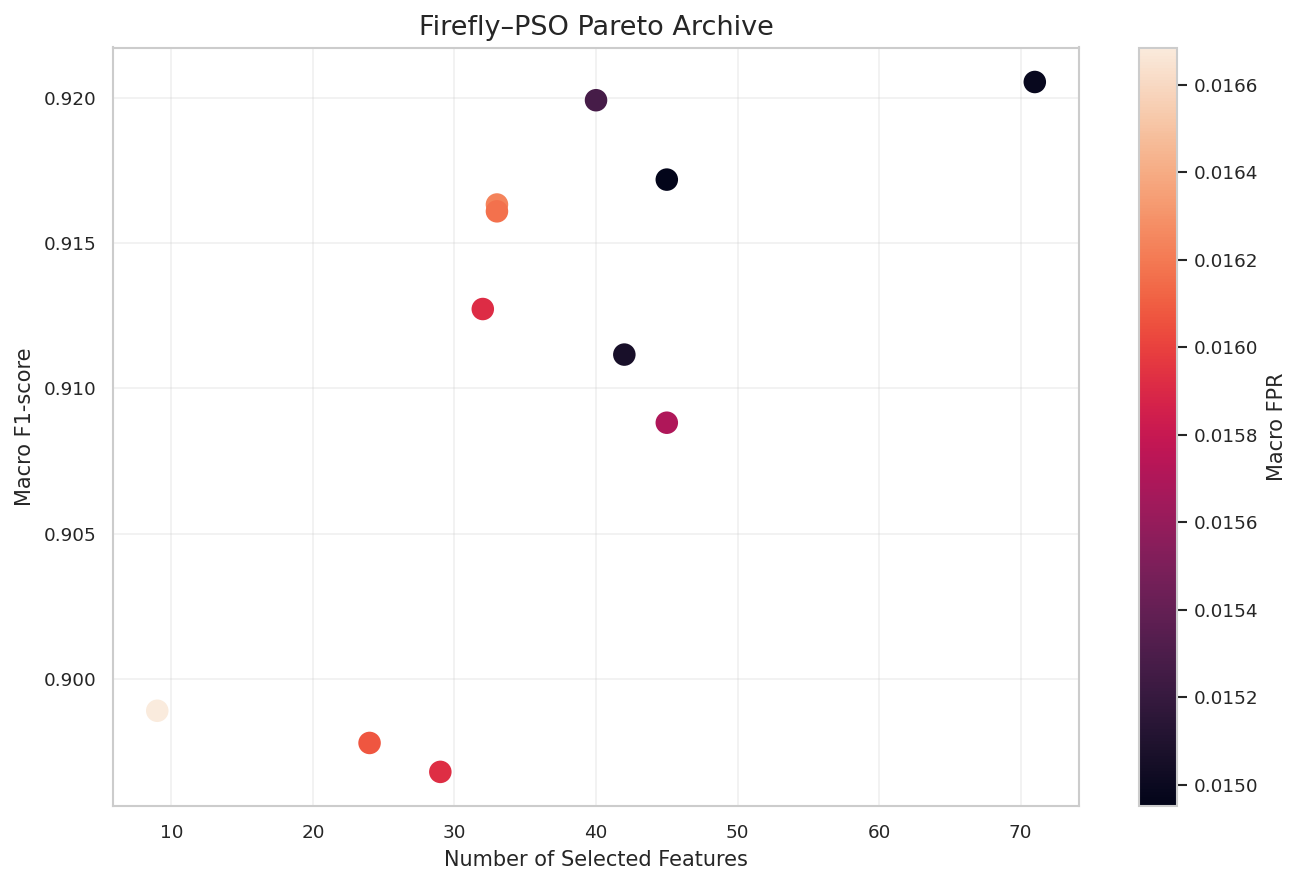

Firefly–PSO figure saved successfully.


In [174]:

import os
import pandas as pd
import matplotlib.pyplot as plt

FIG_DIR = "/kaggle/working/research_figures"
EXP_DIR = "/kaggle/working/hmooa_experiments_v2"

pso = pd.read_csv(
    os.path.join(EXP_DIR, "step6_65_firefly_pso_pareto_archive.csv")
)

print("Columns:", pso.columns.tolist())

plt.figure(figsize=(9, 6))

sc = plt.scatter(
    pso["Feature_Count"],
    pso["Macro_F1"],
    c=pso["Macro_FPR"],
    s=100
)

plt.colorbar(sc, label="Macro FPR")
plt.xlabel("Number of Selected Features")
plt.ylabel("Macro F1-score")
plt.title("Firefly–PSO Pareto Archive")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(FIG_DIR, "fig08_firefly_pso_pareto.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Firefly–PSO figure saved successfully.")


In [175]:

import os
import pandas as pd

EXP_DIR = "/kaggle/working/hmooa_experiments_v2"

files = [
    "step6_66_cuckoo_pareto_archive.csv",
    "step6_67_assessment_comparison.csv",
    "step6_67_classwise_recall.csv"
]

for filename in files:
    path = os.path.join(EXP_DIR, filename)

    print("\n" + "="*60)
    print(filename)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Columns:", df.columns.tolist())
        print(df.head())
    else:
        print("FILE NOT FOUND")



step6_66_cuckoo_pareto_archive.csv
Columns: ['n_estimators', 'max_depth', 'min_samples_leaf', 'max_features', 'Detection_Error', 'Macro_FPR', 'Feature_Ratio', 'Prediction_Latency_ms_per_1000', 'Macro_F1', 'Feature_Count', 'Feature_Reduction_Percent']
   n_estimators  max_depth  min_samples_leaf max_features  Detection_Error  \
0            41          9                 8          0.5         0.167756   
1            50         15                 6          0.5         0.132485   
2            75         25                 1         log2         0.104378   
3            44         30                 5          0.8         0.130518   

   Macro_FPR  Feature_Ratio  Prediction_Latency_ms_per_1000  Macro_F1  \
0   0.018797       0.126761                        5.797397  0.832244   
1   0.017527       0.126761                        5.883445  0.867515   
2   0.016880       0.126761                        8.652372  0.895622   
3   0.017299       0.126761                        5.887244  0.86

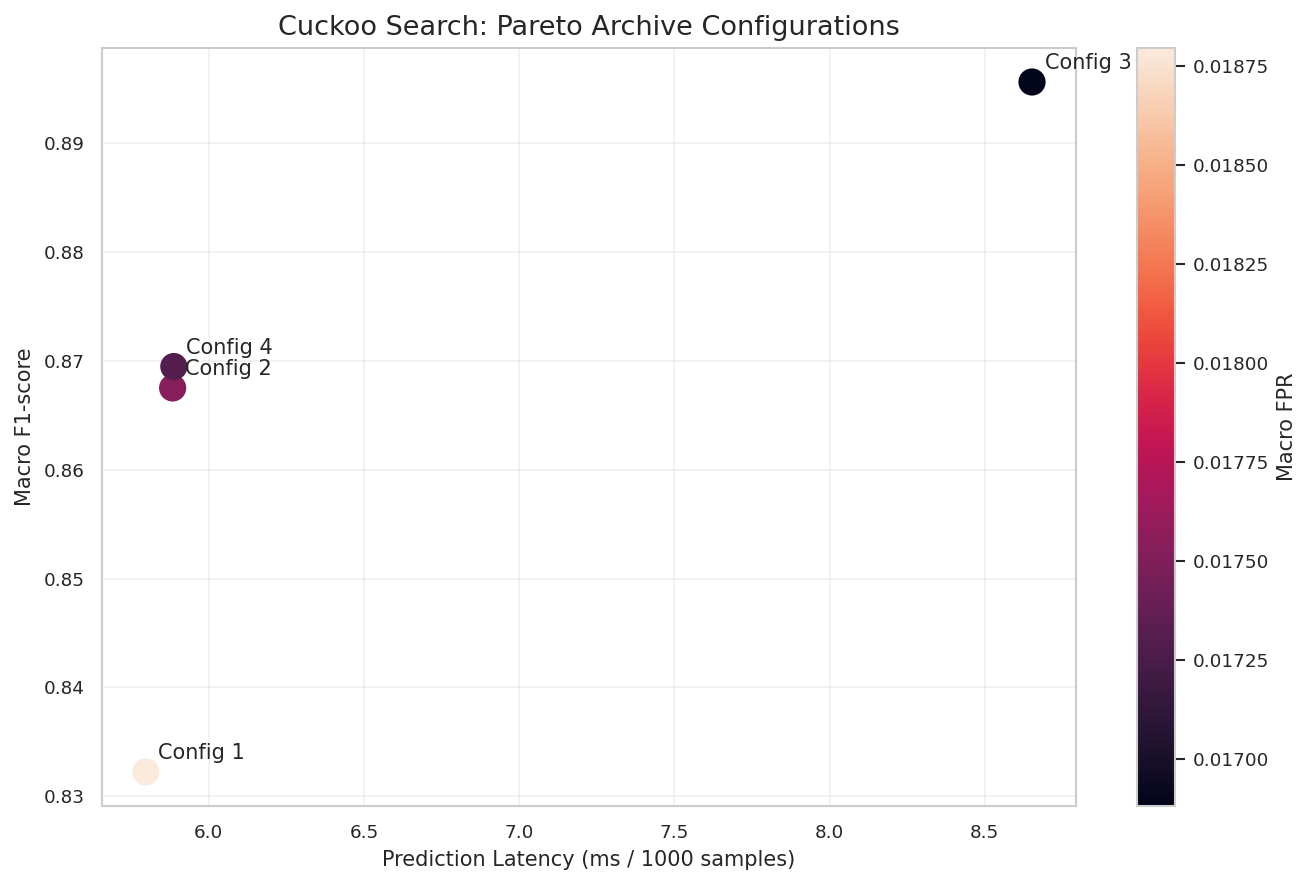

Saved: fig09_cuckoo_search_pareto.png


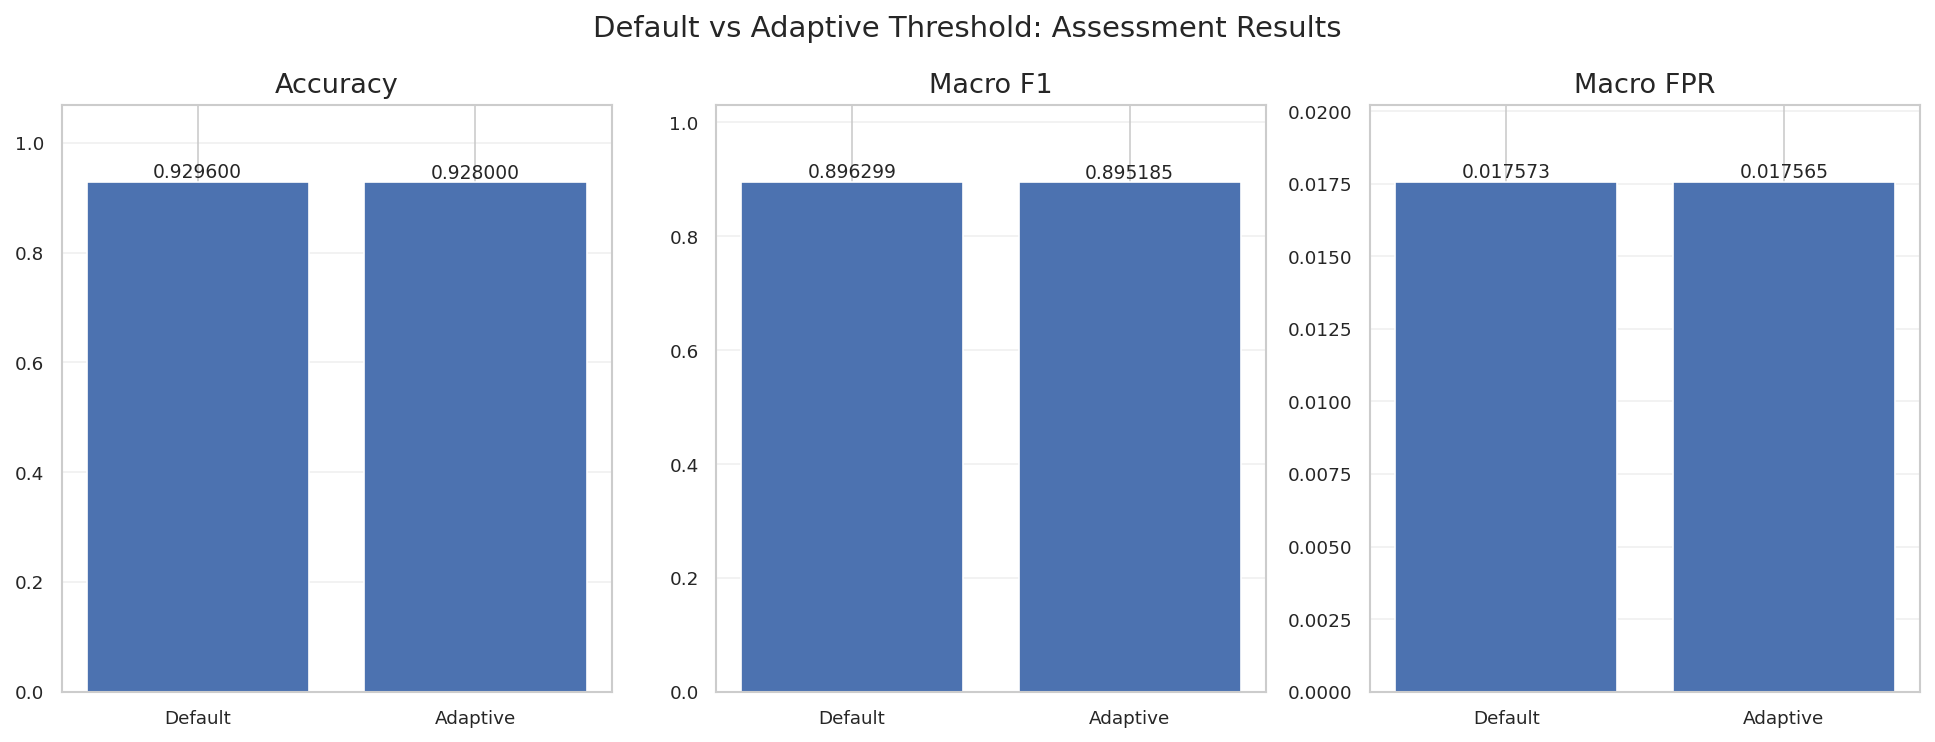

Saved: fig10_adaptive_threshold_comparison.png


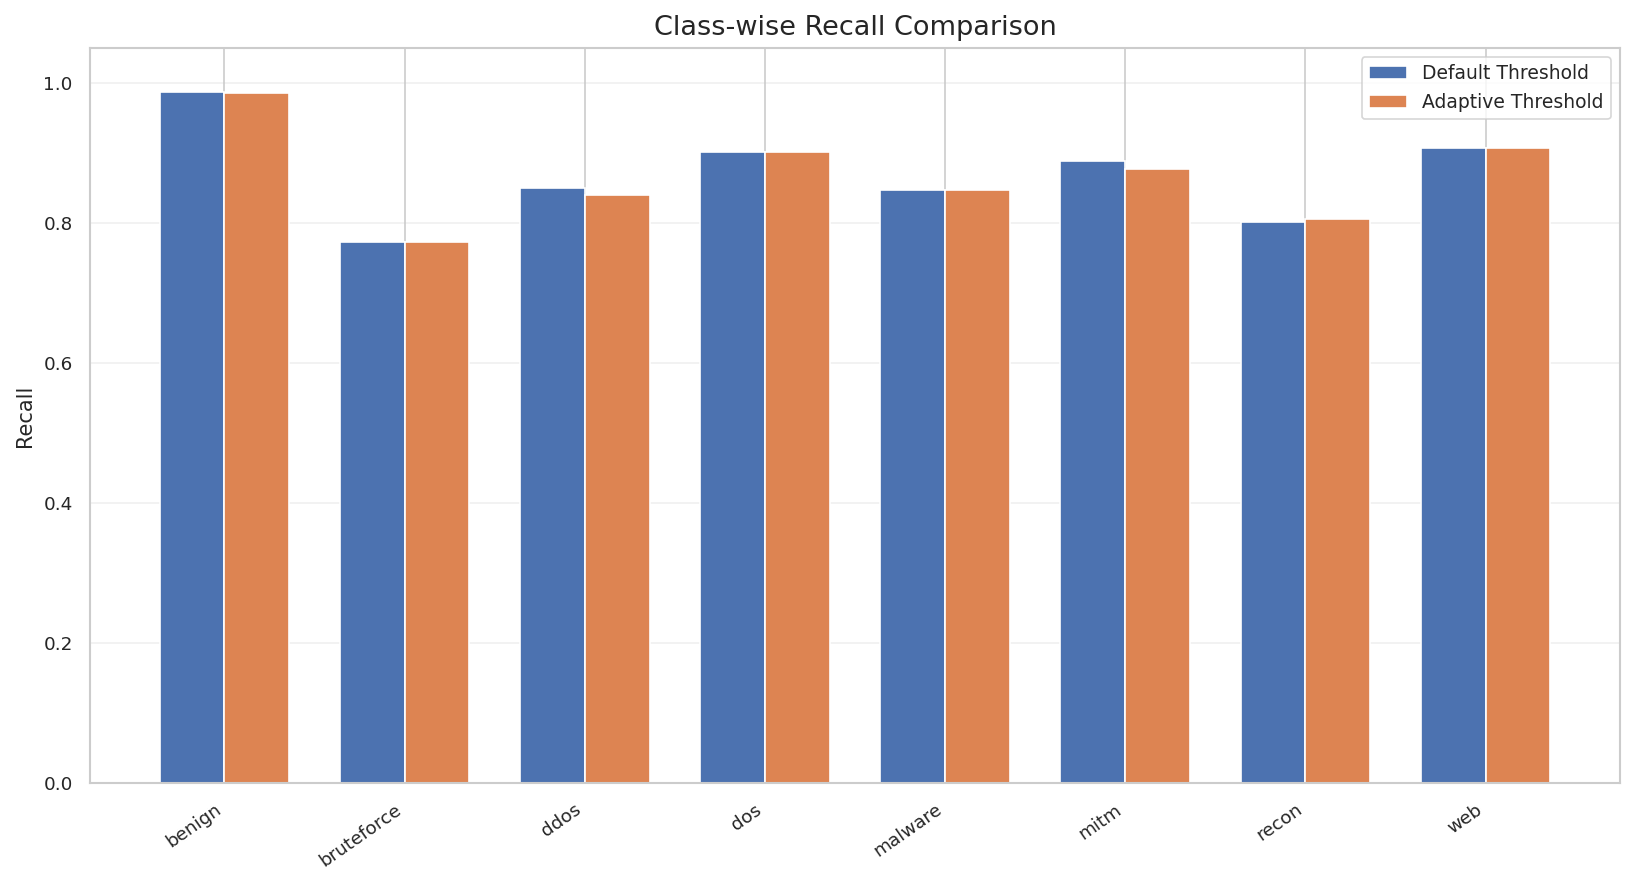

Saved: fig11_classwise_recall.png


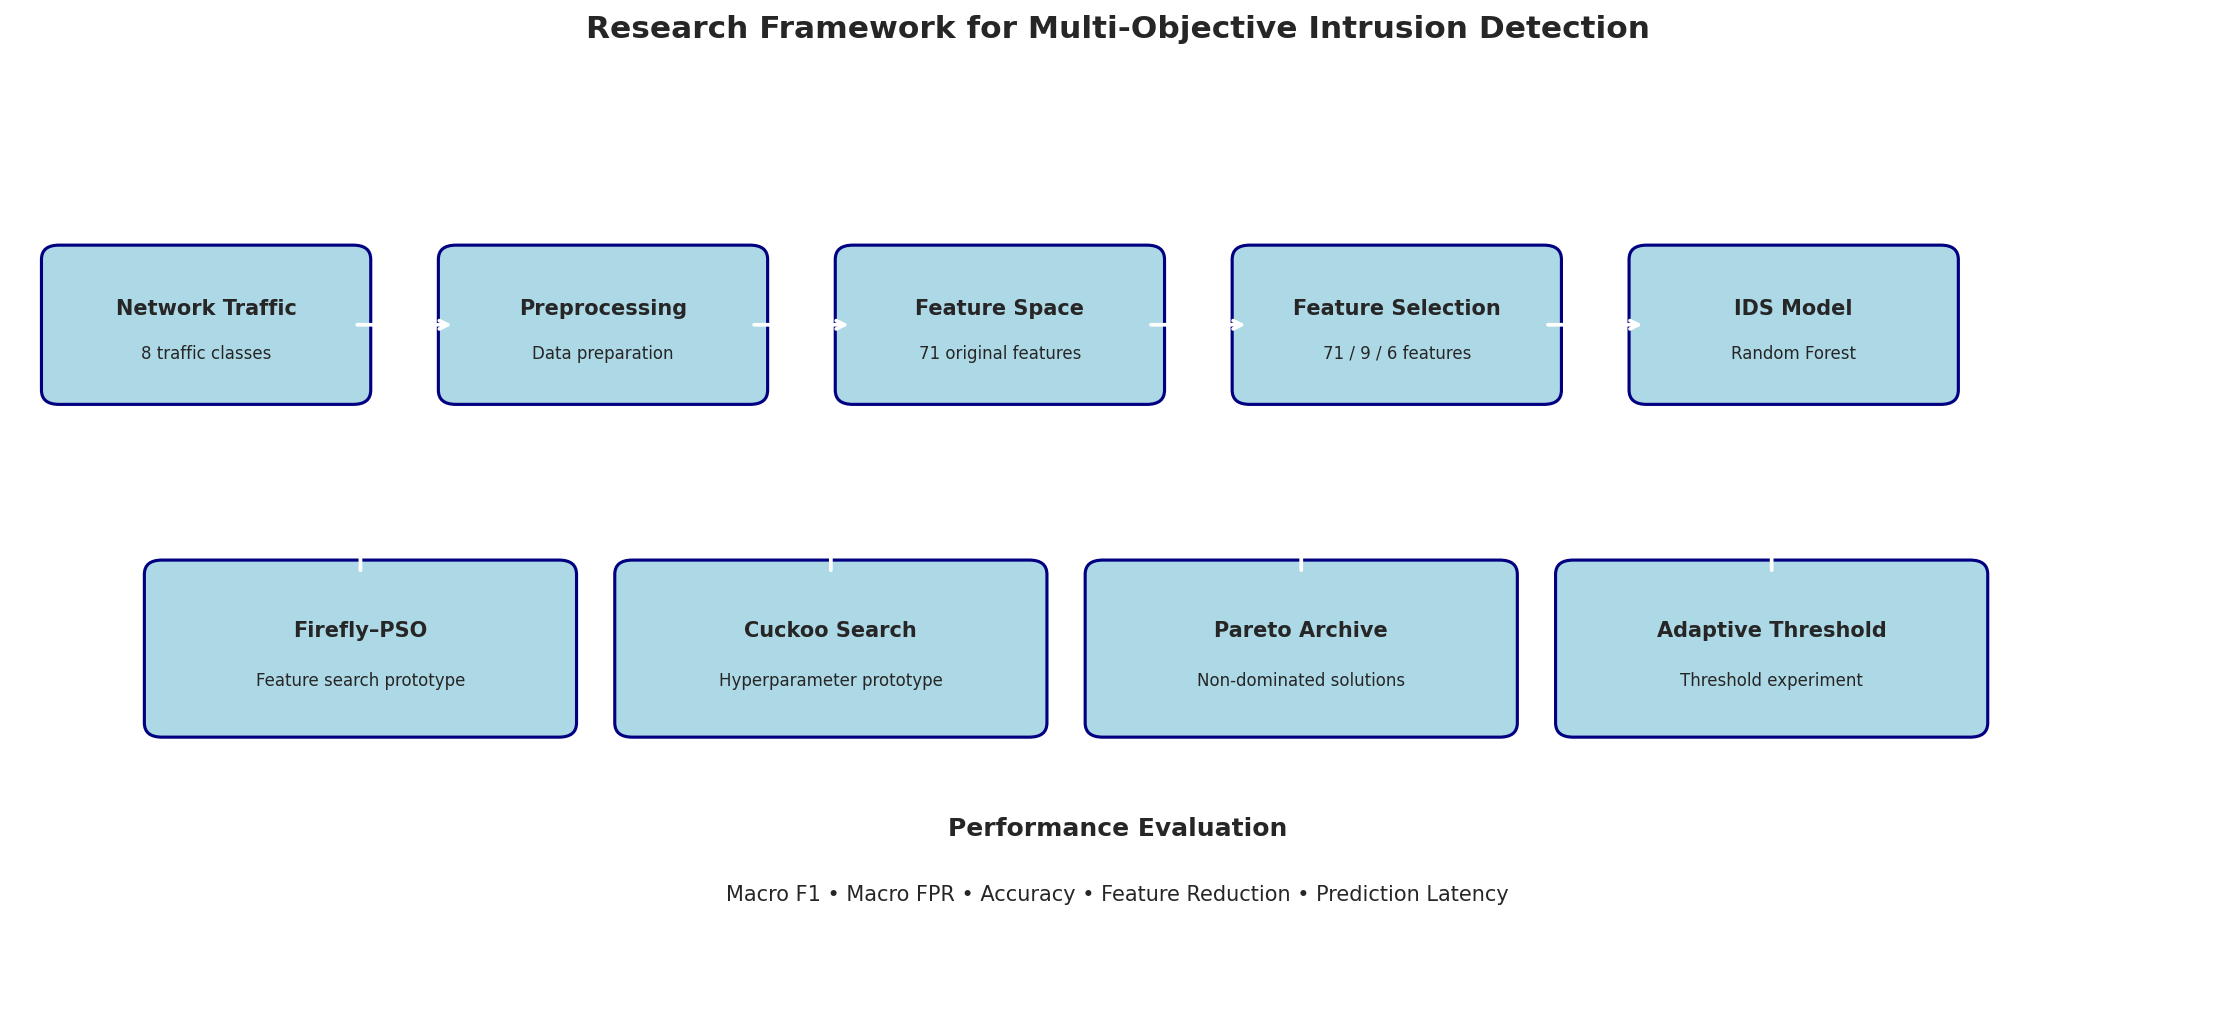

Saved: fig12_research_framework.png

========== FINAL ARCHIVE VERIFICATION ==========
Total ZIP entries: 45
Total PNG images: 15

Research figures:
phase7_confusion_matrix.png
phase7_normalized_confusion_matrix.png
phase8_computational_cost.png
research_figures/fig01_class_distribution.png
research_figures/fig02_class_percentages.png
research_figures/fig03_correlation_matrix.png
research_figures/fig04_feature_importance.png
research_figures/fig05_model_performance.png
research_figures/fig06_computational_cost.png
research_figures/fig07_confusion_matrix.png
research_figures/fig08_firefly_pso_pareto.png
research_figures/fig09_cuckoo_search_pareto.png
research_figures/fig10_adaptive_threshold_comparison.png
research_figures/fig11_classwise_recall.png
research_figures/fig12_research_framework.png

ZIP integrity: PASSED

Final ZIP path: /kaggle/working/final_research_artifacts.zip
Final ZIP size: 20.71 MB


In [176]:

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

BASE = "/kaggle/working"
FIG_DIR = os.path.join(BASE, "research_figures")
EXP_DIR = os.path.join(BASE, "hmooa_experiments_v2")
ZIP_PATH = os.path.join(BASE, "final_research_artifacts.zip")

os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    path = os.path.join(FIG_DIR, name)
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    print("Saved:", name)


# ============================================================
# FIGURE 9: CUCKOO SEARCH PARETO CONFIGURATIONS
# ============================================================

cuckoo = pd.read_csv(
    os.path.join(EXP_DIR, "step6_66_cuckoo_pareto_archive.csv")
)

plt.figure(figsize=(9, 6))

sc = plt.scatter(
    cuckoo["Prediction_Latency_ms_per_1000"],
    cuckoo["Macro_F1"],
    c=cuckoo["Macro_FPR"],
    s=150
)

for i, row in cuckoo.iterrows():
    plt.annotate(
        f"Config {i+1}",
        (row["Prediction_Latency_ms_per_1000"], row["Macro_F1"]),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.colorbar(sc, label="Macro FPR")
plt.xlabel("Prediction Latency (ms / 1000 samples)")
plt.ylabel("Macro F1-score")
plt.title("Cuckoo Search: Pareto Archive Configurations")
plt.grid(alpha=0.3)

save_fig("fig09_cuckoo_search_pareto.png")


# ============================================================
# FIGURE 10: ADAPTIVE THRESHOLD ASSESSMENT
# ============================================================

assessment = pd.read_csv(
    os.path.join(EXP_DIR, "step6_67_assessment_comparison.csv")
)

assessment = assessment.set_index("Unnamed: 0")

metric_columns = [
    ("Accuracy", "Accuracy"),
    ("Macro F1", "Macro_F1"),
    ("Macro FPR", "Macro_FPR")
]

fig, axes = plt.subplots(1, 3, figsize=(13, 5))

methods = ["Default_Argmax", "Adaptive_Threshold"]
labels = ["Default", "Adaptive"]

for ax, (title, column) in zip(axes, metric_columns):
    values = [assessment.loc[m, column] for m in methods]

    bars = ax.bar(labels, values)
    ax.set_title(title)
    ax.set_ylim(0, max(values) * 1.15 if max(values) > 0 else 1)
    ax.grid(axis="y", alpha=0.3)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height(),
            f"{value:.6f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

fig.suptitle(
    "Default vs Adaptive Threshold: Assessment Results",
    fontsize=14
)

save_fig("fig10_adaptive_threshold_comparison.png")


# ============================================================
# FIGURE 11: CLASS-WISE RECALL
# ============================================================

recall = pd.read_csv(
    os.path.join(EXP_DIR, "step6_67_classwise_recall.csv")
)

x = np.arange(len(recall))
width = 0.36

plt.figure(figsize=(11, 6))

plt.bar(
    x - width/2,
    recall["Default_Recall"],
    width,
    label="Default Threshold"
)

plt.bar(
    x + width/2,
    recall["Adaptive_Recall"],
    width,
    label="Adaptive Threshold"
)

plt.xticks(x, recall["Class"], rotation=35, ha="right")
plt.ylabel("Recall")
plt.ylim(0, 1.05)
plt.title("Class-wise Recall Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)

save_fig("fig11_classwise_recall.png")


# ============================================================
# FIGURE 12: RESEARCH FRAMEWORK
# Clearly distinguish prototype modules and experiments.
# ============================================================

fig, ax = plt.subplots(figsize=(15, 7))
ax.set_xlim(0, 15)
ax.set_ylim(0, 8)
ax.axis("off")

def add_box(x, y, w, h, title, subtitle=""):
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.12",
        linewidth=1.5,
        edgecolor="navy",
        facecolor="lightblue"
    )
    ax.add_patch(box)

    ax.text(
        x + w/2, y + h*0.62,
        title,
        ha="center", va="center",
        fontsize=10,
        fontweight="bold"
    )

    if subtitle:
        ax.text(
            x + w/2, y + h*0.28,
            subtitle,
            ha="center", va="center",
            fontsize=8
        )

def arrow(x1, y1, x2, y2):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(arrowstyle="->", lw=1.8)
    )

# Main pipeline
add_box(0.3, 5.3, 2.0, 1.1, "Network Traffic", "8 traffic classes")
add_box(3.0, 5.3, 2.0, 1.1, "Preprocessing", "Data preparation")
add_box(5.7, 5.3, 2.0, 1.1, "Feature Space", "71 original features")
add_box(8.4, 5.3, 2.0, 1.1, "Feature Selection", "71 / 9 / 6 features")
add_box(11.1, 5.3, 2.0, 1.1, "IDS Model", "Random Forest")

arrow(2.3, 5.85, 3.0, 5.85)
arrow(5.0, 5.85, 5.7, 5.85)
arrow(7.7, 5.85, 8.4, 5.85)
arrow(10.4, 5.85, 11.1, 5.85)

# Optimization modules
add_box(1.0, 2.5, 2.7, 1.25, "Firefly–PSO", "Feature search prototype")
add_box(4.2, 2.5, 2.7, 1.25, "Cuckoo Search", "Hyperparameter prototype")
add_box(7.4, 2.5, 2.7, 1.25, "Pareto Archive", "Non-dominated solutions")
add_box(10.6, 2.5, 2.7, 1.25, "Adaptive Threshold", "Threshold experiment")

for x_center in [2.35, 5.55, 8.75, 11.95]:
    arrow(x_center, 3.75, x_center, 4.6)

ax.text(
    7.5, 1.55,
    "Performance Evaluation",
    ha="center",
    fontsize=12,
    fontweight="bold"
)

ax.text(
    7.5, 1.0,
    "Macro F1 • Macro FPR • Accuracy • Feature Reduction • Prediction Latency",
    ha="center",
    fontsize=10
)

ax.set_title(
    "Research Framework for Multi-Objective Intrusion Detection",
    fontsize=15,
    fontweight="bold",
    pad=15
)

save_fig("fig12_research_framework.png")


# ============================================================
# REBUILD ZIP - PRESERVE ALL EXISTING ENTRIES
# ============================================================

TEMP_ZIP = ZIP_PATH + ".tmp"

# Read existing archive entries.
existing_entries = {}

if os.path.exists(ZIP_PATH):
    with zipfile.ZipFile(ZIP_PATH, "r") as old_zip:
        for name in old_zip.namelist():
            existing_entries[name] = old_zip.read(name)

# Add/update figures without creating duplicate archive paths.
with zipfile.ZipFile(
    TEMP_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as new_zip:

    for name, content in existing_entries.items():
        if name.startswith("research_figures/"):
            continue
        new_zip.writestr(name, content)

    for filename in sorted(os.listdir(FIG_DIR)):
        if filename.lower().endswith(".png"):
            archive_name = "research_figures/" + filename

            new_zip.write(
                os.path.join(FIG_DIR, filename),
                archive_name
            )

os.replace(TEMP_ZIP, ZIP_PATH)


# ============================================================
# FINAL ZIP VERIFICATION
# ============================================================

print("\n========== FINAL ARCHIVE VERIFICATION ==========")

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    entries = z.namelist()

    images = [
        name for name in entries
        if name.lower().endswith(".png")
    ]

    print("Total ZIP entries:", len(entries))
    print("Total PNG images:", len(images))

    print("\nResearch figures:")
    for name in images:
        print(name)

    bad_file = z.testzip()

    print("\nZIP integrity:", "PASSED" if bad_file is None else bad_file)

print("\nFinal ZIP path:", ZIP_PATH)
print("Final ZIP size:", round(os.path.getsize(ZIP_PATH)/1024**2, 2), "MB")
